# OBJECT ViT-B/16 V18.6 — chromatic rescue, extended-refit SWA and deployable checkpoints

V18.6 preserves the successful V18.4.2 visual route and adds a **separate,
validation-gated chromatic micro-evidence branch** designed for the remaining
adjacent errors. Its explicit target is the observed failure mode in which a
small yellow region on a mostly green mango is ignored, causing class 1 to be
predicted as class 0; it also models the yellow/green proportion needed to keep
class 1 separate from class 2.

Core safeguards:

- the protected visual route remains available as an exact fallback;
- the chromatic branch consumes detached ViT patch features, so its auxiliary
  losses cannot degrade the protected main route through shared gradients;
- four zero-initialized residual adapters provide low-capacity domain
  adaptation without unfreezing the pretrained ViT-B/16 weights;
- all chromatic probability blending is selected on validation with alpha=0
  always available;
- the existing content-hash split registry, checkpointing, memory-safe local
  execution, full error gallery and XAI remain in place;
- calibration receives a 14-epoch ceiling but early stopping still selects the
  best epoch; refit is not blindly doubled.


### V18.6 changes

- Calibration ceiling 18 epochs; patience 8.
- Fresh train+validation refit extends four epochs by default.
- The final refit delta is averaged from the validation-selected epoch through
  the extended epoch (`swa_selected_to_extended`).
- Pair specialists 01/12 are class-1 rescue-only.
- `OUTPUT_DIR/checkpoints` is the primary checkpoint directory and is mirrored
  to the persistent cache.


## 0. Môi trường local, dataset động và giám sát tài nguyên

Mặc định:
- Data home: `E:\kaggle\local\chat\data`
- Mỗi dataset là một thư mục lớn; bên trong là các thư mục lớp.
- Có thể chọn dataset bằng `CLASSIFIER_DATASET_NAME`, đường dẫn trực tiếp bằng `CLASSIFIER_DATASET_ROOT`, và prompt mask bằng `CLASSIFIER_OBJECT_PROMPT`.
- Output: `runs/<timestamp>_<dataset>_v18_local/`.
- Trên Windows, notebook ưu tiên RAM preload + micro-batch auto-tune; `num_workers=2` chỉ được giữ nếu probe chạy ổn và nhanh hơn.

In [1]:
# ============================================================
# LOCAL WINDOWS / NVIDIA CUDA RUNTIME PREFLIGHT
# ============================================================
import os
import sys
import platform
import socket
import subprocess
from pathlib import Path
from urllib.parse import urlparse

# Match the working local notebook environment.
os.environ.setdefault('TORCH_HOME', r'E:\kaggle\local\chat\.cache\torch')
os.environ.setdefault('HF_HOME', r'E:\kaggle\local\chat\.cache\huggingface')
os.environ.setdefault('HUGGINGFACE_HUB_CACHE', str(Path(os.environ['HF_HOME']) / 'hub'))
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
os.environ.setdefault('HF_HUB_DISABLE_TELEMETRY', '1')
os.environ.setdefault('HF_HUB_DISABLE_PROGRESS_BARS', '1')
os.environ.setdefault('TRANSFORMERS_VERBOSITY', 'warning')
os.environ.setdefault('HF_HUB_DOWNLOAD_TIMEOUT', '600')
os.environ.setdefault('HF_HUB_ETAG_TIMEOUT', '30')

import torch
import torchvision
from torchvision.models import ViT_B_16_Weights

# Explicit AMP APIs are used throughout; no cell depends on a later import.
if not callable(getattr(torch, 'autocast', None)):
    raise RuntimeError('PyTorch hiện tại không cung cấp torch.autocast.')
if not hasattr(torch, 'amp') or not hasattr(torch.amp, 'GradScaler'):
    raise RuntimeError('PyTorch hiện tại không cung cấp torch.amp.GradScaler.')

LOCAL_REQUIRE_CUDA = os.environ.get('MANGO_REQUIRE_CUDA', '1').strip() != '0'
LOCAL_MINIMUM_VRAM_GIB = float(os.environ.get('MANGO_MINIMUM_VRAM_GIB', '6.0'))
HF_LOCAL_FILES_ONLY = os.environ.get('MANGO_HF_LOCAL_ONLY', '0').strip() == '1'
LOCAL_USE_DATA_PARALLEL = os.environ.get('MANGO_USE_DATA_PARALLEL', '0').strip() == '1'
CLASSIFIER_DATA_HOME = Path(os.environ.get('CLASSIFIER_DATA_HOME', r'E:\kaggle\local\chat\data'))
LOCAL_DEFAULT_DATASET_ROOT = CLASSIFIER_DATA_HOME
LOCAL_CACHE_ROOT = Path(os.environ.get('MANGO_CACHE_ROOT', r'E:\kaggle\local\chat\.cache'))
LOCAL_CACHE_ROOT.mkdir(parents=True, exist_ok=True)


def _run_command(command, timeout=25):
    try:
        result = subprocess.run(command, check=False, capture_output=True, text=True, timeout=timeout)
        return result.returncode, (result.stdout or result.stderr).strip()
    except Exception as exc:
        return -1, f'{type(exc).__name__}: {exc}'


def _internet_probe(host, port=443, timeout=5):
    try:
        with socket.create_connection((host, port), timeout=timeout):
            return True, f'TCP {host}:{port} reachable'
    except Exception as exc:
        return False, f'{type(exc).__name__}: {exc}'


print('=' * 92)
print('LOCAL RUNTIME PREFLIGHT — CLASSIFIER V18')
print('=' * 92)
print('OS            :', platform.platform())
print('Python        :', sys.version.split()[0])
print('PyTorch       :', torch.__version__)
print('TorchVision   :', torchvision.__version__)
print('Torch CUDA    :', torch.version.cuda)
print('CUDA visible  :', torch.cuda.is_available())
print('TORCH_HOME    :', os.environ.get('TORCH_HOME'))
print('HF_HOME       :', os.environ.get('HF_HOME'))

if sys.version_info < (3, 10):
    raise RuntimeError('V17.2 local yêu cầu Python >= 3.10; notebook mẫu dùng Python 3.11.')
if LOCAL_REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError(
        'PyTorch không nhìn thấy CUDA. Hãy mở đúng kernel/venv CUDA đã chạy được notebook mẫu, '
        'sau đó Restart Kernel và Run All.'
    )

LOCAL_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
LOCAL_GPU_COUNT = torch.cuda.device_count() if torch.cuda.is_available() else 0
LOCAL_GPU_NAME = 'CPU'
LOCAL_TOTAL_VRAM_GIB = 0.0
LOCAL_COMPUTE_CAPABILITY = None

if LOCAL_DEVICE.type == 'cuda':
    code, smi = _run_command([
        'nvidia-smi', '--query-gpu=index,name,memory.total,driver_version', '--format=csv,noheader'
    ])
    print('\nNVIDIA-SMI:')
    print(smi if smi else f'nvidia-smi return code={code}')
    prop = torch.cuda.get_device_properties(0)
    LOCAL_GPU_NAME = prop.name
    LOCAL_TOTAL_VRAM_GIB = prop.total_memory / 1024**3
    LOCAL_COMPUTE_CAPABILITY = (prop.major, prop.minor)
    print(f'GPU 0         : {LOCAL_GPU_NAME}')
    print(f'Capability    : sm_{prop.major}{prop.minor}')
    print(f'VRAM          : {LOCAL_TOTAL_VRAM_GIB:.2f} GiB')
    if LOCAL_TOTAL_VRAM_GIB < LOCAL_MINIMUM_VRAM_GIB:
        raise RuntimeError(
            f'VRAM={LOCAL_TOTAL_VRAM_GIB:.2f} GiB thấp hơn ngưỡng {LOCAL_MINIMUM_VRAM_GIB:.2f} GiB.'
        )
    # A real kernel launch is more reliable than assuming a specific GPU family.
    probe = torch.arange(1, 4097, device=LOCAL_DEVICE, dtype=torch.float32)
    probe_value = (probe.square().mean() + probe.sin().mean()).item()
    torch.cuda.synchronize()
    if not torch.isfinite(torch.tensor(probe_value)):
        raise RuntimeError('CUDA kernel probe trả về giá trị không hữu hạn.')
    del probe
    print(f'CUDA probe    : PASS ({probe_value:.6f})')

# Safe local batch profile. Environment variables can override these values.
if LOCAL_TOTAL_VRAM_GIB >= 11.5:
    _default_micro, _default_accum, _default_eval = 4, 8, 8
    _default_dino, _default_sam = 2, 1
elif LOCAL_TOTAL_VRAM_GIB >= 7.0:
    _default_micro, _default_accum, _default_eval = 2, 16, 4
    # Grounding-DINO-tiny usually fits batch 2 on 8 GiB in FP16; the detector
    # loop already halves to batch 1 on any OOM or batch-specific failure.
    _default_dino, _default_sam = 2, 1
else:
    _default_micro, _default_accum, _default_eval = 1, 32, 2
    _default_dino, _default_sam = 1, 1

LOCAL_MICRO_BATCH = int(os.environ.get('MANGO_MICRO_BATCH', str(_default_micro)))
LOCAL_GRAD_ACCUM = int(os.environ.get('MANGO_GRAD_ACCUM', str(_default_accum)))
LOCAL_EVAL_BATCH = int(os.environ.get('MANGO_EVAL_BATCH', str(_default_eval)))
LOCAL_GROUNDING_BATCH = int(os.environ.get('MANGO_GROUNDING_BATCH', str(_default_dino)))
LOCAL_SAM_BATCH = int(os.environ.get('MANGO_SAM_BATCH', str(_default_sam)))
LOCAL_NUM_WORKERS_REQUEST = os.environ.get('NOTEBOOK_NUM_WORKERS', 'auto').strip().lower()
LOCAL_NUM_WORKERS = 0 if LOCAL_NUM_WORKERS_REQUEST == 'auto' else max(0, int(LOCAL_NUM_WORKERS_REQUEST))
LOCAL_PRELOAD_THREADS = max(1, int(os.environ.get('CLASSIFIER_PRELOAD_THREADS', '4')))
LOCAL_AUTO_MICROBATCH = os.environ.get('CLASSIFIER_AUTO_MICROBATCH', '1').strip() != '0'
LOCAL_RESOURCE_INTERVAL = max(1.0, float(os.environ.get('CLASSIFIER_RESOURCE_INTERVAL', '3')))
LOCAL_VRAM_GUARD_GIB = float(os.environ.get(
    'MANGO_VRAM_GUARD_GIB', str(max(5.0, LOCAL_TOTAL_VRAM_GIB * 0.97))
))
if os.name == 'nt' and LOCAL_NUM_WORKERS_REQUEST not in ('auto','0'):
    print('⚠️ num_workers override trên Windows:', LOCAL_NUM_WORKERS, '— probe sẽ kiểm tra trước training.')
if LOCAL_USE_DATA_PARALLEL and LOCAL_GPU_COUNT < 2:
    print('⚠️ MANGO_USE_DATA_PARALLEL=1 nhưng chỉ có một GPU; tự chuyển về single GPU.')
    LOCAL_USE_DATA_PARALLEL = False

# Internet is required only when public weights are not already cached.
internet_status = {}
for host in ('huggingface.co', 'download.pytorch.org'):
    ok, detail = _internet_probe(host)
    internet_status[host] = ok
    print(f'Internet {host}: {"OK" if ok else "không truy cập được"} — {detail}')

weights_enum = ViT_B_16_Weights.IMAGENET1K_V1
weights_name = Path(urlparse(weights_enum.url).path).name
weights_cache = Path(torch.hub.get_dir()) / 'checkpoints' / weights_name
print('ViT cache     :', weights_cache, '| exists=', weights_cache.is_file())
if not weights_cache.is_file() and not internet_status.get('download.pytorch.org', False):
    print('⚠️ ViT-B/16 chưa có trong cache và socket probe không truy cập được download.pytorch.org. '
          'Notebook vẫn tiếp tục vì một số mạng/proxy chặn socket probe nhưng cho phép tải HTTPS; '
          'nếu tải thật thất bại, cell tạo model sẽ báo lỗi rõ ràng.')
if HF_LOCAL_FILES_ONLY:
    print('Hugging Face : local_files_only=True')

print('\nLocal execution profile:')
print({
    'device': str(LOCAL_DEVICE),
    'gpu': LOCAL_GPU_NAME,
    'micro_batch': LOCAL_MICRO_BATCH,
    'grad_accum': LOCAL_GRAD_ACCUM,
    'effective_batch': LOCAL_MICRO_BATCH * LOCAL_GRAD_ACCUM,
    'eval_batch': LOCAL_EVAL_BATCH,
    'grounding_batch': LOCAL_GROUNDING_BATCH,
    'sam_batch': LOCAL_SAM_BATCH,
    'num_workers_request': LOCAL_NUM_WORKERS_REQUEST,
    'num_workers_initial': LOCAL_NUM_WORKERS,
    'preload_threads': LOCAL_PRELOAD_THREADS,
    'auto_microbatch': LOCAL_AUTO_MICROBATCH,
    'data_parallel': LOCAL_USE_DATA_PARALLEL,
})
print('=' * 92)

# ============================================================
# V18.3 LOCAL PERFORMANCE POLICY
# ============================================================
CPU_COUNT = max(1, os.cpu_count() or 1)
V183_TORCH_CPU_THREADS = int(
    os.environ.get(
        "CLASSIFIER_TORCH_CPU_THREADS",
        str(min(8, CPU_COUNT)),
    )
)
torch.set_num_threads(max(1, V183_TORCH_CPU_THREADS))
try:
    torch.set_num_interop_threads(
        max(1, min(4, V183_TORCH_CPU_THREADS // 2))
    )
except RuntimeError:
    pass

torch.backends.cudnn.benchmark = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    try:
        torch.set_float32_matmul_precision("high")
    except Exception:
        pass
    for _backend_name in (
        "enable_flash_sdp",
        "enable_mem_efficient_sdp",
        "enable_math_sdp",
    ):
        _backend_fn = getattr(
            torch.backends.cuda, _backend_name, None
        )
        if callable(_backend_fn):
            _backend_fn(True)

V183_PREFETCH_DEPTH = max(
    0,
    int(
        os.environ.get(
            "CLASSIFIER_PREFETCH_DEPTH", "3"
        )
    ),
)
V183_RESOURCE_INTERVAL = max(
    0.5,
    float(
        os.environ.get(
            "CLASSIFIER_RESOURCE_INTERVAL", "1.5"
        )
    ),
)
V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION = (
    os.environ.get(
        "CLASSIFIER_ENABLE_CLASS1_BOUNDARY_CALIBRATION",
        "1",
    ).strip().lower()
    not in {"0", "false", "no"}
)
V183_BATCH_CANDIDATES = (2, 4, 8, 16, 32)

print(
    "V18.3 performance policy:",
    {
        "torch_cpu_threads": V183_TORCH_CPU_THREADS,
        "prefetch_depth": V183_PREFETCH_DEPTH,
        "resource_interval_s": V183_RESOURCE_INTERVAL,
        "batch_candidates": V183_BATCH_CANDIDATES,
        "class1_boundary_calibration":
            V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION,
    },
)


# V18.3.1: every performance global is owned by this cell. This makes a
# missing or misspelled symbol fail here, before dataset processing/training.
_V183_REQUIRED_GLOBALS = (
    "V183_TORCH_CPU_THREADS",
    "V183_PREFETCH_DEPTH",
    "V183_RESOURCE_INTERVAL",
    "V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION",
    "V183_BATCH_CANDIDATES",
)
_V183_MISSING_GLOBALS = [
    name for name in _V183_REQUIRED_GLOBALS
    if name not in globals()
]
if _V183_MISSING_GLOBALS:
    raise RuntimeError(
        "V18.3 runtime global contract failed: "
        + ", ".join(_V183_MISSING_GLOBALS)
    )
if not (0.5 <= float(V183_RESOURCE_INTERVAL) <= 60.0):
    raise ValueError(
        "V183_RESOURCE_INTERVAL must be in [0.5, 60] seconds; "
        f"received {V183_RESOURCE_INTERVAL!r}."
    )
print(
    "V18.3.1 runtime-global contract: PASS",
    {name: globals()[name] for name in _V183_REQUIRED_GLOBALS},
)


# ============================================================
# V18.3.3 MEMORY-ADAPTIVE REFIT POLICY
# ============================================================
V1833_REFIT_MODE = os.environ.get(
    "CLASSIFIER_REFIT_MODE", "auto"
).strip().lower()
if V1833_REFIT_MODE not in {"auto", "force", "skip"}:
    raise ValueError(
        "CLASSIFIER_REFIT_MODE must be auto, force or skip."
    )
V1833_REFIT_MIN_AVAILABLE_GIB = max(
    0.50,
    float(os.environ.get("CLASSIFIER_REFIT_MIN_AVAILABLE_GIB", "1.50")),
)
V1833_REFIT_HARD_MIN_AVAILABLE_GIB = max(
    0.20,
    float(os.environ.get("CLASSIFIER_REFIT_HARD_MIN_AVAILABLE_GIB", "0.40")),
)
V1833_REFIT_CACHE_RELEASE_TRIGGER_GIB = max(
    V1833_REFIT_MIN_AVAILABLE_GIB,
    float(os.environ.get("CLASSIFIER_REFIT_CACHE_RELEASE_TRIGGER_GIB", "2.50")),
)
V1833_REFIT_MAX_PROCESS_GIB = max(
    2.0,
    float(os.environ.get("CLASSIFIER_REFIT_MAX_PROCESS_GIB", "6.0")),
)
V1833_RELEASE_RAM_CACHE_FOR_REFIT = (
    os.environ.get("CLASSIFIER_RELEASE_RAM_CACHE_FOR_REFIT", "1")
    .strip().lower() not in {"0", "false", "no"}
)
V1833_LOW_RAM_PREFETCH_DEPTH = max(
    0,
    int(os.environ.get("CLASSIFIER_LOW_RAM_PREFETCH_DEPTH", "1")),
)
print(
    "V18.3.3 refit policy:",
    {
        "mode": V1833_REFIT_MODE,
        "min_available_gib": V1833_REFIT_MIN_AVAILABLE_GIB,
        "hard_min_available_gib": V1833_REFIT_HARD_MIN_AVAILABLE_GIB,
        "cache_release_trigger_gib": V1833_REFIT_CACHE_RELEASE_TRIGGER_GIB,
        "max_process_gib": V1833_REFIT_MAX_PROCESS_GIB,
        "release_ram_cache": V1833_RELEASE_RAM_CACHE_FOR_REFIT,
        "low_ram_prefetch_depth": V1833_LOW_RAM_PREFETCH_DEPTH,
    },
)


# ============================================================
# V18.5 STABILITY / MEMORY POLICY
# ============================================================
V1841_VERSION = 'V18.6_CHROMATIC_RESCUE_SWA_CHECKPOINTED'
V1841_RUN_MODE = os.environ.get(
    'CLASSIFIER_RUN_MODE', 'stable'
).strip().lower()
if V1841_RUN_MODE not in {'fast', 'stable', 'full_audit'}:
    raise ValueError(
        'CLASSIFIER_RUN_MODE must be fast, stable or full_audit.'
    )
V1841_OPTIONAL_AUDITS_FAIL_SOFT = (
    os.environ.get('CLASSIFIER_OPTIONAL_AUDITS_FAIL_SOFT', '1')
    .strip().lower() not in {'0', 'false', 'no'}
)
V1841_ENABLE_MASK_SENSITIVITY = (
    os.environ.get(
        'CLASSIFIER_ENABLE_MASK_SENSITIVITY',
        '1' if V1841_RUN_MODE == 'full_audit' else '0',
    ).strip().lower() not in {'0', 'false', 'no'}
)
# The detached evidence verifier repeatedly selected alpha=0. It remains
# available only in full_audit unless explicitly enabled.
V1841_ENABLE_EVIDENCE_VERIFIER = (
    os.environ.get(
        'CLASSIFIER_ENABLE_EVIDENCE_VERIFIER',
        '1' if V1841_RUN_MODE == 'full_audit' else '0',
    ).strip().lower() not in {'0', 'false', 'no'}
)
V1841_MASK_AUDIT_BATCH = max(
    1, int(os.environ.get('CLASSIFIER_MASK_AUDIT_BATCH', '4'))
)
V1841_MASK_AUDIT_STABLE_ROWS = max(
    20, int(os.environ.get('CLASSIFIER_MASK_AUDIT_ROWS', '80'))
)
V1841_MASK_AUDIT_RETRY_ROWS = max(
    10, int(os.environ.get('CLASSIFIER_MASK_AUDIT_RETRY_ROWS', '40'))
)
V1841_MASK_AUDIT_MIN_FREE_GIB = max(
    0.25,
    float(os.environ.get('CLASSIFIER_MASK_AUDIT_MIN_FREE_GIB', '1.50')),
)
V1841_RELEASE_RAM_CACHE_BELOW_GIB = max(
    0.5,
    float(os.environ.get('CLASSIFIER_RELEASE_RAM_CACHE_BELOW_GIB', '3.00')),
)
V1841_RAM_CACHE_RESERVE_GIB = max(
    1.5,
    float(os.environ.get('CLASSIFIER_RAM_CACHE_RESERVE_GIB', '4.00')),
)
V1841_MAX_EVAL_BATCH = max(
    4, int(os.environ.get('CLASSIFIER_MAX_EVAL_BATCH', '32'))
)
V1841_TRAIN_PREFETCH_DEPTH = max(
    0, int(os.environ.get('CLASSIFIER_TRAIN_PREFETCH_DEPTH', '2'))
)
V1841_EVAL_PREFETCH_DEPTH = max(
    0, int(os.environ.get('CLASSIFIER_EVAL_PREFETCH_DEPTH', '0'))
)
V1841_FULL_CHECKPOINT_MIN_FREE_GIB = max(
    0.5,
    float(os.environ.get('CLASSIFIER_FULL_CHECKPOINT_MIN_FREE_GIB', '1.25')),
)
print(
    'V18.5 stability policy:',
    {
        'run_mode': V1841_RUN_MODE,
        'mask_sensitivity': V1841_ENABLE_MASK_SENSITIVITY,
        'evidence_verifier': V1841_ENABLE_EVIDENCE_VERIFIER,
        'mask_audit_batch': V1841_MASK_AUDIT_BATCH,
        'mask_audit_rows': V1841_MASK_AUDIT_STABLE_ROWS,
        'max_eval_batch': V1841_MAX_EVAL_BATCH,
        'train_prefetch_depth': V1841_TRAIN_PREFETCH_DEPTH,
        'eval_prefetch_depth': V1841_EVAL_PREFETCH_DEPTH,
    },
)


LOCAL RUNTIME PREFLIGHT — CLASSIFIER V18
OS            : Windows-10-10.0.26200-SP0
Python        : 3.11.9
PyTorch       : 2.10.0+cu128
TorchVision   : 0.25.0+cu128
Torch CUDA    : 12.8
CUDA visible  : True
TORCH_HOME    : E:\kaggle\local\chat\.cache\torch
HF_HOME       : E:\kaggle\local\chat\.cache\huggingface

NVIDIA-SMI:
0, NVIDIA GeForce RTX 4060 Laptop GPU, 8188 MiB, 572.83
GPU 0         : NVIDIA GeForce RTX 4060 Laptop GPU
Capability    : sm_89
VRAM          : 8.00 GiB
CUDA probe    : PASS (5594453.000000)
Internet huggingface.co: OK — TCP huggingface.co:443 reachable


Internet download.pytorch.org: OK — TCP download.pytorch.org:443 reachable
ViT cache     : E:\kaggle\local\chat\.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth | exists= True

Local execution profile:
{'device': 'cuda:0', 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU', 'micro_batch': 2, 'grad_accum': 16, 'effective_batch': 32, 'eval_batch': 4, 'grounding_batch': 2, 'sam_batch': 1, 'num_workers_request': '0', 'num_workers_initial': 0, 'preload_threads': 4, 'auto_microbatch': True, 'data_parallel': False}
V18.3 performance policy: {'torch_cpu_threads': 8, 'prefetch_depth': 3, 'resource_interval_s': 1.5, 'batch_candidates': (2, 4, 8, 16, 32), 'class1_boundary_calibration': True}
V18.3.1 runtime-global contract: PASS {'V183_TORCH_CPU_THREADS': 8, 'V183_PREFETCH_DEPTH': 3, 'V183_RESOURCE_INTERVAL': 1.5, 'V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION': True, 'V183_BATCH_CANDIDATES': (2, 4, 8, 16, 32)}
V18.3.3 refit policy: {'mode': 'auto', 'min_available_gib': 1.5, 'hard_min_available_gib': 0.4, '

In [2]:
# ============================================================
# V18 DYNAMIC DATASET DISCOVERY, STABLE LABELS, OBJECT PROMPT
# ============================================================
import os,re,unicodedata,hashlib
import numpy as np,pandas as pd
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from sklearn.model_selection import train_test_split

SPLIT_SEED=42;TRAIN_RATIO=.70;VAL_RATIO=.15;TEST_RATIO=.15;VERIFY_IMAGES=True
IMAGE_EXTENSIONS={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
MANGO_ALIASES={
  0:('0','Xoai_Song_Chua_KhoDap'),1:('1','Xoai_Song_ChuaNhe_CoNguyCo'),
  2:('2','Xoai_Chin_NgotThanh_DeDap'),3:('3','Xoai_ChinGia_NgotGat_KhongVanChuyen'),
  4:('4','Xoai_Hu_KhongAnDuoc')}
MANGO_SEMANTICS={0:'Xoài sống, chua, khó đập',1:'Xoài sống, chua nhẹ, có nguy cơ',2:'Xoài chín, ngọt thanh, dễ đập',3:'Xoài chín già, ngọt gắt, không vận chuyển',4:'Xoài hư, không ăn được'}

def natural_key(s):
    return [int(x) if x.isdigit() else x.casefold() for x in re.split(r'(\d+)',str(s))]
def valid_image(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except Exception:return False
def image_files(folder):
    return sorted((p for p in Path(folder).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS),key=lambda p:natural_key(str(p)))
def immediate_class_dirs(root):
    root=Path(root)
    return [p for p in sorted(root.iterdir(),key=lambda p:natural_key(p.name)) if p.is_dir() and len(image_files(p))>0]
def dataset_candidate(root):
    try:return len(immediate_class_dirs(root))>=2
    except Exception:return False
def dataset_size(root):return sum(len(image_files(d)) for d in immediate_class_dirs(root)) if dataset_candidate(root) else 0

def choose_dataset_root():
    """Choose one dataset root without letting a stale legacy variable override V18.

    Priority:
      1) CLASSIFIER_DATASET_ROOT
      2) CLASSIFIER_DATASET_NAME under CLASSIFIER_DATA_HOME
      3) discover dataset folders under CLASSIFIER_DATA_HOME
      4) legacy MANGO_DATASET_ROOT only as a last-resort fallback
    """
    direct_new = os.environ.get('CLASSIFIER_DATASET_ROOT', '').strip()
    legacy_direct = os.environ.get('MANGO_DATASET_ROOT', '').strip()
    name = os.environ.get('CLASSIFIER_DATASET_NAME', '').strip()
    home = CLASSIFIER_DATA_HOME.expanduser()

    def _candidate_variants(path):
        p = Path(path).expanduser()
        return [p, p / 'train']

    def _score(paths):
        rows = []
        seen = set()
        for p in paths:
            try:
                key = str(p.resolve())
            except Exception:
                key = str(p)
            if key in seen:
                continue
            seen.add(key)
            if dataset_candidate(p):
                rows.append((dataset_size(p), p.stat().st_mtime, str(p), p))
        rows.sort(key=lambda x: (-x[0], -x[1], x[2]))
        return rows

    source = None
    candidates = []
    if direct_new:
        candidates = _candidate_variants(direct_new)
        source = 'CLASSIFIER_DATASET_ROOT'
    elif name:
        candidates = _candidate_variants(home / name)
        source = 'CLASSIFIER_DATASET_NAME'
    else:
        # A data-home normally contains dataset folders, and each dataset folder
        # contains class folders. Prefer valid child datasets over treating the
        # whole data-home as one dataset whose "classes" are dataset names.
        child_candidates = []
        if home.is_dir():
            for child in sorted(home.iterdir(), key=lambda p: natural_key(p.name)):
                if child.is_dir():
                    child_candidates.extend(_candidate_variants(child))
        child_scored = _score(child_candidates)
        if child_scoreE:
            candidates = [row[3] for row in child_scored]
            source = 'CLASSIFIER_DATA_HOME_CHILD_DISCOVERY'
        elif dataset_candidate(home):
            candidates = _candidate_variants(home)
            source = 'CLASSIFIER_DATA_HOME_IS_DATASET'
        elif legacy_direct:
            candidates = _candidate_variants(legacy_direct)
            source = 'LEGACY_MANGO_DATASET_ROOT_FALLBACK'
            print(
                '⚠️ Không tìm thấy dataset hợp lệ dưới CLASSIFIER_DATA_HOME; '
                'dùng MANGO_DATASET_ROOT cũ làm fallback:', legacy_direct
            )

    scored = _score(candidates)
    if not scoreE:
        detail = {
            'CLASSIFIER_DATA_HOME': str(home),
            'CLASSIFIER_DATASET_ROOT': direct_new or None,
            'CLASSIFIER_DATASET_NAME': name or None,
            'legacy_MANGO_DATASET_ROOT': legacy_direct or None,
        }
        raise FileNotFoundError(
            'Không tìm thấy dataset có >=2 thư mục lớp. '
            f'Cấu hình đã kiểm tra: {detail}'
        )

    global DATASET_ROOT_SELECTION_SOURCE, DATASET_ROOT_CANDIDATES
    DATASET_ROOT_SELECTION_SOURCE = source or 'UNKNOWN'
    DATASET_ROOT_CANDIDATES = [
        {'images': int(n), 'path': str(p)} for n, _, _, p in scored[:12]
    ]
    if legacy_direct and not direct_new and DATASET_ROOT_SELECTION_SOURCE.startswith('CLASSIFIER_DATA_HOME'):
        print(
            'ℹ️ Bỏ qua MANGO_DATASET_ROOT cũ vì V18 ưu tiên CLASSIFIER_DATA_HOME:',
            legacy_direct,
        )
    if len(scored) > 1 and not direct_new and not name:
        print('Dataset candidates:', [(n, str(p)) for n, _, _, p in scored[:8]])
        print('Tự chọn dataset lớn nhất:', scored[0][3])
    print('Dataset selection source:', DATASET_ROOT_SELECTION_SOURCE)
    return scored[0][3].resolve()

def detect_mango_profile(class_dirs):
    names={d.name for d in class_dirs};out={}
    for label,aliases in MANGO_ALIASES.items():
        hits=[d for d in class_dirs if d.name in aliases]
        if len(hits)!=1:return None
        out[label]=hits[0]
    return out if len(class_dirs)==5 else None

def ascii_words(text):
    s=unicodedata.normalize('NFKD',str(text)).encode('ascii','ignore').decode().lower()
    return [x for x in re.split(r'[^a-z0-9]+',s) if x]
def infer_object_prompt(root,class_names):
    override=(os.environ.get('CLASSIFIER_OBJECT_PROMPT') or os.environ.get('MANGO_OBJECT_PROMPT') or '').strip()
    if override:return override,'environment_override'
    words=set(ascii_words(' '.join([root.name,*class_names])))

    # A single text prompt may contain several candidate nouns. This is safer
    # than arbitrarily choosing the first class folder when classes are object
    # categories rather than states of one common object.
    groups={
      'animal':{
        'keywords':{'animal','animals','dog','dogs','cho','cat','cats','meo','bird','birds','chim','fish','fishes','ca'},
        'items':[('dog',{'dog','dogs','cho'}),('cat',{'cat','cats','meo'}),('bird',{'bird','birds','chim'}),('fish',{'fish','fishes','ca'})],
        'base':'the main animal. an animal.'},
      'fruit':{
        'keywords':{'fruit','fruits','apple','apples','tao','banana','bananas','chuoi','orange','oranges','cam','tomato','tomatoes'},
        'items':[('apple',{'apple','apples','tao'}),('banana',{'banana','bananas','chuoi'}),('orange',{'orange','oranges','cam'}),('tomato',{'tomato','tomatoes'})],
        'base':'the main fruit. a fruit.'},
      'vehicle':{
        'keywords':{'vehicle','vehicles','car','cars','xe','truck','trucks','bus','buses','motorbike','motorcycle'},
        'items':[('car',{'car','cars'}),('truck',{'truck','trucks'}),('bus',{'bus','buses'}),('motorcycle',{'motorbike','motorcycle'})],
        'base':'the main vehicle. a vehicle.'},
    }
    for group in groups.values():
        hits=[name for name,keys in group['items'] if words & keys]
        if len(hits)>=2 or ((words & group['keywords']) and len(hits)>=1):
            suffix=' '.join(f'a {name}.' for name in hits)
            return (group['base']+' '+suffix).strip(),'multi_object_group'

    known=[
      (('xoai','mango'),'a mango fruit. a mango. a fruit.'),
      (('apple','apples','tao'),'an apple fruit. an apple.'),
      (('banana','bananas','chuoi'),'a banana fruit. a banana.'),
      (('orange','oranges','cam'),'an orange fruit. an orange.'),
      (('tomato','tomatoes'),'a tomato fruit. a tomato.'),
      (('rice','lua'),'a rice plant. a rice panicle.'),
      (('leaf','leaves','la'),'a leaf. the main leaf.'),
      (('flower','flowers','hoa'),'a flower. the main flower.'),
      (('fish','fishes'),'a fish. the main fish.'),
      (('dog','dogs','cho'),'a dog. the main dog.'),
      (('cat','cats','meo'),'a cat. the main cat.'),
      (('car','cars','vehicle','vehicles','xe'),'a vehicle. the main vehicle.'),
    ]
    for keys,prompt in known:
        if words.intersection(keys):return prompt,'known_object_keyword'

    stop={'data','dataset','classification','classifier','image','images','train','test','val','valid','new','final','local','version','class','classes','set'}
    phrase=' '.join(w for w in ascii_words(root.name) if w not in stop and not re.fullmatch(r'v\d+',w))
    if phrase:return f'the main {phrase}. a {phrase}.','dataset_folder_name'
    return 'the main object. the central object to classify.','generic_fallback'

dataset_root=choose_dataset_root();raw_class_dirs=immediate_class_dirs(dataset_root)
PROFILE_OVERRIDE=os.environ.get('CLASSIFIER_TASK_PROFILE','auto').strip().lower()
if PROFILE_OVERRIDE not in {'auto','mango','mango_advanced','generic','generic_dynamic'}:
    raise ValueError('CLASSIFIER_TASK_PROFILE must be auto, mango_advanced or generic_dynamic.')
_detected_mango=detect_mango_profile(raw_class_dirs)
_profile_words=set(ascii_words(dataset_root.name+' '+' '.join(d.name for d in raw_class_dirs)))
_has_named_mango_folder=any(d.name in {a for aliases in MANGO_ALIASES.values() for a in aliases if not a.isdigit()} for d in raw_class_dirs)
_auto_mango_hint=any(('xoai' in w) or ('mango' in w) for w in _profile_words) or _has_named_mango_folder
if PROFILE_OVERRIDE in {'mango','mango_advanced'}:
    if _detected_mango is None:
        raise RuntimeError('Forced mango_advanced profile requires exactly the five numeric/descriptive mango folders.')
    mango_dirs=_detected_mango
elif PROFILE_OVERRIDE in {'generic','generic_dynamic'}:
    mango_dirs=None
else:
    mango_dirs=_detected_mango if _auto_mango_hint else None
if mango_dirs:
    TASK_PROFILE='mango_advanced';label_to_dir=mango_dirs;CLASS_SEMANTICS=dict(MANGO_SEMANTICS)
    CLASS_FOLDER_ALIASES=dict(MANGO_ALIASES);ordered_classes=[str(i) for i in range(5)]
else:
    TASK_PROFILE='generic_dynamic';label_to_dir={i:d for i,d in enumerate(raw_class_dirs)}
    CLASS_SEMANTICS={i:d.name for i,d in label_to_dir.items()};CLASS_FOLDER_ALIASES={i:(d.name,d.name) for i,d in label_to_dir.items()}
    ordered_classes=[label_to_dir[i].name for i in range(len(label_to_dir))]
NUM_CLASSES=len(label_to_dir);class_to_idx={name:i for i,name in enumerate(ordered_classes)};idx_to_class={i:name for name,i in class_to_idx.items()}
OBJECT_PROMPT,PROMPT_INFERENCE_SOURCE=(('a mango fruit. a mango. a fruit.','mango_profile') if TASK_PROFILE=='mango_advanced' else infer_object_prompt(dataset_root,[d.name for d in raw_class_dirs]))
PROMPT_CACHE_KEY=hashlib.sha256(OBJECT_PROMPT.encode()).hexdigest()[:12]
DATASET_ID=re.sub(r'[^A-Za-z0-9_.-]+','_',dataset_root.name).strip('_') or 'dataset'

def resolve_class_dirs(root):
    root=Path(root)
    if not root.is_dir():return None
    dirs=immediate_class_dirs(root)
    if TASK_PROFILE=='mango_advanced':return detect_mango_profile(dirs)
    by_name={d.name:d for d in dirs};out={}
    for i,name in enumerate(ordered_classes):
        if name not in by_name:return None
        out[i]=by_name[name]
    return out

def resolve_dataset_root(root):
    root=Path(root).expanduser()
    for candidate in (root,root/'train',root/'test'):
        if candidate.is_dir() and resolve_class_dirs(candidate):return candidate.resolve()
    return None

def scan_folders(root):
    dirs=resolve_class_dirs(root)
    if dirs is None:raise RuntimeError(f'Cấu trúc lớp không tương thích: {root}')
    X=[];y=[];bad=[]
    for label in range(NUM_CLASSES):
        paths=image_files(dirs[label])
        if not paths:raise RuntimeError(f'Lớp rỗng: {dirs[label]}')
        for p in paths:
            if VERIFY_IMAGES and not valid_image(p):bad.append(str(p));continue
            X.append(str(p.resolve()));y.append(label)
    if bad:print('Bỏ qua ảnh lỗi:',len(bad))
    return X,y

def file_sha256_early(path,chunk=1<<20):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            b=f.read(chunk)
            if not b:break
            h.update(b)
    return h.hexdigest()

def normal_split(X,y):
    counts=Counter(y)
    too_small={int(k):int(v) for k,v in counts.items() if v<3}
    if too_small:
        raise RuntimeError(f'Each class needs at least 3 valid images for train/validation/test; too small={too_small}')
    if TASK_PROFILE=='mango_advanced':
        # Preserve the historical V15 split exactly for direct comparison.
        Xtr,Xh,ytr,yh=train_test_split(X,y,test_size=VAL_RATIO+TEST_RATIO,random_state=SPLIT_SEED,shuffle=True,stratify=y)
        Xv,Xt,yv,yt=train_test_split(Xh,yh,test_size=TEST_RATIO/(VAL_RATIO+TEST_RATIO),random_state=SPLIT_SEED,shuffle=True,stratify=yh)
        return Xtr,Xv,Xt,ytr,yv,yt
    # Generic deterministic per-class split remains valid when the number of
    # classes/counts changes and guarantees at least one row in every split.
    rng=np.random.default_rng(SPLIT_SEED);parts={'train':[],'validation':[],'test':[]}
    for label in sorted(counts):
        ids=np.where(np.asarray(y)==label)[0];rng.shuffle(ids);n=len(ids)
        n_test=max(1,int(round(TEST_RATIO*n)));n_val=max(1,int(round(VAL_RATIO*n)))
        while n-n_test-n_val<1:
            if n_test>=n_val and n_test>1:n_test-=1
            elif n_val>1:n_val-=1
            else:break
        parts['test'].extend(ids[:n_test]);parts['validation'].extend(ids[n_test:n_test+n_val]);parts['train'].extend(ids[n_test+n_val:])
    for key in parts:rng.shuffle(parts[key])
    def take(key):
        ix=parts[key];return [X[i] for i in ix],[int(y[i]) for i in ix]
    Xtr,ytr=take('train');Xv,yv=take('validation');Xt,yt=take('test')
    return Xtr,Xv,Xt,ytr,yv,yt

def stable_split(X,y):
    explicit=os.environ.get('CLASSIFIER_SPLIT_REGISTRY','').strip()
    registry=Path(explicit) if explicit else LOCAL_CACHE_ROOT/'classifier_split_registry'/f'{DATASET_ID}.csv'
    registry.parent.mkdir(parents=True,exist_ok=True)
    threads=max(1,min(8,int(os.environ.get('CLASSIFIER_HASH_THREADS','4'))))
    with ThreadPoolExecutor(max_workers=threads) as ex:
        hashes=list(ex.map(file_sha256_early,X))

    def _norm_rel(value):
        return str(value).replace('\\','/').strip().casefold()

    relpaths=[]
    for p in X:
        try: relpaths.append(_norm_rel(Path(p).relative_to(dataset_root)))
        except Exception: relpaths.append(_norm_rel(Path(p).name))

    global FILE_SHA256_BY_PATH,PERSISTENT_SPLIT_REGISTRY_PATH,SPLIT_REGISTRY_MATCH_AUDIT
    FILE_SHA256_BY_PATH=dict(zip(X,hashes));PERSISTENT_SPLIT_REGISTRY_PATH=registry
    if not registry.is_file():
        SPLIT_REGISTRY_MATCH_AUDIT={
            'status':'NEW_SEED42_SPLIT','registry':str(registry),
            'exact_hash_relative_matches':0,'unique_hash_matches':0,
            'new_or_ambiguous_to_train':len(X),
        }
        print('Chưa có split registry ổn định; tạo split seed 42 và sẽ lưu sau duplicate audit.')
        return (*normal_split(X,y),False)

    try:
        old=pd.read_csv(registry)
    except Exception as exc:
        SPLIT_REGISTRY_MATCH_AUDIT={'status':'REGISTRY_READ_FAILED','registry':str(registry),'error':f'{type(exc).__name__}: {exc}'}
        print('⚠️ Không đọc được registry; tạo split mới bằng seed 42:',exc)
        return (*normal_split(X,y),False)

    if not {'content_sha256','split'}<=set(old.columns):
        SPLIT_REGISTRY_MATCH_AUDIT={'status':'REGISTRY_SCHEMA_INVALID','registry':str(registry),'columns':list(old.columns)}
        print('Registry không có schema content_sha256/split; tạo lại bằng seed 42.')
        return (*normal_split(X,y),False)

    old=old.copy()
    old['content_sha256']=old.content_sha256.astype(str)
    old['split']=old.split.astype(str).str.lower().replace({'val':'validation','valid':'validation','dev':'validation'})
    old=old[old.split.isin(['train','validation','test'])]
    if old.empty:
        SPLIT_REGISTRY_MATCH_AUDIT={'status':'REGISTRY_EMPTY_AFTER_VALIDATION','registry':str(registry)}
        return (*normal_split(X,y),False)

    # Exact (content hash, relative path) is authoritative. Hash-only matching
    # is allowed only when that hash is unique in both the registry and current
    # dataset. This prevents duplicate images at different paths from moving
    # into the same holdout split on a later run.
    pair_map={}
    if 'relative_path' in old.columns:
        for row in old.itertuples(index=False):
            pair_map[(str(row.content_sha256),_norm_rel(row.relative_path))]=str(row.split)
    old_hash_counts=old.content_sha256.value_counts().to_dict()
    current_hash_counts=Counter(hashes)
    unique_hash_map={
        str(row.content_sha256):str(row.split)
        for row in old.itertuples(index=False)
        if old_hash_counts.get(str(row.content_sha256),0)==1
    }

    assigned=[];modes=[]
    for h,rel in zip(hashes,relpaths):
        if (h,rel) in pair_map:
            assigned.append(pair_map[(h,rel)]);modes.append('content_sha256+relative_path')
        elif current_hash_counts.get(h,0)==1 and old_hash_counts.get(h,0)==1 and h in unique_hash_map:
            assigned.append(unique_hash_map[h]);modes.append('unique_content_sha256')
        else:
            assigned.append('train');modes.append('new_or_ambiguous_to_train')

    parts={s:[] for s in ('train','validation','test')}
    for p,label,split in zip(X,y,assigned):
        parts[split if split in parts else 'train'].append((p,label))
    missing=[
        c for c in range(NUM_CLASSES)
        if not any(lbl==c for _,lbl in parts['validation'])
        or not any(lbl==c for _,lbl in parts['test'])
    ]
    mode_counts=dict(Counter(modes))
    SPLIT_REGISTRY_MATCH_AUDIT={
        'status':'REUSED_CONTENT_HASH_REGISTRY' if not missing else 'REGISTRY_HOLDOUT_INCOMPLETE_FALLBACK_SEED42',
        'registry':str(registry),
        'registry_rows':int(len(old)),
        'current_rows':int(len(X)),
        'exact_hash_relative_matches':int(mode_counts.get('content_sha256+relative_path',0)),
        'unique_hash_matches':int(mode_counts.get('unique_content_sha256',0)),
        'new_or_ambiguous_to_train':int(mode_counts.get('new_or_ambiguous_to_train',0)),
        'missing_holdout_classes':[int(x) for x in missing],
    }
    if missing:
        print('⚠️ Registry không có holdout cho lớp',missing,'; tạo split mới để dataset vẫn đánh giá được.')
        print('Registry match audit:',SPLIT_REGISTRY_MATCH_AUDIT)
        return (*normal_split(X,y),False)
    print('✅ Reused stable content-hash split registry:',registry)
    print('Registry match audit:',SPLIT_REGISTRY_MATCH_AUDIT)
    return ([p for p,_ in parts['train']],[p for p,_ in parts['validation']],[p for p,_ in parts['test']],
            [l for _,l in parts['train']],[l for _,l in parts['validation']],[l for _,l in parts['test']],True)

def print_counts(name,labels):
    c=Counter(labels);print(f'\n{name}: {len(labels)}')
    for i in range(NUM_CLASSES):print(f'  [{i}] {CLASS_SEMANTICS[i]}: {c.get(i,0)}')

X_all,y_all=scan_folders(dataset_root)
X_train,X_val,X_test,y_train,y_val,y_test,SPLIT_REGISTRY_REUSED=stable_split(X_all,y_all)
CANONICAL_CLASS_COUNTS={0:450,1:80,2:445,3:361,4:529} if TASK_PROFILE=='mango_advanced' else {}
ACTUAL_CLASS_COUNTS={i:int(Counter(y_all).get(i,0)) for i in range(NUM_CLASSES)}
DATASET_IS_CANONICAL=TASK_PROFILE=='mango_advanced' and ACTUAL_CLASS_COUNTS==CANONICAL_CLASS_COUNTS and len(X_all)==1865
DATASET_COUNT_DELTA={i:ACTUAL_CLASS_COUNTS[i]-CANONICAL_CLASS_COUNTS.get(i,ACTUAL_CLASS_COUNTS[i]) for i in range(NUM_CLASSES)}
STRICT_CANONICAL=os.environ.get('MANGO_STRICT_CANONICAL','0').strip()=='1';ALLOW_DATASET_VARIANT=not STRICT_CANONICAL
if STRICT_CANONICAL and not DATASET_IS_CANONICAL:raise RuntimeError('Dataset không phải benchmark xoài canonical 1.865 ảnh.')
print(f'Profile={TASK_PROFILE} | override={PROFILE_OVERRIDE} | classes={NUM_CLASSES} | root={dataset_root} | total={len(X_all)} | source={DATASET_ROOT_SELECTION_SOURCE}')
print('Object prompt:',OBJECT_PROMPT,'| source:',PROMPT_INFERENCE_SOURCE)
for n,z in [('TRAIN',y_train),('VALIDATION',y_val),('INTERNAL TEST',y_test)]:print_counts(n,z)

EXTERNAL_TEST_ROOT_OVERRIDE=(os.environ.get('CLASSIFIER_EXTERNAL_TEST_ROOT') or os.environ.get('MANGO_EXTERNAL_TEST_ROOT') or '').strip() or None
external_test_root=None;X_external=[];y_external=[]
if EXTERNAL_TEST_ROOT_OVERRIDE:
    external_test_root=resolve_dataset_root(EXTERNAL_TEST_ROOT_OVERRIDE)
    if external_test_root is None:raise FileNotFoundError(EXTERNAL_TEST_ROOT_OVERRIDE)
    if external_test_root.resolve()==dataset_root.resolve():raise RuntimeError('External test phải khác internal dataset.')
    X_external,y_external=scan_folders(external_test_root);print('External test:',len(X_external))
else:print('Không cấu hình external test độc lập.')


ℹ️ Bỏ qua MANGO_DATASET_ROOT cũ vì V18 ưu tiên CLASSIFIER_DATA_HOME: E:\kaggle\local\xoaimoi8
Dataset selection source: CLASSIFIER_DATA_HOME_CHILD_DISCOVERY


✅ Reused stable content-hash split registry: E:\kaggle\local\chat\.cache\classifier_split_registry\xoaimoi8.csv
Registry match audit: {'status': 'REUSED_CONTENT_HASH_REGISTRY', 'registry': 'E:\\kaggle\\local\\chat\\.cache\\classifier_split_registry\\xoaimoi8.csv', 'registry_rows': 1855, 'current_rows': 1855, 'exact_hash_relative_matches': 1855, 'unique_hash_matches': 0, 'new_or_ambiguous_to_train': 0, 'missing_holdout_classes': []}
Profile=mango_advanced | override=auto | classes=5 | root=E:\kaggle\local\chat\data\xoaimoi8 | total=1855 | source=CLASSIFIER_DATA_HOME_CHILD_DISCOVERY
Object prompt: a mango fruit. a mango. a fruit. | source: mango_profile

TRAIN: 1301
  [0] Xoài sống, chua, khó đập: 314
  [1] Xoài sống, chua nhẹ, có nguy cơ: 60
  [2] Xoài chín, ngọt thanh, dễ đập: 307
  [3] Xoài chín già, ngọt gắt, không vận chuyển: 250
  [4] Xoài hư, không ăn được: 370

VALIDATION: 280
  [0] Xoài sống, chua, khó đập: 66
  [1] Xoài sống, chua nhẹ, có nguy cơ: 13
  [2] Xoài chín, ngọt thanh

In [3]:
# ============================================================
# LOCAL CONFIG, REPRODUCIBILITY, OUTPUT AND STAGE TIMING — V17.2
# ============================================================
import gc,json,math,random,time,warnings,hashlib,copy,contextlib,tempfile,shutil
from dataclasses import dataclass,asdict
from datetime import datetime
from pathlib import Path
from collections import defaultdict
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch,torch.nn as nn,torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from PIL import Image,ImageOps,ImageFilter,ImageEnhance,ImageDraw
from tqdm import tqdm
from IPython.display import display
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,f1_score,
    mean_absolute_error,balanced_accuracy_score,precision_recall_fscore_support,log_loss)

@dataclass(frozen=True)
class ExperimentConfig:
    seed:int=SPLIT_SEED; image_size:int=320; patch_size:int=16; num_classes:int=NUM_CLASSES
    num_registers:int=4; top_k_patches:int=40; detail_top_k:int=32; mid_layer_index:int=5
    fusion_dropout:float=.28; query_heads:int=8; query_mask_strength:float=.85
    legacy_colour_stat_dim:int=32; chroma_global_dim:int=16; colour_stat_dim:int=48; subcenters:int=3
    adapter_dim:int=64; adapter_layers:tuple=(8,9,10,11); adapter_lr_multiplier:float=.45
    chroma_patch_dim:int=8; chroma_hidden_dim:int=192; chroma_top_k:int=12; chroma_lr_multiplier:float=1.50
    # Local single-GPU profile; effective batch remains 32.
    per_gpu_batch:int=LOCAL_MICRO_BATCH
    grad_accum_two_gpu:int=max(1,LOCAL_GRAD_ACCUM//2)
    grad_accum_one_gpu:int=LOCAL_GRAD_ACCUM
    eval_batch:int=LOCAL_EVAL_BATCH
    num_workers:int=LOCAL_NUM_WORKERS
    # Fresh or hash-cached Grounded-SAM.
    grounding_model_id:str='IDEA-Research/grounding-dino-tiny'; sam_model_id:str='facebook/sam-vit-base'
    grounding_prompt:str=OBJECT_PROMPT; grounding_box_threshold:float=.24; grounding_text_threshold:float=.20
    grounding_batch_size:int=LOCAL_GROUNDING_BATCH; sam_batch_size:int=LOCAL_SAM_BATCH; detection_box_expand:float=.05
    mask_min_area_ratio:float=.02; mask_max_area_ratio:float=.90; mask_supervision_min_confidence:float=.45; mask_high_confidence:float=.70
    mask_cache_version:str=('grounded_sam_v172_local_hash_r1' if TASK_PROFILE=='mango_advanced' and OBJECT_PROMPT=='a mango fruit. a mango. a fruit.' else f'grounded_sam_v18_{PROMPT_CACHE_KEY}'); mask_max_components:int=3; mask_component_relative_min:float=.07
    sam_multimask_union:bool=True; sam_union_color_delta:float=44.; sam_union_bridge_ratio:float=.18; sam_union_min_vote:float=1/3; sam_processor_use_fast:bool=True
    # Scientific training settings are unchanged from V17.2.
    calibration_epochs:int=18; calibration_min_epochs:int=8; calibration_patience:int=8; phase_lr:float=1e-4; weight_decay:float=.025; max_grad_norm:float=1.; warmup_fraction:float=.08; ema_decay:float=.995
    refit_train_plus_val:bool=True
    ce_weight:float=.84; object_aux_weight:float=.08; query_aux_weight:float=.05; subcenter_weight:float=.06
    pair_weight:float=.08; coral_weight:float=.025; emd_weight:float=.035; adjacent_margin_weight:float=.02; adjacent_margin:float=.24
    register_diversity_weight:float=.003; query_diversity_weight:float=0.0; ordinal_neighbor_smoothing:float=.03
    chroma_ce_weight:float=.10; chroma_pair_weight:float=.06; chroma_map_weight:float=.03
    chroma_emd_weight:float=.020; chroma_margin_weight:float=.015; chroma_class1_boost:float=1.25
    class_weight_power:float=.55; class_weight_cap:float=1.85
    mask_loss_weight:float=.10; mask_hard_fp_fraction:float=.12; mask_hard_fp_weight:float=.25
    focus_outside_weight:float=.02; query_inside_weight:float=.05; foreground_background_margin:float=.08; foreground_background_weight:float=.025
    background_uniform_weight:float=.012; teacher_prior_mix_train:float=.55; mask_guidance_strength:float=.45
    horizontal_flip_p:float=.50; rotation_degrees:float=6.; translate_fraction:float=.02; scale_min:float=.97; scale_max:float=1.03
    colour_jitter_p_early:float=.04; colour_jitter_p_other:float=.10; colour_brightness_early:float=.018; colour_brightness_other:float=.035
    colour_contrast_early:float=.018; colour_contrast_other:float=.035; colour_saturation_early:float=.010; colour_saturation_other:float=.020
    colour_hue:float=.002; object_erasing_p:float=.08; object_erasing_min_area:float=.005; object_erasing_max_area:float=.025; background_blur_p:float=.08
    prior_mix_candidates:tuple=(0.,.55); probability_blend_modes:tuple=('main','main_object','main_query','main_subcenter','main_query_subcenter','main_chroma10','main_chroma20','main_object_chroma')
    pair_alpha01:tuple=(0.,.20,.40); pair_alpha12:tuple=(0.,.15); pair_alpha23:tuple=(0.,.20,.40); pair_mass_min:float=.55
    temperatures:tuple=(.9,1.,1.1); macro_tolerance:float=.0015; bootstrap_replicates:int=500
    patch_local_stat_dim:int=26; rare_hidden_dim:int=192; rare_top_k:int=6; rare_bottom_k:int=2
    rare_lr_multiplier:float=2.0; rare_ce_weight:float=.05; damage_focal_weight:float=.07
    damage_topk_weight:float=.045; damage_tv_weight:float=.0015; damage_focal_gamma:float=2.0
    rare_pair_alpha_candidates:tuple=(0.,.15,.30); damage_alpha_candidates:tuple=(0.,.20,.35,.50)
    damage_margin_candidates:tuple=(.10,.18); rare_min_consensus:float=.58; damage_pair_mass_min:float=.35
    rare_macro_tolerance:float=.0015; rare_bootstrap_replicates:int=400; rare_top_candidates_for_bootstrap:int=24
    rare_max_changed_fraction:float=.05
    canonical_split_sha256:str='bb8a9152d1f6744952eccff3aadde77926e2d5529a7e900453e009677c040741'
    xai_random_baselines:int=8; xai_faithfulness_margin:float=.01
    xai_max_errors:int=12; nearest_neighbor_k:int=7; deletion_fraction:float=.15
    external_near_duplicate_hamming:int=4; internal_near_duplicate_hamming:int=2; output_guard_mib:int=240
    mask_review_confidence:float=.65; mask_review_agreement:float=.82
    mask_review_min_area:float=.04; mask_review_max_area:float=.65
    refit_vram_guard_gib:float=LOCAL_VRAM_GUARD_GIB; refit_ram_guard_fraction:float=.92
    refit_checkpoint_each_epoch:bool=True

CFG=ExperimentConfig(); GRID_SIZE=CFG.image_size//CFG.patch_size
V18_RAM_CACHE_ENABLED=os.environ.get('CLASSIFIER_RAM_CACHE','1').strip()!='0'
V18_AUTO_MICROBATCH=LOCAL_AUTO_MICROBATCH
V18_VISUAL_FINALIZATION=os.environ.get('CLASSIFIER_VISUAL_FINALIZATION','fresh_refit').strip().lower()
V18_ENABLE_PROFILER=os.environ.get('CLASSIFIER_ENABLE_PROFILER','0').strip()=='1'
V18_RESOURCE_INTERVAL=LOCAL_RESOURCE_INTERVAL
GPU_COUNT=LOCAL_GPU_COUNT
USE_DATA_PARALLEL=bool(LOCAL_USE_DATA_PARALLEL and GPU_COUNT>=2)
TRAIN_BATCH=CFG.per_gpu_batch*(2 if USE_DATA_PARALLEL else 1)
GRAD_ACCUM=CFG.grad_accum_two_gpu if USE_DATA_PARALLEL else CFG.grad_accum_one_gpu
DEVICE=LOCAL_DEVICE; MASK_DEVICE=LOCAL_DEVICE
AMP_ENABLED=DEVICE.type=='cuda'; PIN_MEMORY=AMP_ENABLED
RUN_STAMP=datetime.now().strftime('%Y%m%d_%H%M%S')
OUTPUT_DIR=Path(os.environ.get('CLASSIFIER_RUN_DIR',os.environ.get('MANGO_RUN_DIR',os.environ.get('MANGO_OUTPUT_DIR',str(Path.cwd()/'runs'/f'{RUN_STAMP}_{DATASET_ID}_v18_local')))))
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
(OUTPUT_DIR/'figures').mkdir(exist_ok=True)
(OUTPUT_DIR/'checkpoints').mkdir(exist_ok=True)
TEMP_DIR=Path(os.environ.get('CLASSIFIER_TEMP_DIR',os.environ.get('MANGO_TEMP_DIR',str(Path(tempfile.gettempdir())/f'classifier_v18_{RUN_STAMP}'))))
TEMP_DIR.mkdir(parents=True,exist_ok=True)
MASK_CACHE_DIR=Path(os.environ.get('CLASSIFIER_MASK_CACHE_DIR',os.environ.get('MANGO_MASK_CACHE_DIR',str(LOCAL_CACHE_ROOT/('mango_v172_grounded_sam' if TASK_PROFILE=='mango_advanced' else f'object_masks/{DATASET_ID}_{PROMPT_CACHE_KEY}')))))
MASK_DIR=MASK_CACHE_DIR/'masks'; MASK_DIR.mkdir(parents=True,exist_ok=True)
MASK_METADATA_PATH=OUTPUT_DIR/'grounded_mask_metadata.csv'
MASK_CACHE_METADATA_PATH=MASK_CACHE_DIR/'grounded_mask_metadata_cache.csv'
EXTERNAL_MASK_ROOT=os.environ.get('MANGO_MASK_ROOT','').strip() or None
MANUAL_MASK_AUDIT_ROOT=os.environ.get('MANGO_MASK_AUDIT_ROOT','').strip() or None
REBUILD_MASKS=os.environ.get('MANGO_REBUILD_MASKS','0').strip()=='1'
HF_CACHE_DIR=Path(os.environ.get('HF_HOME', str(LOCAL_CACHE_ROOT/'huggingface')))
HF_CACHE_DIR.mkdir(parents=True,exist_ok=True)
IMAGENET_MEAN=(.485,.456,.406); IMAGENET_STD=(.229,.224,.225); IMAGENET_FILL=tuple(int(round(v*255)) for v in IMAGENET_MEAN)
STAGE_TIMES={}; RUN_STARTED=time.perf_counter()

@contextlib.contextmanager
def timed_stage(name):
    t=time.perf_counter()
    try: yield
    finally:
        STAGE_TIMES[name]=STAGE_TIMES.get(name,0.)+time.perf_counter()-t
        print(f'⏱ {name}: {STAGE_TIMES[name]/60:.2f} min cumulative')

def seed_everything(seed):
    os.environ['PYTHONHASHSEED']=str(seed);random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
    try:torch.set_float32_matmul_precision('high')
    except Exception:pass

seed_everything(CFG.seed)
class_semantics_df=pd.DataFrame([{'label':i,'folder':label_to_dir[i].name,'meaning':CLASS_SEMANTICS[i]} for i in range(NUM_CLASSES)])
class_semantics_df.to_csv(OUTPUT_DIR/'class_semantics.csv',index=False,encoding='utf-8-sig')
local_runtime={
    'python':sys.version.split()[0],'torch':torch.__version__,'torchvision':torchvision.__version__,
    'device':str(DEVICE),'gpu':LOCAL_GPU_NAME,'vram_gib':LOCAL_TOTAL_VRAM_GIB,
    'data_parallel':USE_DATA_PARALLEL,'train_batch':TRAIN_BATCH,'grad_accum':GRAD_ACCUM,
    'effective_batch':TRAIN_BATCH*GRAD_ACCUM,'eval_batch':CFG.eval_batch,'num_workers':CFG.num_workers,
    'dataset_root':str(dataset_root),'dataset_root_selection_source':globals().get('DATASET_ROOT_SELECTION_SOURCE','UNKNOWN'),'dataset_id':DATASET_ID,'task_profile':TASK_PROFILE,'num_classes':NUM_CLASSES,'object_prompt':OBJECT_PROMPT,'prompt_source':PROMPT_INFERENCE_SOURCE,'output_dir':str(OUTPUT_DIR),'temp_dir':str(TEMP_DIR),
    'mask_cache_dir':str(MASK_CACHE_DIR),'torch_home':os.environ.get('TORCH_HOME'),'hf_home':str(HF_CACHE_DIR),
}
json.dump(local_runtime,open(OUTPUT_DIR/'local_runtime.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
print(f'Device={DEVICE}; GPUs={GPU_COUNT}; DataParallel={USE_DATA_PARALLEL}; batch={TRAIN_BATCH}; accumulation={GRAD_ACCUM}; effective_batch={TRAIN_BATCH*GRAD_ACCUM}')
print(f'Task={TASK_PROFILE}; classes={NUM_CLASSES}; prompt={OBJECT_PROMPT}')
print('Output:',OUTPUT_DIR);print('Persistent mask cache:',MASK_CACHE_DIR);display(class_semantics_df)

# Finer stage-aware utilization sampling for V18.3.
V18_RESOURCE_INTERVAL = max(
    0.5,
    float(
        globals().get(
            "V183_RESOURCE_INTERVAL",
            LOCAL_RESOURCE_INTERVAL,
        )
    ),
)


# ============================================================
# V18.5 LOCAL OPTIONS (V184 variable names retained for artifact compatibility)
# ============================================================
V186_VERSION = V1841_VERSION
V184_VERSION = V186_VERSION
V184_VECTORIZE_OBJECTIVE = (
    os.environ.get("CLASSIFIER_VECTORIZE_VIRTUAL_OBJECTIVE", "1")
    .strip().lower() not in {"0", "false", "no"}
)
V184_CUDA_PREFETCH = (
    os.environ.get("CLASSIFIER_CUDA_PREFETCH", "1")
    .strip().lower() not in {"0", "false", "no"}
)
V184_ENABLE_SPECIALISTS = (
    os.environ.get("CLASSIFIER_ENABLE_BOUNDARY_SPECIALISTS", "1")
    .strip().lower() not in {"0", "false", "no"}
)
V184_SAVE_CHECKPOINTS = (
    os.environ.get("CLASSIFIER_SAVE_CHECKPOINTS", "1")
    .strip().lower() not in {"0", "false", "no"}
)
if not V184_SAVE_CHECKPOINTS:
    warnings.warn(
        "V18.6 requires checkpoint saving; overriding "
        "CLASSIFIER_SAVE_CHECKPOINTS=0."
    )
    V184_SAVE_CHECKPOINTS = True
V184_CHECKPOINT_INTERVAL = max(
    1, int(os.environ.get("CLASSIFIER_CHECKPOINT_INTERVAL", "1"))
)
V184_REFIT_EPOCH_OVERRIDE = max(
    0, int(os.environ.get("CLASSIFIER_REFIT_EPOCH_OVERRIDE", "0"))
)
V184_REFIT_EXTRA_EPOCHS = max(
    0, int(os.environ.get("CLASSIFIER_REFIT_EXTRA_EPOCHS", "4"))
)
V184_CHECKPOINT_ROOT = Path(
    os.environ.get(
        "CLASSIFIER_RUN_CHECKPOINT_ROOT",
        str(OUTPUT_DIR / "checkpoints"),
    )
)
V184_CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

V186_RUN_CHECKPOINT_ROOT = V184_CHECKPOINT_ROOT
V186_PERSISTENT_CHECKPOINT_ROOT = Path(
    os.environ.get(
        "CLASSIFIER_PERSISTENT_CHECKPOINT_ROOT",
        str(
            LOCAL_CACHE_ROOT
            / "training_checkpoints"
            / DATASET_ID
            / "v186"
        ),
    )
)
V186_PERSISTENT_CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
V186_MIRROR_PERSISTENT = (
    os.environ.get(
        "CLASSIFIER_MIRROR_PERSISTENT_CHECKPOINTS", "1"
    ).strip().lower() not in {"0", "false", "no"}
)
V186_REFIT_FINALIZATION = os.environ.get(
    "CLASSIFIER_REFIT_FINALIZATION",
    "swa_selected_to_extended",
).strip().lower()
if V186_REFIT_FINALIZATION not in {
    "swa_selected_to_extended",
    "swa_tail3",
    "last",
    "baseline",
}:
    raise ValueError(
        "Invalid CLASSIFIER_REFIT_FINALIZATION."
    )
V186_CLASS1_RESCUE_ONLY = (
    os.environ.get(
        "CLASSIFIER_CLASS1_RESCUE_ONLY", "1"
    ).strip().lower() not in {"0", "false", "no"}
)
print(
    "V18.5 local options:",
    {
        "vectorized_virtual_objective": V184_VECTORIZE_OBJECTIVE,
        "cuda_prefetch": V184_CUDA_PREFETCH,
        "boundary_specialists": V184_ENABLE_SPECIALISTS,
        "save_checkpoints": V184_SAVE_CHECKPOINTS,
        "checkpoint_root": str(V184_CHECKPOINT_ROOT),
        "refit_epoch_override": V184_REFIT_EPOCH_OVERRIDE,
        "refit_extra_epochs": V184_REFIT_EXTRA_EPOCHS,
        "refit_finalization": V186_REFIT_FINALIZATION,
        "class1_rescue_only": V186_CLASS1_RESCUE_ONLY,
        "run_checkpoint_root": str(V186_RUN_CHECKPOINT_ROOT),
        "persistent_checkpoint_root": str(V186_PERSISTENT_CHECKPOINT_ROOT),
    },
)


# ============================================================
# V18.5 CHROMATIC MICRO-EVIDENCE OPTIONS
# ============================================================
V185_VERSION = V186_VERSION
V185_ENABLE_CHROMATIC_BRANCH = (
    os.environ.get("CLASSIFIER_ENABLE_CHROMATIC_BRANCH", "1")
    .strip().lower() not in {"0", "false", "no"}
)
V185_CHROMA_XAI_MAX = max(
    0, int(os.environ.get("CLASSIFIER_CHROMA_XAI_MAX", "12"))
)
if not V185_ENABLE_CHROMATIC_BRANCH:
    object.__setattr__(CFG, "chroma_ce_weight", 0.0)
    object.__setattr__(CFG, "chroma_pair_weight", 0.0)
    object.__setattr__(CFG, "chroma_map_weight", 0.0)
    object.__setattr__(CFG, "chroma_emd_weight", 0.0)
    object.__setattr__(CFG, "chroma_margin_weight", 0.0)
    object.__setattr__(
        CFG,
        "probability_blend_modes",
        tuple(
            mode for mode in CFG.probability_blend_modes
            if "chroma" not in mode
        ),
    )
print(
    "V18.5 scientific options:",
    {
        "chromatic_branch": V185_ENABLE_CHROMATIC_BRANCH,
        "legacy_colour_dims": CFG.legacy_colour_stat_dim,
        "chroma_global_dims": CFG.chroma_global_dim,
        "patch_local_dims": CFG.patch_local_stat_dim,
        "chroma_patch_dims": CFG.chroma_patch_dim,
        "adapter_layers": CFG.adapter_layers,
        "calibration_ceiling": CFG.calibration_epochs,
        "calibration_patience": CFG.calibration_patience,
        "checkpoint_root": str(V184_CHECKPOINT_ROOT),
    },
)


Device=cuda:0; GPUs=1; DataParallel=False; batch=2; accumulation=16; effective_batch=32
Task=mango_advanced; classes=5; prompt=a mango fruit. a mango. a fruit.
Output: E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\output
Persistent mask cache: E:\kaggle\local\chat\.cache\mango_v172_grounded_sam


,label,folder,meaning
0,0,Xoai_Song_Chua_KhoDap,"Xoài sống, chua, khó đập"
1,1,Xoai_Song_ChuaNhe_CoNguyCo,"Xoài sống, chua nhẹ, có nguy cơ"
2,2,Xoai_Chin_NgotThanh_DeDap,"Xoài chín, ngọt thanh, dễ đập"
3,3,Xoai_ChinGia_NgotGat_KhongVanChuyen,"Xoài chín già, ngọt gắt, không vận chuyển"
4,4,Xoai_Hu_KhongAnDuoc,"Xoài hư, không ăn được"


V18.5 local options: {'vectorized_virtual_objective': True, 'cuda_prefetch': True, 'boundary_specialists': True, 'save_checkpoints': True, 'checkpoint_root': 'E:\\kaggle\\local\\chat\\runs\\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\\output\\checkpoints', 'refit_epoch_override': 0, 'refit_extra_epochs': 4, 'refit_finalization': 'swa_selected_to_extended', 'class1_rescue_only': True, 'run_checkpoint_root': 'E:\\kaggle\\local\\chat\\runs\\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\\output\\checkpoints', 'persistent_checkpoint_root': 'E:\\kaggle\\local\\chat\\.cache\\training_checkpoints\\xoaimoi8\\v186'}
V18.5 scientific options: {'chromatic_branch': True, 'legacy_colour_dims': 32, 'chroma_global_dims': 16, 'patch_local_dims': 26, 'chroma_patch_dims': 8, 'adapter_layers': (8, 9, 10, 11), 'calibration_ceiling': 18, 'calibration_patience': 8, 'checkpoint_root': 'E:\\kaggle\\local\\chat\\runs\\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOI

### Low-overhead CPU/GPU/RAM/VRAM monitor

In [4]:
# ============================================================
# V18 RESOURCE MONITOR — DAEMON THREAD, LOW OVERHEAD
# ============================================================
import threading,subprocess,psutil
if not isinstance(V18_RESOURCE_INTERVAL, (int, float)):
    raise TypeError(
        "V18_RESOURCE_INTERVAL must be numeric before starting the monitor."
    )
if not (0.5 <= float(V18_RESOURCE_INTERVAL) <= 60.0):
    raise ValueError(
        "V18_RESOURCE_INTERVAL must be in [0.5, 60] seconds."
    )
V18_RESOURCE_ROWS=[];V18_RESOURCE_STOP=threading.Event();V18_CURRENT_STAGE='initialization'
_original_timed_stage=timed_stage
@contextlib.contextmanager
def timed_stage(name):
    global V18_CURRENT_STAGE
    previous=V18_CURRENT_STAGE;V18_CURRENT_STAGE=name
    with _original_timed_stage(name):yield
    V18_CURRENT_STAGE=previous

def _gpu_sample():
    if not torch.cuda.is_available():return {}
    try:
        cmd=['nvidia-smi','--query-gpu=utilization.gpu,memory.used,memory.total,temperature.gpu,power.draw','--format=csv,noheader,nounits']
        text=subprocess.run(cmd,capture_output=True,text=True,timeout=2).stdout.strip().splitlines()[0]
        a=[float(x.strip()) for x in text.split(',')]
        return {'gpu_util_percent':a[0],'vram_used_mib':a[1],'vram_total_mib':a[2],'gpu_temp_c':a[3],'gpu_power_w':a[4]}
    except Exception:
        return {'vram_allocated_mib':torch.cuda.memory_allocated()/1024**2,'vram_reserved_mib':torch.cuda.memory_reserved()/1024**2}

def _resource_loop():
    proc=psutil.Process(os.getpid());psutil.cpu_percent(None)
    while not V18_RESOURCE_STOP.wait(V18_RESOURCE_INTERVAL):
        vm=psutil.virtual_memory();row={'time_s':time.perf_counter()-RUN_STARTED,'stage':V18_CURRENT_STAGE,'cpu_percent':psutil.cpu_percent(None),'process_ram_mib':proc.memory_info().rss/1024**2,'system_ram_percent':vm.percent,'system_ram_used_gib':vm.used/1024**3}
        row.update(_gpu_sample());V18_RESOURCE_ROWS.append(row)
V18_RESOURCE_THREAD=threading.Thread(target=_resource_loop,name='v18-resource-monitor',daemon=True);V18_RESOURCE_THREAD.start()
print('Resource monitor started; interval=',V18_RESOURCE_INTERVAL,'s')


Resource monitor started; interval= 1.5 s


In [5]:
# ============================================================
# INTERNAL HASH REGISTRY + EXTERNAL DUPLICATE GUARD
# ============================================================
def split_frame(paths,labels,split,root):
    f=pd.DataFrame({'path':list(paths),'label':np.asarray(labels,dtype=np.int64),'split':split});f['root']=str(root);return f

def file_sha256(path,chunk=1<<20):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            b=f.read(chunk)
            if not b:break
            h.update(b)
    return h.hexdigest()

def dhash64(path):
    with Image.open(path) as im:a=np.asarray(ImageOps.grayscale(ImageOps.exif_transpose(im)).resize((9,8),Image.Resampling.BILINEAR))
    bits=(a[:,1:]>a[:,:-1]).flatten();v=0
    for bit in bits:v=(v<<1)|int(bit)
    return int(v)

def ham(a,b):return int((int(a)^int(b)).bit_count())

internal_pre=pd.concat([split_frame(X_train,y_train,'train',dataset_root),split_frame(X_val,y_val,'validation',dataset_root),split_frame(X_test,y_test,'test',dataset_root)],ignore_index=True)
internal_pre['file_sha256']=[FILE_SHA256_BY_PATH.get(p) or file_sha256(p) for p in tqdm(internal_pre.path,desc='Internal SHA-256')]
holdout_hash=set(internal_pre.loc[internal_pre.split.isin(['validation','test']),'file_sha256']);excluded_train_df=internal_pre[(internal_pre.split=='train')&internal_pre.file_sha256.isin(holdout_hash)].copy();excluded=set(excluded_train_df.path)
if excludeE:
    keep=[(p,y) for p,y in zip(X_train,y_train) if p not in excluded];X_train=[p for p,_ in keep];y_train=[int(y) for _,y in keep];print(f'Excluded {len(excluded)} train exact duplicate(s) matching holdout.')
excluded_train_df.to_csv(OUTPUT_DIR/'excluded_train_exact_duplicates.csv',index=False)
internal_df=pd.concat([split_frame(X_train,y_train,'train',dataset_root),split_frame(X_val,y_val,'validation',dataset_root),split_frame(X_test,y_test,'test',dataset_root)],ignore_index=True);lookup=dict(zip(internal_pre.path,internal_pre.file_sha256));internal_df['file_sha256']=internal_df.path.map(lookup);internal_df['relative_path']=[str(Path(p).relative_to(dataset_root)) for p in internal_df.path]
payload='\n'.join(f'{r.split}|{r.label}|{r.relative_path}|{r.file_sha256}' for r in internal_df.sort_values(['split','label','relative_path']).itertuples())
SPLIT_REGISTRY_SHA256=hashlib.sha256(payload.encode()).hexdigest()
print('Internal split SHA-256:',SPLIT_REGISTRY_SHA256)

# A count match does not prove that the row membership/order is the historical
# V15 split. Without an authoritative V15 split registry, a different hash is a
# comparability status, not a runtime failure.
def _split_guard_decision(is_canonical, actual_hash, expected_hash, strict=False):
    match = bool(is_canonical and expected_hash and actual_hash == expected_hash)
    if not is_canonical:
        return {'stop': False, 'match': False, 'status': 'NON_CANONICAL_DATASET'}
    if match:
        return {'stop': False, 'match': True, 'status': 'MATCHES_HISTORICAL_V15_HASH'}
    return {
        'stop': bool(strict),
        'match': False,
        'status': ('STRICT_CANONICAL_SPLIT_MISMATCH' if strict
                   else 'CANONICAL_COUNTS_DIFFERENT_SPLIT_CONTINUED'),
    }

# Pure-logic preflight for all four branches.
assert _split_guard_decision(False,'a','b',False)['status']=='NON_CANONICAL_DATASET'
assert _split_guard_decision(True,'a','a',False)['match']
assert not _split_guard_decision(True,'a','b',False)['stop']
assert _split_guard_decision(True,'a','b',True)['stop']

EXPECTED_CANONICAL_SPLIT_SHA256=str(getattr(CFG,'canonical_split_sha256','') or '').strip()
STRICT_CANONICAL_SPLIT=os.environ.get('CLASSIFIER_STRICT_CANONICAL_SPLIT','0').strip()=='1'
_split_guard=_split_guard_decision(
    DATASET_IS_CANONICAL,
    SPLIT_REGISTRY_SHA256,
    EXPECTED_CANONICAL_SPLIT_SHA256,
    STRICT_CANONICAL_SPLIT,
)
CANONICAL_SPLIT_HASH_MATCH=bool(_split_guard['match'])
SPLIT_GUARD_STATUS=str(_split_guard['status'])
if _split_guard['stop']:
    raise RuntimeError(
        'Strict canonical split mismatch: '
        f'{SPLIT_REGISTRY_SHA256} != {EXPECTED_CANONICAL_SPLIT_SHA256}. '
        'Disable CLASSIFIER_STRICT_CANONICAL_SPLIT or supply the authoritative '
        'V15 split registry through CLASSIFIER_SPLIT_REGISTRY.'
    )
if DATASET_IS_CANONICAL and not CANONICAL_SPLIT_HASH_MATCH:
    warnings.warn(
        'Canonical class counts were found, but this deterministic local split '
        'does not match the historical V15 split hash. Training will continue, '
        'the current split will be persisted, and results will be labelled '
        'NON_COMPARABLE_SPLIT rather than being falsely called a V15 ablation.'
    )

# Persist the final duplicate-safe split. An explicit registry is treated as
# read-only unless CLASSIFIER_OVERWRITE_EXPLICIT_SPLIT_REGISTRY=1.
_persistent=internal_df[['path','label','split','file_sha256','relative_path']].rename(columns={'file_sha256':'content_sha256'}).copy()
_persistent['class_name']=_persistent.label.map(CLASS_SEMANTICS)
_explicit_registry=bool(os.environ.get('CLASSIFIER_SPLIT_REGISTRY','').strip())
_overwrite_explicit=os.environ.get('CLASSIFIER_OVERWRITE_EXPLICIT_SPLIT_REGISTRY','0').strip()=='1'
_registry_write_path=(
    PERSISTENT_SPLIT_REGISTRY_PATH
    if (not _explicit_registry or _overwrite_explicit)
    else OUTPUT_DIR/f'{DATASET_ID}_resolved_split_registry.csv'
)
PERSISTENT_SPLIT_REGISTRY_WRITTEN=False
PERSISTENT_SPLIT_REGISTRY_ERROR=''
try:
    _registry_write_path.parent.mkdir(parents=True,exist_ok=True)
    _persistent.to_csv(_registry_write_path,index=False,encoding='utf-8-sig')
    _roundtrip=pd.read_csv(_registry_write_path)
    required_cols={'content_sha256','split','label'}
    if len(_roundtrip)!=len(_persistent) or not required_cols.issubset(_roundtrip.columns):
        raise RuntimeError(
            f'Split registry round-trip failed: rows={len(_roundtrip)}/{len(_persistent)}, '
            f'columns={sorted(_roundtrip.columns)}'
        )
    if set(_roundtrip['split'].astype(str))!={'train','validation','test'}:
        raise RuntimeError('Persisted split registry does not contain all three internal splits.')
    PERSISTENT_SPLIT_REGISTRY_WRITTEN=True
except Exception as exc:
    PERSISTENT_SPLIT_REGISTRY_ERROR=f'{type(exc).__name__}: {exc}'
    warnings.warn('Could not persist the reusable split registry: '+PERSISTENT_SPLIT_REGISTRY_ERROR)
    _registry_write_path=OUTPUT_DIR/f'{DATASET_ID}_split_registry_fallback.csv'
    _persistent.to_csv(_registry_write_path,index=False,encoding='utf-8-sig')
print('Persistent split registry:',_registry_write_path)

# Contract checks before any expensive detector or training stage.
if set(internal_df['split'])!={'train','validation','test'}:
    raise RuntimeError('Internal split contract failed: train/validation/test are not all present.')
if internal_df['path'].duplicated().any():
    raise RuntimeError('Internal split contract failed: duplicate exact paths across rows.')
_missing_holdout_classes=[
    c for c in range(NUM_CLASSES)
    if not ((internal_df.split=='validation')&(internal_df.label==c)).any()
    or not ((internal_df.split=='test')&(internal_df.label==c)).any()
]
if _missing_holdout_classes:
    raise RuntimeError(f'Internal split contract failed; holdout missing classes={_missing_holdout_classes}')

dataset_status={
    'task_profile':TASK_PROFILE,
    'dataset_id':DATASET_ID,
    'dataset_root':str(dataset_root),
    'dataset_root_selection_source':globals().get('DATASET_ROOT_SELECTION_SOURCE','UNKNOWN'),
    'num_classes':NUM_CLASSES,
    'object_prompt':OBJECT_PROMPT,
    'prompt_source':PROMPT_INFERENCE_SOURCE,
    'split_registry_reused':bool(SPLIT_REGISTRY_REUSED),
    'split_registry_match_audit':globals().get('SPLIT_REGISTRY_MATCH_AUDIT',{}),
    'split_registry_input_path':str(PERSISTENT_SPLIT_REGISTRY_PATH),
    'split_registry_write_path':str(_registry_write_path),
    'split_registry_written':bool(PERSISTENT_SPLIT_REGISTRY_WRITTEN),
    'split_registry_error':PERSISTENT_SPLIT_REGISTRY_ERROR,
    'dataset_is_canonical':bool(DATASET_IS_CANONICAL),
    'allow_variant':bool(ALLOW_DATASET_VARIANT),
    'actual_class_counts':ACTUAL_CLASS_COUNTS,
    'canonical_class_counts':CANONICAL_CLASS_COUNTS,
    'class_count_delta':DATASET_COUNT_DELTA,
    'split_sha256':SPLIT_REGISTRY_SHA256,
    'expected_historical_v15_split_sha256':EXPECTED_CANONICAL_SPLIT_SHA256,
    'canonical_split_hash_match':CANONICAL_SPLIT_HASH_MATCH,
    'strict_canonical_split':STRICT_CANONICAL_SPLIT,
    'split_guard_status':SPLIT_GUARD_STATUS,
    'comparable_to_v15':bool(DATASET_IS_CANONICAL and CANONICAL_SPLIT_HASH_MATCH),
}
json.dump(dataset_status,open(OUTPUT_DIR/'dataset_variant_status.json','w'),indent=2)
json.dump(dataset_status,open(OUTPUT_DIR/'split_comparability_receipt.json','w'),indent=2)
print('Split guard status:',SPLIT_GUARD_STATUS)
print('Dataset comparison status:',dataset_status['comparable_to_v15'])

external_exact_df=pd.DataFrame();external_near_df=pd.DataFrame();external_df=pd.DataFrame()
if X_external:
    external_df=split_frame(X_external,y_external,'external_test',external_test_root);external_df['file_sha256']=[file_sha256(p) for p in tqdm(external_df.path,desc='External SHA-256')];external_df['relative_path']=[str(Path(p).relative_to(external_test_root)) for p in external_df.path]
    internal_hashes=set(internal_df.file_sha256);external_exact_df=external_df[external_df.file_sha256.isin(internal_hashes)].copy();bad=set(external_exact_df.path)
    if baE:
        print(f'⚠️ Excluding {len(bad)} exact external/internal duplicate(s) from external evaluation.');keep=[(p,y) for p,y in zip(X_external,y_external) if p not in bad];X_external=[p for p,_ in keep];y_external=[int(y) for _,y in keep];external_df=external_df[~external_df.path.isin(bad)].copy()
    internal_dh=[dhash64(p) for p in tqdm(internal_df.path,desc='Internal dHash')];near=[]
    for p,y in tqdm(list(zip(X_external,y_external)),desc='External near-duplicate screen'):
        d=dhash64(p);dist=np.asarray([ham(d,x) for x in internal_dh]);j=int(dist.argmin())
        if int(dist[j])<=CFG.external_near_duplicate_hamming:near.append({'external_path':p,'external_label':y,'internal_path':internal_df.iloc[j].path,'internal_split':internal_df.iloc[j].split,'hamming':int(dist[j])})
    external_near_df=pd.DataFrame(near);print(f'External near-duplicate warnings (dHash≤{CFG.external_near_duplicate_hamming}): {len(external_near_df)}')
external_exact_df.to_csv(OUTPUT_DIR/'external_exact_duplicates.csv',index=False);external_near_df.to_csv(OUTPUT_DIR/'external_near_duplicate_warnings.csv',index=False)
all_split_df=pd.concat([internal_df,external_df],ignore_index=True) if len(external_df) else internal_df.copy();all_split_df.to_csv(OUTPUT_DIR/'split_registry.csv',index=False);display(pd.crosstab(all_split_df.split,all_split_df.label))


# Cross-split near-duplicate audit. It is diagnostic only so the fixed benchmark remains comparable.
_internal_dh=[dhash64(p) for p in tqdm(internal_df.path,desc='Internal dHash audit')]
_train_ids=np.where(internal_df.split.to_numpy()=='train')[0];_hold_ids=np.where(internal_df.split.isin(['validation','test']).to_numpy())[0];_near=[]
for j in _hold_ids:
    dist=np.asarray([ham(_internal_dh[j],_internal_dh[i]) for i in _train_ids]);q=int(dist.argmin());i=int(_train_ids[q])
    if int(dist[q])<=CFG.internal_near_duplicate_hamming:_near.append({'holdout_path':internal_df.iloc[j].path,'holdout_split':internal_df.iloc[j].split,'holdout_label':int(internal_df.iloc[j].label),'train_path':internal_df.iloc[i].path,'train_label':int(internal_df.iloc[i].label),'hamming':int(dist[q])})
internal_near_df=pd.DataFrame(_near,columns=['holdout_path','holdout_split','holdout_label','train_path','train_label','hamming']);internal_near_df.to_csv(OUTPUT_DIR/'internal_near_duplicate_warnings.csv',index=False);print(f'Internal cross-split near-duplicate warnings (dHash≤{CFG.internal_near_duplicate_hamming}): {len(internal_near_df)}')


Internal SHA-256:   0%|                                                                       | 0/1855 [00:00<?, ?it/s]

Internal SHA-256: 100%|████████████████████████████████████████████████████████████████████| 1855/1855 [00:00<?, ?it/s]

Internal split SHA-256: e1c8b17af4eb14602348c05df7e025bb10b9d9019617840e067422a16b769de2
Persistent split registry: E:\kaggle\local\chat\.cache\classifier_split_registry\xoaimoi8.csv
Split guard status: NON_CANONICAL_DATASET
Dataset comparison status: False


label,0,1,2,3,4
split,,,,,
test,63,13,69,51,78
train,314,60,307,250,370
validation,66,13,67,54,80


Internal dHash audit:   0%|                                                                   | 0/1855 [00:00<?, ?it/s]

Internal dHash audit:   2%|█                                                        | 33/1855 [00:00<00:05, 313.06it/s]

Internal dHash audit:   4%|██▏                                                      | 73/1855 [00:00<00:04, 360.40it/s]

Internal dHash audit:   6%|███▎                                                    | 110/1855 [00:00<00:04, 356.16it/s]

Internal dHash audit:   8%|████▍                                                   | 148/1855 [00:00<00:04, 364.04it/s]

Internal dHash audit:  10%|█████▋                                                  | 190/1855 [00:00<00:04, 381.75it/s]

Internal dHash audit:  12%|██████▉                                                 | 229/1855 [00:00<00:04, 373.47it/s]

Internal dHash audit:  15%|████████▏                                               | 270/1855 [00:00<00:04, 381.83it/s]

Internal dHash audit:  17%|█████████▍                                              | 311/1855 [00:00<00:03, 389.87it/s]

Internal dHash audit:  19%|██████████▋                                             | 352/1855 [00:00<00:03, 392.84it/s]

Internal dHash audit:  21%|███████████▉                                            | 395/1855 [00:01<00:03, 401.59it/s]

Internal dHash audit:  24%|█████████████▏                                          | 436/1855 [00:01<00:03, 403.76it/s]

Internal dHash audit:  26%|██████████████▌                                         | 482/1855 [00:01<00:03, 417.05it/s]

Internal dHash audit:  28%|███████████████▉                                        | 526/1855 [00:01<00:03, 420.79it/s]

Internal dHash audit:  31%|█████████████████▏                                      | 569/1855 [00:01<00:03, 423.25it/s]

Internal dHash audit:  33%|██████████████████▌                                     | 616/1855 [00:01<00:02, 424.93it/s]

Internal dHash audit:  36%|███████████████████▉                                    | 660/1855 [00:01<00:02, 429.04it/s]

Internal dHash audit:  38%|█████████████████████▎                                  | 705/1855 [00:01<00:02, 429.44it/s]

Internal dHash audit:  41%|██████████████████████▉                                 | 758/1855 [00:01<00:02, 445.71it/s]

Internal dHash audit:  43%|████████████████████████▎                               | 804/1855 [00:01<00:02, 446.55it/s]

Internal dHash audit:  46%|█████████████████████████▋                              | 851/1855 [00:02<00:02, 451.70it/s]

Internal dHash audit:  48%|███████████████████████████▏                            | 899/1855 [00:02<00:02, 455.31it/s]

Internal dHash audit:  51%|████████████████████████████▌                           | 945/1855 [00:02<00:02, 450.59it/s]

Internal dHash audit:  53%|█████████████████████████████▉                          | 991/1855 [00:02<00:01, 448.24it/s]

Internal dHash audit:  56%|██████████████████████████████▋                        | 1036/1855 [00:02<00:01, 429.23it/s]

Internal dHash audit:  58%|████████████████████████████████                       | 1080/1855 [00:02<00:01, 430.69it/s]

Internal dHash audit:  61%|█████████████████████████████████▎                     | 1124/1855 [00:02<00:01, 416.99it/s]

Internal dHash audit:  63%|██████████████████████████████████▌                    | 1166/1855 [00:02<00:01, 400.90it/s]

Internal dHash audit:  65%|███████████████████████████████████▊                   | 1207/1855 [00:02<00:01, 400.89it/s]

Internal dHash audit:  67%|█████████████████████████████████████                  | 1248/1855 [00:03<00:01, 398.82it/s]

Internal dHash audit:  70%|██████████████████████████████████████▎                | 1292/1855 [00:03<00:01, 408.66it/s]

Internal dHash audit:  72%|███████████████████████████████████████▌               | 1335/1855 [00:03<00:01, 404.36it/s]

Internal dHash audit:  74%|████████████████████████████████████████▊              | 1376/1855 [00:03<00:01, 405.27it/s]

Internal dHash audit:  76%|██████████████████████████████████████████             | 1417/1855 [00:03<00:01, 395.82it/s]

Internal dHash audit:  79%|███████████████████████████████████████████▍           | 1466/1855 [00:03<00:00, 412.15it/s]

Internal dHash audit:  81%|████████████████████████████████████████████▊          | 1511/1855 [00:03<00:00, 420.65it/s]

Internal dHash audit:  84%|██████████████████████████████████████████████         | 1554/1855 [00:03<00:00, 411.98it/s]

Internal dHash audit:  86%|███████████████████████████████████████████████▎       | 1596/1855 [00:03<00:00, 399.26it/s]

Internal dHash audit:  88%|████████████████████████████████████████████████▌      | 1637/1855 [00:03<00:00, 390.42it/s]

Internal dHash audit:  91%|█████████████████████████████████████████████████▊     | 1682/1855 [00:04<00:00, 399.22it/s]

Internal dHash audit:  93%|███████████████████████████████████████████████████▏   | 1726/1855 [00:04<00:00, 408.09it/s]

Internal dHash audit:  95%|████████████████████████████████████████████████████▌  | 1771/1855 [00:04<00:00, 418.20it/s]

Internal dHash audit:  98%|█████████████████████████████████████████████████████▊ | 1814/1855 [00:04<00:00, 421.61it/s]

Internal dHash audit: 100%|███████████████████████████████████████████████████████| 1855/1855 [00:04<00:00, 410.97it/s]

Internal cross-split near-duplicate warnings (dHash≤2): 1


In [6]:

# ============================================================
# V18.4 CHECKPOINT MANAGER + DATASET INVENTORY
# ============================================================
import os as _v184_os

V184_CHECKPOINT_FAILURES = []
V184_JOBLIB_FAILURES = []


def v184_json_digest(payload):
    text = json.dumps(payload, sort_keys=True, ensure_ascii=False, default=str)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def v184_training_fingerprint(stage):
    return v184_json_digest(
        {
            "version": V184_VERSION,
            "stage": str(stage),
            "split_sha256": SPLIT_REGISTRY_SHA256,
            "dataset_id": DATASET_ID,
            "class_semantics": CLASS_SEMANTICS,
            "config": asdict(CFG),
            "physical_batch": int(TRAIN_BATCH),
            "gradient_accumulation": int(GRAD_ACCUM),
            "virtual_micro_batch": int(
                globals().get("V182_VIRTUAL_MICRO_BATCH", 2)
            ),
            "torch": torch.__version__,
        }
    )


def v184_capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
    }


def v184_atomic_torch_save(payload, target):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(target.suffix + ".tmp")
    torch.save(payload, temporary)
    _v184_os.replace(temporary, target)
    return target




def v184_try_atomic_torch_save(payload, target, stage="checkpoint"):
    try:
        return v184_atomic_torch_save(payload, target)
    except (MemoryError, RuntimeError, OSError) as error:
        record = {
            "stage": str(stage),
            "target": str(target),
            "error": f"{type(error).__name__}: {error}",
            "available_ram_gib": _v1841_available_ram_gib(),
        }
        V184_CHECKPOINT_FAILURES.append(record)
        warnings.warn(
            "Checkpoint write failed softly; training continues. "
            + record["error"]
        )
        try:
            Path(str(target) + ".tmp").unlink(missing_ok=True)
        except Exception:
            pass
        return None


def v184_file_sha256(path, chunk_size=1 << 20):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        while True:
            block = stream.read(chunk_size)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


def v184_cpu_tree(value):
    if torch.is_tensor(value):
        return value.detach().cpu()
    if isinstance(value, dict):
        return {key: v184_cpu_tree(item) for key, item in value.items()}
    if isinstance(value, list):
        return [v184_cpu_tree(item) for item in value]
    if isinstance(value, tuple):
        return tuple(v184_cpu_tree(item) for item in value)
    return value


def _v1841_available_ram_gib():
    try:
        import psutil
        return float(psutil.virtual_memory().available / 1024**3)
    except Exception:
        return float("nan")


def _v1841_trim_working_set():
    if os.name != "nt":
        return
    try:
        import ctypes
        ctypes.windll.psapi.EmptyWorkingSet(
            ctypes.windll.kernel32.GetCurrentProcess()
        )
    except Exception:
        pass


def v184_save_training_state(
    stage,
    epoch,
    model,
    optimizer,
    scheduler,
    scaler,
    ema,
    history,
    extra=None,
):
    """Save a resumable state without ever invalidating a completed epoch."""
    if not V184_SAVE_CHECKPOINTS:
        return None
    payload = {}
    target = V184_CHECKPOINT_ROOT / f"{stage}_latest_resume.pt"
    try:
        available_before = _v1841_available_ram_gib()
        full_state = not (
            np.isfinite(available_before)
            and available_before < V1841_FULL_CHECKPOINT_MIN_FREE_GIB
        )
        payload.update(
            format_version=3,
            version=V184_VERSION,
            stage=str(stage),
            epoch=int(epoch),
            fingerprint=v184_training_fingerprint(stage),
            split_sha256=SPLIT_REGISTRY_SHA256,
            model_delta=v184_cpu_tree(delta_state(model)),
            history=list(history),
            rng_state=v184_capture_rng_state(),
            extra={
                **dict(extra or {}),
                "full_optimizer_state": bool(full_state),
                "available_ram_gib_before_save": available_before,
            },
        )
        if full_state:
            payload.update(
                optimizer=v184_cpu_tree(optimizer.state_dict()),
                scheduler=v184_cpu_tree(scheduler.state_dict()),
                scaler=v184_cpu_tree(scaler.state_dict()),
                ema_shadow=v184_cpu_tree(ema.shadow),
                ema_n=int(ema.n),
            )
        else:
            payload.update(
                optimizer=None,
                scheduler=None,
                scaler=None,
                ema_shadow=None,
                ema_n=int(ema.n),
            )
        return v184_atomic_torch_save(payload, target)
    except (MemoryError, RuntimeError, OSError, ValueError) as error:
        record = {
            "stage": f"{stage}_resume",
            "target": str(target),
            "error": f"{type(error).__name__}: {error}",
            "available_ram_gib": _v1841_available_ram_gib(),
        }
        V184_CHECKPOINT_FAILURES.append(record)
        warnings.warn(
            "Checkpoint construction/write failed softly; the completed epoch "
            "remains valid. " + record["error"]
        )
        try:
            Path(str(target) + '.tmp').unlink(missing_ok=True)
        except Exception:
            pass
        return None
    finally:
        payload.clear()
        gc.collect()
        _v1841_trim_working_set()





def v184_try_compact_torch_save(payload, target, stage="compact_checkpoint"):
    """Try once, release optional RAM cache, then retry once."""
    result = v184_try_atomic_torch_save(payload, target, stage=stage)
    if result is not None:
        return result
    cache = globals().get("V18_PAIR_CACHE")
    if isinstance(cache, dict) and cache:
        released = len(cache)
        cache.clear()
        status = globals().get("V18_PAIR_CACHE_STATUS")
        if isinstance(status, dict):
            status.update(
                enabled=False,
                released_for_checkpoint=True,
                released_items=int(released),
                release_reason=str(stage),
            )
    gc.collect()
    _v1841_trim_working_set()
    return v184_try_atomic_torch_save(
        payload, target, stage=f"{stage}_retry"
    )


def v184_try_joblib_dump(payload, target, stage="joblib"):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(target.suffix + '.tmp')
    try:
        joblib.dump(payload, temporary, compress=3)
        _v184_os.replace(temporary, target)
        return target
    except (MemoryError, RuntimeError, OSError, ValueError) as error:
        record = {
            "stage": str(stage),
            "target": str(target),
            "error": f"{type(error).__name__}: {error}",
            "available_ram_gib": _v1841_available_ram_gib(),
        }
        V184_JOBLIB_FAILURES.append(record)
        warnings.warn(
            "Specialist serialization failed softly; visual inference remains "
            "valid. " + record["error"]
        )
        try:
            temporary.unlink(missing_ok=True)
        except Exception:
            pass
        return None


# Remove only incomplete atomic-save remnants from an interrupted run.
for _orphan in V184_CHECKPOINT_ROOT.glob("*.tmp"):
    try:
        _orphan.unlink()
    except OSError:
        pass


# Inventory proves exactly which file/class/split was used.
_v184_inventory = internal_df.copy()
_v184_inventory["class_folder"] = [
    Path(path).parent.name for path in _v184_inventory.path.astype(str)
]
_v184_inventory["sha256_12"] = _v184_inventory.file_sha256.astype(str).str[:12]
_v184_inventory["file_bytes"] = [
    Path(path).stat().st_size for path in _v184_inventory.path.astype(str)
]
_v184_inventory["mtime_ns"] = [
    Path(path).stat().st_mtime_ns for path in _v184_inventory.path.astype(str)
]
_v184_inventory.to_csv(
    OUTPUT_DIR / "dataset_inventory_v184.csv",
    index=False,
    encoding="utf-8-sig",
)
V184_INVENTORY_BY_PATH = _v184_inventory.set_index("path").to_dict("index")
print(
    "V18.4 inventory:",
    {
        "rows": len(_v184_inventory),
        "dataset_root": str(dataset_root),
        "split_sha256": SPLIT_REGISTRY_SHA256,
    },
)

# ============================================================
# V18.6 DEPLOYMENT CHECKPOINT HELPERS
# ============================================================
def v186_file_sha256(path, chunk_size=1 << 20):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        while True:
            block = stream.read(chunk_size)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


def v186_link_or_copy(source, destination):
    source = Path(source)
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not source.is_file():
        raise FileNotFoundError(source)
    if destination.exists():
        if (
            destination.stat().st_size == source.stat().st_size
            and v186_file_sha256(destination)
            == v186_file_sha256(source)
        ):
            return {
                "mode": "existing_identical",
                "path": str(destination),
            }
        destination.unlink()
    try:
        os.link(source, destination)
        mode = "hardlink"
    except OSError:
        temporary = destination.with_suffix(
            destination.suffix + ".copying"
        )
        temporary.unlink(missing_ok=True)
        shutil.copy2(source, temporary)
        os.replace(temporary, destination)
        mode = "copy"
    return {"mode": mode, "path": str(destination)}


def v186_validate_torch_checkpoint(path):
    path = Path(path)
    if not path.is_file() or path.stat().st_size <= 0:
        raise RuntimeError(f"Checkpoint missing or empty: {path}")
    try:
        payload = torch.load(
            path,
            map_location="cpu",
            weights_only=True,
            mmap=True,
        )
    except TypeError:
        payload = torch.load(path, map_location="cpu")
    if not isinstance(payload, dict):
        raise TypeError(
            f"Checkpoint payload must be dict, got {type(payload)}"
        )
    delta = payload.get("model_delta", payload.get("delta"))
    if not isinstance(delta, dict) or not delta:
        raise RuntimeError(
            f"Checkpoint has no non-empty delta: {path}"
        )
    tensor_count = 0
    nonfinite = []
    for key, value in delta.items():
        if not torch.is_tensor(value):
            continue
        tensor_count += 1
        if value.is_floating_point() and not torch.isfinite(value).all():
            nonfinite.append(str(key))
    if tensor_count == 0:
        raise RuntimeError(
            f"Checkpoint delta contains no tensors: {path}"
        )
    if nonfinite:
        raise RuntimeError(
            "Non-finite tensors in checkpoint: "
            + ", ".join(nonfinite[:10])
        )
    return {
        "path": str(path),
        "bytes": int(path.stat().st_size),
        "sha256": v186_file_sha256(path),
        "tensor_count": int(tensor_count),
        "keys": sorted(map(str, payload.keys())),
    }


def v186_json_safe(value):
    if torch.is_tensor(value):
        if value.ndim == 0:
            return value.item()
        return value.detach().cpu().tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {
            str(key): v186_json_safe(item)
            for key, item in value.items()
        }
    if isinstance(value, (list, tuple)):
        return [v186_json_safe(item) for item in value]
    return value


V18.4 inventory: {'rows': 1855, 'dataset_root': 'E:\\kaggle\\local\\chat\\data\\xoaimoi8', 'split_sha256': 'e1c8b17af4eb14602348c05df7e025bb10b9d9019617840e067422a16b769de2'}


In [7]:
# ============================================================
# V18.5 SPLIT-SIZE AND SMALL-CLASS RESOLUTION RECEIPT
# ============================================================
if TASK_PROFILE == 'mango_advanced':
    total_counts = np.bincount(
        np.asarray(y_train + y_val + y_test), minlength=5
    )
    alternatives = []
    for train_fraction, validation_fraction, test_fraction in (
        (0.70, 0.15, 0.15),
        (0.70, 0.20, 0.10),
        (0.80, 0.10, 0.10),
        (0.85, 0.00, 0.15),
    ):
        alternatives.append(
            {
                'train_fraction': train_fraction,
                'validation_fraction': validation_fraction,
                'test_fraction': test_fraction,
                'expected_class1_train': round(total_counts[1] * train_fraction, 2),
                'expected_class1_validation': round(total_counts[1] * validation_fraction, 2),
                'expected_class1_test': round(total_counts[1] * test_fraction, 2),
            }
        )
    V185_SPLIT_PROTOCOL_RECEIPT = {
        'active_policy': 'reuse_content_hash_registry',
        'active_rows': {
            'train': len(y_train),
            'validation': len(y_val),
            'test': len(y_test),
        },
        'active_class1_rows': {
            'train': int(np.sum(np.asarray(y_train) == 1)),
            'validation': int(np.sum(np.asarray(y_val) == 1)),
            'test': int(np.sum(np.asarray(y_test) == 1)),
        },
        'alternative_expected_counts': alternatives,
        'decision': (
            'Do not reshuffle this repeatedly inspected benchmark. '
            'For publication, keep a locked external test and use repeated '
            'stratified/grouped cross-validation on the development data.'
        ),
    }
    json.dump(
        V185_SPLIT_PROTOCOL_RECEIPT,
        open(OUTPUT_DIR / 'v185_split_protocol_receipt.json', 'w', encoding='utf-8'),
        indent=2,
        ensure_ascii=False,
    )
    print(json.dumps(V185_SPLIT_PROTOCOL_RECEIPT, indent=2, ensure_ascii=False))


{
  "active_policy": "reuse_content_hash_registry",
  "active_rows": {
    "train": 1301,
    "validation": 280,
    "test": 274
  },
  "active_class1_rows": {
    "train": 60,
    "validation": 13,
    "test": 13
  },
  "alternative_expected_counts": [
    {
      "train_fraction": 0.7,
      "validation_fraction": 0.15,
      "test_fraction": 0.15,
      "expected_class1_train": 60.2,
      "expected_class1_validation": 12.9,
      "expected_class1_test": 12.9
    },
    {
      "train_fraction": 0.7,
      "validation_fraction": 0.2,
      "test_fraction": 0.1,
      "expected_class1_train": 60.2,
      "expected_class1_validation": 17.2,
      "expected_class1_test": 8.6
    },
    {
      "train_fraction": 0.8,
      "validation_fraction": 0.1,
      "test_fraction": 0.1,
      "expected_class1_train": 68.8,
      "expected_class1_validation": 8.6,
      "expected_class1_test": 8.6
    },
    {
      "train_fraction": 0.85,
      "validation_fraction": 0.0,
      "test_fraction": 

## 1. Fast fresh Grounded-SAM masks

The mask remains weak supervision and XAI reference. V17 does not hard-delete the background; the rare-region branch receives a soft foreground prior and can still use nearby context.

In [8]:
# ============================================================
# LOCAL DEPENDENCY CHECK — NEVER REINSTALL TORCH/TORCHVISION
# ============================================================
import importlib
import subprocess
import sys


def _pip_install(packages, timeout=1200):
    command=[sys.executable,'-m','pip','install','--disable-pip-version-check','--no-input',*packages]
    print('Installing missing packages:',packages)
    subprocess.check_call(command,timeout=timeout)
    importlib.invalidate_caches()


def ensure_grounded_sam_dependencies():
    try:
        import transformers
        from transformers import AutoProcessor,AutoModelForZeroShotObjectDetection,SamModel,SamProcessor
    except Exception as exc:
        print('Grounded-SAM API chưa sẵn sàng:',type(exc).__name__,exc)
        _pip_install(['transformers>=4.45,<5','accelerate>=0.34,<2','safetensors>=0.4'])
        for name in list(sys.modules):
            if name=='transformers' or name.startswith('transformers.'):
                del sys.modules[name]
        from transformers import AutoProcessor,AutoModelForZeroShotObjectDetection,SamModel,SamProcessor
        import transformers
    print('Transformers:',transformers.__version__)
    return AutoProcessor,AutoModelForZeroShotObjectDetection,SamModel,SamProcessor

AutoProcessor,AutoModelForZeroShotObjectDetection,SamModel,SamProcessor=ensure_grounded_sam_dependencies()
try:
    import cv2
except Exception:
    _pip_install(['opencv-python-headless>=4.8,<5'],timeout=600)
    import cv2
try:
    import psutil
except Exception:
    _pip_install(['psutil>=5.9'],timeout=300)
    import psutil
print('OpenCV:',cv2.__version__,'| psutil:',psutil.__version__)
print('✅ Local dependencies ready; torch/torchvision were not modified.')

try:
    cv2.setNumThreads(
        max(1, min(4, V183_TORCH_CPU_THREADS))
    )
except Exception:
    pass


E:\kaggle\local\chat\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers: 5.0.0
OpenCV: 4.13.0 | psutil: 7.0.0
✅ Local dependencies ready; torch/torchvision were not modified.


### Local AMP/API preflight before loading Grounding DINO

In [9]:
# ============================================================
# V17.2.1 — EARLY AMP/API CONTRACT
# ============================================================
if not callable(getattr(torch, 'autocast', None)):
    raise RuntimeError('torch.autocast is unavailable in this kernel.')
if not hasattr(torch, 'amp') or not hasattr(torch.amp, 'GradScaler'):
    raise RuntimeError('torch.amp.GradScaler is unavailable in this kernel.')

_amp_probe_device = DEVICE
_amp_probe_dtype = torch.float16 if _amp_probe_device.type == 'cuda' else torch.bfloat16
with torch.inference_mode(), torch.autocast(
    device_type=_amp_probe_device.type,
    dtype=_amp_probe_dtype,
    enabled=AMP_ENABLED,
):
    _amp_a = torch.randn(32, 32, device=_amp_probe_device)
    _amp_b = _amp_a @ _amp_a.T
if not torch.isfinite(_amp_b.float()).all():
    raise RuntimeError('AMP probe produced non-finite values.')
_amp_scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
del _amp_a, _amp_b, _amp_scaler
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('✅ AMP API preflight: torch.autocast + torch.amp.GradScaler are ready.')


✅ AMP API preflight: torch.autocast + torch.amp.GradScaler are ready.


In [10]:
# ============================================================
# GROUNDED MASK HELPERS
# ============================================================
from collections import defaultdict


def relative_image_path(path):
    p=Path(path).resolve()
    roots=[('internal',Path(dataset_root).resolve())]
    if external_test_root is not None: roots.append(('external',Path(external_test_root).resolve()))
    for prefix,root in roots:
        try:return Path(prefix)/p.relative_to(root)
        except ValueError:pass
    return Path('unknown')/p.name


PATH_SHA256_MAP = dict(zip(all_split_df['path'], all_split_df['file_sha256']))

def mask_cache_path(path):
    rel = relative_image_path(path)
    digest = str(PATH_SHA256_MAP.get(str(path), file_sha256(path)))[:12]
    target = MASK_DIR / rel.parent / f"{rel.stem}__{digest}.png"
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


def find_external_mask(path):
    if not EXTERNAL_MASK_ROOT:
        return None
    root = Path(EXTERNAL_MASK_ROOT)
    rel = relative_image_path(path)
    candidates = [
        root / rel.parent / f"{rel.stem}.png",
        root / f"{rel.stem}.png",
        root / rel.name,
    ]
    return next((candidate for candidate in candidates if candidate.is_file()), None)


def clean_binary_mask(mask, min_area=32, max_components=None, relative_min=None, close_iterations=2):
    """Preserve disconnected visible fruit parts instead of only the largest blob."""
    max_components = int(max_components or CFG.mask_max_components)
    relative_min = float(
        CFG.mask_component_relative_min if relative_min is None else relative_min
    )
    mask = (np.asarray(mask) > 0).astype(np.uint8)
    if mask.ndim != 2:
        mask = np.squeeze(mask)
    kernel = np.ones((5, 5), np.uint8)
    if int(close_iterations) > 0:
        mask = cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel, iterations=int(close_iterations)
        )
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    if count <= 1:
        return mask
    areas = stats[1:, cv2.CC_STAT_AREA].astype(np.int64)
    order = np.argsort(areas)[::-1]
    if len(order) == 0 or areas[order[0]] < min_area:
        return np.zeros_like(mask)
    threshold = max(float(min_area), float(areas[order[0]]) * relative_min)
    kept = [int(index) + 1 for index in order[:max_components] if areas[index] >= threshold]
    if not kept:
        return np.zeros_like(mask)
    merged = np.isin(labels, kept).astype(np.uint8)
    contours, _ = cv2.findContours(merged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        cv2.drawContours(merged, contours, -1, 1, thickness=cv2.FILLED)
    return merged


def mask_geometry_stats(mask, box):
    mask = (np.asarray(mask) > 0).astype(np.uint8)
    h, w = mask.shape
    x0, y0, x1, y1 = map(int, box)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(w - 1, x1), min(h - 1, y1)
    box_mask = np.zeros_like(mask)
    box_mask[y0:y1 + 1, x0:x1 + 1] = 1
    mask_area = max(float(mask.sum()), 1.0)
    box_area = max(float(box_mask.sum()), 1.0)
    inside = float((mask * box_mask).sum()) / mask_area
    fill = float((mask * box_mask).sum()) / box_area
    count, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    component_areas = stats[1:, cv2.CC_STAT_AREA] if count > 1 else np.asarray([], dtype=np.int64)
    component_count = int(np.sum(component_areas > 0))
    largest_fraction = (
        float(component_areas.max()) / max(float(component_areas.sum()), 1.0)
        if len(component_areas) else 0.0
    )
    return {
        "box_inside_ratio": inside,
        "box_fill_ratio": fill,
        "component_count": component_count,
        "largest_component_fraction": largest_fraction,
    }


def bbox_from_mask(mask, padding=0.0):
    ys, xs = np.where(mask > 0)
    h, w = mask.shape
    if len(xs) == 0:
        return [0.0, 0.0, float(w - 1), float(h - 1)]
    x0, x1 = float(xs.min()), float(xs.max())
    y0, y1 = float(ys.min()), float(ys.max())
    return expand_box([x0, y0, x1, y1], w, h, padding)


def expand_box(box, width, height, ratio):
    x0, y0, x1, y1 = map(float, box)
    bw, bh = x1 - x0 + 1, y1 - y0 + 1
    return [
        max(0.0, x0 - ratio * bw), max(0.0, y0 - ratio * bh),
        min(float(width - 1), x1 + ratio * bw),
        min(float(height - 1), y1 + ratio * bh),
    ]


def box_area_ratio(box, width, height):
    x0, y0, x1, y1 = box
    return max(0.0, x1 - x0 + 1) * max(0.0, y1 - y0 + 1) / max(1.0, width * height)


def area_plausibility(area_ratio):
    if area_ratio < CFG.mask_min_area_ratio or area_ratio > CFG.mask_max_area_ratio:
        return 0.0
    if 0.08 <= area_ratio <= 0.72:
        return 1.0
    if area_ratio < 0.08:
        return (area_ratio - CFG.mask_min_area_ratio) / (0.08 - CFG.mask_min_area_ratio)
    return (CFG.mask_max_area_ratio - area_ratio) / (CFG.mask_max_area_ratio - 0.72)



def _mask_component_records(mask):
    mask = (np.asarray(mask) > 0).astype(np.uint8)
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, 8)
    records = []
    for component_id in range(1, count):
        area = int(stats[component_id, cv2.CC_STAT_AREA])
        if area <= 0:
            continue
        component = (labels == component_id).astype(np.uint8)
        records.append({
            "mask": component,
            "area": area,
            "centroid_x": float(centroids[component_id, 0]),
            "centroid_y": float(centroids[component_id, 1]),
        })
    return records


def _robust_lab_center(lab, mask):
    pixels = lab[np.asarray(mask) > 0]
    if len(pixels) == 0:
        return None
    return np.median(pixels.astype(np.float32), axis=0)


def fuse_sam_multimask_candidates(image, candidate_masks, candidate_qualities,
                                  detector_box, best_index):
    """Fuse credible visible fruit pieces across SAM's multimask proposals.

    The best proposal remains the anchor. Extra components are admitted only when
    they lie inside the Grounding-DINO box and are supported by proposal vote or
    have fruit-like Lab colour plus spatial proximity to the anchor. This targets
    fruits split by a hand/pipe without blindly unioning all SAM alternatives.
    """
    cleaned = [
        clean_binary_mask(
            mask,
            min_area=32,
            max_components=CFG.mask_max_components,
            relative_min=CFG.mask_component_relative_min,
        )
        for mask in candidate_masks
    ]
    base = cleaned[int(best_index)].astype(np.uint8)
    if not CFG.sam_multimask_union or len(cleaned) <= 1 or base.sum() == 0:
        return base, {
            "proposal_agreement": 1.0,
            "candidate_union_gain": 0.0,
            "candidate_count": len(cleaned),
            "union_added_components": 0,
        }

    stack = np.stack(cleaned, axis=0).astype(np.float32)
    vote = stack.mean(axis=0)
    h, w = base.shape
    x0, y0, x1, y1 = map(int, detector_box)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(w - 1, x1), min(h - 1, y1)
    box_mask = np.zeros_like(base)
    box_mask[y0:y1 + 1, x0:x1 + 1] = 1

    rgb = np.asarray(image.convert("RGB"))
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    anchor_lab = _robust_lab_center(lab, base)
    if anchor_lab is None:
        colour_distance_map = np.full(base.shape, np.inf, dtype=np.float32)
    else:
        colour_distance_map = np.linalg.norm(lab - anchor_lab[None, None, :], axis=-1)

    # Low-vote proposal pixels are admitted only when their appearance matches
    # the anchor fruit. This prevents a separate SAM alternative for hand/ground
    # from connecting otherwise valid fruit components in the permissive union.
    supported = vote >= 0.50
    fruit_like = colour_distance_map <= float(CFG.sam_union_color_delta)
    permissive = (
        (vote >= float(CFG.sam_union_min_vote))
        & (supported | fruit_like)
        & (box_mask > 0)
    ).astype(np.uint8)
    base = (
        (base > 0)
        & ((vote >= 0.50) | (colour_distance_map <= 1.35 * CFG.sam_union_color_delta))
    ).astype(np.uint8)
    if base.sum() == 0:
        base = cleaned[int(best_index)].astype(np.uint8)
    box_w, box_h = max(1, x1 - x0 + 1), max(1, y1 - y0 + 1)
    bridge = max(3, int(round(CFG.sam_union_bridge_ratio * min(box_w, box_h))))
    bridge_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * bridge + 1, 2 * bridge + 1)
    )
    near_anchor = cv2.dilate(base, bridge_kernel, iterations=1)

    merged = base.copy()
    base_area = max(float(base.sum()), 1.0)
    min_component_area = max(32, int(0.035 * base_area))
    added = 0
    component_candidates = _mask_component_records(permissive)
    component_candidates.sort(key=lambda item: item["area"], reverse=True)

    for record in component_candidates:
        component = record["mask"]
        area = int(record["area"])
        if area < min_component_area:
            continue
        if np.logical_and(component, merged).any():
            before = int(merged.sum())
            merged = np.maximum(merged, component)
            if int(merged.sum()) > before + max(8, int(0.01 * base_area)):
                added += 1
            continue

        inside_ratio = float((component * box_mask).sum()) / max(float(area), 1.0)
        support = float(vote[component > 0].mean()) if area else 0.0
        spatially_near = bool(np.logical_and(component, near_anchor).any())
        component_lab = _robust_lab_center(lab, component)
        colour_delta = (
            float(np.linalg.norm(component_lab - anchor_lab))
            if component_lab is not None and anchor_lab is not None
            else float("inf")
        )
        colour_match = colour_delta <= float(CFG.sam_union_color_delta)

        # Two-proposal support is strong evidence. A one-proposal component must
        # additionally be close to and colour-compatible with the anchor fruit.
        accept = (
            inside_ratio >= 0.88
            and (
                support >= 0.50
                or (
                    support >= CFG.sam_union_min_vote
                    and colour_match
                    and (spatially_near or area >= 0.18 * base_area)
                )
            )
        )
        if accept and added < max(0, CFG.mask_max_components - 1):
            merged = np.maximum(merged, component)
            near_anchor = cv2.dilate(merged, bridge_kernel, iterations=1)
            added += 1

    merged = clean_binary_mask(
        merged,
        min_area=32,
        max_components=CFG.mask_max_components,
        relative_min=CFG.mask_component_relative_min,
        close_iterations=0,
    )
    # Agreement is intentionally separate from SAM's self-predicted IoU.
    union_pixels = merged > 0
    proposal_agreement = (
        float(vote[union_pixels].mean()) if union_pixels.any() else 0.0
    )
    union_gain = max(0.0, float(merged.sum()) / base_area - 1.0)
    return merged, {
        "proposal_agreement": proposal_agreement,
        "candidate_union_gain": union_gain,
        "candidate_count": len(cleaned),
        "union_added_components": int(added),
    }


def objectness_fallback_box(image):
    rgb = np.asarray(image.convert("RGB"))
    h, w = rgb.shape[:2]
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    chroma = np.linalg.norm(lab[..., 1:].astype(np.float32) - 128.0, axis=-1)
    saturation = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1].astype(np.float32)
    score = 0.55 * (chroma / max(chroma.max(), 1.0)) + 0.45 * (saturation / 255.0)
    threshold = np.quantile(score, 0.58)
    binary = (score >= threshold).astype(np.uint8)
    binary = clean_binary_mask(binary, min_area=max(32, int(0.01 * h * w)))
    area = float(binary.mean())
    if CFG.mask_min_area_ratio <= area <= CFG.mask_max_area_ratio:
        return bbox_from_mask(binary, padding=0.05), 0.18, "objectness_fallback"
    return [0.05*w, 0.05*h, 0.95*w, 0.95*h], 0.05, "full_image_fallback"


def grabcut_from_box(image, box):
    rgb = np.asarray(image.convert("RGB"))
    h, w = rgb.shape[:2]
    x0, y0, x1, y1 = map(int, box)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(w - 1, x1), min(h - 1, y1)
    rect = (x0, y0, max(2, x1 - x0 + 1), max(2, y1 - y0 + 1))
    gc_mask = np.zeros((h, w), np.uint8)
    bgd = np.zeros((1, 65), np.float64)
    fgd = np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(rgb, gc_mask, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
        mask = np.where((gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD), 1, 0)
        return clean_binary_mask(mask, min_area=max(32, int(0.005*h*w)))
    except Exception:
        mask = np.zeros((h, w), np.uint8)
        mask[y0:y1+1, x0:x1+1] = 1
        return mask


def _move_batch_to_device(batch, device, floating_dtype=torch.float16):
    moved = {}
    for key, value in batch.items():
        if torch.is_tensor(value):
            value = value.to(device)
            if value.is_floating_point() and key not in {"pixel_values"}:
                value = value
            moved[key] = value
        else:
            moved[key] = value
    return moved


def choose_detection(result, image_size):
    width, height = image_size
    boxes = result.get("boxes", [])
    scores = result.get("scores", [])
    labels = result.get("text_labels", result.get("labels", []))
    candidates = []
    for index, box in enumerate(boxes):
        box = box.detach().float().cpu().tolist() if torch.is_tensor(box) else list(box)
        box = expand_box(box, width, height, CFG.detection_box_expand)
        area = box_area_ratio(box, width, height)
        if not (0.01 <= area <= 0.98):
            continue
        score = float(scores[index]) if len(scores) > index else 0.0
        label = str(labels[index]) if len(labels) > index else ""
        center_x = 0.5 * (box[0] + box[2]) / max(width, 1)
        center_y = 0.5 * (box[1] + box[3]) / max(height, 1)
        centrality = math.exp(-2.0 * ((center_x - 0.5)**2 + (center_y - 0.5)**2))
        rank_score = score + 0.08 * centrality + 0.05 * area_plausibility(area)
        candidates.append((rank_score, box, score, label, area))
    return max(candidates, key=lambda item: item[0]) if candidates else None


In [11]:
# ============================================================
# PASS A — LOCAL CACHE-AWARE OPEN-VOCAB BOX DETECTION
# ============================================================
with timed_stage('01_grounding_dino_boxes'):
    path_to_split=dict(zip(all_split_df['path'],all_split_df['split']))
    path_to_label=dict(zip(all_split_df['path'],all_split_df['label']))
    path_to_hash=dict(zip(all_split_df['path'],all_split_df['file_sha256']))
    all_paths_ordered=all_split_df['path'].tolist();detection_rows=[];needs=[]
    grounding_failures=[];grounding_successes=0;consecutive_failures=0

    cached_by_key={}
    if MASK_CACHE_METADATA_PATH.is_file() and not REBUILD_MASKS:
        try:
            cached=pd.read_csv(MASK_CACHE_METADATA_PATH)
            if 'file_sha256' in cached.columns:
                for row in cached.to_dict('records'):
                    key=(str(row.get('file_sha256','')),str(row.get('cache_version','')))
                    if key[0] and Path(str(row.get('mask_path',''))).is_file():cached_by_key[key]=row
            print(f'Persistent mask cache rows available: {len(cached_by_key)}')
        except Exception as exc:
            warnings.warn(f'Could not read persistent mask cache: {exc}')

    for path in all_paths_ordereE:
        ext=find_external_mask(path)
        if ext:
            with Image.open(path) as im,Image.open(ext) as em:
                image=ImageOps.exif_transpose(im).convert('RGB');mask=clean_binary_mask(np.asarray(em.convert('L').resize(image.size,Image.Resampling.NEAREST))>127,min_area=32)
            target=mask_cache_path(path);Image.fromarray((mask*255).astype(np.uint8)).save(target);box=bbox_from_mask(mask,padding=.02);geo=mask_geometry_stats(mask,box)
            detection_rows.append({'path':path,'split':path_to_split[path],'label':path_to_label[path],'file_sha256':path_to_hash[path],
             'box_x0':box[0],'box_y0':box[1],'box_x1':box[2],'box_y1':box[3],'detector_score':1.,'detector_label':'external_mask','detector_source':'external_mask',
             'mask_source':'external_mask','mask_path':str(target),'mask_confidence':1.,'sam_iou':1.,'mask_area_ratio':float(mask.mean()),
             'mask_box_inside':geo['box_inside_ratio'],'mask_box_fill':geo['box_fill_ratio'],'mask_component_count':geo['component_count'],
             'largest_component_fraction':geo['largest_component_fraction'],'proposal_agreement':1.,'candidate_union_gain':0.,'candidate_count':1,
             'union_added_components':0,'cache_version':CFG.mask_cache_version})
            continue
        key=(str(path_to_hash[path]),CFG.mask_cache_version)
        if key in cached_by_key:
            row=dict(cached_by_key[key]);row.update(path=path,split=path_to_split[path],label=path_to_label[path],file_sha256=path_to_hash[path])
            detection_rows.append(row);continue
        needs.append(path)

    print(f'Masks reused={len(detection_rows)} | detector required={len(needs)}')
    if needs:
        common={'cache_dir':str(HF_CACHE_DIR),'local_files_only':HF_LOCAL_FILES_ONLY}
        print(f'Loading Grounding DINO: {CFG.grounding_model_id}')
        processor=AutoProcessor.from_pretrained(CFG.grounding_model_id,use_fast=False,**common)
        detector=AutoModelForZeroShotObjectDetection.from_pretrained(CFG.grounding_model_id,**common).to(MASK_DEVICE).eval()
        if MASK_DEVICE.type=='cuda':detector=detector.half()
        i=0;bs=max(1,CFG.grounding_batch_size);bar=tqdm(total=len(needs),desc='Grounding DINO local')
        while i<len(needs):
            chunk=needs[i:i+bs]
            try:
                images=[];sizes=[]
                for p in chunk:
                    with Image.open(p) as im:img=ImageOps.exif_transpose(im).convert('RGB').copy()
                    images.append(img);sizes.append((img.height,img.width))
                inputs=processor(images=images,text=[CFG.grounding_prompt]*len(images),return_tensors='pt',padding=True)
                device_inputs=_move_batch_to_device(inputs,MASK_DEVICE)
                with torch.inference_mode(),torch.autocast(device_type=MASK_DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):outputs=detector(**device_inputs)
                try:
                    results=processor.post_process_grounded_object_detection(outputs,input_ids=device_inputs.get('input_ids'),threshold=CFG.grounding_box_threshold,text_threshold=CFG.grounding_text_threshold,target_sizes=sizes)
                except TypeError:
                    results=processor.post_process_grounded_object_detection(outputs=outputs,input_ids=device_inputs.get('input_ids'),box_threshold=CFG.grounding_box_threshold,text_threshold=CFG.grounding_text_threshold,target_sizes=sizes)
                if len(results)!=len(chunk):
                    raise RuntimeError(f'Grounding DINO returned {len(results)} results for {len(chunk)} images.')
                grounding_successes+=len(chunk);consecutive_failures=0
                for p,img,res in zip(chunk,images,results):
                    chosen=choose_detection(res,img.size)
                    if chosen is None:box,score,source=objectness_fallback_box(img);label=source
                    else:_,box,score,label,_=chosen;source='grounding_dino'
                    detection_rows.append({'path':p,'split':path_to_split[p],'label':path_to_label[p],'file_sha256':path_to_hash[p],
                      'box_x0':box[0],'box_y0':box[1],'box_x1':box[2],'box_y1':box[3],'detector_score':score,'detector_label':label,'detector_source':source,
                      'mask_source':np.nan,'mask_path':str(mask_cache_path(p)),'mask_confidence':np.nan,'sam_iou':np.nan,'mask_area_ratio':np.nan,
                      'mask_box_inside':np.nan,'mask_box_fill':np.nan,'mask_component_count':np.nan,'largest_component_fraction':np.nan,'proposal_agreement':np.nan,
                      'candidate_union_gain':np.nan,'candidate_count':np.nan,'union_added_components':np.nan,'cache_version':CFG.mask_cache_version})
                i+=len(chunk);bar.update(len(chunk))
            except Exception as exc:
                is_oom=isinstance(exc,RuntimeError) and 'out of memory' in str(exc).lower()
                if is_oom and bs>1:
                    bs=max(1,bs//2);torch.cuda.empty_cache();warnings.warn(f'Grounding DINO OOM; retry batch={bs}');continue
                if bs>1:
                    bs=1;warnings.warn(f'Grounding batch failed; retry single: {type(exc).__name__}: {exc}');continue
                p=chunk[0];consecutive_failures+=1
                grounding_failures.append({'path':p,'error':f'{type(exc).__name__}: {exc}'})
                if grounding_successes==0 and consecutive_failures>=2:
                    pd.DataFrame(grounding_failures).to_csv(OUTPUT_DIR/'grounding_dino_failures.csv',index=False)
                    raise RuntimeError('Grounding DINO failed on the first two single-image attempts; stopping before SAM/training.') from exc
                with Image.open(p) as im:img=ImageOps.exif_transpose(im).convert('RGB')
                box,score,source=objectness_fallback_box(img)
                detection_rows.append({'path':p,'split':path_to_split[p],'label':path_to_label[p],'file_sha256':path_to_hash[p],
                 'box_x0':box[0],'box_y0':box[1],'box_x1':box[2],'box_y1':box[3],'detector_score':score,'detector_label':source,'detector_source':source,
                 'mask_source':np.nan,'mask_path':str(mask_cache_path(p)),'mask_confidence':np.nan,'sam_iou':np.nan,'mask_area_ratio':np.nan,
                 'mask_box_inside':np.nan,'mask_box_fill':np.nan,'mask_component_count':np.nan,'largest_component_fraction':np.nan,'proposal_agreement':np.nan,
                 'candidate_union_gain':np.nan,'candidate_count':np.nan,'union_added_components':np.nan,'cache_version':CFG.mask_cache_version})
                i+=1;bar.update(1)
            finally:
                for _temporary_name in ('outputs','device_inputs','inputs'):
                    globals().pop(_temporary_name,None)
        bar.close();del detector,processor;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    detection_df=pd.DataFrame(detection_rows).sort_values('path').reset_index(drop=True)
    detection_df.to_csv(MASK_CACHE_DIR/'box_detections.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame(grounding_failures,columns=['path','error']).to_csv(OUTPUT_DIR/'grounding_dino_failures.csv',index=False,encoding='utf-8-sig')
    print(f'Grounding DINO successful images={grounding_successes}; fallback failures={len(grounding_failures)}')
print('Detection sources:');display(detection_df.detector_source.value_counts(dropna=False).rename('count').to_frame())
_detector_sources=detection_df.detector_source.astype(str)
_grounded_rate=float(_detector_sources.eq('grounding_dino').mean())
_fallback_rate=float(_detector_sources.str.contains('fallback',case=False,na=False).mean())
_prompt_audit={
    'object_prompt':OBJECT_PROMPT,'prompt_source':PROMPT_INFERENCE_SOURCE,
    'n_images':int(len(detection_df)),'grounding_dino_rate':_grounded_rate,
    'fallback_rate':_fallback_rate,'mean_detector_score':float(pd.to_numeric(detection_df.detector_score,errors='coerce').mean()),
    'task_profile':TASK_PROFILE,
}
json.dump(_prompt_audit,open(OUTPUT_DIR/'object_prompt_detection_audit.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
# A compact box preview makes a wrong inferred prompt visible before training.
_preview=detection_df.iloc[np.linspace(0,max(0,len(detection_df)-1),min(12,len(detection_df)),dtype=int)] if len(detection_df) else detection_df
_tiles=[]
for _r in _preview.itertuples():
    with Image.open(_r.path) as _im:
        _im=ImageOps.exif_transpose(_im).convert('RGB');_draw=ImageDraw.Draw(_im);_draw.rectangle([_r.box_x0,_r.box_y0,_r.box_x1,_r.box_y1],outline=(255,40,30),width=max(2,round(min(_im.size)/120)));_im.thumbnail((260,190));_tiles.append(np.asarray(_im.copy()))
if _tiles:
    _h=max(x.shape[0] for x in _tiles);_w=max(x.shape[1] for x in _tiles);_sheet=np.full((_h*3,_w*4,3),235,np.uint8)
    for _i,_tile in enumerate(_tiles):_sheet[(_i//4)*_h:(_i//4)*_h+_tile.shape[0],(_i%4)*_w:(_i%4)*_w+_tile.shape[1]]=_tile
    Image.fromarray(_sheet).save(OUTPUT_DIR/'object_prompt_box_preview.jpg',quality=82,optimize=True)
if TASK_PROFILE=='generic_dynamic' and _fallback_rate>.80 and not os.environ.get('CLASSIFIER_OBJECT_PROMPT','').strip():
    raise RuntimeError('The inferred object prompt produced >80% fallback boxes. Set CLASSIFIER_OBJECT_PROMPT to the common object being classified, then restart Run All.')
if _fallback_rate>.20:
    print('⚠️ High detector fallback rate:',f'{_fallback_rate:.1%}','— inspect object_prompt_box_preview.jpg and set CLASSIFIER_OBJECT_PROMPT when needed.')
print('Prompt detection audit:',_prompt_audit)

Persistent mask cache rows available: 1864
Masks reused=1855 | detector required=0
Grounding DINO successful images=0; fallback failures=0
⏱ 01_grounding_dino_boxes: 0.00 min cumulative
Detection sources:


,count
detector_source,
grounding_dino,1855


Prompt detection audit: {'object_prompt': 'a mango fruit. a mango. a fruit.', 'prompt_source': 'mango_profile', 'n_images': 1855, 'grounding_dino_rate': 1.0, 'fallback_rate': 0.0, 'mean_detector_score': 0.3843402272768098, 'task_profile': 'mango_advanced'}


In [12]:
# ============================================================
# PASS B — BATCHED BOX-PROMPTED SAM + ROBUST FALLBACK
# ============================================================
def _sam_finalize(path,image,row,masks,iou_scores):
    detector_box=[row.box_x0,row.box_y0,row.box_x1,row.box_y1]; rows=[]; raw=[]
    for ci in range(masks.shape[1]):
        cand=clean_binary_mask(masks[0,ci].numpy()>0,min_area=32,max_components=CFG.mask_max_components); raw.append(cand)
        area=float(cand.mean()); plaus=area_plausibility(area); geo=mask_geometry_stats(cand,detector_box); fill=math.exp(-((geo['box_fill_ratio']-.58)/.38)**2); frag=max(0.,1-.12*max(0,geo['component_count']-1))
        quality=.42*float(iou_scores[ci])+.18*plaus+.18*geo['box_inside_ratio']+.12*fill+.10*frag; rows.append((quality,ci,cand))
    _,best,_,=max(rows,key=lambda x:x[0]); mask,ps=fuse_sam_multimask_candidates(image,raw,[r[0] for r in rows],detector_box,best); source='sam_multimask_union' if ps['union_added_components']>0 else 'sam_multicomponent'
    geo=mask_geometry_stats(mask,detector_box); area=float(mask.mean()); sam_iou=float(iou_scores[best]); plaus=area_plausibility(area); fill=math.exp(-((geo['box_fill_ratio']-.58)/.38)**2); frag=max(0.,1-.12*max(0,geo['component_count']-1))
    if row.detector_source=='grounding_dino':
        semantic=math.sqrt(max(float(row.detector_score),0)*max(sam_iou,0)); gq=.34*plaus+.28*geo['box_inside_ratio']+.22*fill+.16*frag; conf=.10+.44*semantic+.28*gq+.18*float(ps.get('proposal_agreement',0))
    else: conf=min(.30,.15+.15*sam_iou)
    if not(CFG.mask_min_area_ratio<=area<=CFG.mask_max_area_ratio):
        fb=grabcut_from_box(image,detector_box); fa=float(fb.mean())
        if CFG.mask_min_area_ratio<=fa<=CFG.mask_max_area_ratio: mask=fb;area=fa;geo=mask_geometry_stats(mask,detector_box);source='grabcut_area_fallback';ps={'proposal_agreement':0.,'candidate_union_gain':0.,'candidate_count':0,'union_added_components':0}
        conf=min(conf,.25)
    target=Path(row.mask_path);target.parent.mkdir(parents=True,exist_ok=True);Image.fromarray((mask*255).astype(np.uint8)).save(target)
    return (path,float(np.clip(conf,0,1)),sam_iou,area,source,geo['box_inside_ratio'],geo['box_fill_ratio'],geo['component_count'],geo['largest_component_fraction'],float(ps.get('proposal_agreement',0)),float(ps.get('candidate_union_gain',0)),int(ps.get('candidate_count',0)),int(ps.get('union_added_components',0)))

with timed_stage('02_sam_masks'):
    sam_failures=[];sam_successes=0;sam_consecutive_failures=0
    pending=detection_df[(~detection_df.mask_path.map(lambda p:Path(p).is_file()))|detection_df.mask_confidence.isna()].copy(); updated=[]
    if len(pending):
        common={'cache_dir':str(HF_CACHE_DIR),'local_files_only':HF_LOCAL_FILES_ONLY}
        try: sam_processor=SamProcessor.from_pretrained(CFG.sam_model_id,use_fast=CFG.sam_processor_use_fast,**common)
        except Exception: sam_processor=SamProcessor.from_pretrained(CFG.sam_model_id,**common)
        print(f'Loading SAM: {CFG.sam_model_id}')
        sam_model=SamModel.from_pretrained(CFG.sam_model_id,**common).to(MASK_DEVICE).eval()
        if MASK_DEVICE.type=='cuda':
            sam_model=sam_model.half()
        rows=list(pending.itertuples(index=False));i=0;bs=max(1,CFG.sam_batch_size)
        bar=tqdm(total=len(rows),desc='SAM batched')
        while i<len(rows):
            chunk=rows[i:i+bs]
            try:
                images=[];boxes=[]
                for row in chunk:
                    with Image.open(row.path) as im: img=ImageOps.exif_transpose(im).convert('RGB').copy()
                    images.append(img); boxes.append([[[float(row.box_x0),float(row.box_y0),float(row.box_x1),float(row.box_y1)]]][0])
                inputs=sam_processor(images=images,input_boxes=boxes,return_tensors='pt'); original=inputs['original_sizes'].clone(); reshaped=inputs['reshaped_input_sizes'].clone(); di=_move_batch_to_device(inputs,MASK_DEVICE)
                with torch.inference_mode(),torch.autocast(device_type=MASK_DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED): out=sam_model(**di,multimask_output=True)
                post=sam_processor.image_processor.post_process_masks(out.pred_masks.detach().float().cpu(),original,reshaped)
                if len(post)!=len(chunk):
                    raise RuntimeError(f'SAM returned {len(post)} mask batches for {len(chunk)} images.')
                sam_successes+=len(chunk);sam_consecutive_failures=0
                for bi,(row,img) in enumerate(zip(chunk,images)):
                    try: updated.append(_sam_finalize(row.path,img,row,post[bi],out.iou_scores.detach().float().cpu()[bi,0]))
                    except Exception as exc:
                        mask=grabcut_from_box(img,[row.box_x0,row.box_y0,row.box_x1,row.box_y1]);geo=mask_geometry_stats(mask,[row.box_x0,row.box_y0,row.box_x1,row.box_y1]);target=Path(row.mask_path);Image.fromarray((mask*255).astype(np.uint8)).save(target)
                        updated.append((row.path,.15,0.,float(mask.mean()),'grabcut_finalize_failure',geo['box_inside_ratio'],geo['box_fill_ratio'],geo['component_count'],geo['largest_component_fraction'],0.,0.,0,0));warnings.warn(f'SAM finalize failed {row.path}: {exc}')
                i+=len(chunk);bar.update(len(chunk))
            except Exception as exc:
                is_oom=isinstance(exc,RuntimeError) and 'out of memory' in str(exc).lower()
                if is_oom and bs>1:bs=max(1,bs//2);torch.cuda.empty_cache();warnings.warn(f'SAM OOM; retry batch={bs}');continue
                if bs>1:bs=1;warnings.warn(f'SAM batch failed; retry single: {type(exc).__name__}: {exc}');continue
                row=chunk[0];sam_consecutive_failures+=1
                sam_failures.append({'path':row.path,'error':f'{type(exc).__name__}: {exc}'})
                if sam_successes==0 and sam_consecutive_failures>=2:
                    pd.DataFrame(sam_failures).to_csv(OUTPUT_DIR/'sam_runtime_failures.csv',index=False)
                    raise RuntimeError('SAM failed on the first two single-image attempts; stopping before training.') from exc
                with Image.open(row.path) as im:img=ImageOps.exif_transpose(im).convert('RGB')
                mask=grabcut_from_box(img,[row.box_x0,row.box_y0,row.box_x1,row.box_y1]);geo=mask_geometry_stats(mask,[row.box_x0,row.box_y0,row.box_x1,row.box_y1]);target=Path(row.mask_path);Image.fromarray((mask*255).astype(np.uint8)).save(target)
                updated.append((row.path,.12,0.,float(mask.mean()),'grabcut_sam_failure',geo['box_inside_ratio'],geo['box_fill_ratio'],geo['component_count'],geo['largest_component_fraction'],0.,0.,0,0));i+=1;bar.update(1)
            finally:
                for _temporary_name in ('out','di','inputs','post'):
                    globals().pop(_temporary_name,None)
        bar.close();del sam_model,sam_processor;gc.collect();torch.cuda.empty_cache()
    if updateE:
        cols=['path','mask_confidence_new','sam_iou_new','mask_area_ratio_new','mask_source_new','mask_box_inside_new','mask_box_fill_new','mask_component_count_new','largest_component_fraction_new','proposal_agreement_new','candidate_union_gain_new','candidate_count_new','union_added_components_new']
        u=pd.DataFrame(updated,columns=cols);detection_df=detection_df.merge(u,on='path',how='left')
        for t,s in [('mask_confidence','mask_confidence_new'),('sam_iou','sam_iou_new'),('mask_area_ratio','mask_area_ratio_new'),('mask_source','mask_source_new'),('mask_box_inside','mask_box_inside_new'),('mask_box_fill','mask_box_fill_new'),('mask_component_count','mask_component_count_new'),('largest_component_fraction','largest_component_fraction_new'),('proposal_agreement','proposal_agreement_new'),('candidate_union_gain','candidate_union_gain_new'),('candidate_count','candidate_count_new'),('union_added_components','union_added_components_new')]:
            detection_df[t]=detection_df[t].fillna(detection_df[s]) if t in detection_df else detection_df[s]
        detection_df=detection_df.drop(columns=cols[1:])
    for n,d in [('mask_confidence',0.),('sam_iou',0.),('mask_area_ratio',0.),('mask_source','unknown'),('mask_box_inside',0.),('mask_box_fill',0.),('mask_component_count',0),('largest_component_fraction',0.),('proposal_agreement',0.),('candidate_union_gain',0.),('candidate_count',0),('union_added_components',0)]:
        if n not in detection_df:detection_df[n]=d
        detection_df[n]=detection_df[n].fillna(d)
    detection_df.to_csv(MASK_METADATA_PATH,index=False,encoding='utf-8-sig');detection_df.to_csv(MASK_CACHE_METADATA_PATH,index=False,encoding='utf-8-sig')
    pd.DataFrame(sam_failures,columns=['path','error']).to_csv(OUTPUT_DIR/'sam_runtime_failures.csv',index=False,encoding='utf-8-sig')
    print(f'SAM successful images={sam_successes}; fallback failures={len(sam_failures)}')
assert set(detection_df.path)==set(all_paths_ordered) and detection_df.mask_path.map(lambda p:Path(p).is_file()).all()
print('✅ masks:',MASK_METADATA_PATH)


SAM successful images=0; fallback failures=0


⏱ 02_sam_masks: 0.00 min cumulative
✅ masks: E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\output\grounded_mask_metadata.csv


Supervision-ready: 99.35% | high-confidence: 99.14%


,split,detector_source,count,mean_detector_score,mean_sam_self_iou,mean_confidence,mean_area,mean_box_inside,mean_box_fill,mean_components,mean_proposal_agreement,mean_union_gain,union_used_rate
0,test,grounding_dino,274,0.383254,0.995206,0.811391,0.181533,0.999265,0.589672,1.021898,0.952295,0.007713,0.087591
1,train,grounding_dino,1301,0.383405,0.994346,0.809706,0.194010,0.998853,0.597522,1.009992,0.943372,0.006689,0.089931
2,validation,grounding_dino,280,0.389747,0.995904,0.814965,0.178216,0.999365,0.587540,1.007143,0.950418,0.004106,0.082143


,split,label,mask_confidence,mask_area_ratio,supervision_ready,multi_component_rate,union_used_rate,proposal_agreement
0,test,0,0.815325,0.168022,0.984127,0.031746,0.047619,0.966784
1,test,1,0.822093,0.186430,1.000000,0.000000,0.000000,0.970627
2,test,2,0.813783,0.181198,1.000000,0.014493,0.072464,0.955159
3,test,3,0.804598,0.272778,1.000000,0.019608,0.137255,0.926528
4,test,4,0.808755,0.132265,0.987179,0.025641,0.115385,0.951850
5,train,0,0.817578,0.182981,0.996815,0.003185,0.079618,0.948567
6,train,1,0.815209,0.205199,1.000000,0.000000,0.066667,0.936716
7,train,2,0.802488,0.207583,0.986971,0.006515,0.084691,0.937617
8,train,3,0.800208,0.279938,1.000000,0.016000,0.120000,0.912750
9,train,4,0.814537,0.132235,0.989189,0.016216,0.086486,0.965510


Mask review queue: 400/1855 images


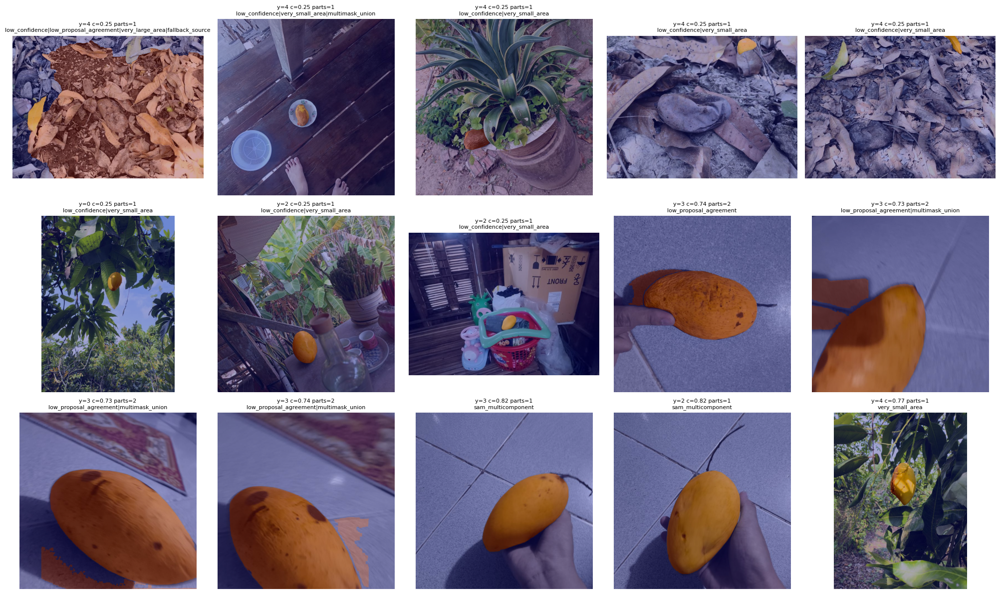

{
  "status": "PSEUDO_MASK_NO_PIXEL_GROUND_TRUTH",
  "n": 0,
  "mean_iou": null,
  "mean_dice": null,
  "warning": "sam_iou is SAM's own predicted mask-quality score. supervision_ready is a heuristic confidence gate, not an accuracy guarantee."
}
⏱ 03_mask_audit: 0.04 min cumulative


In [13]:
with timed_stage('03_mask_audit'):
    # ============================================================
    # MASK RELIABILITY AUDIT
    # SAM self-IoU is predicted mask quality, not measured IoU.
    # ============================================================
    detection_df["supervision_ready"] = (
        detection_df["mask_confidence"] >= CFG.mask_supervision_min_confidence
    )
    detection_df["high_confidence"] = (
        detection_df["mask_confidence"] >= CFG.mask_high_confidence
    )
    mask_audit_df = detection_df[
        detection_df["split"] != "external_test"
    ].copy()
    ready_rate = float(mask_audit_df["supervision_ready"].mean())
    high_rate = float(mask_audit_df["high_confidence"].mean())
    print(
        f"Supervision-ready: {ready_rate:.2%} | "
        f"high-confidence: {high_rate:.2%}"
    )

    mask_summary = (
        mask_audit_df.groupby(["split", "detector_source"])
        .agg(
            count=("path", "size"),
            mean_detector_score=("detector_score", "mean"),
            mean_sam_self_iou=("sam_iou", "mean"),
            mean_confidence=("mask_confidence", "mean"),
            mean_area=("mask_area_ratio", "mean"),
            mean_box_inside=("mask_box_inside", "mean"),
            mean_box_fill=("mask_box_fill", "mean"),
            mean_components=("mask_component_count", "mean"),
            mean_proposal_agreement=("proposal_agreement", "mean"),
            mean_union_gain=("candidate_union_gain", "mean"),
            union_used_rate=(
                "union_added_components",
                lambda x: float((x > 0).mean()),
            ),
        )
        .reset_index()
    )
    mask_by_class = (
        mask_audit_df.groupby(["split", "label"])
        .agg(
            mask_confidence=("mask_confidence", "mean"),
            mask_area_ratio=("mask_area_ratio", "mean"),
            supervision_ready=("supervision_ready", "mean"),
            multi_component_rate=(
                "mask_component_count",
                lambda x: float((x > 1).mean()),
            ),
            union_used_rate=(
                "union_added_components",
                lambda x: float((x > 0).mean()),
            ),
            proposal_agreement=("proposal_agreement", "mean"),
        )
        .reset_index()
    )
    display(mask_summary)
    display(mask_by_class)
    mask_summary.to_csv(
        OUTPUT_DIR / "mask_summary_by_split_source.csv", index=False
    )
    mask_by_class.to_csv(
        OUTPUT_DIR / "mask_summary_by_split_class.csv", index=False
    )

    review_reasons = []
    for _, row in mask_audit_df.iterrows():
        reasons = []
        if float(row["mask_confidence"]) < CFG.mask_review_confidence:
            reasons.append("low_confidence")
        if float(row["proposal_agreement"]) < CFG.mask_review_agreement:
            reasons.append("low_proposal_agreement")
        if float(row["mask_area_ratio"]) < CFG.mask_review_min_area:
            reasons.append("very_small_area")
        if float(row["mask_area_ratio"]) > CFG.mask_review_max_area:
            reasons.append("very_large_area")
        if float(row["mask_box_inside"]) < .95:
            reasons.append("outside_detector_box")
        if int(row["mask_component_count"]) > 2:
            reasons.append("many_components")
        if int(row["union_added_components"]) > 0:
            reasons.append("multimask_union")
        if any(
            token in str(row["mask_source"]).lower()
            for token in ("fallback", "grabcut", "failure")
        ):
            reasons.append("fallback_source")
        review_reasons.append("|".join(reasons))

    mask_audit_df["review_reason"] = review_reasons
    mask_review_df = (
        mask_audit_df[mask_audit_df["review_reason"] != ""]
        .sort_values(
            ["mask_confidence", "proposal_agreement", "mask_area_ratio"]
        )
        .copy()
    )
    mask_review_df.to_csv(
        OUTPUT_DIR / "mask_review_queue.csv", index=False
    )
    print(
        f"Mask review queue: {len(mask_review_df)}/"
        f"{len(mask_audit_df)} images"
    )

    audit_candidates = pd.concat([
        mask_review_df.head(8),
        mask_audit_df[
            mask_audit_df["mask_component_count"] > 1
        ].head(4),
        mask_audit_df.sort_values("path")
        .groupby("label", group_keys=False).head(1),
    ]).drop_duplicates("path").head(15)

    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.ravel()
    for axis in axes:
        axis.axis("off")
    for axis, (_, row) in zip(axes, audit_candidates.iterrows()):
        with Image.open(row["path"]) as image, Image.open(
            row["mask_path"]
        ) as mask:
            image = ImageOps.exif_transpose(image).convert("RGB")
            mask = mask.convert("L").resize(
                image.size, Image.Resampling.NEAREST
            )
            axis.imshow(image)
            axis.imshow(np.asarray(mask), cmap="jet", alpha=.35)
        title_reason = row["review_reason"] or str(row["mask_source"])
        axis.set_title(
            f"y={int(row['label'])} c={row['mask_confidence']:.2f} "
            f"parts={int(row['mask_component_count'])}\n{title_reason}",
            fontsize=8,
        )
        axis.axis("off")
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "mask_review_contact_sheet.jpg",
        dpi=115,
        bbox_inches="tight",
        pil_kwargs={"quality": 82, "optimize": True},
    )
    plt.show()
    plt.close(fig)

    def find_manual_audit_mask(image_path):
        if not MANUAL_MASK_AUDIT_ROOT:
            return None
        root = Path(MANUAL_MASK_AUDIT_ROOT)
        image_path = Path(image_path)
        rel = relative_image_path(image_path)
        candidates = [
            root / rel.parent / f"{rel.stem}.png",
            root / image_path.parent.name / f"{image_path.stem}.png",
            root / f"{image_path.stem}.png",
        ]
        return next((p for p in candidates if p.is_file()), None)

    manual_rows = []
    if MANUAL_MASK_AUDIT_ROOT:
        for _, row in mask_audit_df.iterrows():
            gt_path = find_manual_audit_mask(row["path"])
            if gt_path is None:
                continue
            with Image.open(row["mask_path"]) as predicted_image:
                predicted = (
                    np.asarray(predicted_image.convert("L")) > 127
                )
                pred_size = predicted_image.size
            with Image.open(gt_path) as ground_truth_image:
                ground_truth = (
                    np.asarray(
                        ground_truth_image.convert("L").resize(
                            pred_size, Image.Resampling.NEAREST
                        )
                    ) > 127
                )
            intersection = float(
                (predicted & ground_truth).sum()
            )
            union = float((predicted | ground_truth).sum())
            denominator = float(
                predicted.sum() + ground_truth.sum()
            )
            manual_rows.append({
                "path": row["path"],
                "ground_truth_mask": str(gt_path),
                "iou": intersection / max(union, 1.0),
                "dice": 2 * intersection / max(
                    denominator, 1.0
                ),
                "mask_confidence": float(
                    row["mask_confidence"]
                ),
                "sam_self_iou": float(row["sam_iou"]),
            })

    manual_mask_df = pd.DataFrame(
        manual_rows,
        columns=[
            "path", "ground_truth_mask", "iou", "dice",
            "mask_confidence", "sam_self_iou",
        ],
    )
    manual_mask_df.to_csv(
        OUTPUT_DIR / "manual_mask_accuracy.csv", index=False
    )

    if len(manual_mask_df):
        mask_accuracy_status = {
            "status": "MEASURED_ON_HUMAN_MASK_SUBSET",
            "n": int(len(manual_mask_df)),
            "mean_iou": float(
                manual_mask_df["iou"].mean()
            ),
            "median_iou": float(
                manual_mask_df["iou"].median()
            ),
            "mean_dice": float(
                manual_mask_df["dice"].mean()
            ),
            "warning": (
                "Subset accuracy does not guarantee every image."
            ),
        }
        display(manual_mask_df.describe())
    else:
        mask_accuracy_status = {
            "status": "PSEUDO_MASK_NO_PIXEL_GROUND_TRUTH",
            "n": 0,
            "mean_iou": None,
            "mean_dice": None,
            "warning": (
                "sam_iou is SAM's own predicted mask-quality "
                "score. supervision_ready is a heuristic "
                "confidence gate, not an accuracy guarantee."
            ),
        }

    json.dump(
        mask_accuracy_status,
        open(OUTPUT_DIR / "mask_accuracy_status.json", "w"),
        indent=2,
    )
    print(json.dumps(mask_accuracy_status, indent=2))

### Parallel RAM preload and deterministic I/O cache

In [14]:
# ============================================================
# V18 PARALLEL IMAGE/MASK PRELOAD — DISK I/O REMOVED FROM EPOCHS
# ============================================================
from concurrent.futures import ThreadPoolExecutor,as_completed
V18_PAIR_CACHE={};V18_MASK_PATH_BY_IMAGE=dict(zip(detection_df.path.astype(str),detection_df.mask_path.astype(str)));V18_PAIR_CACHE_STATUS={'enabled':False,'reason':'disabled','estimated_mib':0.0}
def _v18_letterbox_arrays(path):
    mask_path=V18_MASK_PATH_BY_IMAGE[str(path)]
    with Image.open(path) as im,Image.open(mask_path) as mm:
        image=ImageOps.exif_transpose(im).convert('RGB');mask=mm.convert('L').resize(image.size,Image.Resampling.NEAREST)
        w,h=image.size;s=min(CFG.image_size/w,CFG.image_size/h);nw,nh=max(1,round(w*s)),max(1,round(h*s))
        ir=image.resize((nw,nh),Image.Resampling.BICUBIC);mr=mask.resize((nw,nh),Image.Resampling.NEAREST)
        canvas=Image.new('RGB',(CFG.image_size,CFG.image_size),IMAGENET_FILL);mcanvas=Image.new('L',(CFG.image_size,CFG.image_size),0)
        left,top=(CFG.image_size-nw)//2,(CFG.image_size-nh)//2;canvas.paste(ir,(left,top));mcanvas.paste(mr,(left,top))
        return np.asarray(canvas,dtype=np.uint8).copy(),np.asarray(mcanvas,dtype=np.uint8).copy()
if V18_RAM_CACHE_ENABLEE:
    try:
        requested_scope = os.environ.get(
            "CLASSIFIER_RAM_CACHE_SCOPE", "auto"
        ).strip().lower()
        if requested_scope not in {"auto", "train", "trainval", "all"}:
            raise ValueError(
                "CLASSIFIER_RAM_CACHE_SCOPE must be auto, train, trainval or all."
            )
        available_mib = psutil.virtual_memory().available / 1024**2
        if requested_scope == "auto":
            # On a 16 GiB workstation, cache only TRAIN. This captures the
            # speed-critical repeated path and avoids spending RAM on TEST.
            requested_scope = (
                "all" if available_mib >= 9 * 1024
                else "trainval" if available_mib >= 6 * 1024
                else "train"
            )
        allowed_splits = {
            "train": {"train"},
            "trainval": {"train", "validation"},
            "all": set(all_split_df.split.astype(str).unique()),
        }[requested_scope]
        cache_frame = all_split_df[
            all_split_df.split.astype(str).isin(allowed_splits)
        ]
        paths = cache_frame.path.astype(str).tolist()
        estimate = len(paths) * CFG.image_size * CFG.image_size * 4 / 1024**2
        required_mib = estimate + V1841_RAM_CACHE_RESERVE_GIB * 1024
        if available_mib < required_mib:
            V18_PAIR_CACHE_STATUS = {
                "enabled": False,
                "reason": (
                    f"reserve_guard_available_{available_mib:.0f}MiB_"
                    f"required_{required_mib:.0f}MiB"
                ),
                "scope": requested_scope,
                "estimated_mib": estimate,
            }
        else:
            with timed_stage('03b_parallel_ram_preload'):
                with ThreadPoolExecutor(max_workers=LOCAL_PRELOAD_THREADS) as ex:
                    futures = {ex.submit(_v18_letterbox_arrays, p): p for p in paths}
                    for n, future in enumerate(as_completed(futures), 1):
                        path = futures[future]
                        V18_PAIR_CACHE[path] = future.result()
                        if n == 1 or n % 300 == 0 or n == len(paths):
                            print(f'RAM preload {n}/{len(paths)}')
            V18_PAIR_CACHE_STATUS = {
                "enabled": True,
                "reason": "ok",
                "scope": requested_scope,
                "estimated_mib": estimate,
                "actual_items": len(V18_PAIR_CACHE),
                "threads": LOCAL_PRELOAD_THREADS,
                "reserve_gib": V1841_RAM_CACHE_RESERVE_GIB,
            }
    except Exception as exc:
        V18_PAIR_CACHE.clear()
        V18_PAIR_CACHE_STATUS = {
            "enabled": False,
            "reason": f'{type(exc).__name__}: {exc}',
            "estimated_mib": 0.0,
        }
json.dump(V18_PAIR_CACHE_STATUS,open(OUTPUT_DIR/'ram_preload_status.json','w',encoding='utf-8'),indent=2)
print('RAM preload:',V18_PAIR_CACHE_STATUS)


RAM preload 1/1301


RAM preload 300/1301


RAM preload 600/1301


RAM preload 900/1301


RAM preload 1200/1301
RAM preload 1301/1301
⏱ 03b_parallel_ram_preload: 0.04 min cumulative
RAM preload: {'enabled': True, 'reason': 'ok', 'scope': 'train', 'estimated_mib': 508.203125, 'actual_items': 1301, 'threads': 4, 'reserve_gib': 4.0}


## 2. Mask-aware data and explicit yellow/green micro-evidence

Besides the unchanged V15 inputs, each 16×16 patch receives absolute and fruit-relative colour/texture statistics. This gives the new branch direct evidence about a small grey, dark or brown region even when most of the fruit remains green.

## Generic dynamic profile (arbitrary class names/counts)

In [15]:
# ============================================================
# V18 GENERIC DYNAMIC CLASSIFIER — RUNS ONLY OUTSIDE MANGO PROFILE
# ============================================================
V18_GENERIC_COMPLETED=False
if TASK_PROFILE=='generic_dynamic':
    from torchvision import models
    from torch.utils.data import WeightedRandomSampler
    with timed_stage('04_generic_dynamic_training'):
        generic_meta=detection_df.set_index('path').to_dict('index')
        class GenericDataset(Dataset):
            def __init__(self,paths,labels,training=False):self.paths=list(paths);self.labels=list(map(int,labels));self.training=training
            def __len__(self):return len(self.paths)
            def __getitem__(self,i):
                path=self.paths[i];label=self.labels[i]
                if path in V18_PAIR_CACHE:ia,ma=V18_PAIR_CACHE[path];image=Image.fromarray(ia);mask=Image.fromarray(ma)
                else:ia,ma=_v18_letterbox_arrays(path);image=Image.fromarray(ia);mask=Image.fromarray(ma)
                rng=np.random.default_rng(CFG.seed*1000003+i+(random.randint(0,2**20) if self.training else 0))
                if self.training:
                    if rng.random()<.5:image=TF.hflip(image);mask=TF.hflip(mask)
                    angle=float(rng.uniform(-7,7));translate=[int(rng.uniform(-.02,.02)*CFG.image_size),int(rng.uniform(-.02,.02)*CFG.image_size)];scale=float(rng.uniform(.97,1.03))
                    image=TF.affine(image,angle=angle,translate=translate,scale=scale,shear=[0.,0.],interpolation=InterpolationMode.BILINEAR,fill=IMAGENET_FILL)
                    mask=TF.affine(mask,angle=angle,translate=translate,scale=scale,shear=[0.,0.],interpolation=InterpolationMode.NEAREST,fill=0)
                    if rng.random()<.08:image=transforms.ColorJitter(brightness=.03,contrast=.03,saturation=.02,hue=.002)(image)
                rgb=np.asarray(image,dtype=np.float32)/255.;m=np.asarray(mask,dtype=np.float32)/255.;sel=m>.35
                if sel.sum()<32:sel=np.ones_like(sel,bool)
                pix=rgb[sel];mean=pix.mean(0);std=pix.std(0);mx=pix.max(1);mn=pix.min(1);sat=(mx-mn)/(mx+1e-4);lum=.2126*pix[:,0]+.7152*pix[:,1]+.0722*pix[:,2]
                stats=torch.tensor(np.r_[mean,std,sat.mean(),sat.std(),lum.mean(),lum.std(),sel.mean(),np.quantile(lum,[.1,.5,.9])],dtype=torch.float32)
                x=TF.normalize(TF.to_tensor(image),IMAGENET_MEAN,IMAGENET_STD);mt=TF.to_tensor(mask).clamp(0,1);pm=F.interpolate(mt[None],size=(GRID_SIZE,GRID_SIZE),mode='area')[0,0].flatten()
                return {'pixel_values':x,'patch_mask':pm,'stats':stats,'labels':torch.tensor(label),'path':path}
        def generic_loader(ds,training=False,batch=None):
            if training:
                counts=np.bincount(ds.labels,minlength=NUM_CLASSES).astype(float);cw=np.minimum((counts.max()/np.maximum(counts,1))**.30,2.0);sw=torch.tensor(cw[np.asarray(ds.labels)],dtype=torch.double);sampler=WeightedRandomSampler(sw,len(sw),replacement=True)
            else:sampler=None
            return DataLoader(ds,batch_size=batch or (TRAIN_BATCH if training else max(CFG.eval_batch,TRAIN_BATCH)),shuffle=False,sampler=sampler,num_workers=0,pin_memory=PIN_MEMORY)
        gtrain=GenericDataset(X_train,y_train,True);gval=GenericDataset(X_val,y_val);gtest=GenericDataset(X_test,y_test);gtrainval=GenericDataset(X_train+X_val,y_train+y_val,True)
        class GenericSubcenter(nn.Module):
            def __init__(self,d,k,c):super().__init__();self.w=nn.Parameter(torch.randn(c,k,d)*.02);self.scale=nn.Parameter(torch.tensor(12.))
            def forward(self,x):return (self.scale.clamp(4,30)*torch.einsum('bd,ckd->bck',F.normalize(x,dim=1),F.normalize(self.w,dim=2))).max(2).values
        class GenericV18(nn.Module):
            def __init__(self):
                super().__init__();self.vit=models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1);self.vit.heads=nn.Identity();[p.requires_grad_(False) for p in self.vit.parameters()];d=self.vit.hidden_dim;self.d=d;self.reg=nn.Parameter(torch.randn(1,4,d)*.02);self.mask=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,1));self.part=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,d//4),nn.GELU(),nn.Linear(d//4,1));self.query=nn.Parameter(torch.randn(1,1,d)*.02);self.stats=nn.Sequential(nn.Linear(14,d),nn.LayerNorm(d),nn.GELU());self.base=nn.Sequential(nn.LayerNorm(d*3),nn.Linear(d*3,d),nn.GELU(),nn.Dropout(.25),nn.LayerNorm(d));self.obj=nn.Sequential(nn.LayerNorm(d*4),nn.Linear(d*4,d),nn.GELU(),nn.Dropout(.20),nn.LayerNorm(d));self.gate=nn.Parameter(torch.tensor(-1.8));self.res=nn.Linear(d,d);nn.init.zeros_(self.res.weight);nn.init.zeros_(self.res.bias);self.main=nn.Linear(d,NUM_CLASSES);self.object=nn.Linear(d,NUM_CLASSES);self.sub=GenericSubcenter(d,3,NUM_CLASSES)
            def encode(self,x):
                p=self.vit.conv_proj(x);b,d,g,_=p.shape;p=p.reshape(b,d,g*g).permute(0,2,1);pos=self.vit.encoder.pos_embedding;pp=pos[:,1:].reshape(1,14,14,d).permute(0,3,1,2);pp=F.interpolate(pp.float(),(g,g),mode='bicubic',align_corners=False).to(p.dtype).permute(0,2,3,1).reshape(1,g*g,d);z=torch.cat([self.vit.class_token.expand(b,-1,-1)+pos[:,:1].to(p.dtype),self.reg.expand(b,-1,-1),p+pp],1);z=self.vit.encoder.dropout(z)
                for block in self.vit.encoder.layers:z=block(z)
                return self.vit.encoder.ln(z),g
            def forward(self,x,teacher=None):
                z,g=self.encode(x);cls=z[:,0];regs=z[:,1:5];patch=z[:,5:];mask_logits=self.mask(patch).squeeze(-1);internal=torch.sigmoid(mask_logits);prior=teacher.float().clamp(0,1) if teacher is not None else internal.detach();score=self.part(patch).squeeze(-1)+.65*torch.log(prior.clamp_min(.03));k=min(40,patch.shape[1]);v,ix=score.topk(k,1);w=v.float().softmax(1).to(patch.dtype);sel=torch.gather(patch,1,ix[:,:,None].expand(-1,-1,self.d));part=(sel*w[:,:,None]).sum(1);reg=regs.mean(1);q=self.query.expand(len(x),-1,-1);qa=(q@patch.transpose(1,2)/math.sqrt(self.d)+.85*torch.log(prior.clamp_min(.03))[:,None,:]).float().softmax(-1);qf=(qa.to(patch.dtype)@patch)[:,0];fw=prior/prior.sum(1,keepdim=True).clamp_min(1e-5);fg=(patch*fw.to(patch.dtype)[:,:,None]).sum(1);st=self.stats(generic_batch_stats) if False else None;return z,g,cls,reg,part,qf,fg,mask_logits,internal,qa[:,0]
            def classify(self,x,teacher,stats):
                z,g,cls,reg,part,qf,fg,mask_logits,internal,qa=self.forward(x,teacher);sf=self.stats(stats.float()).to(x.dtype);base=self.base(torch.cat([cls,reg,part],1));obj=self.obj(torch.cat([part,qf,fg,sf],1));feat=base+torch.sigmoid(self.gate)*self.res(obj);return {'logits':self.main(feat),'object_logits':self.object(obj),'subcenter_logits':self.sub(obj),'mask_logits':mask_logits,'mask':internal,'query_attention':qa,'feature':feat}
        counts=np.bincount(y_train,minlength=NUM_CLASSES).astype(float);gcw=torch.tensor(np.minimum((counts.max()/np.maximum(counts,1))**.35,2.0),dtype=torch.float32,device=DEVICE);gcw/=gcw.mean()
        def gevaluate(m,loader):
            m.eval();ys=[];heads=defaultdict(list);paths=[];loss=[]
            with torch.no_grad():
                for raw in loader:
                    x=raw['pixel_values'].to(DEVICE);pm=raw['patch_mask'].to(DEVICE);st=raw['stats'].to(DEVICE);y=raw['labels'].to(DEVICE)
                    with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):o=m.classify(x,pm,st)
                    for k in ('logits','object_logits','subcenter_logits'):heads[k].append(o[k].float().softmax(1).cpu().numpy())
                    ys.append(y.cpu().numpy());paths.extend(raw['path']);loss.append(F.cross_entropy(o['logits'].float(),y).item())
            return {'labels':np.concatenate(ys),'main':np.concatenate(heads['logits']),'object':np.concatenate(heads['object_logits']),'subcenter':np.concatenate(heads['subcenter_logits']),'paths':paths,'loss':float(np.mean(loss))}
        def gmetrics(y,p):
            pred=p.argmax(1);f=f1_score(y,pred,average=None,labels=np.arange(NUM_CLASSES),zero_division=0);return {'accuracy':accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),'macro_f1':f.mean(),'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),'min_class_f1':f.min(),'pred':pred,'class_f1':f}
        def train_generic(fixed_epochs=None):
            m=GenericV18().to(DEVICE)
            trainable_params=[p for p in m.parameters() if p.requires_grad]
            try:
                opt=torch.optim.AdamW(trainable_params,lr=1e-4,weight_decay=.03,fused=(DEVICE.type=='cuda'))
                generic_optimizer_impl='adamw_fused'
            except (TypeError,RuntimeError):
                opt=torch.optim.AdamW(trainable_params,lr=1e-4,weight_decay=.03)
                generic_optimizer_impl='adamw_standard'
            scaler=torch.amp.GradScaler('cuda',enabled=AMP_ENABLED)
            history=[];best=None;best_ep=1;best_key=(-1,-1);wait=0
            epochs=int(fixed_epochs or 10)
            loader=generic_loader(gtrain if fixed_epochs is None else gtrainval,True)
            best_mode='main'
            for ep in range(1,epochs+1):
                epoch_start=time.perf_counter();m.train();tot=0;n=0;ys=[];ps=[];opt.zero_grad(set_to_none=True)
                for step,raw in enumerate(tqdm(loader,desc=f'generic {ep}/{epochs}',leave=False),1):
                    x=raw['pixel_values'].to(DEVICE,non_blocking=True);pm=raw['patch_mask'].to(DEVICE,non_blocking=True);st=raw['stats'].to(DEVICE,non_blocking=True);y=raw['labels'].to(DEVICE,non_blocking=True)
                    with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):
                        o=m.classify(x,pm,st)
                        mask_target=pm
                        mask_loss=F.binary_cross_entropy_with_logits(o['mask_logits'].float(),mask_target.float())
                        outside=(o['query_attention'].float()*(1-mask_target.float())).sum(1).mean()
                        loss=(.82*F.cross_entropy(o['logits'].float(),y,weight=gcw)
                              +.12*F.cross_entropy(o['object_logits'].float(),y,weight=gcw)
                              +.08*F.cross_entropy(o['subcenter_logits'].float(),y,weight=gcw)
                              +.08*mask_loss+.04*outside)
                        scaled=loss/max(1,GRAD_ACCUM)
                    scaler.scale(scaled).backward()
                    if step%GRAD_ACCUM==0 or step==len(loader):
                        scaler.unscale_(opt);torch.nn.utils.clip_grad_norm_(trainable_params,1.)
                        scaler.step(opt);scaler.update();opt.zero_grad(set_to_none=True)
                    tot+=float(loss.detach())*len(y);n+=len(y);ys.append(y.cpu().numpy());ps.append(o['logits'].float().softmax(1).detach().cpu().numpy())
                epoch_seconds=time.perf_counter()-epoch_start
                row={'epoch':ep,'train_loss':tot/max(1,n),'epoch_seconds':epoch_seconds,'images_per_second':n/max(epoch_seconds,1e-6),'optimizer_impl':generic_optimizer_impl,
                     **{f'train_{k}':v for k,v in gmetrics(np.concatenate(ys),np.concatenate(ps)).items() if np.isscalar(v)}}
                if fixed_epochs is None:
                    vc=gevaluate(m,generic_loader(gval))
                    cands={'main':vc['main'],'main_object':.85*vc['main']+.15*vc['object'],'main_subcenter':.85*vc['main']+.15*vc['subcenter']}
                    name,prob=max(cands.items(),key=lambda q:(gmetrics(vc['labels'],q[1])['macro_f1'],gmetrics(vc['labels'],q[1])['min_class_f1']))
                    vm=gmetrics(vc['labels'],prob)
                    row.update({'val_loss':vc['loss'],'val_accuracy':vm['accuracy'],'val_macro_f1':vm['macro_f1'],'val_min_class_f1':vm['min_class_f1'],'val_mode':name})
                    key=(vm['macro_f1'],vm['min_class_f1'])
                    if key>best_key:
                        best_key=key;best_ep=ep;best={k:v.detach().cpu().clone() for k,v in m.state_dict().items()};wait=0;best_mode=name
                    else:
                        wait+=1
                    if ep>=5 and wait>=3:
                        history.append(row);break
                history.append(row)
            if best is not None:m.load_state_dict(best)
            return m,pd.DataFrame(history),best_ep,(best_mode if fixed_epochs is None else None)
        generic_calib,generic_history,generic_best_epoch,generic_mode=train_generic();generic_history.to_csv(OUTPUT_DIR/'generic_training_history.csv',index=False)
        # Fresh refit with locked epoch, then locked test.
        generic_model,_,_,_=train_generic(fixed_epochs=generic_best_epoch);tc=gevaluate(generic_model,generic_loader(gtest));gp=tc['main'] if generic_mode=='main' else (.85*tc['main']+.15*(tc['object'] if generic_mode=='main_object' else tc['subcenter']));gm=gmetrics(tc['labels'],gp);pred=gm['pred'];cm=confusion_matrix(tc['labels'],pred,labels=np.arange(NUM_CLASSES));report=pd.DataFrame(classification_report(tc['labels'],pred,labels=np.arange(NUM_CLASSES),target_names=[CLASS_SEMANTICS[i] for i in range(NUM_CLASSES)],output_dict=True,zero_division=0)).T
        overall=pd.DataFrame([{'accuracy':gm['accuracy'],'balanced_accuracy':gm['balanced_accuracy'],'macro_f1':gm['macro_f1'],'weighted_f1':gm['weighted_f1'],'min_class_f1':gm['min_class_f1'],'correct':int((pred==tc['labels']).sum()),'errors':int((pred!=tc['labels']).sum()),'n':len(pred),'selected_mode':generic_mode,'best_epoch':generic_best_epoch}]);overall.to_csv(OUTPUT_DIR/'generic_test_overall_metrics.csv',index=False);report.to_csv(OUTPUT_DIR/'generic_test_classification_report.csv');np.save(OUTPUT_DIR/'generic_confusion_matrix.npy',cm)
        pred_df=pd.DataFrame({'path':tc['paths'],'label':tc['labels'],'pred_label':pred,'confidence':gp.max(1),'correct':pred==tc['labels']});[pred_df.__setitem__(f'p{i}',gp[:,i]) for i in range(NUM_CLASSES)];pred_df.to_csv(OUTPUT_DIR/'generic_test_predictions.csv',index=False);errors_df=pred_df[~pred_df.correct].copy();errors_df.to_csv(OUTPUT_DIR/'generic_test_misclassifications.csv',index=False)
        fig,ax=plt.subplots(figsize=(max(7,NUM_CLASSES*.65),max(6,NUM_CLASSES*.58)));im=ax.imshow(cm,cmap='Blues');ax.set_xticks(range(NUM_CLASSES));ax.set_yticks(range(NUM_CLASSES));ax.set_xticklabels([CLASS_SEMANTICS[i] for i in range(NUM_CLASSES)],rotation=45,ha='right');ax.set_yticklabels([CLASS_SEMANTICS[i] for i in range(NUM_CLASSES)]);ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title('Generic V18 confusion matrix');fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUTPUT_DIR/'generic_confusion_matrix.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
        cmn=cm/np.maximum(cm.sum(1,keepdims=True),1)
        fig,ax=plt.subplots(figsize=(max(7,NUM_CLASSES*.65),max(6,NUM_CLASSES*.58)));im=ax.imshow(cmn,cmap='Blues');ax.set_xticks(range(NUM_CLASSES));ax.set_yticks(range(NUM_CLASSES));ax.set_xticklabels([CLASS_SEMANTICS[i] for i in range(NUM_CLASSES)],rotation=45,ha='right');ax.set_yticklabels([CLASS_SEMANTICS[i] for i in range(NUM_CLASSES)]);ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title('Generic V18 normalized confusion matrix');fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUTPUT_DIR/'generic_confusion_matrix_normalized.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
        for tr,va,title,name in [('train_loss','val_loss','Loss','generic_curve_loss.png'),('train_accuracy','val_accuracy','Accuracy','generic_curve_accuracy.png'),('train_macro_f1','val_macro_f1','Macro-F1','generic_curve_macro_f1.png')]:
            fig,ax=plt.subplots(figsize=(8,4.5));
            if tr in generic_history:ax.plot(generic_history.epoch,generic_history[tr],marker='o',label=tr)
            if va in generic_history:ax.plot(generic_history.epoch,generic_history[va],marker='o',label=va)
            ax.set_xlabel('Epoch');ax.set_title(title);ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUTPUT_DIR/name,dpi=145,bbox_inches='tight');plt.show();plt.close(fig)
        generic_delta={k:v.detach().cpu().half() for k,v in generic_model.state_dict().items() if not k.startswith('vit.')}
        _generic_payload={'delta_state':generic_delta,'classes_json':json.dumps(CLASS_SEMANTICS,ensure_ascii=False),'object_prompt':OBJECT_PROMPT}
        v184_try_compact_torch_save(_generic_payload,OUTPUT_DIR/'v18_generic_compact_delta.pt',stage='generic_final_output')
        _generic_payload.clear();gc.collect()
        print('GENERIC V18 FINAL');display(overall);display(report);V18_FINAL_SUMMARY={'profile':'generic_dynamic',**overall.iloc[0].to_dict()};V18_GENERIC_COMPLETED=True


In [16]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # DATASET — FIXED 320 PX + MASKED COLOUR/TEXTURE STATISTICS
    # ============================================================
    metadata_by_path=detection_df.set_index('path').to_dict('index')
    def letterbox_pair(image,mask,size,image_fill=IMAGENET_FILL):
        w,h=image.size;s=min(size/w,size/h);nw,nh=max(1,round(w*s)),max(1,round(h*s));ir=image.resize((nw,nh),Image.Resampling.BICUBIC);mr=mask.resize((nw,nh),Image.Resampling.NEAREST)
        c=Image.new('RGB',(size,size),image_fill);mc=Image.new('L',(size,size),0);l,t=(size-nw)//2,(size-nh)//2;c.paste(ir,(l,t));mc.paste(mr,(l,t));return c,mc

    def normalized_tensor(im):return TF.normalize(TF.to_tensor(im),IMAGENET_MEAN,IMAGENET_STD)
    def background_deemphasis(image,mask):
        bg=ImageEnhance.Color(image.filter(ImageFilter.GaussianBlur(5))).enhance(.45);soft=mask.filter(ImageFilter.GaussianBlur(4));return Image.composite(image,bg,soft)
    def object_erase(t,pm,rng):
        if rng.random()>=CFG.object_erasing_p:return t
        up=F.interpolate(pm.view(1,1,GRID_SIZE,GRID_SIZE),size=(CFG.image_size,CFG.image_size),mode='nearest')[0,0].numpy();ys,xs=np.where(up>.4)
        if not len(xs):return t
        area=CFG.image_size**2;r=rng.uniform(CFG.object_erasing_min_area,CFG.object_erasing_max_area)*area;asp=np.exp(rng.uniform(np.log(.6),np.log(1.8)));eh=max(1,int(np.sqrt(r/asp)));ew=max(1,int(np.sqrt(r*asp)));q=int(rng.integers(len(xs)));cy,cx=int(ys[q]),int(xs[q]);y0=max(0,cy-eh//2);x0=max(0,cx-ew//2);o=t.clone();o[:,y0:min(CFG.image_size,y0+eh),x0:min(CFG.image_size,x0+ew)]=0;return o

    def _v1841_prepare_image_arrays(image, mask):
        # Compute the same float32 division as the original code exactly once,
        # then share it between global and patch-local descriptors.
        image_u8 = np.asarray(image, dtype=np.uint8)
        mask_u8 = np.asarray(mask, dtype=np.uint8)
        rgb = np.asarray(image, dtype=np.float32) / 255.0
        mask_float = np.asarray(mask, dtype=np.float32) / 255.0
        return image_u8, mask_u8, rgb, mask_float

    def _v185_sigmoid_np(value):
        value = np.clip(np.asarray(value, dtype=np.float32), -30.0, 30.0)
        return 1.0 / (1.0 + np.exp(-value))


    def _v185_soft_chroma_maps(rgb, hsv):
        """Return physics-inspired soft yellow and green membership maps.

        The maps combine hue, saturation/value reliability and opponent-colour
        evidence. They are descriptors, not pseudo-labels and never inspect class
        labels, validation outcomes or test outcomes.
        """
        hue_degrees = hsv[..., 0].astype(np.float32) * 2.0
        saturation = hsv[..., 1].astype(np.float32) / 255.0
        value = hsv[..., 2].astype(np.float32) / 255.0

        def circular_gaussian(center, width):
            distance = np.abs(hue_degrees - float(center))
            distance = np.minimum(distance, 360.0 - distance)
            return np.exp(-0.5 * (distance / float(width)) ** 2)

        red, green_channel, blue = (
            rgb[..., 0], rgb[..., 1], rgb[..., 2]
        )
        reliability = (
            0.25
            + 0.75 * _v185_sigmoid_np((saturation - 0.06) / 0.06)
        ) * _v185_sigmoid_np((value - 0.14) / 0.08)

        yellow_hue = circular_gaussian(55.0, 24.0)
        yellow_opponent = _v185_sigmoid_np(
            (((red + green_channel) * 0.5 - blue) - 0.045) / 0.055
        )
        yellow_balance = np.exp(-np.abs(red - green_channel) / 0.28)
        yellow = reliability * (
            0.55 * yellow_hue
            + 0.45 * yellow_opponent * yellow_balance
        )

        green_hue = circular_gaussian(112.0, 34.0)
        green_opponent = _v185_sigmoid_np(
            ((green_channel - 0.5 * (red + blue)) - 0.012) / 0.050
        )
        green = reliability * (
            0.55 * green_hue + 0.45 * green_opponent
        )

        return (
            np.clip(yellow, 0.0, 1.0).astype(np.float32),
            np.clip(green, 0.0, 1.0).astype(np.float32),
        )


    def _v185_largest_component_fraction(binary_map, denominator):
        binary = np.asarray(binary_map, dtype=np.uint8)
        if binary.sum() == 0 or denominator <= 0:
            return 0.0
        count, _, statistics, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )
        if count <= 1:
            return 0.0
        largest = float(statistics[1:, cv2.CC_STAT_AREA].max())
        return largest / max(float(denominator), 1.0)

    def masked_colour_stats(image, mask, prepared=None):
        image_u8, _, rgb, mask_float = (
            _v1841_prepare_image_arrays(image, mask)
            if prepared is None else prepared
        )
        selected = mask_float > 0.35
        if selected.sum() < 32:
            selected = np.ones(mask_float.shape, dtype=bool)
        pixels = rgb[selected]
        mean = pixels.mean(0)
        std = pixels.std(0)

        hsv = cv2.cvtColor(image_u8, cv2.COLOR_RGB2HSV)
        hsv_float = hsv.astype(np.float32)
        saturation = hsv_float[..., 1][selected] / 255.0
        value = hsv_float[..., 2][selected] / 255.0
        red_green = pixels[:, 0] - pixels[:, 1]
        yellow_blue = 0.5 * (pixels[:, 0] + pixels[:, 1]) - pixels[:, 2]
        green_ratio = pixels[:, 1] / np.maximum(pixels.sum(1), 1e-5)
        luminance = (
            0.2126 * pixels[:, 0]
            + 0.7152 * pixels[:, 1]
            + 0.0722 * pixels[:, 2]
        )
        gray = cv2.cvtColor(image_u8, cv2.COLOR_RGB2GRAY).astype(np.float32)
        gray *= (1.0 / 255.0)
        grad_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        grad_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        gradient = np.sqrt(grad_x * grad_x + grad_y * grad_y)[selected]
        laplacian = np.abs(cv2.Laplacian(gray, cv2.CV_32F))[selected]
        ys, xs = np.where(selected)
        aspect = (xs.max() - xs.min() + 1) / max(1, ys.max() - ys.min() + 1)

        legacy = np.r_[
            mean,
            std,
            saturation.mean(),
            saturation.std(),
            value.mean(),
            value.std(),
            red_green.mean(),
            red_green.std(),
            yellow_blue.mean(),
            yellow_blue.std(),
            green_ratio.mean(),
            green_ratio.std(),
            np.quantile(luminance, [0.1, 0.5, 0.9]),
            np.quantile(saturation, [0.1, 0.5, 0.9]),
            gradient.mean(),
            gradient.std(),
            laplacian.mean(),
            laplacian.std(),
            (luminance < np.quantile(luminance, 0.2)).mean(),
            (luminance > 0.8).mean(),
            (green_ratio > 0.38).mean(),
            (red_green > 0.05).mean(),
            selected.mean(),
            np.clip(aspect / 3, 0, 1),
        ]
        if len(legacy) != CFG.legacy_colour_stat_dim:
            raise RuntimeError(
                f"legacy colour dim={len(legacy)} "
                f"expected={CFG.legacy_colour_stat_dim}"
            )

        yellow_map, green_map = _v185_soft_chroma_maps(rgb, hsv)
        yellow = yellow_map[selected]
        green = green_map[selected]
        yellow_share = float(
            yellow.sum() / max(float(yellow.sum() + green.sum()), 1e-6)
        )
        yellow_component = _v185_largest_component_fraction(
            (yellow_map > 0.35) & selected,
            selected.sum(),
        )
        chroma = np.asarray(
            [
                yellow.mean(),
                yellow.std(),
                np.quantile(yellow, 0.75),
                np.quantile(yellow, 0.90),
                np.quantile(yellow, 0.95),
                (yellow > 0.25).mean(),
                (yellow > 0.50).mean(),
                green.mean(),
                green.std(),
                np.quantile(green, 0.75),
                np.quantile(green, 0.90),
                (green > 0.25).mean(),
                (green > 0.50).mean(),
                yellow_share,
                yellow.mean() - green.mean(),
                yellow_component,
            ],
            dtype=np.float32,
        )
        if len(chroma) != CFG.chroma_global_dim:
            raise RuntimeError(
                f"chroma global dim={len(chroma)} "
                f"expected={CFG.chroma_global_dim}"
            )
        result = np.concatenate([legacy.astype(np.float32), chroma])
        if len(result) != CFG.colour_stat_dim:
            raise RuntimeError(
                f"colour stat dim={len(result)} expected={CFG.colour_stat_dim}"
            )
        result = np.nan_to_num(result, nan=0.0, posinf=1.0, neginf=-1.0)
        return torch.tensor(result, dtype=torch.float32)


    def patch_local_stats(image, mask, prepared=None):
        """Patch-local legacy descriptors plus explicit yellow/green evidence."""
        image_u8, _, rgb, mask_float = (
            _v1841_prepare_image_arrays(image, mask)
            if prepared is None else prepared
        )
        if rgb.shape[:2] != (CFG.image_size, CFG.image_size):
            raise RuntimeError("patch_local_stats expects the fixed letterboxed image size")
        patch_size = CFG.patch_size
        grid_size = GRID_SIZE
        hsv = cv2.cvtColor(image_u8, cv2.COLOR_RGB2HSV)
        hsv_float = hsv.astype(np.float32)
        saturation = hsv_float[..., 1] / 255.0
        value = hsv_float[..., 2] / 255.0
        luminance = (
            0.2126 * rgb[..., 0]
            + 0.7152 * rgb[..., 1]
            + 0.0722 * rgb[..., 2]
        )
        gray = cv2.cvtColor(image_u8, cv2.COLOR_RGB2GRAY).astype(np.float32)
        gray *= (1.0 / 255.0)
        grad_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        grad_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        gradient = np.sqrt(grad_x * grad_x + grad_y * grad_y)
        yellow_map, green_map = _v185_soft_chroma_maps(rgb, hsv)

        def reshape_patches(array):
            if array.ndim == 2:
                array = array[..., None]
            return array.reshape(
                grid_size, patch_size, grid_size, patch_size, array.shape[-1]
            ).transpose(0, 2, 1, 3, 4)

        mask_patches = reshape_patches(mask_float)[..., 0]
        denominator = mask_patches.sum((2, 3)).clip(min=1e-4)

        def weighted_mean(array):
            return (
                reshape_patches(array) * mask_patches[..., None]
            ).sum((2, 3)) / denominator[..., None]

        mean = weighted_mean(rgb)
        second = weighted_mean(rgb * rgb)
        std = np.sqrt(np.maximum(second - mean * mean, 0))
        sat_mean = weighted_mean(saturation)[..., 0]
        sat_std = np.sqrt(np.maximum(
            weighted_mean(saturation * saturation)[..., 0] - sat_mean * sat_mean,
            0,
        ))
        val_mean = weighted_mean(value)[..., 0]
        val_std = np.sqrt(np.maximum(
            weighted_mean(value * value)[..., 0] - val_mean * val_mean,
            0,
        ))
        lum_mean = weighted_mean(luminance)[..., 0]
        lum_std = np.sqrt(np.maximum(
            weighted_mean(luminance * luminance)[..., 0] - lum_mean * lum_mean,
            0,
        ))
        grad_mean = weighted_mean(gradient)[..., 0]
        grad_std = np.sqrt(np.maximum(
            weighted_mean(gradient * gradient)[..., 0] - grad_mean * grad_mean,
            0,
        ))
        gray_region = ((saturation < 0.24) & (value > 0.15) & (value < 0.82)).astype(np.float32)
        dark_region = (value < 0.34).astype(np.float32)
        brown_region = (
            (rgb[..., 0] > rgb[..., 1] * 1.03)
            & (rgb[..., 1] > rgb[..., 2] * 1.05)
            & (value < 0.78)
        ).astype(np.float32)
        gray_fraction = weighted_mean(gray_region)[..., 0]
        dark_fraction = weighted_mean(dark_region)[..., 0]
        brown_fraction = weighted_mean(brown_region)[..., 0]
        occupancy = reshape_patches(mask_float).mean((2, 3))[..., 0]

        legacy = np.concatenate(
            [
                mean,
                std,
                sat_mean[..., None],
                sat_std[..., None],
                val_mean[..., None],
                val_std[..., None],
                lum_mean[..., None],
                lum_std[..., None],
                grad_mean[..., None],
                grad_std[..., None],
                gray_fraction[..., None],
                dark_fraction[..., None],
                brown_fraction[..., None],
                occupancy[..., None],
            ],
            axis=-1,
        )
        if legacy.shape[-1] != 18:
            raise RuntimeError(f"legacy patch stat dim={legacy.shape[-1]} expected=18")

        yellow_mean = weighted_mean(yellow_map)[..., 0]
        yellow_second = weighted_mean(yellow_map * yellow_map)[..., 0]
        yellow_std = np.sqrt(np.maximum(yellow_second - yellow_mean * yellow_mean, 0))
        yellow_fraction = weighted_mean((yellow_map > 0.25).astype(np.float32))[..., 0]
        yellow_peak = reshape_patches(yellow_map)[..., 0].max((2, 3))
        green_mean = weighted_mean(green_map)[..., 0]
        green_fraction = weighted_mean((green_map > 0.25).astype(np.float32))[..., 0]
        green_peak = reshape_patches(green_map)[..., 0].max((2, 3))
        yellow_share = yellow_mean / np.maximum(yellow_mean + green_mean, 1e-5)
        chroma = np.stack(
            [
                yellow_mean,
                yellow_std,
                yellow_fraction,
                yellow_peak,
                green_mean,
                green_fraction,
                green_peak,
                yellow_share,
            ],
            axis=-1,
        )
        if chroma.shape[-1] != CFG.chroma_patch_dim:
            raise RuntimeError(
                f"chroma patch dim={chroma.shape[-1]} "
                f"expected={CFG.chroma_patch_dim}"
            )
        features = np.concatenate([legacy, chroma], axis=-1)
        features = np.nan_to_num(
            features, nan=0.0, posinf=1.0, neginf=-1.0
        ).astype(np.float32).reshape(grid_size * grid_size, -1)
        if features.shape[1] != CFG.patch_local_stat_dim:
            raise RuntimeError(
                f"patch stat dim={features.shape[1]} expected={CFG.patch_local_stat_dim}"
            )
        return torch.from_numpy(features)

    def jitter_for_label(image,label):
        early=label in (0,1);b=CFG.colour_brightness_early if early else CFG.colour_brightness_other;c=CFG.colour_contrast_early if early else CFG.colour_contrast_other;s=CFG.colour_saturation_early if early else CFG.colour_saturation_other
        return transforms.ColorJitter(brightness=b,contrast=c,saturation=s,hue=CFG.colour_hue)(image)

    class MangoDataset(Dataset):
        def __init__(self,paths,labels,training=False,seed_offset=0):self.paths=list(paths);self.labels=list(map(int,labels));self.training=training;self.seed_offset=seed_offset
        def __len__(self):return len(self.paths)
        def __getitem__(self,i):
            p=self.paths[i];y=self.labels[i];meta=metadata_by_path[p]
            if p in V18_PAIR_CACHE:
                image_arr,mask_arr=V18_PAIR_CACHE[p];image=Image.fromarray(image_arr);mask=Image.fromarray(mask_arr)
            else:
                with Image.open(p) as im,Image.open(meta['mask_path']) as mm:image=ImageOps.exif_transpose(im).convert('RGB');mask=mm.convert('L').resize(image.size,Image.Resampling.NEAREST)
                image,mask=letterbox_pair(image,mask,CFG.image_size)
            rng=np.random.default_rng(CFG.seed*1000003+self.seed_offset*9176+i+(random.randint(0,2**20) if self.training else 0));conf=float(meta['mask_confidence']);valid=conf>=CFG.mask_supervision_min_confidence
            if self.training:
                if rng.random()<CFG.horizontal_flip_p:image=TF.hflip(image);mask=TF.hflip(mask)
                angle=float(rng.uniform(-CFG.rotation_degrees,CFG.rotation_degrees));scale=float(rng.uniform(CFG.scale_min,CFG.scale_max));tx=int(rng.uniform(-CFG.translate_fraction,CFG.translate_fraction)*CFG.image_size);ty=int(rng.uniform(-CFG.translate_fraction,CFG.translate_fraction)*CFG.image_size)
                image=TF.affine(image,angle=angle,translate=[tx,ty],scale=scale,shear=[0.,0.],interpolation=InterpolationMode.BILINEAR,fill=IMAGENET_FILL);mask=TF.affine(mask,angle=angle,translate=[tx,ty],scale=scale,shear=[0.,0.],interpolation=InterpolationMode.NEAREST,fill=0)
                if valid and rng.random()<CFG.background_blur_p:image=background_deemphasis(image,mask)
                pjit=CFG.colour_jitter_p_early if y in(0,1) else CFG.colour_jitter_p_other
                if rng.random()<pjit:image=jitter_for_label(image,y)
            prepared=_v1841_prepare_image_arrays(image,mask);stats=masked_colour_stats(image,mask,prepared);local_stats=patch_local_stats(image,mask,prepared);x=normalized_tensor(image);mt=torch.from_numpy(prepared[1].copy()).float().mul_(1.0/255.0);pm=F.interpolate(mt[None,None],size=(GRID_SIZE,GRID_SIZE),mode='area')[0,0].flatten().float();del prepared
            if self.training and valid:x=object_erase(x,pm,rng)
            return {'pixel_values':x,'patch_mask':pm,'mask_confidence':torch.tensor(conf if valid else 0.,dtype=torch.float32),'colour_stats':stats,'patch_local_stats':local_stats,'labels':torch.tensor(y),'path':p,'sample_index':torch.tensor(i)}

    ACTIVE_NUM_WORKERS=0
    import queue as _queue
    import threading as _threading
    import traceback as _traceback


    class _V183BatchFailure:
        def __init__(self, error, formatted_traceback):
            self.error = error
            self.formatted_traceback = formatted_traceback


    class BackgroundPrefetchLoader:
        """Overlap single-process data preparation with GPU compute.

        This is safer than Windows process workers for the shared 728 MiB RAM
        cache, while still eliminating the serial CPU->GPU saw-tooth pattern.
        """

        def __init__(self, loader, depth=3):
            self.loader = loader
            self.depth = max(1, int(depth))

        def __len__(self):
            return len(self.loader)

        @property
        def dataset(self):
            return self.loader.dataset

        @property
        def batch_size(self):
            return self.loader.batch_size

        def __getattr__(self, name):
            return getattr(self.loader, name)

        def __iter__(self):
            work_queue = _queue.Queue(maxsize=self.depth)
            stop_event = _threading.Event()
            sentinel = object()

            def safe_put(value):
                while not stop_event.is_set():
                    try:
                        work_queue.put(value, timeout=0.1)
                        return True
                    except _queue.Full:
                        continue
                return False

            def producer():
                try:
                    for item in self.loader:
                        if not safe_put(item):
                            return
                except BaseException as exc:
                    safe_put(
                        _V183BatchFailure(
                            exc, _traceback.format_exc()
                        )
                    )
                finally:
                    safe_put(sentinel)

            thread = _threading.Thread(
                target=producer,
                name="v183-batch-producer",
                daemon=True,
            )
            thread.start()
            try:
                while True:
                    item = work_queue.get()
                    if item is sentinel:
                        break
                    if isinstance(item, _V183BatchFailure):
                        raise RuntimeError(
                            "Background batch preparation faileE:\n"
                            + item.formatted_traceback
                        ) from item.error
                    yield item
            finally:
                stop_event.set()
                thread.join(timeout=2.0)


    class CUDAPrefetchLoader:
        """Copy the next pinned CPU batch on a dedicated CUDA stream."""

        def __init__(self, loader, device):
            self.loader = loader
            self.device = torch.device(device)

        def __len__(self):
            return len(self.loader)

        @property
        def dataset(self):
            return self.loader.dataset

        @property
        def batch_size(self):
            return self.loader.batch_size

        def __getattr__(self, name):
            return getattr(self.loader, name)

        @staticmethod
        def _record_stream(value, stream):
            if torch.is_tensor(value):
                value.record_stream(stream)
            elif isinstance(value, dict):
                for item in value.values():
                    CUDAPrefetchLoader._record_stream(item, stream)
            elif isinstance(value, (list, tuple)):
                for item in value:
                    CUDAPrefetchLoader._record_stream(item, stream)

        def _move(self, batch, stream):
            with torch.cuda.stream(stream):
                return {
                    key: (
                        value.to(
                            self.device,
                            non_blocking=True,
                        )
                        if torch.is_tensor(value)
                        else value
                    )
                    for key, value in batch.items()
                }

        def __iter__(self):
            if self.device.type != "cuda":
                yield from self.loader
                return
            iterator = iter(self.loader)
            copy_stream = torch.cuda.Stream(device=self.device)
            try:
                next_batch = self._move(next(iterator), copy_stream)
            except StopIteration:
                return
            while True:
                current_stream = torch.cuda.current_stream(self.device)
                current_stream.wait_stream(copy_stream)
                batch = next_batch
                self._record_stream(batch, current_stream)
                try:
                    next_batch = self._move(next(iterator), copy_stream)
                except StopIteration:
                    next_batch = None
                yield batch
                if next_batch is None:
                    break

    def _v1841_loader_available_gib():
        try:
            return float(psutil.virtual_memory().available / 1024**3)
        except Exception:
            return float("nan")

    def make_loader(
        ds,
        training=False,
        offset=0,
        batch=None,
        workers_override=None,
        prefetch_override=None,
        cuda_prefetch_override=None,
        pin_memory_override=None,
        purpose="default",
    ):
        workers = int(
            ACTIVE_NUM_WORKERS
            if workers_override is None
            else workers_override
        )
        batch_size = int(
            batch or (TRAIN_BATCH if training else CFG.eval_batch)
        )
        available_gib = _v1841_loader_available_gib()
        pin = (
            bool(PIN_MEMORY)
            if pin_memory_override is None
            else bool(pin_memory_override)
        )
        if np.isfinite(available_gib) and available_gib < 0.75:
            pin = False

        kwargs = {
            "dataset": ds,
            "batch_size": batch_size,
            "shuffle": bool(training),
            "num_workers": workers,
            "pin_memory": pin,
            "persistent_workers": bool(workers > 0),
            "drop_last": False,
            "generator": torch.Generator().manual_seed(
                CFG.seed + int(offset)
            ),
        }
        if workers > 0:
            kwargs["prefetch_factor"] = 2
            kwargs["timeout"] = 30

        base_loader = DataLoader(**kwargs)
        if prefetch_override is None:
            depth = (
                V1841_TRAIN_PREFETCH_DEPTH
                if training
                else V1841_EVAL_PREFETCH_DEPTH
            )
        else:
            depth = max(0, int(prefetch_override))
        if purpose in {"audit", "memory_safe", "checkpoint"}:
            depth = 0
        if batch_size >= 32:
            depth = min(depth, 1)
        if np.isfinite(available_gib):
            if available_gib < 1.25:
                depth = 0
            elif available_gib < 2.50:
                depth = min(depth, 1)

        loader = base_loader
        if workers == 0 and depth > 0:
            loader = BackgroundPrefetchLoader(base_loader, depth=depth)

        cuda_prefetch = (
            bool(V184_CUDA_PREFETCH and training)
            if cuda_prefetch_override is None
            else bool(cuda_prefetch_override)
        )
        if purpose in {"audit", "memory_safe", "checkpoint"}:
            cuda_prefetch = False
        if cuda_prefetch and DEVICE.type == "cuda" and pin:
            loader = CUDAPrefetchLoader(loader, DEVICE)
        return loader
    train_dataset=MangoDataset(X_train,y_train,True,1);train_eval_dataset=MangoDataset(X_train,y_train);val_dataset=MangoDataset(X_val,y_val);test_dataset=MangoDataset(X_test,y_test);external_dataset=MangoDataset(X_external,y_external) if X_external else None
    train_loader=make_loader(train_dataset,True,11);train_eval_loader=make_loader(train_eval_dataset,False,12);val_loader=make_loader(val_dataset,False,22);test_loader=make_loader(test_dataset,False,33);external_loader=make_loader(external_dataset,False,44) if external_dataset else None

    def class_weights(labels):
        counts=np.bincount(np.asarray(labels),minlength=5).astype(float);raw=len(labels)/(5*np.maximum(counts,1));w=np.minimum(raw**CFG.class_weight_power,CFG.class_weight_cap);w/=w.mean();return torch.tensor(w,dtype=torch.float32,device=DEVICE),counts

    def pair_weights(labels):
        c=np.bincount(np.asarray(labels),minlength=5).astype(float);out=[]
        for a,b in ((0,1),(1,2),(2,3)):
            z=np.array([c[a],c[b]]);w=(z.sum()/(2*np.maximum(z,1)))**.5;w/=w.mean();out.append(w)
        return torch.tensor(np.stack(out),dtype=torch.float32,device=DEVICE)
    CLASS_WEIGHTS,counts=class_weights(y_train);PAIR_WEIGHTS=pair_weights(y_train)
    print('Class counts/weights:');[print(f'  {i}: n={int(n)}, w={float(CLASS_WEIGHTS[i]):.4f}') for i,n in enumerate(counts)]

else:
    print('Skip mango-specific cell for generic profile.')

Class counts/weights:
  0: n=314, w=0.8182
  1: n=60, w=1.6784
  2: n=307, w=0.8284
  3: n=250, w=0.9274
  4: n=370, w=0.7476


### Safe DataLoader worker probe (0 versus 2 workers)

In [17]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # V18 WINDOWS DATALOADER PROBE — TIMEOUT + AUTOMATIC FALLBACK
    # ============================================================
    def _v18_loader_probe(workers,batches=10):
        start=time.perf_counter();count=0;error=''
        loader=None;iterator=None
        try:
            loader=make_loader(train_eval_dataset,False,901,batch=min(CFG.eval_batch,4),workers_override=workers)
            iterator=iter(loader)
            for _ in range(min(batches,len(loader))):
                batch=next(iterator);count+=len(batch['labels'])
            elapsed=time.perf_counter()-start
            return {'workers':workers,'status':'ok','samples':count,'seconds':elapsed,'samples_per_second':count/max(elapsed,1e-6),'error':''}
        except Exception as exc:
            return {'workers':workers,'status':'failed','samples':count,'seconds':time.perf_counter()-start,'samples_per_second':0.0,'error':f'{type(exc).__name__}: {exc}'}
        finally:
            try:
                if iterator is not None and hasattr(iterator,'_shutdown_workers'):iterator._shutdown_workers()
            except Exception:pass
            del iterator,loader;gc.collect()
    worker_rows=[_v18_loader_probe(0)]
    _auto_worker_candidate=(1 if os.name=='nt' else 2)
    _allow_auto_worker_probe=(not V18_PAIR_CACHE_STATUS.get('enabled',False)) and os.environ.get('CLASSIFIER_WORKER_PROBE','1').strip()!='0'
    if LOCAL_NUM_WORKERS_REQUEST=='auto' and _allow_auto_worker_probe:worker_rows.append(_v18_loader_probe(_auto_worker_candidate))
    elif LOCAL_NUM_WORKERS>0:worker_rows.append(_v18_loader_probe(LOCAL_NUM_WORKERS))
    elif V18_PAIR_CACHE_STATUS.get('enabled',False):print('RAM preload is active; Windows process workers are skipped by default to avoid duplicating the in-memory cache.')
    worker_probe_df=pd.DataFrame(worker_rows);worker_probe_df.to_csv(OUTPUT_DIR/'dataloader_worker_probe.csv',index=False)
    base=float(worker_probe_df.loc[worker_probe_df.workers.eq(0),'samples_per_second'].iloc[0]);chosen=0
    for row in worker_probe_df.itertuples():
        if row.workers>0 and row.status=='ok' and row.samples_per_second>base*1.05:chosen=int(row.workers)
    # RAM preload generally makes multiprocess workers slower and duplicates memory on Windows.
    if V18_PAIR_CACHE_STATUS.get('enabled') and chosen>0 and worker_probe_df.loc[worker_probe_df.workers.eq(chosen),'samples_per_second'].iloc[0]<base*1.25:chosen=0
    ACTIVE_NUM_WORKERS=chosen
    train_loader=make_loader(train_dataset,True,11);train_eval_loader=make_loader(train_eval_dataset,False,12);val_loader=make_loader(val_dataset,False,22);test_loader=make_loader(test_dataset,False,33);external_loader=make_loader(external_dataset,False,44) if external_dataset else None
    print(worker_probe_df.to_string(index=False));print('ACTIVE_NUM_WORKERS=',ACTIVE_NUM_WORKERS)

else:
    print('Skip mango-specific cell for generic profile.')


RAM preload is active; Windows process workers are skipped by default to avoid duplicating the in-memory cache.
 workers status  samples  seconds  samples_per_second error
       0     ok       40  1.04197           38.388821      
ACTIVE_NUM_WORKERS= 0


## 3. Protected ViT-B/16 route, residual adapters and chromatic hotspot branch

The main path is unchanged. The V17 branch consumes detached mid/final patch tokens, patch-local statistics and the soft fruit mask. A WELDON-like top/bottom aggregator preserves rare evidence; a critical-instance/context stream estimates whether any local region supports `class 4`. Because the tokens are detached, new losses cannot degrade the V15 representation.

In [18]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # V15-PRESERVED VISUAL MODEL + DETACHED RARE-REGION MIL
    # ============================================================
    from torchvision import models
    class CoralHead(nn.Module):
        def __init__(self,d,k):
            super().__init__();self.score=nn.Linear(d,1,bias=False);a=torch.linspace(-1.5,1.5,k-1);self.t0=nn.Parameter(a[:1]);self.delta=nn.Parameter(torch.log(torch.expm1((a[1:]-a[:-1]).clamp_min(1e-3))))
        def thresholds(self):return torch.cat([self.t0,self.t0+torch.cumsum(F.softplus(self.delta)+1e-4,0)])
        def forward(self,x):return self.score(x)-self.thresholds()[None]
        @staticmethod
        def probs(z):q=torch.sigmoid(z);p=torch.cat([1-q[:,:1],q[:,:-1]-q[:,1:],q[:,-1:]],1).clamp_min(1e-7);return p/p.sum(1,keepdim=True)
    class MaskQuery(nn.Module):
        def __init__(self,d,heads):
            super().__init__();assert d%heads==0;self.h=heads;self.hd=d//heads;self.query=nn.Parameter(torch.zeros(1,1,d));nn.init.trunc_normal_(self.query,std=.02);self.norm=nn.LayerNorm(d);self.q=nn.Linear(d,d);self.k=nn.Linear(d,d);self.v=nn.Linear(d,d);self.out=nn.Linear(d,d);self.drop=nn.Dropout(.05)
        def forward(self,patch,mask,confidence):
            b,n,d=patch.shape;q=self.q(self.query.expand(b,-1,-1)).view(b,1,self.h,self.hd).transpose(1,2);x=self.norm(patch);k=self.k(x).view(b,n,self.h,self.hd).transpose(1,2);v=self.v(x).view(b,n,self.h,self.hd).transpose(1,2);logit=(q@k.transpose(-2,-1))/math.sqrt(self.hd)
            bias=torch.log(mask.float().clamp_min(.02))*confidence.float().clamp(0,1)[:,None];logit=logit+CFG.query_mask_strength*bias[:,None,None,:];att=self.drop(torch.softmax(logit.float(),-1)).to(v.dtype);z=(att@v).transpose(1,2).reshape(b,1,d);return self.out(z[:,0]),att.float().mean(1)[:,0]
    class SubcenterHead(nn.Module):
        def __init__(self,d,k=3,classes=5,emb=128):
            super().__init__();self.k=k;self.classes=classes;self.proj=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,emb));self.centers=nn.Parameter(torch.empty(classes,k,emb));nn.init.normal_(self.centers,std=.02);self.log_scale=nn.Parameter(torch.tensor(math.log(18.)))
        def forward(self,x):
            z=F.normalize(self.proj(x).float(),dim=1);c=F.normalize(self.centers.float(),dim=-1);cos=torch.einsum('bd,ckd->bck',z,c);return self.log_scale.exp().clamp(5,40)*cos.max(-1).values
    class PairHead(nn.Module):
        def __init__(self,d):super().__init__();self.net=nn.Sequential(nn.LayerNorm(d*3),nn.Linear(d*3,d//2),nn.GELU(),nn.Dropout(.20),nn.Linear(d//2,2))
        def forward(self,a,b,c):return self.net(torch.cat([a,b,c],1))
    class ResidualDomainAdapter(nn.Module):
        """Zero-initialized bottleneck adapter for low-data domain adaptation."""
        def __init__(self, hidden_dim, bottleneck_dim):
            super().__init__()
            self.norm = nn.LayerNorm(hidden_dim)
            self.down = nn.Linear(hidden_dim, bottleneck_dim)
            self.activation = nn.GELU()
            self.dropout = nn.Dropout(0.05)
            self.up = nn.Linear(bottleneck_dim, hidden_dim)
            nn.init.zeros_(self.up.weight)
            nn.init.zeros_(self.up.bias)

        def forward(self, tokens):
            return self.up(
                self.dropout(self.activation(self.down(self.norm(tokens))))
            )

    class ViTMaskQueryV15(nn.Module):
        def __init__(self):
            super().__init__()
            self.backbone = models.vit_b_16(
                weights=models.ViT_B_16_Weights.IMAGENET1K_V1
            )
            self.backbone.heads = nn.Identity()
            d = int(self.backbone.hidden_dim)
            self.hidden_dim = d
            self.num_registers = CFG.num_registers
            self.patch_start = 1 + self.num_registers

            self.register_tokens = nn.Parameter(torch.zeros(1, self.num_registers, d))
            nn.init.trunc_normal_(self.register_tokens, std=0.02)
            self.domain_adapters = nn.ModuleDict(
                {
                    str(layer): ResidualDomainAdapter(d, CFG.adapter_dim)
                    for layer in CFG.adapter_layers
                }
            )

            self.part_norm = nn.LayerNorm(d)
            self.part_score = nn.Sequential(
                nn.Linear(d, d // 4), nn.GELU(), nn.Linear(d // 4, 1)
            )
            self.reg_norm = nn.LayerNorm(d)
            self.reg_score = nn.Linear(d, 1)
            self.detail_score = nn.Sequential(
                nn.LayerNorm(d), nn.Linear(d, d // 4), nn.GELU(), nn.Linear(d // 4, 1)
            )
            mask_dim = d // 6
            self.mask_proj = nn.Sequential(
                nn.LayerNorm(d), nn.Linear(d, mask_dim), nn.GELU()
            )
            self.mask_refine = nn.Sequential(
                nn.Conv2d(mask_dim, mask_dim, 3, padding=1, groups=mask_dim),
                nn.GELU(),
                nn.Conv2d(mask_dim, 1, 1),
            )
            nn.init.zeros_(self.mask_refine[-1].weight)
            nn.init.zeros_(self.mask_refine[-1].bias)

            self.mid_query = MaskQuery(d, CFG.query_heads)
            self.final_query = MaskQuery(d, CFG.query_heads)
            self.query_fusion = nn.Sequential(
                nn.LayerNorm(d * 2), nn.Linear(d * 2, d), nn.GELU(),
                nn.Dropout(0.15), nn.LayerNorm(d)
            )
            self.colour_encoder = nn.Sequential(
                nn.LayerNorm(CFG.legacy_colour_stat_dim),
                nn.Linear(CFG.legacy_colour_stat_dim, 128),
                nn.GELU(), nn.Dropout(0.10), nn.Linear(128, d), nn.LayerNorm(d)
            )
            self.base_fusion = nn.Sequential(
                nn.LayerNorm(d * 3), nn.Linear(d * 3, d), nn.GELU(),
                nn.Dropout(CFG.fusion_dropout), nn.LayerNorm(d)
            )
            self.object_fusion = nn.Sequential(
                nn.LayerNorm(d * 5), nn.Linear(d * 5, d), nn.GELU(),
                nn.Dropout(0.22), nn.LayerNorm(d)
            )
            self.bg_suppress = nn.Sequential(
                nn.LayerNorm(d * 2), nn.Linear(d * 2, d), nn.GELU(),
                nn.Dropout(0.15), nn.Linear(d, d)
            )
            nn.init.zeros_(self.bg_suppress[-1].weight)
            nn.init.zeros_(self.bg_suppress[-1].bias)
            self.bg_gate = nn.Parameter(torch.tensor(-2.5))
            self.focus_adapter = nn.Sequential(
                nn.LayerNorm(d * 3), nn.Linear(d * 3, d), nn.GELU(),
                nn.Dropout(CFG.fusion_dropout), nn.Linear(d, d)
            )
            nn.init.zeros_(self.focus_adapter[-1].weight)
            nn.init.zeros_(self.focus_adapter[-1].bias)
            self.focus_gate = nn.Parameter(torch.tensor(-1.8))
            self.final_norm = nn.LayerNorm(d)

            self.main_head = nn.Linear(d, 5)
            self.object_head = nn.Linear(d, 5)
            self.query_head = nn.Linear(d, 5)
            self.background_logits = nn.Linear(d, 5)
            self.coral = CoralHead(d, 5)
            self.subcenter = SubcenterHead(d, CFG.subcenters)
            self.pair01 = PairHead(d)
            self.pair12 = PairHead(d)
            self.pair23 = PairHead(d)

            # Independent chromatic micro-evidence branch. The ViT patch tokens and
            # protected colour feature are detached before entering this branch.
            self.chroma_local_encoder = nn.Sequential(
                nn.LayerNorm(CFG.chroma_patch_dim),
                nn.Linear(CFG.chroma_patch_dim, CFG.chroma_hidden_dim),
                nn.GELU(),
                nn.Linear(CFG.chroma_hidden_dim, d),
                nn.LayerNorm(d),
            )
            self.chroma_global_encoder = nn.Sequential(
                nn.LayerNorm(CFG.chroma_global_dim),
                nn.Linear(CFG.chroma_global_dim, CFG.chroma_hidden_dim),
                nn.GELU(), nn.Dropout(0.08),
                nn.Linear(CFG.chroma_hidden_dim, d),
                nn.LayerNorm(d),
            )
            self.chroma_attention = nn.Sequential(
                nn.LayerNorm(d), nn.Linear(d, d // 6), nn.GELU(), nn.Linear(d // 6, 2)
            )
            self.chroma_fusion = nn.Sequential(
                nn.LayerNorm(d * 6), nn.Linear(d * 6, d), nn.GELU(),
                nn.Dropout(0.12), nn.LayerNorm(d)
            )
            self.chromatic_head = nn.Linear(d, 5)
            self.chroma_pair01 = PairHead(d)
            self.chroma_pair12 = PairHead(d)
            self.chroma_map_head = nn.Linear(d, 2)

            self.rare_mil = nn.Identity()
            self.rare_mil_enabled = False

        def pos(self, grid, dtype, device):
            position = self.backbone.encoder.pos_embedding
            class_position = position[:, :1]
            patch_position = position[:, 1:]
            source_grid = round(math.sqrt(patch_position.shape[1]))
            patch_position = patch_position.reshape(
                1, source_grid, source_grid, self.hidden_dim
            ).permute(0, 3, 1, 2)
            patch_position = F.interpolate(
                patch_position.float(), size=(grid, grid), mode='bicubic', align_corners=False
            ).to(dtype)
            return (
                class_position.to(device=device, dtype=dtype),
                patch_position.permute(0, 2, 3, 1)
                .reshape(1, grid * grid, self.hidden_dim)
                .to(device),
            )

        def prepare(self, images):
            patches = self.backbone.conv_proj(images)
            batch, dim, grid, _ = patches.shape
            patches = patches.reshape(batch, dim, grid * grid).permute(0, 2, 1)
            class_position, patch_position = self.pos(grid, patches.dtype, patches.device)
            tokens = torch.cat(
                [
                    self.backbone.class_token.expand(batch, -1, -1) + class_position,
                    self.register_tokens.expand(batch, -1, -1),
                    patches + patch_position,
                ],
                dim=1,
            )
            return self.backbone.encoder.dropout(tokens), grid

        def encode(self, images, collect_attention=False):
            tokens, grid = self.prepare(images)
            attention = []
            mid = None
            for layer_index, block in enumerate(self.backbone.encoder.layers):
                normalized = block.ln_1(tokens)
                attended, weights = block.self_attention(
                    normalized,
                    normalized,
                    normalized,
                    need_weights=collect_attention,
                    average_attn_weights=False,
                )
                tokens = tokens + block.dropout(attended)
                tokens = tokens + block.mlp(block.ln_2(tokens))
                key = str(layer_index)
                if key in self.domain_adapters:
                    tokens = tokens + self.domain_adapters[key](tokens)
                if layer_index == CFG.mid_layer_index:
                    mid = tokens
                if collect_attention:
                    attention.append(weights)
            final = self.backbone.encoder.ln(tokens)
            mid = self.backbone.encoder.ln(mid if mid is not None else tokens)
            stack = torch.stack(attention) if attention else final.new_empty((0,))
            return final, mid, stack, grid

        @staticmethod
        def pool(tokens, weights):
            return (tokens * weights.to(tokens.dtype).unsqueeze(-1)).sum(1)

        def topk(self, tokens, score, count):
            value, index = torch.topk(score, min(count, score.shape[1]), 1)
            weight = torch.softmax(value.float(), 1)
            selected = torch.gather(
                tokens, 1, index[..., None].expand(-1, -1, tokens.shape[-1])
            )
            feature = self.pool(selected, weight)
            dense = torch.zeros_like(score, dtype=torch.float32)
            dense.scatter_(1, index, weight)
            return feature, dense

        @staticmethod
        def _masked_softmax(score, valid):
            valid = valid.bool()
            empty = ~valid.any(1)
            if empty.any():
                valid = valid.clone()
                valid[empty] = True
            return torch.softmax(score.masked_fill(~valid, -1e4).float(), 1)

        @staticmethod
        def _topk_masked_softmax(score, valid, count):
            valid = valid.bool()
            empty = ~valid.any(1)
            if empty.any():
                valid = valid.clone()
                valid[empty] = True
            masked = score.masked_fill(~valid, -1e4).float()
            top_count = min(max(1, int(count)), masked.shape[1])
            indices = torch.topk(masked, top_count, dim=1).indices
            selected = torch.zeros_like(valid)
            selected.scatter_(1, indices, True)
            selected &= valid
            empty_selected = ~selected.any(1)
            if empty_selected.any():
                selected[empty_selected] = valid[empty_selected]
            return torch.softmax(masked.masked_fill(~selected, -1e4), 1)

        def forward(
            self,
            images,
            colour_stats,
            patch_local_stats,
            patch_prior=None,
            prior_confidence=None,
            teacher_mix=0.0,
            collect_attention=False,
        ):
            final, mid, attention, grid = self.encode(images, collect_attention)
            cls = final[:, 0]
            registers = final[:, 1:self.patch_start]
            patch = final[:, self.patch_start:]
            mid_patch = mid[:, self.patch_start:]

            raw_part = self.part_score(self.part_norm(patch)).squeeze(-1)
            focus = torch.softmax(raw_part.float(), 1)
            mask_feature = self.mask_proj(mid_patch).transpose(1, 2).reshape(
                -1, self.hidden_dim // 6, grid, grid
            )
            mask_logits = self.mask_refine(mask_feature).flatten(1)
            predicted_mask = torch.sigmoid(mask_logits.float())
            effective_mask = predicted_mask
            if patch_prior is not None and prior_confidence is not None and teacher_mix > 0:
                mix = prior_confidence.float().clamp(0, 1)[:, None] * float(teacher_mix)
                effective_mask = (
                    (1 - mix) * predicted_mask
                    + mix * patch_prior.float().clamp(0, 1)
                )

            part, part_weight = self.topk(
                patch,
                raw_part
                + CFG.mask_guidance_strength
                * torch.log(effective_mask.to(raw_part.dtype).clamp_min(0.04)),
                CFG.top_k_patches,
            )
            register_weight = torch.softmax(
                self.reg_score(self.reg_norm(registers)).squeeze(-1).float(), 1
            )
            register = self.pool(registers, register_weight)
            detail, detail_weight = self.topk(
                mid_patch,
                self.detail_score(mid_patch).squeeze(-1)
                + 0.35 * torch.log(effective_mask.to(mid_patch.dtype).clamp_min(0.04)),
                CFG.detail_top_k,
            )
            foreground_weight = effective_mask / effective_mask.sum(
                1, keepdim=True
            ).clamp_min(1e-6)
            background_weight = 1 - effective_mask
            background_weight = background_weight / background_weight.sum(
                1, keepdim=True
            ).clamp_min(1e-6)
            foreground = self.pool(patch, foreground_weight)
            background = self.pool(patch, background_weight)
            confidence = (
                prior_confidence
                if prior_confidence is not None
                else torch.ones(len(images), device=images.device)
            )
            mid_query, mid_attention = self.mid_query(mid_patch, effective_mask, confidence)
            final_query, final_attention = self.final_query(patch, effective_mask, confidence)
            query = self.query_fusion(torch.cat([mid_query, final_query], 1))
            legacy_colour = colour_stats[..., :CFG.legacy_colour_stat_dim].float()
            colour = self.colour_encoder(legacy_colour).to(patch.dtype)

            base = self.base_fusion(torch.cat([cls, part, register], 1))
            clean = base - torch.sigmoid(self.bg_gate) * self.bg_suppress(
                torch.cat([base, background], 1)
            )
            object_feature = self.object_fusion(
                torch.cat([part, foreground, detail, query, colour], 1)
            )
            delta = self.focus_adapter(torch.cat([clean, object_feature, foreground], 1))
            final_feature = self.final_norm(
                clean + torch.sigmoid(self.focus_gate) * delta
            )
            pairs = torch.stack(
                [
                    self.pair01(mid_query, colour, object_feature),
                    self.pair12(mid_query, final_query, object_feature),
                    self.pair23(final_query, detail, object_feature),
                ],
                1,
            )

            # Explicit minority-colour evidence. The branch is independent from the
            # protected visual route except for detached pretrained patch features.
            chroma_patch = patch_local_stats[..., -CFG.chroma_patch_dim:].float()
            occupancy = patch_local_stats[..., 17].float().clamp(0, 1)
            local_embedding = self.chroma_local_encoder(chroma_patch).to(patch.dtype)
            chroma_tokens = patch.detach() + local_embedding
            learned_score = self.chroma_attention(chroma_tokens).float()
            yellow_prior = (
                0.65 * chroma_patch[..., 0]
                + 0.35 * chroma_patch[..., 3]
            ).clamp(0, 1)
            green_prior = (
                0.70 * chroma_patch[..., 4]
                + 0.30 * chroma_patch[..., 6]
            ).clamp(0, 1)
            valid_patch = occupancy > 0.01
            yellow_score = (
                learned_score[..., 0]
                + 2.0 * torch.log(yellow_prior + 0.02)
                + 0.5 * torch.log(occupancy + 0.02)
            )
            green_score = (
                learned_score[..., 1]
                + 1.5 * torch.log(green_prior + 0.02)
                + 0.5 * torch.log(occupancy + 0.02)
            )
            yellow_attention = self._topk_masked_softmax(
                yellow_score, valid_patch, CFG.chroma_top_k
            )
            green_attention = self._topk_masked_softmax(
                green_score, valid_patch, CFG.chroma_top_k
            )
            yellow_feature = self.pool(chroma_tokens, yellow_attention)
            green_feature = self.pool(chroma_tokens, green_attention)
            chroma_global_raw = colour_stats[..., -CFG.chroma_global_dim:].float()
            chroma_global = self.chroma_global_encoder(chroma_global_raw).to(patch.dtype)
            chromatic_feature = self.chroma_fusion(
                torch.cat(
                    [
                        yellow_feature,
                        green_feature,
                        chroma_global,
                        colour.detach(),
                        yellow_feature * green_feature,
                        yellow_feature - green_feature,
                    ],
                    1,
                )
            )
            chromatic_pairs = torch.stack(
                [
                    self.chroma_pair01(yellow_feature, green_feature, chromatic_feature),
                    self.chroma_pair12(green_feature, yellow_feature, chromatic_feature),
                ],
                1,
            )
            chroma_map_logits = self.chroma_map_head(chroma_tokens).float()

            batch_size, patch_count = patch.shape[:2]
            rare = {
                'rare_logits': patch.new_zeros((batch_size, 5)),
                'rare_instance_logits': patch.new_zeros((batch_size, patch_count, 5)),
                'rare_attention': patch.new_zeros((batch_size, patch_count)),
                'damage_logit': patch.new_zeros((batch_size,)),
                'damage_instance_logits': patch.new_zeros((batch_size, patch_count)),
                'damage_map': patch.new_zeros((batch_size, patch_count)),
                'damage_attention': patch.new_zeros((batch_size, patch_count)),
                'damage_top_prob': patch.new_full((batch_size,), 0.5),
                'damage_top_logit': patch.new_zeros((batch_size,)),
            }
            if collect_attention and patch.requires_graE:
                patch.retain_grad()

            return {
                'main_logits': self.main_head(final_feature),
                'object_logits': self.object_head(object_feature),
                'query_logits': self.query_head(query),
                'subcenter_logits': self.subcenter(object_feature),
                'pair_logits': pairs,
                'coral_logits': self.coral(final_feature),
                'background_logits': self.background_logits(background),
                'final_feature': final_feature,
                'object_feature': object_feature,
                'query_feature': query,
                'colour_feature': colour,
                'foreground_feature': foreground,
                'background_feature': background,
                'patch_tokens': patch,
                'register_features': registers,
                'register_weights': register_weight,
                'patch_weights': part_weight,
                'detail_weights': detail_weight,
                'focus_distribution': focus,
                'mask_logits': mask_logits,
                'predicted_mask': predicted_mask,
                'effective_mask': effective_mask.float(),
                'mid_query_attention': mid_attention,
                'final_query_attention': final_attention,
                'query_attention': 0.5 * (mid_attention + final_attention),
                'attention_stack': attention,
                'chromatic_logits': self.chromatic_head(chromatic_feature),
                'chroma_pair_logits': chromatic_pairs,
                'chromatic_feature': chromatic_feature,
                'chroma_yellow_attention': yellow_attention,
                'chroma_green_attention': green_attention,
                'chroma_map_logits': chroma_map_logits,
                'chroma_global_raw': chroma_global_raw,
                **rare,
            }

    def build_model():
        m=ViTMaskQueryV15().to(DEVICE)
        [p.requires_grad_(False) for p in m.backbone.parameters()]
        m.rare_mil_enabled=False
        for parameter in m.rare_mil.parameters():
            parameter.requires_grad_(False)
        return m
    model=build_model();print(f'Total parameters={sum(p.numel() for p in model.parameters()):,}; trainable delta={sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
    model.eval()
    with torch.no_grad(),torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):z=model(torch.zeros(1,3,CFG.image_size,CFG.image_size,device=DEVICE),torch.zeros(1,CFG.colour_stat_dim,device=DEVICE),torch.zeros(1,GRID_SIZE**2,CFG.patch_local_stat_dim,device=DEVICE),torch.ones(1,GRID_SIZE**2,device=DEVICE),torch.ones(1,device=DEVICE),.5)
    assert z['main_logits'].shape==(1,5) and z['rare_logits'].shape==(1,5) and z['damage_map'].shape==(1,GRID_SIZE**2) and z['query_attention'].shape==(1,GRID_SIZE**2) and torch.isfinite(z['main_logits']).all();del z;gc.collect();torch.cuda.empty_cache()

else:
    print('Skip mango-specific cell for generic profile.')

Total parameters=110,033,826; trainable delta=24,235,170


## 4. Protected objective plus independent chromatic auxiliary losses

All original V15 losses and optimizer settings are retained. The new branch is optimized by low-weight bag-level class loss, focal damage-presence loss, top-instance supervision and a small spatial smoothness term. Its token inputs are detached, so these additions update only `rare_mil.*`.

### Retired V17 rare correction

The detached V17 correction was repeatedly locked to zero. V18.3 does not
call it. The optional V18 multi-scale evidence verifier remains independently
validation-gated.

In [19]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # V15 OBJECTIVE + DETACHED RARE-MIL OBJECTIVE, TRAIN/EVAL, COMPACT DELTAS
    # ============================================================
    # Explicit APIs: torch.autocast and torch.amp.GradScaler
    from sklearn.metrics import f1_score

    def ordinal_targets(y,s):
        t=torch.zeros(len(y),5,device=y.device);t.scatter_(1,y[:,None],1-s)
        for i,v in enumerate(y.tolist()):
            n=([v-1] if v>0 else [])+([v+1] if v<4 else [])
            for q in n:t[i,q]+=s/len(n)
        return t
    def levels(y):return (y[:,None]>torch.arange(4,device=y.device)[None]).float()
    def wmean(x,w):return (x*w).sum()/w.sum().clamp_min(1e-6)
    def ece_score(y,p,bins=15):
        pred=p.argmax(1);conf=p.max(1);e=0.
        for lo,hi in zip(np.linspace(0,1,bins,endpoint=False),np.linspace(0,1,bins+1)[1:]):
            m=(conf>lo)&(conf<=hi)
            if m.any():e+=m.mean()*abs((pred[m]==y[m]).mean()-conf[m].mean())
        return float(e)
    def metric_bundle(y,p):
        p=np.asarray(p,dtype=np.float64);p=np.clip(p,1e-12,None);p/=p.sum(1,keepdims=True);pred=p.argmax(1);pr,rc,f,_=precision_recall_fscore_support(y,pred,labels=np.arange(5),zero_division=0);return {'accuracy':float(accuracy_score(y,pred)),'balanced_accuracy':float(balanced_accuracy_score(y,pred)),'macro_f1':float(f.mean()),'weighted_f1':float(f1_score(y,pred,average='weighted',zero_division=0)),'class1_precision':float(pr[1]),'class1_recall':float(rc[1]),'class1_f1':float(f[1]),'class4_precision':float(pr[4]),'class4_recall':float(rc[4]),'class4_f1':float(f[4]),'min_class_f1':float(f.min()),'mae':float(mean_absolute_error(y,pred)),'nll':float(log_loss(y,p,labels=np.arange(5))),'ece':ece_score(y,p),'class_precision':pr,'class_recall':rc,'class_f1':f,'predictions':pred}
    class Objective(nn.Module):
        def __init__(self, cw, pw, enable_rare=True):
            super().__init__()
            self.register_buffer('cw', cw.clone())
            self.register_buffer('pw', pw.clone())
            self.enable_rare = bool(enable_rare)

        def forward(self, outputs, batch):
            labels = batch['labels']
            sample_weight = self.cw[labels]
            target_distribution = ordinal_targets(
                labels, CFG.ordinal_neighbor_smoothing
            )
            main_logits = outputs['main_logits'].float()
            ce = wmean(
                -(target_distribution * F.log_softmax(main_logits, 1)).sum(1),
                sample_weight,
            )

            def auxiliary(name):
                return wmean(
                    -(
                        target_distribution
                        * F.log_softmax(outputs[name].float(), 1)
                    ).sum(1),
                    sample_weight,
                )

            object_ce = auxiliary('object_logits')
            query_ce = auxiliary('query_logits')
            subcenter = wmean(
                F.cross_entropy(
                    outputs['subcenter_logits'].float(), labels, reduction='none'
                ),
                sample_weight,
            )
            coral = wmean(
                F.binary_cross_entropy_with_logits(
                    outputs['coral_logits'].float(), levels(labels), reduction='none'
                ).sum(1),
                sample_weight,
            )
            probability = torch.softmax(main_logits, 1)
            one_hot = F.one_hot(labels, 5).float()
            emd = wmean(
                (
                    torch.cumsum(probability, 1)
                    - torch.cumsum(one_hot, 1)
                ).pow(2).mean(1),
                sample_weight,
            )
            true_logit = main_logits.gather(1, labels[:, None])[:, 0]
            margins = []
            for offset in (-1, 1):
                neighbor = labels + offset
                valid = (neighbor >= 0) & (neighbor < 5)
                if valid.any():
                    neighbor_logit = main_logits[valid].gather(
                        1, neighbor[valid, None]
                    )[:, 0]
                    margins.append(
                        F.relu(
                            CFG.adjacent_margin
                            - (true_logit[valid] - neighbor_logit)
                        ).mean()
                    )
            margin = torch.stack(margins).mean() if margins else main_logits.new_tensor(0.0)

            pair_terms = []
            for pair_index, (left, right) in enumerate(((0, 1), (1, 2), (2, 3))):
                use = (labels == left) | (labels == right)
                if use.any():
                    pair_terms.append(
                        F.cross_entropy(
                            outputs['pair_logits'][use, pair_index].float(),
                            (labels[use] == right).long(),
                            weight=self.pw[pair_index],
                        )
                    )
            pair_loss = torch.stack(pair_terms).mean() if pair_terms else main_logits.new_tensor(0.0)

            patch_target = batch['patch_mask'].float()
            confidence = batch['mask_confidence'].float()
            predicted_mask = outputs['predicted_mask'].float()
            mask_bce = F.binary_cross_entropy_with_logits(
                outputs['mask_logits'].float(), patch_target, reduction='none'
            ).mean(1)
            intersection = (predicted_mask * patch_target).sum(1)
            dice = 1 - (2 * intersection + 1) / (
                predicted_mask.sum(1) + patch_target.sum(1) + 1
            )
            mask = wmean(mask_bce + dice, confidence)
            background = patch_target < 0.15
            masked_prediction = predicted_mask.masked_fill(~background, -1)
            top_k = max(1, int(predicted_mask.shape[1] * CFG.mask_hard_fp_fraction))
            hard_fp = wmean(
                torch.topk(masked_prediction, top_k, 1)
                .values.clamp_min(0).mean(1),
                confidence,
            )
            focus_outside = wmean(
                (outputs['focus_distribution'] * (1 - patch_target)).sum(1),
                confidence,
            )
            query_outside = wmean(
                1 - (outputs['query_attention'] * patch_target).sum(1),
                confidence,
            )
            object_feature = F.normalize(outputs['object_feature'].float(), dim=1)
            foreground_feature = F.normalize(outputs['foreground_feature'].float(), dim=1)
            background_feature = F.normalize(outputs['background_feature'].float(), dim=1)
            fb_margin = wmean(
                F.relu(
                    CFG.foreground_background_margin
                    + (object_feature * background_feature).sum(1)
                    - (object_feature * foreground_feature).sum(1)
                ),
                confidence,
            )
            background_probability = torch.softmax(
                outputs['background_logits'].float(), 1
            )
            background_uniform = wmean(
                (
                    background_probability
                    * (
                        background_probability.clamp_min(1e-7).log()
                        - math.log(0.2)
                    )
                ).sum(1),
                confidence,
            )
            registers = F.normalize(outputs['register_features'].float(), dim=-1)
            gram = registers @ registers.transpose(1, 2)
            identity = torch.eye(registers.shape[1], device=registers.device)[None]
            register_diversity = (
                ((gram - identity) ** 2).sum((1, 2)).mean()
                / max(1, registers.shape[1] * (registers.shape[1] - 1))
            )
            query_diversity = F.cosine_similarity(
                outputs['query_feature'].float(),
                outputs['colour_feature'].float(),
                dim=1,
            ).abs().mean()

            # Independent chromatic branch losses. Shared ViT and protected colour
            # features are detached inside the model, so these terms cannot corrupt
            # the protected visual route. A modest class-1 boost applies only here.
            chroma_logits = outputs['chromatic_logits'].float()
            chroma_sample_weight = sample_weight * torch.where(
                labels == 1,
                sample_weight.new_full(sample_weight.shape, CFG.chroma_class1_boost),
                sample_weight.new_ones(sample_weight.shape),
            )
            chroma_ce = wmean(
                -(target_distribution * F.log_softmax(chroma_logits, 1)).sum(1),
                chroma_sample_weight,
            )
            chroma_probability = torch.softmax(chroma_logits, 1)
            chroma_emd = wmean(
                (
                    torch.cumsum(chroma_probability, 1)
                    - torch.cumsum(one_hot, 1)
                ).pow(2).mean(1),
                chroma_sample_weight,
            )
            chroma_true_logit = chroma_logits.gather(1, labels[:, None])[:, 0]
            chroma_margin_terms = []
            for offset in (-1, 1):
                neighbor = labels + offset
                valid = (neighbor >= 0) & (neighbor < 5)
                if valid.any():
                    neighbor_logit = chroma_logits[valid].gather(
                        1, neighbor[valid, None]
                    )[:, 0]
                    chroma_margin_terms.append(
                        F.relu(
                            CFG.adjacent_margin
                            - (chroma_true_logit[valid] - neighbor_logit)
                        ).mean()
                    )
            chroma_margin = (
                torch.stack(chroma_margin_terms).mean()
                if chroma_margin_terms else main_logits.new_tensor(0.0)
            )
            chroma_pair_terms = []
            for pair_index, (left, right) in enumerate(((0, 1), (1, 2))):
                use = (labels == left) | (labels == right)
                if use.any():
                    chroma_pair_terms.append(
                        F.cross_entropy(
                            outputs['chroma_pair_logits'][use, pair_index].float(),
                            (labels[use] == right).long(),
                            weight=self.pw[pair_index],
                        )
                    )
            chroma_pair = (
                torch.stack(chroma_pair_terms).mean()
                if chroma_pair_terms
                else main_logits.new_tensor(0.0)
            )
            chroma_target = batch['patch_local_stats'][
                ..., -CFG.chroma_patch_dim:
            ].float()[..., [0, 4]]
            occupancy = batch['patch_local_stats'][..., 17].float().clamp(0, 1)
            chroma_map_element = F.binary_cross_entropy_with_logits(
                outputs['chroma_map_logits'].float(),
                chroma_target,
                reduction='none',
            ).mean(-1)
            chroma_map_per_sample = (
                (chroma_map_element * occupancy).sum(1)
                / occupancy.sum(1).clamp_min(1.0)
            )
            chroma_map = wmean(chroma_map_per_sample, sample_weight)

            zero = main_logits.new_zeros(())
            rare_ce = zero
            damage_focal = zero
            damage_top = zero
            damage_tv = zero

            parts = {
                'ce': ce,
                'object_ce': object_ce,
                'query_ce': query_ce,
                'subcenter': subcenter,
                'pair': pair_loss,
                'coral': coral,
                'emd': emd,
                'margin': margin,
                'mask': mask,
                'hard_fp': hard_fp,
                'focus_outside': focus_outside,
                'query_outside': query_outside,
                'fb_margin': fb_margin,
                'bg_uniform': background_uniform,
                'regdiv': register_diversity,
                'query_div': query_diversity,
                'chroma_ce': chroma_ce,
                'chroma_pair': chroma_pair,
                'chroma_map': chroma_map,
                'chroma_emd': chroma_emd,
                'chroma_margin': chroma_margin,
                'rare_ce': rare_ce,
                'damage_focal': damage_focal,
                'damage_top': damage_top,
                'damage_tv': damage_tv,
            }
            loss = (
                CFG.ce_weight * ce
                + CFG.object_aux_weight * object_ce
                + CFG.query_aux_weight * query_ce
                + CFG.subcenter_weight * subcenter
                + CFG.pair_weight * pair_loss
                + CFG.coral_weight * coral
                + CFG.emd_weight * emd
                + CFG.adjacent_margin_weight * margin
                + CFG.mask_loss_weight * mask
                + CFG.mask_hard_fp_weight * hard_fp
                + CFG.focus_outside_weight * focus_outside
                + CFG.query_inside_weight * query_outside
                + CFG.foreground_background_weight * fb_margin
                + CFG.background_uniform_weight * background_uniform
                + CFG.register_diversity_weight * register_diversity
                + CFG.query_diversity_weight * query_diversity
                + CFG.chroma_ce_weight * chroma_ce
                + CFG.chroma_pair_weight * chroma_pair
                + CFG.chroma_map_weight * chroma_map
                + CFG.chroma_emd_weight * chroma_emd
                + CFG.chroma_margin_weight * chroma_margin
            )
            return loss, parts

    def unwrap(m):return m.module if isinstance(m,nn.DataParallel) else m
    def wrap_train(m):return nn.DataParallel(m,device_ids=list(range(GPU_COUNT))) if USE_DATA_PARALLEL else m
    def move(b):return {k:(v.to(DEVICE,non_blocking=True) if torch.is_tensor(v) else v) for k,v in b.items()}
    def delta_state(m):return {k:v.detach().cpu().clone() for k,v in unwrap(m).state_dict().items() if not k.startswith('backbone.')}
    def load_delta(m,state):unwrap(m).load_state_dict(state,strict=False)
    def read_delta(path):
        try:d=torch.load(path,map_location='cpu',weights_only=True)
        except TypeError:d=torch.load(path,map_location='cpu')
        return d['delta'],json.loads(d.get('meta_json','{}'))
    def average_states(states):
        out={}
        for k in states[0]:
            vals=[s[k] for s in states]
            if vals[0].is_floating_point():out[k]=torch.stack([v.float() for v in vals]).mean(0).to(vals[0].dtype)
            else:out[k]=vals[0].clone()
        return out
    class DeltaEMA:
        """EMA for trainable non-backbone parameters only."""
        def __init__(self, model):
            base = unwrap(model)
            self.names = {
                name for name, parameter in base.named_parameters()
                if parameter.requires_grad
                and not name.startswith("backbone.")
            }
            self.shadow = {
                name: parameter.detach().clone()
                for name, parameter in base.named_parameters()
                if name in self.names
            }
            self.n = 0

        @torch.no_grad()
        def update(self, model):
            self.n += 1
            decay = min(
                CFG.ema_decay, (1 + self.n) / (10 + self.n)
            )
            parameters = dict(unwrap(model).named_parameters())
            for name, value in self.shadow.items():
                value.mul_(decay).add_(
                    parameters[name].detach(), alpha=1 - decay
                )

        @torch.no_grad()
        def export_delta(self, model):
            state = delta_state(model)
            for name, value in self.shadow.items():
                if name in state:
                    state[name] = value.detach().cpu().clone()
            return state

        @contextlib.contextmanager
        def applied(self, model):
            base = unwrap(model)
            parameters = dict(base.named_parameters())
            backup = {
                name: parameters[name].detach().clone()
                for name in self.names
            }
            try:
                with torch.no_grad():
                    for name, value in self.shadow.items():
                        parameters[name].copy_(value)
                yield base
            finally:
                with torch.no_grad():
                    for name, value in backup.items():
                        parameters[name].copy_(value)
                del backup

    def resource_snapshot(stage):
        row = {
            "stage": str(stage),
            "gpu0_alloc_gib": 0.0,
            "gpu0_reserved_gib": 0.0,
        }
        if torch.cuda.is_available():
            row["gpu0_alloc_gib"] = (
                torch.cuda.memory_allocated(0) / 1024**3
            )
            row["gpu0_reserved_gib"] = (
                torch.cuda.memory_reserved(0) / 1024**3
            )
            if torch.cuda.device_count() > 1:
                row.update(
                    gpu1_alloc_gib=(
                        torch.cuda.memory_allocated(1) / 1024**3
                    ),
                    gpu1_reserved_gib=(
                        torch.cuda.memory_reserved(1) / 1024**3
                    ),
                )
        try:
            import psutil
            vm = psutil.virtual_memory()
            process = psutil.Process(os.getpid())
            row.update(
                process_rss_gib=process.memory_info().rss / 1024**3,
                ram_used_gib=(vm.total - vm.available) / 1024**3,
                ram_available_gib=vm.available / 1024**3,
                ram_total_gib=vm.total / 1024**3,
                ram_fraction=vm.percent / 100.0,
                swap_used_gib=psutil.swap_memory().used / 1024**3,
            )
        except Exception:
            row.update(
                process_rss_gib=np.nan,
                ram_used_gib=np.nan,
                ram_available_gib=np.nan,
                ram_total_gib=np.nan,
                ram_fraction=np.nan,
                swap_used_gib=np.nan,
            )
        return row

    def resource_guard(
        stage,
        *,
        hard_vram=True,
        hard_ram=False,
        min_available_gib=None,
    ):
        """Return a resource snapshot and optionally enforce hard limits.

        Whole-system RAM percentage is advisory because unrelated Windows
        applications can consume memory. A hard RAM failure is based on available
        memory and notebook-process RSS, and callers place it inside a fail-soft
        refit transaction.
        """
        row = resource_snapshot(stage)
        reserved = max(
            float(row.get("gpu0_reserved_gib", 0.0) or 0.0),
            float(row.get("gpu1_reserved_gib", 0.0) or 0.0),
        )
        if hard_vram and reserved > CFG.refit_vram_guard_gib:
            raise RuntimeError(
                f"VRAM guard exceeded at {stage}: {reserved:.2f} GiB"
            )

        available = float(row.get("ram_available_gib", np.nan))
        process_rss = float(row.get("process_rss_gib", np.nan))
        fraction = float(row.get("ram_fraction", np.nan))
        row["ram_advisory_exceeded"] = bool(
            np.isfinite(fraction)
            and fraction > CFG.refit_ram_guard_fraction
        )
        threshold = float(
            V1833_REFIT_HARD_MIN_AVAILABLE_GIB
            if min_available_gib is None
            else min_available_gib
        )
        if hard_ram:
            if np.isfinite(available) and available < thresholE:
                raise MemoryError(
                    f"Available-RAM guard exceeded at {stage}: "
                    f"{available:.2f} GiB < {threshold:.2f} GiB"
                )
            if (
                np.isfinite(process_rss)
                and process_rss > V1833_REFIT_MAX_PROCESS_GIB
            ):
                raise MemoryError(
                    f"Process-RSS guard exceeded at {stage}: "
                    f"{process_rss:.2f} GiB"
                )
        return row
    def optimizer_for(model):
        groups = {}
        group_counts = defaultdict(int)
        for name, parameter in unwrap(model).named_parameters():
            if not parameter.requires_graE:
                continue
            weight_decay = (
                0.0
                if parameter.ndim <= 1
                or name.endswith('.bias')
                or 'norm' in name.lower()
                else CFG.weight_decay
            )
            if 'domain_adapters' in name:
                learning_rate = CFG.phase_lr * CFG.adapter_lr_multiplier
                family = 'domain_adapters'
            elif 'chroma_' in name or 'chromatic_' in name:
                learning_rate = CFG.phase_lr * CFG.chroma_lr_multiplier
                family = 'chromatic_branch'
            elif name == 'register_tokens':
                learning_rate = CFG.phase_lr * 0.75
                family = 'register_tokens'
            else:
                learning_rate = CFG.phase_lr
                family = 'protected_heads'
            key = (weight_decay, learning_rate, family)
            groups.setdefault(key, []).append(parameter)
            group_counts[family] += parameter.numel()

        parameter_groups = [
            {
                'params': parameters,
                'lr': learning_rate,
                'weight_decay': weight_decay,
                'family': family,
            }
            for (weight_decay, learning_rate, family), parameters in groups.items()
        ]
        implementation = os.environ.get(
            'CLASSIFIER_ADAMW_IMPL', 'default'
        ).strip().lower()
        kwargs = {'betas': (0.9, 0.999), 'eps': 1e-8}
        if implementation == 'fused':
            kwargs['fused'] = True
        elif implementation == 'foreach':
            kwargs['foreach'] = True
        elif implementation not in {'default', 'auto', ''}:
            raise ValueError(
                'CLASSIFIER_ADAMW_IMPL must be default, foreach or fused.'
            )
        optimizer = torch.optim.AdamW(parameter_groups, **kwargs)
        print(
            'AdamW implementation request:', implementation or 'default',
            '| virtual micro-batch:', V182_VIRTUAL_MICRO_BATCH,
            '| trainable families:', dict(group_counts),
        )
        return optimizer
    def scheduler_for(opt,steps):
        warm=max(1,int(steps*CFG.warmup_fraction))
        def f(s):
            if s<warm:return max(1e-3,(s+1)/warm)
            q=(s-warm)/max(1,steps-warm);return .5*(1+math.cos(math.pi*min(q,1)))
        return torch.optim.lr_scheduler.LambdaLR(opt,f)
    def raw_head_probs(outputs):
        return {
            'main': torch.softmax(outputs['main_logits'].float(), 1),
            'object': torch.softmax(outputs['object_logits'].float(), 1),
            'query': torch.softmax(outputs['query_logits'].float(), 1),
            'subcenter': torch.softmax(outputs['subcenter_logits'].float(), 1),
            'chroma': torch.softmax(outputs['chromatic_logits'].float(), 1),
            'pairs': torch.softmax(outputs['pair_logits'].float(), 2),
            'chroma_pairs': torch.softmax(outputs['chroma_pair_logits'].float(), 2),
            'rare': torch.softmax(outputs['rare_logits'].float(), 1),
            'damage': torch.sigmoid(outputs['damage_logit'].float()),
            'damage_top': outputs['damage_top_prob'].float(),
        }

    V18_TRAIN_PERF_ROWS=[]
    V182_VIRTUAL_MICRO_BATCH = int(
        os.environ.get("CLASSIFIER_VIRTUAL_MICRO_BATCH", "2")
    )
    if V182_VIRTUAL_MICRO_BATCH < 1:
        raise ValueError("CLASSIFIER_VIRTUAL_MICRO_BATCH must be >= 1.")

    def _v182_slice_batch_value(value, start, end, batch_size):
        if torch.is_tensor(value):
            if value.ndim > 0 and value.shape[0] == batch_size:
                return value[start:end]
            return value
        if isinstance(value, dict):
            return {
                key: _v182_slice_batch_value(item, start, end, batch_size)
                for key, item in value.items()
            }
        if isinstance(value, list) and len(value) == batch_size:
            return value[start:end]
        if isinstance(value, tuple) and len(value) == batch_size:
            return value[start:end]
        return value

    def v182_virtual_microbatch_objective(
        objective,
        outputs,
        batch,
        virtual_micro_batch=V182_VIRTUAL_MICRO_BATCH,
    ):
        """Compute the historical size-2 loss semantics after one larger forward.

        For physical B=8, four size-2 objectives are averaged. Combined with
        GRAD_ACCUM=4 this gives the same 1/16 sum of virtual losses as the old
        B=2, GRAD_ACCUM=16 route.
        """
        batch_size = int(batch["labels"].shape[0])
        if batch_size <= virtual_micro_batch:
            return objective(outputs, batch)

        losses = []
        part_rows = []
        for start in range(0, batch_size, virtual_micro_batch):
            end = min(batch_size, start + virtual_micro_batch)
            sliced_outputs = _v182_slice_batch_value(
                outputs, start, end, batch_size
            )
            sliced_batch = _v182_slice_batch_value(
                batch, start, end, batch_size
            )
            chunk_loss, chunk_parts = objective(sliced_outputs, sliced_batch)
            losses.append(chunk_loss)
            part_rows.append(chunk_parts)

        loss = torch.stack(losses).mean()
        keys = sorted(set().union(*(row.keys() for row in part_rows)))
        parts = {}
        for key in keys:
            values = [row[key] for row in part_rows if key in row]
            parts[key] = torch.stack(values).mean()
        return loss, parts


    def v184_vectorized_virtual_objective(
        objective,
        outputs,
        batch,
        virtual_micro_batch=V182_VIRTUAL_MICRO_BATCH,
    ):
        """Exact vectorization of the historical virtual-size-2 objective.

        Rare-region losses use their original fallback path. For the active
        visual route, all virtual groups are evaluated in parallel.
        """
        batch_size = int(batch["labels"].shape[0])
        virtual = int(virtual_micro_batch)
        if (
            not V184_VECTORIZE_OBJECTIVE
            or objective.enable_rare
            or batch_size % virtual != 0
        ):
            return v182_virtual_microbatch_objective(
                objective, outputs, batch, virtual
            )

        groups = batch_size // virtual
        labels = batch["labels"]
        sample_weights = objective.cw[labels]
        soft_targets = ordinal_targets(
            labels, CFG.ordinal_neighbor_smoothing
        )
        main_logits = outputs["main_logits"].float()

        def group_weighted_mean(values, weights):
            values = values.reshape(groups, virtual)
            weights = weights.reshape(groups, virtual)
            return (
                (values * weights).sum(1)
                / weights.sum(1).clamp_min(1e-6)
            ).mean()

        def group_mean(values):
            return values.reshape(groups, virtual).mean(1).mean()

        def soft_ce(logits):
            per_sample = -(
                soft_targets * F.log_softmax(logits.float(), 1)
            ).sum(1)
            return group_weighted_mean(per_sample, sample_weights)

        ce = soft_ce(main_logits)
        object_ce = soft_ce(outputs["object_logits"])
        query_ce = soft_ce(outputs["query_logits"])
        subcenter = group_weighted_mean(
            F.cross_entropy(
                outputs["subcenter_logits"].float(),
                labels,
                reduction="none",
            ),
            sample_weights,
        )
        coral = group_weighted_mean(
            F.binary_cross_entropy_with_logits(
                outputs["coral_logits"].float(),
                levels(labels),
                reduction="none",
            ).sum(1),
            sample_weights,
        )
        probabilities = torch.softmax(main_logits, 1)
        one_hot = F.one_hot(labels, 5).float()
        emd = group_weighted_mean(
            (
                torch.cumsum(probabilities, 1)
                - torch.cumsum(one_hot, 1)
            ).pow(2).mean(1),
            sample_weights,
        )

        true_logits = main_logits.gather(1, labels[:, None])[:, 0]
        margin_values = []
        margin_active = []
        for offset in (-1, 1):
            neighbour = labels + offset
            valid = (neighbour >= 0) & (neighbour < 5)
            safe_neighbour = neighbour.clamp(0, 4)
            values = F.relu(
                CFG.adjacent_margin
                - (
                    true_logits
                    - main_logits.gather(
                        1, safe_neighbour[:, None]
                    )[:, 0]
                )
            ).reshape(groups, virtual)
            valid_group = valid.reshape(groups, virtual)
            counts = valid_group.sum(1)
            margin_values.append(
                (values * valid_group).sum(1)
                / counts.clamp_min(1)
            )
            margin_active.append(counts > 0)
        margin_values = torch.stack(margin_values, 1)
        margin_active = torch.stack(margin_active, 1)
        margin = (
            (margin_values * margin_active).sum(1)
            / margin_active.sum(1).clamp_min(1)
        ).mean()

        pair_values = []
        pair_active = []
        for pair_index, (left, right) in enumerate(
            ((0, 1), (1, 2), (2, 3))
        ):
            valid = (labels == left) | (labels == right)
            binary = (labels == right).long()
            weighted_nll = F.cross_entropy(
                outputs["pair_logits"][:, pair_index].float(),
                binary,
                weight=objective.pw[pair_index],
                reduction="none",
            ).reshape(groups, virtual)
            class_weight = objective.pw[pair_index][binary].reshape(
                groups, virtual
            )
            valid_group = valid.reshape(groups, virtual)
            denominator = (class_weight * valid_group).sum(1)
            pair_values.append(
                (weighted_nll * valid_group).sum(1)
                / denominator.clamp_min(1e-6)
            )
            pair_active.append(denominator > 0)
        pair_values = torch.stack(pair_values, 1)
        pair_active = torch.stack(pair_active, 1)
        pair_loss = (
            (pair_values * pair_active).sum(1)
            / pair_active.sum(1).clamp_min(1)
        ).mean()

        target = batch["patch_mask"].float()
        confidence = batch["mask_confidence"].float()
        predicted = outputs["predicted_mask"].float()
        mask_bce = F.binary_cross_entropy_with_logits(
            outputs["mask_logits"].float(),
            target,
            reduction="none",
        ).mean(1)
        intersection = (predicted * target).sum(1)
        dice = 1 - (
            2 * intersection + 1
        ) / (predicted.sum(1) + target.sum(1) + 1)
        mask = group_weighted_mean(mask_bce + dice, confidence)

        background = target < 0.15
        masked_prediction = predicted.masked_fill(~background, -1)
        top_k = max(
            1,
            int(
                predicted.shape[1]
                * CFG.mask_hard_fp_fraction
            ),
        )
        hard_fp = group_weighted_mean(
            torch.topk(masked_prediction, top_k, 1)
            .values.clamp_min(0)
            .mean(1),
            confidence,
        )
        focus_outside = group_weighted_mean(
            (outputs["focus_distribution"] * (1 - target)).sum(1),
            confidence,
        )
        query_outside = group_weighted_mean(
            1 - (outputs["query_attention"] * target).sum(1),
            confidence,
        )
        object_feature = F.normalize(
            outputs["object_feature"].float(), dim=1
        )
        foreground_feature = F.normalize(
            outputs["foreground_feature"].float(), dim=1
        )
        background_feature = F.normalize(
            outputs["background_feature"].float(), dim=1
        )
        fb_margin = group_weighted_mean(
            F.relu(
                CFG.foreground_background_margin
                + (object_feature * background_feature).sum(1)
                - (object_feature * foreground_feature).sum(1)
            ),
            confidence,
        )
        background_probabilities = torch.softmax(
            outputs["background_logits"].float(), 1
        )
        background_uniform = group_weighted_mean(
            (
                background_probabilities
                * (
                    background_probabilities.clamp_min(1e-7).log()
                    - math.log(0.2)
                )
            ).sum(1),
            confidence,
        )
        registers = F.normalize(
            outputs["register_features"].float(), dim=-1
        )
        gram = registers @ registers.transpose(1, 2)
        identity = torch.eye(
            registers.shape[1], device=registers.device
        )[None]
        register_diversity = group_mean(
            ((gram - identity) ** 2).sum((1, 2))
            / max(
                1,
                registers.shape[1]
                * (registers.shape[1] - 1),
            )
        )
        query_diversity = group_mean(
            F.cosine_similarity(
                outputs["query_feature"].float(),
                outputs["colour_feature"].float(),
                dim=1,
            ).abs()
        )

        # Exact virtual-group vectorization of the independent chromatic losses.
        chroma_logits = outputs["chromatic_logits"].float()
        chroma_weights = sample_weights * torch.where(
            labels == 1,
            sample_weights.new_full(sample_weights.shape, CFG.chroma_class1_boost),
            sample_weights.new_ones(sample_weights.shape),
        )
        chroma_ce = group_weighted_mean(
            -(soft_targets * F.log_softmax(chroma_logits, 1)).sum(1),
            chroma_weights,
        )
        chroma_probabilities = torch.softmax(chroma_logits, 1)
        chroma_emd = group_weighted_mean(
            (
                torch.cumsum(chroma_probabilities, 1)
                - torch.cumsum(one_hot, 1)
            ).pow(2).mean(1),
            chroma_weights,
        )
        chroma_true_logits = chroma_logits.gather(1, labels[:, None])[:, 0]
        chroma_margin_values = []
        chroma_margin_active = []
        for offset in (-1, 1):
            neighbour = labels + offset
            valid = (neighbour >= 0) & (neighbour < 5)
            safe_neighbour = neighbour.clamp(0, 4)
            values = F.relu(
                CFG.adjacent_margin
                - (
                    chroma_true_logits
                    - chroma_logits.gather(
                        1, safe_neighbour[:, None]
                    )[:, 0]
                )
            ).reshape(groups, virtual)
            valid_group = valid.reshape(groups, virtual)
            counts = valid_group.sum(1)
            chroma_margin_values.append(
                (values * valid_group).sum(1)
                / counts.clamp_min(1)
            )
            chroma_margin_active.append(counts > 0)
        chroma_margin_values = torch.stack(chroma_margin_values, 1)
        chroma_margin_active = torch.stack(chroma_margin_active, 1)
        chroma_margin = (
            (chroma_margin_values * chroma_margin_active).sum(1)
            / chroma_margin_active.sum(1).clamp_min(1)
        ).mean()

        chroma_pair_values = []
        chroma_pair_active = []
        for pair_index, (left, right) in enumerate(((0, 1), (1, 2))):
            valid = (labels == left) | (labels == right)
            binary = (labels == right).long()
            weighted_nll = F.cross_entropy(
                outputs["chroma_pair_logits"][:, pair_index].float(),
                binary,
                weight=objective.pw[pair_index],
                reduction="none",
            ).reshape(groups, virtual)
            class_weight = objective.pw[pair_index][binary].reshape(
                groups, virtual
            )
            valid_group = valid.reshape(groups, virtual)
            denominator = (class_weight * valid_group).sum(1)
            chroma_pair_values.append(
                (weighted_nll * valid_group).sum(1)
                / denominator.clamp_min(1e-6)
            )
            chroma_pair_active.append(denominator > 0)
        chroma_pair_values = torch.stack(chroma_pair_values, 1)
        chroma_pair_active = torch.stack(chroma_pair_active, 1)
        chroma_pair = (
            (chroma_pair_values * chroma_pair_active).sum(1)
            / chroma_pair_active.sum(1).clamp_min(1)
        ).mean()

        chroma_target = batch["patch_local_stats"][
            ..., -CFG.chroma_patch_dim:
        ].float()[..., [0, 4]]
        occupancy = batch["patch_local_stats"][..., 17].float().clamp(0, 1)
        chroma_map_element = F.binary_cross_entropy_with_logits(
            outputs["chroma_map_logits"].float(),
            chroma_target,
            reduction="none",
        ).mean(-1)
        chroma_map_per_sample = (
            (chroma_map_element * occupancy).sum(1)
            / occupancy.sum(1).clamp_min(1.0)
        )
        chroma_map = group_weighted_mean(
            chroma_map_per_sample, sample_weights
        )

        zero = main_logits.new_zeros(())
        parts = {
            "ce": ce,
            "object_ce": object_ce,
            "query_ce": query_ce,
            "subcenter": subcenter,
            "pair": pair_loss,
            "coral": coral,
            "emd": emd,
            "margin": margin,
            "mask": mask,
            "hard_fp": hard_fp,
            "focus_outside": focus_outside,
            "query_outside": query_outside,
            "fb_margin": fb_margin,
            "bg_uniform": background_uniform,
            "regdiv": register_diversity,
            "query_div": query_diversity,
            "chroma_ce": chroma_ce,
            "chroma_pair": chroma_pair,
            "chroma_map": chroma_map,
            "chroma_emd": chroma_emd,
            "chroma_margin": chroma_margin,
            "rare_ce": zero,
            "damage_focal": zero,
            "damage_top": zero,
            "damage_tv": zero,
        }
        loss = (
            CFG.ce_weight * ce
            + CFG.object_aux_weight * object_ce
            + CFG.query_aux_weight * query_ce
            + CFG.subcenter_weight * subcenter
            + CFG.pair_weight * pair_loss
            + CFG.coral_weight * coral
            + CFG.emd_weight * emd
            + CFG.adjacent_margin_weight * margin
            + CFG.mask_loss_weight * mask
            + CFG.mask_hard_fp_weight * hard_fp
            + CFG.focus_outside_weight * focus_outside
            + CFG.query_inside_weight * query_outside
            + CFG.foreground_background_weight * fb_margin
            + CFG.background_uniform_weight * background_uniform
            + CFG.register_diversity_weight * register_diversity
            + CFG.query_diversity_weight * query_diversity
            + CFG.chroma_ce_weight * chroma_ce
            + CFG.chroma_pair_weight * chroma_pair
            + CFG.chroma_map_weight * chroma_map
            + CFG.chroma_emd_weight * chroma_emd
            + CFG.chroma_margin_weight * chroma_margin
        )
        return loss, parts


    def v184_virtual_objective(
        objective,
        outputs,
        batch,
        virtual_micro_batch=V182_VIRTUAL_MICRO_BATCH,
    ):
        return v184_vectorized_virtual_objective(
            objective,
            outputs,
            batch,
            virtual_micro_batch,
        )

    def _v182_metrics_from_confusion(confusion):
        cm = np.asarray(confusion, dtype=np.float64)
        tp = np.diag(cm)
        support = cm.sum(1)
        predicted = cm.sum(0)
        precision = np.divide(
            tp, predicted, out=np.zeros_like(tp), where=predicted > 0
        )
        recall = np.divide(
            tp, support, out=np.zeros_like(tp), where=support > 0
        )
        f1 = np.divide(
            2 * precision * recall,
            precision + recall,
            out=np.zeros_like(tp),
            where=(precision + recall) > 0,
        )
        total = max(1.0, cm.sum())
        return {
            "accuracy": float(tp.sum() / total),
            "macro_f1": float(f1.mean()),
            "class1_f1": float(f1[1]) if len(f1) > 1 else float("nan"),
            "class_f1": f1,
        }

    def train_epoch(
        m,
        loader,
        obj,
        opt,
        sched,
        scaler,
        ema,
        desc,
    ):
        m.train()
        opt.zero_grad(set_to_none=True)

        confusion_gpu = torch.zeros(
            5, 5, device=DEVICE, dtype=torch.float64
        )
        scalar_sums = {}
        sample_count = 0
        data_wait_seconds = 0.0
        epoch_started = time.perf_counter()
        previous_step_finished = epoch_started
        event_pairs = []

        progress = tqdm(
            loader,
            desc=desc,
            leave=False,
            mininterval=1.5,
            miniters=max(1, len(loader) // 50),
            dynamic_ncols=True,
        )

        for step, raw_batch in enumerate(progress, 1):
            batch_arrived = time.perf_counter()
            data_wait_seconds += max(
                0.0,
                batch_arrived - previous_step_finished,
            )

            start_event = end_event = None
            if DEVICE.type == "cuda":
                start_event = torch.cuda.Event(
                    enable_timing=True
                )
                end_event = torch.cuda.Event(
                    enable_timing=True
                )
                start_event.record()

            batch = move(raw_batch)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                outputs = m(
                    batch["pixel_values"],
                    batch["colour_stats"],
                    batch["patch_local_stats"],
                    batch["patch_mask"],
                    batch["mask_confidence"],
                    CFG.teacher_prior_mix_train,
                )
                loss, parts = (
                    v184_virtual_objective(
                        obj,
                        outputs,
                        batch,
                        V182_VIRTUAL_MICRO_BATCH,
                    )
                )
                scaled_loss = loss / GRAD_ACCUM

            scaler.scale(scaled_loss).backward()

            if (
                step % GRAD_ACCUM == 0
                or step == len(loader)
            ):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(
                    [
                        parameter
                        for parameter
                        in unwrap(m).parameters()
                        if parameter.requires_grad
                    ],
                    CFG.max_grad_norm,
                )
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
                ema.update(m)

            if end_event is not None:
                end_event.record()
                event_pairs.append(
                    (start_event, end_event)
                )

            labels = batch["labels"].long()
            predictions = outputs[
                "main_logits"
            ].argmax(1)
            encoded = labels * 5 + predictions
            confusion_gpu += torch.bincount(
                encoded, minlength=25
            ).reshape(5, 5).to(confusion_gpu.dtype)

            count = int(labels.shape[0])
            sample_count += count
            for key, value in {
                "loss": loss, **parts
            }.items():
                contribution = (
                    value.detach().float() * count
                )
                scalar_sums[key] = (
                    contribution
                    if key not in scalar_sums
                    else scalar_sums[key]
                    + contribution
                )

            previous_step_finished = time.perf_counter()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = max(
            1e-9,
            time.perf_counter() - epoch_started,
        )
        gpu_seconds = (
            sum(
                start.elapsed_time(end)
                for start, end in event_pairs
            )
            / 1000.0
            if event_pairs
            else float("nan")
        )

        metrics = _v182_metrics_from_confusion(
            confusion_gpu.cpu().numpy()
        )
        for key, value in scalar_sums.items():
            metrics[key] = float(
                (
                    value / max(1, sample_count)
                ).cpu().item()
            )

        metrics.update(
            {
                "images_per_second":
                    float(sample_count / elapsed),
                "epoch_seconds": float(elapsed),
                "data_wait_seconds":
                    float(data_wait_seconds),
                "data_wait_fraction":
                    float(
                        min(
                            1.0,
                            data_wait_seconds / elapsed,
                        )
                    ),
                "gpu_active_seconds_proxy":
                    float(gpu_seconds),
                "gpu_active_fraction_proxy":
                    float(
                        min(1.0, gpu_seconds / elapsed)
                        if np.isfinite(gpu_seconds)
                        else np.nan
                    ),
                "physical_batch": int(TRAIN_BATCH),
                "virtual_micro_batch":
                    int(V182_VIRTUAL_MICRO_BATCH),
                "grad_accum": int(GRAD_ACCUM),
                "prefetch_depth":
                    int(V183_PREFETCH_DEPTH),
            }
        )
        V18_TRAIN_PERF_ROWS.append(
            {
                "description": str(desc),
                **{
                    key: metrics[key]
                    for key in (
                        "images_per_second",
                        "epoch_seconds",
                        "data_wait_seconds",
                        "data_wait_fraction",
                        "gpu_active_seconds_proxy",
                        "gpu_active_fraction_proxy",
                        "physical_batch",
                        "virtual_micro_batch",
                        "grad_accum",
                        "prefetch_depth",
                    )
                },
            }
        )
        return metrics
    @torch.no_grad()
    def v185_chroma_patch_summary(patch_local_stats):
        """Compact 16-D summary used by the OOF boundary specialists."""
        stats = patch_local_stats.float()
        chroma = stats[..., -CFG.chroma_patch_dim:]
        occupancy = stats[..., 17].clamp(0, 1)
        denominator = occupancy.sum(1).clamp_min(1e-6)

        def weighted_mean(values):
            return (values * occupancy).sum(1) / denominator

        yellow = chroma[..., 0]
        yellow_peak = chroma[..., 3]
        green = chroma[..., 4]
        green_peak = chroma[..., 6]
        share = chroma[..., 7]
        top_count = min(5, yellow.shape[1])
        yellow_masked = yellow.masked_fill(occupancy <= 0.01, -1.0)
        green_masked = green.masked_fill(occupancy <= 0.01, -1.0)
        return torch.stack(
            [
                weighted_mean(yellow),
                yellow_masked.max(1).values.clamp_min(0),
                torch.topk(yellow_masked, top_count, 1).values.clamp_min(0).mean(1),
                weighted_mean(yellow_peak),
                yellow_peak.masked_fill(occupancy <= 0.01, 0).max(1).values,
                weighted_mean(green),
                green_masked.max(1).values.clamp_min(0),
                torch.topk(green_masked, top_count, 1).values.clamp_min(0).mean(1),
                weighted_mean(green_peak),
                green_peak.masked_fill(occupancy <= 0.01, 0).max(1).values,
                weighted_mean(share),
                share.masked_fill(occupancy <= 0.01, 0).max(1).values,
                weighted_mean((yellow > 0.25).float()),
                weighted_mean((green > 0.25).float()),
                weighted_mean(yellow - green),
                occupancy.mean(1),
            ],
            1,
        )

    @torch.no_grad()
    def collect_cache(model, loader, prior_mix=0.0, desc='cache'):
        model.eval()
        rows = []
        heads = defaultdict(list)
        features = []
        masks = []
        teacher = []
        part = []
        query = []
        chroma_global = []
        chroma_summary = []
        yellow_attention = []
        green_attention = []
        for raw in tqdm(loader, desc=desc, leave=False):
            batch = move(raw)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                outputs = model(
                    batch['pixel_values'],
                    batch['colour_stats'],
                    batch['patch_local_stats'],
                    batch['patch_mask'] if prior_mix > 0 else None,
                    batch['mask_confidence'] if prior_mix > 0 else None,
                    prior_mix,
                )
            probabilities = raw_head_probs(outputs)
            for key in (
                'main', 'object', 'query', 'subcenter', 'chroma',
                'rare', 'damage', 'damage_top',
            ):
                heads[key].append(probabilities[key].cpu().numpy())
            heads['pairs'].append(probabilities['pairs'].cpu().numpy())
            heads['chroma_pairs'].append(
                probabilities['chroma_pairs'].cpu().numpy()
            )
            features.append(outputs['final_feature'].float().cpu().numpy())
            masks.append(outputs['predicted_mask'].cpu().numpy())
            teacher.append(batch['patch_mask'].float().cpu().numpy())
            part.append(outputs['patch_weights'].cpu().numpy())
            query.append(outputs['query_attention'].cpu().numpy())
            chroma_global.append(
                batch['colour_stats'][..., -CFG.chroma_global_dim:]
                .float().cpu().numpy()
            )
            chroma_summary.append(
                v185_chroma_patch_summary(batch['patch_local_stats'])
                .float().cpu().numpy()
            )
            yellow_attention.append(
                outputs['chroma_yellow_attention'].float().cpu().numpy()
            )
            green_attention.append(
                outputs['chroma_green_attention'].float().cpu().numpy()
            )
            for row_index, path in enumerate(raw['path']):
                rows.append(
                    {
                        'path': path,
                        'label': int(raw['labels'][row_index]),
                        'mask_confidence': float(raw['mask_confidence'][row_index]),
                    }
                )
        result = {
            'rows': pd.DataFrame(rows),
            'features': np.concatenate(features),
            'predicted_mask': np.concatenate(masks),
            'teacher_mask': np.concatenate(teacher),
            'part_weights': np.concatenate(part),
            'query_attention': np.concatenate(query),
            'chroma_global': np.concatenate(chroma_global),
            'chroma_summary': np.concatenate(chroma_summary),
            'chroma_yellow_attention': np.concatenate(yellow_attention),
            'chroma_green_attention': np.concatenate(green_attention),
        }
        result.update({key: np.concatenate(value) for key, value in heads.items()})
        return result

    def blend_heads(cache, mode):
        main = cache['main'].copy()
        if mode == 'main':
            probability = main
        elif mode == 'main_object':
            probability = 0.85 * main + 0.15 * cache['object']
        elif mode == 'main_query':
            probability = 0.85 * main + 0.15 * cache['query']
        elif mode == 'main_subcenter':
            probability = 0.85 * main + 0.15 * cache['subcenter']
        elif mode == 'main_query_subcenter':
            probability = (
                0.80 * main + 0.10 * cache['query'] + 0.10 * cache['subcenter']
            )
        elif mode == 'main_chroma10':
            probability = 0.90 * main + 0.10 * cache['chroma']
        elif mode == 'main_chroma20':
            probability = 0.80 * main + 0.20 * cache['chroma']
        elif mode == 'main_object_chroma':
            probability = (
                0.75 * main + 0.15 * cache['object'] + 0.10 * cache['chroma']
            )
        else:
            raise KeyError(f'Unknown probability blend mode: {mode}')
        probability = np.clip(probability, 1e-12, None)
        return probability / probability.sum(1, keepdims=True)
    def apply_pair_refinement(p,pairs,a01=0.,a12=0.,a23=0.):
        out=p.copy();alphas=(a01,a12,a23)
        for i in range(len(out)):
            top=set(np.argsort(out[i])[-2:].tolist())
            for j,(a,b) in enumerate(((0,1),(1,2),(2,3))):
                alpha=alphas[j];mass=out[i,a]+out[i,b]
                if alpha>0 and top=={a,b} and mass>=CFG.pair_mass_min:
                    base=out[i,[a,b]]/max(mass,1e-8);q=(1-alpha)*base+alpha*pairs[i,j];out[i,[a,b]]=mass*q/q.sum();break
        return out/out.sum(1,keepdims=True)
    def select_row(df):
        best_macro=df.macro_f1.max();pool=df[df.macro_f1>=best_macro-CFG.macro_tolerance].copy();return pool.sort_values(['class1_f1','macro_f1','min_class_f1','mae','complexity'],ascending=[False,False,False,True,True]).iloc[0]

else:
    print('Skip mango-specific cell for generic profile.')

In [20]:
# ============================================================
# V18.2.1 — LOCKED-INFERENCE COMPOSITION CONTRACT
# ============================================================
if TASK_PROFILE == "mango_advanced":
    def apply_class1_boundary_bias(
        probabilities,
        bias_01=0.0,
        bias_12=0.0,
        maximum_margin=0.25,
    ):
        """Apply a validation-locked adjacent-boundary bias.

        With zero biases this is a true bit-for-bit identity. Inputs are required
        to already be valid probabilities, so the protected fallback cannot be
        silently renormalized.
        """
        original = np.asarray(
            probabilities, dtype=np.float64
        ).copy()
        if original.ndim != 2 or original.shape[1] != 5:
            raise ValueError(
                f"Expected [N,5], received {original.shape}"
            )
        if not np.isfinite(original).all() or (original < 0).any():
            raise ValueError(
                "Invalid boundary-bias probabilities."
            )
        row_sums = original.sum(axis=1)
        if not np.allclose(row_sums, 1.0, atol=1e-8, rtol=1e-8):
            raise ValueError(
                "Boundary-bias input rows must already sum to one; "
                f"range=({row_sums.min():.12g}, {row_sums.max():.12g})."
            )
        if (
            abs(float(bias_01)) < 1e-15
            and abs(float(bias_12)) < 1e-15
        ):
            return original

        p = original.copy()
        top_two = np.argsort(-p, axis=1)[:, :2]
        sorted_p = np.sort(p, axis=1)
        margins = sorted_p[:, -1] - sorted_p[:, -2]

        for index, pair in enumerate(top_two):
            if margins[index] > float(maximum_margin):
                continue
            pair_key = tuple(sorted(map(int, pair)))
            if pair_key == (0, 1):
                bias = float(bias_01)
            elif pair_key == (1, 2):
                bias = float(bias_12)
            else:
                continue
            if abs(bias) < 1e-15:
                continue

            left, right = pair_key
            mass = p[index, left] + p[index, right]
            local = p[index, [left, right]] / max(mass, 1e-12)
            logits = np.log(np.clip(local, 1e-12, 1.0))
            logits[1 if right == 1 else 0] += bias
            logits -= logits.max()
            local = np.exp(logits)
            local /= local.sum()
            p[index, left] = mass * local[0]
            p[index, right] = mass * local[1]

        # Pair mass and all untouched classes are conserved up to roundoff.
        p /= p.sum(axis=1, keepdims=True)
        if not np.allclose(p.sum(axis=1), 1.0, atol=1e-12):
            raise RuntimeError(
                "Boundary-bias probability conservation failed."
            )
        return p

    def compose_locked(cache, lock):
        required_lock = {
            "blend_mode", "alpha01", "alpha12", "alpha23", "temperature"
        }
        missing_lock = sorted(required_lock.difference(lock))
        if missing_lock:
            raise KeyError(f"locked inference is missing: {missing_lock}")
        if "pairs" not in cache:
            raise KeyError("prediction cache is missing pair probabilities")
        p = blend_heads(cache, str(lock["blend_mode"]))
        p = apply_pair_refinement(
            p,
            cache["pairs"],
            float(lock["alpha01"]),
            float(lock["alpha12"]),
            float(lock["alpha23"]),
        )
        temperature = float(lock["temperature"])
        if not np.isfinite(temperature) or temperature <= 0:
            raise ValueError(f"temperature must be positive, got {temperature}")
        p = np.asarray(p, dtype=np.float64)
        p = np.clip(p, 1e-12, None) ** (1.0 / temperature)
        p /= p.sum(1, keepdims=True)
        p = apply_class1_boundary_bias(
            p,
            float(lock.get("class1_bias_01", 0.0)),
            float(lock.get("class1_bias_12", 0.0)),
            float(lock.get("class1_bias_max_margin", 0.25)),
        )
        if p.ndim != 2 or p.shape[1] != 5 or not np.isfinite(p).all():
            raise RuntimeError(f"compose_locked produced invalid shape/values: {p.shape}")
        return p

    # Pure synthetic source-contract test; no dataset row is consumed.
    _v1821_cache = {
        "main": np.full((3, 5), 0.2, dtype=np.float64),
        "object": np.full((3, 5), 0.2, dtype=np.float64),
        "query": np.full((3, 5), 0.2, dtype=np.float64),
        "subcenter": np.full((3, 5), 0.2, dtype=np.float64),
        "pairs": np.full((3, 3, 2), 0.5, dtype=np.float64),
    }
    _v1821_lock = {
        "blend_mode": "main",
        "alpha01": 0.0,
        "alpha12": 0.0,
        "alpha23": 0.0,
        "temperature": 1.0,
    }
    _v1821_comp = compose_locked(_v1821_cache, _v1821_lock)
    if _v1821_comp.shape != (3, 5) or not np.allclose(
        _v1821_comp.sum(1), 1.0, atol=1e-12
    ):
        raise RuntimeError("compose_locked source-contract preflight failed")
    del _v1821_cache, _v1821_lock, _v1821_comp
    print("✅ V18.2.1 compose_locked contract ready before calibration/refit.")
else:
    def compose_locked(cache, lock):
        raise RuntimeError("compose_locked is only defined for mango_advanced profile")

✅ V18.2.1 compose_locked contract ready before calibration/refit.


## 5. Eighteen-epoch ceiling with early stopping, snapshot selection and presentation curves

Snapshot selection remains based on the protected V15 main route. The rare branch is trained alongside it but cannot influence shared visual features.

### Full-objective micro-batch auto-tune

In [21]:

# ============================================================
# V18.3 PRE-TRAIN CONTRACTS
# ============================================================
V183_CONTRACT_RESULTS = {}

sample = train_dataset[0]
assert tuple(sample["pixel_values"].shape) == (
    3, CFG.image_size, CFG.image_size
)
assert tuple(sample["patch_mask"].shape) == (
    GRID_SIZE**2,
)
assert tuple(
    sample["patch_local_stats"].shape
) == (
    GRID_SIZE**2,
    CFG.patch_local_stat_dim,
)
assert torch.isfinite(
    sample["patch_local_stats"]
).all()
V183_CONTRACT_RESULTS[
    "dataset_schema"
] = "PASS"

demo = np.asarray(
    [
        [0.45, 0.40, 0.05, 0.05, 0.05],
        [0.05, 0.40, 0.45, 0.05, 0.05],
    ],
    dtype=np.float64,
)
identity = apply_class1_boundary_bias(
    demo, 0.0, 0.0, 0.25
)
shifted = apply_class1_boundary_bias(
    demo, 0.2, 0.2, 0.25
)
assert np.array_equal(identity, demo)
assert np.allclose(
    shifted.sum(1), 1.0, atol=1e-12
)
assert shifted[0, 1] > demo[0, 1]
assert shifted[1, 1] > demo[1, 1]
V183_CONTRACT_RESULTS[
    "boundary_bias"
] = "PASS"

json.dump(
    V183_CONTRACT_RESULTS,
    open(
        OUTPUT_DIR
        / "v183_contract_tests.json",
        "w",
    ),
    indent=2,
)
print(
    "V18.3 contracts:",
    V183_CONTRACT_RESULTS,
)
del sample, demo, identity, shifted


V18.3 contracts: {'dataset_schema': 'PASS', 'boundary_bias': 'PASS'}


In [22]:
# ============================================================
# V18.5 REAL PRE-TRAIN CHROMATIC CONTRACT
# ============================================================
if TASK_PROFILE == 'mango_advanced':
    if 'model' not in globals() or model is None:
        raise RuntimeError(
            'V18.5 pre-train contract requires a constructed model. '
            'Run the model-definition cell before this cell.'
        )
    from torch.utils.data._utils.collate import default_collate
    _v185_python_state = random.getstate()
    _v185_numpy_state = np.random.get_state()
    _v185_cpu_state = torch.get_rng_state()
    _v185_cuda_state = (
        torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    )
    try:
        _v185_raw = default_collate(
            [train_dataset[0], train_dataset[min(1, len(train_dataset) - 1)]]
        )
        assert _v185_raw['colour_stats'].shape[1] == CFG.colour_stat_dim
        assert _v185_raw['patch_local_stats'].shape[2] == CFG.patch_local_stat_dim
        assert torch.isfinite(_v185_raw['colour_stats']).all()
        assert torch.isfinite(_v185_raw['patch_local_stats']).all()
        _v185_batch = move(_v185_raw)
        model.train()
        model.zero_grad(set_to_none=True)
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            _v185_output = model(
                _v185_batch['pixel_values'],
                _v185_batch['colour_stats'],
                _v185_batch['patch_local_stats'],
                _v185_batch['patch_mask'],
                _v185_batch['mask_confidence'],
                CFG.teacher_prior_mix_train,
            )
            _v185_objective = Objective(CLASS_WEIGHTS, PAIR_WEIGHTS, enable_rare=False)
            _v185_loss, _v185_parts = _v185_objective(
                _v185_output, _v185_batch
            )
        required_shapes = {
            'chromatic_logits': (len(_v185_batch['labels']), 5),
            'chroma_pair_logits': (len(_v185_batch['labels']), 2, 2),
            'chroma_yellow_attention': (
                len(_v185_batch['labels']), GRID_SIZE ** 2
            ),
            'chroma_green_attention': (
                len(_v185_batch['labels']), GRID_SIZE ** 2
            ),
            'chroma_map_logits': (
                len(_v185_batch['labels']), GRID_SIZE ** 2, 2
            ),
        }
        for key, shape in required_shapes.items():
            if tuple(_v185_output[key].shape) != shape:
                raise RuntimeError(
                    f'V18.5 output {key} shape={tuple(_v185_output[key].shape)} '
                    f'expected={shape}'
                )
        if not torch.isfinite(_v185_loss):
            raise RuntimeError(f'V18.5 preflight loss is not finite: {_v185_loss}')
        for attention_name in (
            'chroma_yellow_attention', 'chroma_green_attention'
        ):
            if not torch.allclose(
                _v185_output[attention_name].sum(1),
                torch.ones(len(_v185_batch['labels']), device=DEVICE),
                atol=1e-5,
            ):
                raise RuntimeError(f'Invalid attention rows for {attention_name}')
        _v185_loss.backward()
        _v185_chroma_gradients = [
            parameter.grad
            for name, parameter in model.named_parameters()
            if ('chroma_' in name or 'chromatic_' in name)
            and parameter.requires_grad
            and parameter.grad is not None
        ]
        if V185_ENABLE_CHROMATIC_BRANCH:
            if not _v185_chroma_gradients or not all(
                torch.isfinite(gradient).all()
                for gradient in _v185_chroma_gradients
            ):
                raise RuntimeError(
                    'Enabled chromatic branch gradients are missing or invalid.'
                )
        else:
            _v185_chroma_weights = (
                CFG.chroma_ce_weight,
                CFG.chroma_pair_weight,
                CFG.chroma_map_weight,
                CFG.chroma_emd_weight,
                CFG.chroma_margin_weight,
            )
            if any(abs(float(value)) > 1e-15 for value in _v185_chroma_weights):
                raise RuntimeError(
                    'Disabled chromatic branch still has a non-zero loss weight.'
                )
            if any('chroma' in mode for mode in CFG.probability_blend_modes):
                raise RuntimeError(
                    'Disabled chromatic branch still exposes a chromatic blend mode.'
                )
        _v185_probability = raw_head_probs(_v185_output)
        for key in ('main', 'object', 'query', 'subcenter', 'chroma'):
            if not torch.allclose(
                _v185_probability[key].sum(1),
                torch.ones(len(_v185_batch['labels']), device=DEVICE),
                atol=1e-5,
            ):
                raise RuntimeError(f'Invalid probability rows for {key}')
        print(
            '✅ V18.5 chromatic contract passed:',
            {
                'loss': float(_v185_loss.detach()),
                'parts': len(_v185_parts),
                'colour_dim': CFG.colour_stat_dim,
                'patch_dim': CFG.patch_local_stat_dim,
                'adapter_layers': CFG.adapter_layers,
                'chromatic_branch_enabled': V185_ENABLE_CHROMATIC_BRANCH,
            },
        )
    finally:
        if globals().get('model') is not None:
            model.zero_grad(set_to_none=True)
        random.setstate(_v185_python_state)
        np.random.set_state(_v185_numpy_state)
        torch.set_rng_state(_v185_cpu_state)
        if _v185_cuda_state is not None:
            torch.cuda.set_rng_state_all(_v185_cuda_state)
        for _v185_name in (
            '_v185_raw', '_v185_batch', '_v185_output', '_v185_objective',
            '_v185_loss', '_v185_parts', '_v185_chroma_gradients',
            '_v185_probability',
        ):
            globals().pop(_v185_name, None)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


✅ V18.5 chromatic contract passed: {'loss': 2.680962324142456, 'parts': 25, 'colour_dim': 48, 'patch_dim': 26, 'adapter_layers': (8, 9, 10, 11), 'chromatic_branch_enabled': True}


In [23]:

if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.3 WARMED, REPEATED FULL-STEP BATCH AUTOTUNE
    # ============================================================
    V18_MICROBATCH_ROWS = []
    selected_batch = int(TRAIN_BATCH)

    if V18_AUTO_MICROBATCH and DEVICE.type == "cuda":
        python_state = random.getstate()
        numpy_state = np.random.get_state()
        cpu_state = torch.get_rng_state()
        cuda_state = torch.cuda.get_rng_state_all()

        model.rare_mil_enabled = False
        probe_objective = Objective(
            CLASS_WEIGHTS,
            PAIR_WEIGHTS,
            enable_rare=False,
        )

        for candidate in V183_BATCH_CANDIDATES:
            if 32 % int(candidate) != 0:
                continue
            loader = iterator = None
            try:
                loader = make_loader(
                    train_dataset,
                    training=True,
                    offset=700 + int(candidate),
                    batch=int(candidate),
                    workers_override=0,
                    prefetch_override=0,
                    cuda_prefetch_override=False,
                    pin_memory_override=False,
                    purpose="audit",
                )
                iterator = iter(loader)

                # Warm-up one full forward/backward batch.
                raw_batch = next(iterator)
                batch = move(raw_batch)
                model.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=DEVICE.type,
                    dtype=torch.float16,
                    enabled=AMP_ENABLED,
                ):
                    output = model(
                        batch["pixel_values"],
                        batch["colour_stats"],
                        batch["patch_local_stats"],
                        batch["patch_mask"],
                        batch["mask_confidence"],
                        CFG.teacher_prior_mix_train,
                    )
                    loss, _ = v184_virtual_objective(
                        probe_objective,
                        output,
                        batch,
                        V182_VIRTUAL_MICRO_BATCH,
                    )
                loss.backward()
                torch.cuda.synchronize()

                model.zero_grad(set_to_none=True)
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()

                measured_samples = 0
                measured_losses = []
                started = time.perf_counter()
                for _ in range(3):
                    raw_batch = next(iterator)
                    batch = move(raw_batch)
                    model.zero_grad(set_to_none=True)
                    with torch.autocast(
                        device_type=DEVICE.type,
                        dtype=torch.float16,
                        enabled=AMP_ENABLED,
                    ):
                        output = model(
                            batch["pixel_values"],
                            batch["colour_stats"],
                            batch["patch_local_stats"],
                            batch["patch_mask"],
                            batch["mask_confidence"],
                            CFG.teacher_prior_mix_train,
                        )
                        loss, _ = (
                            v184_virtual_objective(
                                probe_objective,
                                output,
                                batch,
                                V182_VIRTUAL_MICRO_BATCH,
                            )
                        )
                    loss.backward()
                    measured_samples += int(
                        batch["labels"].shape[0]
                    )
                    measured_losses.append(
                        float(loss.detach())
                    )

                torch.cuda.synchronize()
                elapsed = (
                    time.perf_counter() - started
                )
                peak = (
                    torch.cuda.max_memory_reserved()
                    / 1024**3
                )
                throughput = (
                    measured_samples / max(elapsed, 1e-9)
                )
                safe = (
                    np.isfinite(measured_losses).all()
                    and peak
                    < min(
                        CFG.refit_vram_guard_gib,
                        LOCAL_TOTAL_VRAM_GIB * 0.90,
                    )
                )
                V18_MICROBATCH_ROWS.append(
                    {
                        "batch": int(candidate),
                        "status": (
                            "ok"
                            if safe
                            else "guard_reject"
                        ),
                        "warmup_batches": 1,
                        "measured_batches": 3,
                        "seconds": float(elapsed),
                        "samples_per_second":
                            float(throughput),
                        "peak_reserved_gib":
                            float(peak),
                        "mean_loss":
                            float(
                                np.mean(measured_losses)
                            ),
                    }
                )
            except (RuntimeError, StopIteration) as exc:
                V18_MICROBATCH_ROWS.append(
                    {
                        "batch": int(candidate),
                        "status": (
                            "oom"
                            if "out of memory"
                            in str(exc).lower()
                            else "failed"
                        ),
                        "warmup_batches": 0,
                        "measured_batches": 0,
                        "seconds": np.nan,
                        "samples_per_second": np.nan,
                        "peak_reserved_gib": np.nan,
                        "mean_loss": np.nan,
                        "error": str(exc)[:500],
                    }
                )
            finally:
                model.zero_grad(set_to_none=True)
                close = getattr(iterator, "close", None)
                if callable(close):
                    close()
                del iterator, loader
                gc.collect()
                torch.cuda.empty_cache()

        probe_frame = pd.DataFrame(
            V18_MICROBATCH_ROWS
        )
        valid_probe = probe_frame[
            probe_frame.status.eq("ok")
            & probe_frame.samples_per_second.notna()
        ].copy()
        if len(valid_probe):
            best_speed = float(
                valid_probe.samples_per_second.max()
            )
            # V18.4 chooses measured maximum throughput. The
            # virtual micro-batch and effective batch remain unchanged.
            selected_batch = int(
                valid_probe.sort_values(
                    ["samples_per_second", "batch"],
                    ascending=[False, True],
                ).iloc[0].batch
            )

        random.setstate(python_state)
        np.random.set_state(numpy_state)
        torch.set_rng_state(cpu_state)
        torch.cuda.set_rng_state_all(cuda_state)

    TRAIN_BATCH = int(selected_batch)
    if (
        TRAIN_BATCH > V182_VIRTUAL_MICRO_BATCH
        and TRAIN_BATCH % V182_VIRTUAL_MICRO_BATCH != 0
    ):
        raise RuntimeError(
            "A physical batch larger than the virtual micro-batch "
            "must be divisible by it."
        )
    GRAD_ACCUM = max(1, 32 // TRAIN_BATCH)

    # Evaluation benchmark.
    V18_EVAL_BATCH_ROWS = []
    selected_eval = max(
        int(CFG.eval_batch), TRAIN_BATCH
    )
    if DEVICE.type == "cuda":
        try:
            _v1841_available_for_eval = float(
                psutil.virtual_memory().available / 1024**3
            )
        except Exception:
            _v1841_available_for_eval = float("nan")
        _v1841_host_eval_cap = int(V1841_MAX_EVAL_BATCH)
        if np.isfinite(_v1841_available_for_eval):
            if _v1841_available_for_eval < 1.5:
                _v1841_host_eval_cap = min(_v1841_host_eval_cap, 8)
            elif _v1841_available_for_eval < 2.5:
                _v1841_host_eval_cap = min(_v1841_host_eval_cap, 16)
            elif _v1841_available_for_eval < 4.0:
                _v1841_host_eval_cap = min(_v1841_host_eval_cap, 32)
        _v1841_eval_candidates = [
            candidate for candidate in (8, 16, 32, 64)
            if candidate <= _v1841_host_eval_cap
        ]
        if not _v1841_eval_candidates:
            _v1841_eval_candidates = [min(8, _v1841_host_eval_cap)]
        for candidate in _v1841_eval_candidates:
            loader = iterator = None
            try:
                loader = make_loader(
                    val_dataset,
                    training=False,
                    offset=800 + candidate,
                    batch=candidate,
                    workers_override=0,
                    prefetch_override=1,
                )
                iterator = iter(loader)

                # One warm-up.
                raw_batch = next(iterator)
                batch = move(raw_batch)
                with (
                    torch.inference_mode(),
                    torch.autocast(
                        device_type=DEVICE.type,
                        dtype=torch.float16,
                        enabled=AMP_ENABLED,
                    ),
                ):
                    model(
                        batch["pixel_values"],
                        batch["colour_stats"],
                        batch["patch_local_stats"],
                        None,
                        None,
                        0.0,
                    )
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()

                measured_samples = 0
                started = time.perf_counter()
                for _ in range(3):
                    raw_batch = next(iterator)
                    batch = move(raw_batch)
                    with (
                        torch.inference_mode(),
                        torch.autocast(
                            device_type=DEVICE.type,
                            dtype=torch.float16,
                            enabled=AMP_ENABLED,
                        ),
                    ):
                        output = model(
                            batch["pixel_values"],
                            batch["colour_stats"],
                            batch["patch_local_stats"],
                            None,
                            None,
                            0.0,
                        )
                    measured_samples += int(
                        batch["labels"].shape[0]
                    )

                torch.cuda.synchronize()
                elapsed = (
                    time.perf_counter() - started
                )
                peak = (
                    torch.cuda.max_memory_reserved()
                    / 1024**3
                )
                throughput = (
                    measured_samples / max(elapsed, 1e-9)
                )
                V18_EVAL_BATCH_ROWS.append(
                    {
                        "batch": candidate,
                        "status": "ok",
                        "samples_per_second":
                            float(throughput),
                        "peak_reserved_gib":
                            float(peak),
                    }
                )
            except (RuntimeError, StopIteration) as exc:
                V18_EVAL_BATCH_ROWS.append(
                    {
                        "batch": candidate,
                        "status": (
                            "oom"
                            if "out of memory"
                            in str(exc).lower()
                            else "failed"
                        ),
                        "samples_per_second": np.nan,
                        "peak_reserved_gib": np.nan,
                        "error": str(exc)[:500],
                    }
                )
                if "out of memory" in str(exc).lower():
                    break
            finally:
                close = getattr(iterator, "close", None)
                if callable(close):
                    close()
                del iterator, loader
                gc.collect()
                torch.cuda.empty_cache()

        eval_frame = pd.DataFrame(
            V18_EVAL_BATCH_ROWS
        )
        valid_eval = eval_frame[
            eval_frame.status.eq("ok")
            & eval_frame.samples_per_second.notna()
        ]
        if len(valid_eval):
            selected_eval = int(
                valid_eval.sort_values(
                    "samples_per_second",
                    ascending=False,
                )
                .iloc[0]
                .batch
            )

    object.__setattr__(
        CFG, "eval_batch", int(selected_eval)
    )

    train_loader = make_loader(
        train_dataset,
        True,
        11,
        batch=TRAIN_BATCH,
    )
    train_eval_loader = make_loader(
        train_eval_dataset,
        False,
        12,
        batch=CFG.eval_batch,
    )
    val_loader = make_loader(
        val_dataset,
        False,
        22,
        batch=CFG.eval_batch,
    )
    test_loader = make_loader(
        test_dataset,
        False,
        33,
        batch=CFG.eval_batch,
    )
    external_loader = (
        make_loader(
            external_dataset,
            False,
            44,
            batch=CFG.eval_batch,
        )
        if external_dataset is not None
        else None
    )

    microbatch_probe_df = pd.DataFrame(
        V18_MICROBATCH_ROWS
    )
    evalbatch_probe_df = pd.DataFrame(
        V18_EVAL_BATCH_ROWS
    )
    microbatch_probe_df.to_csv(
        OUTPUT_DIR / "microbatch_autotune.csv",
        index=False,
    )
    evalbatch_probe_df.to_csv(
        OUTPUT_DIR / "eval_batch_autotune.csv",
        index=False,
    )

    print(
        microbatch_probe_df.to_string(index=False)
        if len(microbatch_probe_df)
        else "Autotune skipped."
    )
    if len(evalbatch_probe_df):
        print(evalbatch_probe_df.to_string(index=False))
    print(
        "V18.3 batch contract:",
        {
            "physical_batch": TRAIN_BATCH,
            "virtual_micro_batch":
                V182_VIRTUAL_MICRO_BATCH,
            "grad_accum": GRAD_ACCUM,
            "effective_batch":
                TRAIN_BATCH * GRAD_ACCUM,
            "eval_batch": CFG.eval_batch,
            "prefetch_depth": V183_PREFETCH_DEPTH,
        },
    )
else:
    print("Skip mango-specific batch autotune.")


 batch status  warmup_batches  measured_batches  seconds  samples_per_second  peak_reserved_gib  mean_loss
     2     ok               1                 3 0.498704           12.031192           0.943359   2.446072
     4     ok               1                 3 0.682798           17.574754           1.191406   2.717782
     8     ok               1                 3 1.098826           21.841501           1.701172   2.403706
    16     ok               1                 3 2.069364           23.195527           2.574219   2.314846
    32     ok               1                 3 3.820888           25.125048           4.396484   2.442714
 batch status  samples_per_second  peak_reserved_gib
     8     ok           34.194547           0.656250
    16     ok           36.040752           0.771484
    32     ok           37.781262           1.076172
V18.3 batch contract: {'physical_batch': 32, 'virtual_micro_batch': 2, 'grad_accum': 1, 'effective_batch': 32, 'eval_batch': 32, 'prefetch_depth':

### Optional short PyTorch profiler (disabled by default)

In [24]:
if TASK_PROFILE=='mango_advanced':
    # Set CLASSIFIER_ENABLE_PROFILER=1 for one short diagnostic pass.
    if V18_ENABLE_PROFILER:
        with timed_stage('04b_optional_profiler'):
            activities=[torch.profiler.ProfilerActivity.CPU]
            if DEVICE.type=='cuda':activities.append(torch.profiler.ProfilerActivity.CUDA)
            probe_obj=Objective(CLASS_WEIGHTS,PAIR_WEIGHTS,enable_rare=False)
            probe_loader=make_loader(train_dataset,True,999,batch=TRAIN_BATCH,workers_override=0)
            rows=[];iterator=iter(probe_loader);model.rare_mil_enabled=False;model.zero_grad(set_to_none=True)
            with torch.profiler.profile(activities=activities,record_shapes=False,profile_memory=True,with_stack=False) as prof:
                for _ in range(min(4,len(probe_loader))):
                    raw=next(iterator);b=move(raw)
                    with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):
                        o=model(b['pixel_values'],b['colour_stats'],b['patch_local_stats'],b['patch_mask'],b['mask_confidence'],CFG.teacher_prior_mix_train);loss,_=probe_obj(o,b)
                    loss.backward();model.zero_grad(set_to_none=True);prof.step()
            for event in prof.key_averages():
                rows.append({'operator':event.key,'count':event.count,'self_cpu_time_us':float(event.self_cpu_time_total),'self_device_time_us':float(getattr(event,'self_device_time_total',getattr(event,'self_cuda_time_total',0.0))),'cpu_memory_bytes':int(event.cpu_memory_usage),'device_memory_bytes':int(getattr(event,'device_memory_usage',0))})
            pd.DataFrame(rows).sort_values('self_device_time_us',ascending=False).to_csv(OUTPUT_DIR/'v18_profiler_operators.csv',index=False)
            del prof,probe_loader,iterator;gc.collect();torch.cuda.empty_cache()
            print('Profiler operator table saved.')
    else:
        pd.DataFrame([{'status':'disabled','enable_with':'CLASSIFIER_ENABLE_PROFILER=1'}]).to_csv(OUTPUT_DIR/'v18_profiler_operators.csv',index=False)
else:
    print('Profiler follows the generic training path only when manually instrumented.')


In [25]:

if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.4 OOF FROZEN-EMBEDDING BOUNDARY SPECIALISTS
    # ============================================================
    from sklearn.base import clone as sklearn_clone
    from sklearn.decomposition import PCA
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    import joblib

    V184_ADJACENT_PAIRS = ((0, 1), (1, 2), (2, 3), (3, 4))
    V184_SPECIALIST_METHODS = (
        "logreg_0.1",
        "logreg_1.0",
        "logreg_10.0",
        "lda_shrinkage",
        "cosine_0.10",
        "cosine_0.20",
        "cosine_0.50",
    )

    def v184_specialist_features(cache):
        feature = np.asarray(cache["features"], dtype=np.float32).copy()
        feature /= np.linalg.norm(
            feature, axis=1, keepdims=True
        ).clip(min=1e-6)
        blocks = [feature]
        for key in ("main", "object", "query", "subcenter"):
            probability = np.asarray(cache[key], dtype=np.float32)
            blocks.append(np.log(np.clip(probability, 1e-6, 1.0)))
        pair_probability = np.asarray(
            cache.get(
                "pairs",
                np.zeros((len(feature), 3, 2), dtype=np.float32),
            ),
            dtype=np.float32,
        ).reshape(len(feature), -1)
        blocks.append(pair_probability)

        predicted_mask = np.asarray(
            cache["predicted_mask"], dtype=np.float32
        )
        teacher_mask = np.asarray(
            cache["teacher_mask"], dtype=np.float32
        )
        part = np.asarray(cache["part_weights"], dtype=np.float32)
        query = np.asarray(cache["query_attention"], dtype=np.float32)

        def normalized_entropy(value):
            value = np.clip(value, 1e-8, None)
            value /= value.sum(1, keepdims=True).clip(min=1e-8)
            return (
                -(value * np.log(value)).sum(1)
                / max(np.log(value.shape[1]), 1e-8)
            )

        scalar = np.column_stack(
            [
                predicted_mask.mean(1),
                predicted_mask.std(1),
                teacher_mask.mean(1),
                part.max(1),
                query.max(1),
                normalized_entropy(part),
                normalized_entropy(query),
            ]
        ).astype(np.float32)
        blocks.append(scalar)
        for key in ("chroma_global", "chroma_summary"):
            if key in cache:
                block = np.asarray(cache[key], dtype=np.float32)
                if block.ndim != 2 or len(block) != len(feature):
                    raise RuntimeError(
                        f"Invalid {key} specialist block: {block.shape}"
                    )
                blocks.append(block)
        if "chroma" in cache:
            blocks.append(
                np.log(
                    np.clip(
                        np.asarray(cache["chroma"], dtype=np.float32),
                        1e-6,
                        1.0,
                    )
                )
            )
        matrix = np.concatenate(blocks, axis=1).astype(np.float32)
        if not np.isfinite(matrix).all():
            raise RuntimeError("Specialist features contain non-finite values.")
        return matrix

    def v184_make_sklearn_estimator(name, seed):
        if name.startswith("logreg_"):
            regularization = float(name.rsplit("_", 1)[1])
            return Pipeline(
                [
                    ("scale", StandardScaler()),
                    (
                        "classifier",
                        LogisticRegression(
                            C=regularization,
                            class_weight="balanced",
                            solver="liblinear",
                            max_iter=2500,
                            random_state=int(seed),
                        ),
                    ),
                ]
            )
        if name == "lda_shrinkage":
            return Pipeline(
                [
                    ("scale", StandardScaler()),
                    (
                        "pca",
                        PCA(
                            n_components=64,
                            whiten=True,
                            svd_solver="randomized",
                            random_state=int(seed),
                        ),
                    ),
                    (
                        "classifier",
                        LinearDiscriminantAnalysis(
                            solver="lsqr", shrinkage="auto"
                        ),
                    ),
                ]
            )
        raise KeyError(name)

    def v184_fit_cosine(features, binary_labels, temperature):
        mean = features.mean(0)
        standard_deviation = features.std(0)
        standard_deviation = np.where(
            standard_deviation < 1e-6, 1.0, standard_deviation
        )
        normalized = (features - mean) / standard_deviation
        normalized /= np.linalg.norm(
            normalized, axis=1, keepdims=True
        ).clip(min=1e-6)
        prototype_zero = normalized[binary_labels == 0].mean(0)
        prototype_one = normalized[binary_labels == 1].mean(0)
        prototype_zero /= max(np.linalg.norm(prototype_zero), 1e-6)
        prototype_one /= max(np.linalg.norm(prototype_one), 1e-6)
        return {
            "kind": "cosine",
            "mean": mean.astype(np.float32),
            "std": standard_deviation.astype(np.float32),
            "prototype_zero": prototype_zero.astype(np.float32),
            "prototype_one": prototype_one.astype(np.float32),
            "temperature": float(temperature),
        }

    def v184_fit_specialist(method, features, labels, seed):
        if method.startswith("cosine_"):
            return v184_fit_cosine(
                features,
                labels,
                float(method.rsplit("_", 1)[1]),
            )
        estimator = v184_make_sklearn_estimator(method, seed)
        estimator.fit(features, labels)
        return {
            "kind": "sklearn",
            "method": method,
            "estimator": estimator,
        }

    def v184_specialist_probability(bundle, features):
        if bundle["kind"] == "sklearn":
            probability = bundle["estimator"].predict_proba(features)[:, 1]
        elif bundle["kind"] == "cosine":
            normalized = (features - bundle["mean"]) / bundle["std"]
            normalized /= np.linalg.norm(
                normalized, axis=1, keepdims=True
            ).clip(min=1e-6)
            score = (
                normalized @ bundle["prototype_one"]
                - normalized @ bundle["prototype_zero"]
            ) / bundle["temperature"]
            probability = 1.0 / (
                1.0 + np.exp(-np.clip(score, -30.0, 30.0))
            )
        else:
            raise KeyError(bundle["kind"])
        return np.clip(np.asarray(probability, dtype=np.float64), 1e-6, 1 - 1e-6)

    def v184_oof_predictions(method, features, labels, seed):
        counts = np.bincount(labels, minlength=2)
        folds = min(5, int(counts.min()))
        if folds < 2:
            raise RuntimeError(
                f"Not enough rows for specialist OOF: counts={counts.tolist()}"
            )
        splitter = StratifiedKFold(
            n_splits=folds,
            shuffle=True,
            random_state=int(seed),
        )
        probability = np.zeros(len(labels), dtype=np.float64)
        for fold, (fit_rows, hold_rows) in enumerate(
            splitter.split(features, labels)
        ):
            bundle = v184_fit_specialist(
                method,
                features[fit_rows],
                labels[fit_rows],
                seed + fold + 1,
            )
            probability[hold_rows] = v184_specialist_probability(
                bundle, features[hold_rows]
            )
        return probability

    def v184_pair_metrics(labels, probability):
        prediction = (probability >= 0.5).astype(np.int64)
        per_class = f1_score(
            labels,
            prediction,
            labels=[0, 1],
            average=None,
            zero_division=0,
        )
        return {
            "pair_accuracy": float(accuracy_score(labels, prediction)),
            "pair_balanced_accuracy": float(
                balanced_accuracy_score(labels, prediction)
            ),
            "pair_macro_f1": float(per_class.mean()),
            "pair_nll": float(
                log_loss(
                    labels,
                    np.column_stack([1 - probability, probability]),
                    labels=[0, 1],
                )
            ),
        }

    def v184_apply_specialists(
        base_probabilities,
        cache,
        bundles,
        lock,
        return_audit=False,
    ):
        base = np.asarray(base_probabilities, dtype=np.float64)
        base = np.clip(base, 1e-12, None)
        base /= base.sum(1, keepdims=True)
        output = base.copy()
        n = len(base)
        visual_prediction = base.argmax(1)
        audit = {
            "specialist_pair": np.full(n, "", dtype=object),
            "specialist_applied": np.zeros(n, dtype=bool),
            "specialist_probability_right": np.full(n, np.nan),
            "specialist_confidence": np.full(n, np.nan),
            "class1_rescue_only": np.full(
                n, bool(V186_CLASS1_RESCUE_ONLY), dtype=bool
            ),
        }
        if not lock.get("enabled", False) or not bundles:
            return (output, audit) if return_audit else output

        features = v184_specialist_features(cache)
        top_two = np.argsort(-base, axis=1)[:, :2]
        margin = np.sort(base, axis=1)[:, -1] - np.sort(base, axis=1)[:, -2]
        for left, right in V184_ADJACENT_PAIRS:
            key = f"{left}{right}"
            rule = dict(lock.get("pairs", {}).get(key, {}))
            alpha = float(rule.get("alpha", 0.0))
            if alpha <= 0 or key not in bundles:
                continue
            right_probability = v184_specialist_probability(
                bundles[key], features
            )
            confidence = np.maximum(
                right_probability, 1 - right_probability
            )
            pair_mass = base[:, left] + base[:, right]
            top_pair = np.asarray(
                [set(row.tolist()) == {left, right} for row in top_two]
            )
            apply = (
                top_pair
                & (pair_mass >= float(rule.get("mass_min", 0.55)))
                & (margin <= float(rule.get("margin_max", 0.25)))
                & (confidence >= float(rule.get("confidence_min", 0.60)))
            )
            rescue_only = bool(
                rule.get(
                    "rescue_class1_only",
                    V186_CLASS1_RESCUE_ONLY and key in {"01", "12"},
                )
            )
            if rescue_only and key == "01":
                apply &= (
                    (visual_prediction == 0)
                    & (right_probability >= 0.5)
                )
            elif rescue_only and key == "12":
                apply &= (
                    (visual_prediction == 2)
                    & (right_probability < 0.5)
                )

            rows = np.where(apply)[0]
            if not len(rows):
                continue
            local_base = base[rows][:, [left, right]]
            local_base /= local_base.sum(1, keepdims=True).clip(min=1e-12)
            local_specialist = np.column_stack(
                [1 - right_probability[rows], right_probability[rows]]
            )
            blended = (1 - alpha) * local_base + alpha * local_specialist
            blended /= blended.sum(1, keepdims=True)
            output[rows, left] = pair_mass[rows] * blended[:, 0]
            output[rows, right] = pair_mass[rows] * blended[:, 1]
            audit["specialist_pair"][rows] = key
            audit["specialist_applied"][rows] = True
            audit["specialist_probability_right"][rows] = right_probability[rows]
            audit["specialist_confidence"][rows] = confidence[rows]
        output /= output.sum(1, keepdims=True)
        return (output, audit) if return_audit else output

    def v184_boundary_macro(labels, probabilities, pair):
        left, right = pair
        use = np.isin(labels, [left, right])
        local = probabilities[use][:, [left, right]]
        local /= local.sum(1, keepdims=True).clip(min=1e-12)
        prediction = np.asarray([left, right])[local.argmax(1)]
        f1 = f1_score(
            labels[use],
            prediction,
            labels=[left, right],
            average=None,
            zero_division=0,
        )
        return float(f1.mean())


    # ------------------------------------------------------------
    # Fail-early runtime tests before the expensive calibration loop.
    # ------------------------------------------------------------
    _v184_preflight_started = time.perf_counter()
    _v184_rng = np.random.default_rng(CFG.seed + 184)
    _v184_rows = 160
    _v184_patch_count = 16
    _v184_feature_cache = {
        "features": _v184_rng.normal(
            size=(_v184_rows, 80)
        ).astype(np.float32),
        "main": _v184_rng.dirichlet(
            np.ones(5), size=_v184_rows
        ).astype(np.float32),
        "object": _v184_rng.dirichlet(
            np.ones(5), size=_v184_rows
        ).astype(np.float32),
        "query": _v184_rng.dirichlet(
            np.ones(5), size=_v184_rows
        ).astype(np.float32),
        "subcenter": _v184_rng.dirichlet(
            np.ones(5), size=_v184_rows
        ).astype(np.float32),
        "pairs": _v184_rng.dirichlet(
            np.ones(2), size=(_v184_rows, 3)
        ).astype(np.float32),
        "predicted_mask": _v184_rng.random(
            (_v184_rows, _v184_patch_count)
        ).astype(np.float32),
        "teacher_mask": _v184_rng.random(
            (_v184_rows, _v184_patch_count)
        ).astype(np.float32),
        "part_weights": _v184_rng.dirichlet(
            np.ones(_v184_patch_count), size=_v184_rows
        ).astype(np.float32),
        "query_attention": _v184_rng.dirichlet(
            np.ones(_v184_patch_count), size=_v184_rows
        ).astype(np.float32),
        "chroma": _v184_rng.dirichlet(
            np.ones(5), size=_v184_rows
        ).astype(np.float32),
        "chroma_global": _v184_rng.normal(
            size=(_v184_rows, 16)
        ).astype(np.float32),
        "chroma_summary": _v184_rng.normal(
            size=(_v184_rows, 12)
        ).astype(np.float32),
    }
    _v184_feature_before = _v184_feature_cache["features"].copy()
    _v184_features = v184_specialist_features(
        _v184_feature_cache
    )
    if not np.array_equal(
        _v184_feature_before,
        _v184_feature_cache["features"],
    ):
        raise RuntimeError(
            "Specialist feature extraction modified its input cache."
        )
    _v184_binary = np.asarray(
        [0, 1] * (_v184_rows // 2),
        dtype=np.int64,
    )
    _v184_features[
        _v184_binary == 1, :8
    ] += 0.45

    _v184_method_results = {}
    _v184_bundles = {}
    for _v184_method_index, _v184_method in enumerate(
        V184_SPECIALIST_METHODS
    ):
        _v184_oof = v184_oof_predictions(
            _v184_method,
            _v184_features,
            _v184_binary,
            CFG.seed + 1840 + _v184_method_index,
        )
        if (
            _v184_oof.shape != (_v184_rows,)
            or not np.isfinite(_v184_oof).all()
            or not ((_v184_oof > 0) & (_v184_oof < 1)).all()
        ):
            raise RuntimeError(
                f"Invalid OOF specialist output: {_v184_method}"
            )
        _v184_bundle = v184_fit_specialist(
            _v184_method,
            _v184_features,
            _v184_binary,
            CFG.seed + 2840 + _v184_method_index,
        )
        _v184_probability = v184_specialist_probability(
            _v184_bundle,
            _v184_features[:8],
        )
        if (
            _v184_probability.shape != (8,)
            or not np.isfinite(_v184_probability).all()
        ):
            raise RuntimeError(
                f"Invalid fitted specialist output: {_v184_method}"
            )
        _v184_method_results[_v184_method] = (
            v184_pair_metrics(_v184_binary, _v184_oof)
        )
        _v184_bundles[_v184_method] = _v184_bundle

    _v184_base = np.tile(
        np.asarray([0.46, 0.44, 0.04, 0.03, 0.03]),
        (_v184_rows, 1),
    )
    _v184_lock = {
        "enabled": True,
        "pairs": {
            "01": {
                "alpha": 0.30,
                "margin_max": 0.25,
                "confidence_min": 0.50,
                "mass_min": 0.55,
            }
        },
    }
    _v184_corrected, _v184_audit = v184_apply_specialists(
        _v184_base,
        _v184_feature_cache,
        {"01": _v184_bundles["logreg_0.1"]},
        _v184_lock,
        True,
    )
    if not np.allclose(
        _v184_corrected.sum(1), 1.0, atol=1e-12
    ):
        raise RuntimeError(
            "Specialist probability normalization preflight failed."
        )
    if not np.allclose(
        _v184_corrected[:, 0] + _v184_corrected[:, 1],
        _v184_base[:, 0] + _v184_base[:, 1],
        atol=1e-12,
    ):
        raise RuntimeError(
            "Specialist adjacent-pair mass conservation failed."
        )
    if not np.allclose(
        _v184_corrected[:, 2:],
        _v184_base[:, 2:],
        atol=1e-12,
    ):
        raise RuntimeError(
            "Specialist changed non-target classes."
        )
    _v184_identity = v184_apply_specialists(
        _v184_base,
        _v184_feature_cache,
        {},
        {"enabled": False, "pairs": {}},
    )
    if not np.array_equal(_v184_identity, _v184_base):
        raise RuntimeError(
            "Disabled specialist path is not an exact identity."
        )

    _v184_joblib_probe = (
        TEMP_DIR / "v184_specialist_preflight.joblib"
    )
    joblib.dump(
        {
            "bundle": _v184_bundles["logreg_0.1"],
            "lock": _v184_lock,
        },
        _v184_joblib_probe,
        compress=3,
    )
    _v184_roundtrip = joblib.load(_v184_joblib_probe)
    _v184_roundtrip_probability = v184_specialist_probability(
        _v184_roundtrip["bundle"],
        _v184_features[:8],
    )
    if not np.allclose(
        _v184_roundtrip_probability,
        v184_specialist_probability(
            _v184_bundles["logreg_0.1"],
            _v184_features[:8],
        ),
        atol=1e-12,
    ):
        raise RuntimeError(
            "Specialist joblib round-trip failed."
        )
    _v184_joblib_probe.unlink(missing_ok=True)

    _v184_atomic_probe = TEMP_DIR / "v184_atomic_probe.pt"
    v184_atomic_torch_save(
        {"tensor": torch.arange(4)},
        _v184_atomic_probe,
    )
    try:
        _v184_loaded_probe = torch.load(
            _v184_atomic_probe,
            map_location="cpu",
            weights_only=True,
        )
    except TypeError:
        _v184_loaded_probe = torch.load(
            _v184_atomic_probe,
            map_location="cpu",
        )
    if not torch.equal(
        _v184_loaded_probe["tensor"],
        torch.arange(4),
    ):
        raise RuntimeError(
            "Atomic checkpoint round-trip failed."
        )
    _v184_atomic_probe.unlink(missing_ok=True)

    V184_PREFLIGHT_REPORT = {
        "status": "PASS",
        "methods": {
            name: {
                key: float(value)
                for key, value in metrics.items()
            }
            for name, metrics in _v184_method_results.items()
        },
        "feature_dimension": int(_v184_features.shape[1]),
        "synthetic_rows": int(_v184_rows),
        "pair_mass_conservation": True,
        "disabled_identity": True,
        "joblib_roundtrip": True,
        "atomic_checkpoint_roundtrip": True,
        "seconds": float(
            time.perf_counter() - _v184_preflight_started
        ),
    }
    with open(
        OUTPUT_DIR / "v184_pretrain_preflight.json",
        "w",
        encoding="utf-8",
    ) as stream:
        json.dump(
            V184_PREFLIGHT_REPORT,
            stream,
            indent=2,
            ensure_ascii=False,
        )
    print(
        "✅ V18.4 specialist/checkpoint preflight passeE:",
        {
            "methods": len(_v184_method_results),
            "feature_dimension": _v184_features.shape[1],
            "seconds": round(V184_PREFLIGHT_REPORT["seconds"], 3),
        },
    )
    for _v184_name in (
        "_v184_feature_cache",
        "_v184_feature_before",
        "_v184_features",
        "_v184_binary",
        "_v184_method_results",
        "_v184_bundles",
        "_v184_base",
        "_v184_lock",
        "_v184_corrected",
        "_v184_audit",
        "_v184_identity",
        "_v184_roundtrip",
        "_v184_roundtrip_probability",
        "_v184_loaded_probe",
    ):
        globals().pop(_v184_name, None)
    gc.collect()
else:
    V184_ADJACENT_PAIRS = tuple()
    V184_SPECIALIST_METHODS = tuple()
    print("Skip V18.4 mango specialist definitions.")

✅ V18.4 specialist/checkpoint preflight passed: {'methods': 7, 'feature_dimension': 146, 'seconds': 0.101}


AdamW implementation request: default | virtual micro-batch: 2 | trainable families: {'register_tokens': 3072, 'protected_heads': 18087781, 'domain_adapters': 402688, 'chromatic_branch': 5741629}


✅ AMP objective, DeltaEMA and XAI-gradient preflight passed: loss=2.690307, components=25
Calibration trainable=24,235,170/110,033,826


calibration 1/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 1/18:   2%|█▌                                                               | 1/41 [00:02<01:33,  2.34s/it]

calibration 1/18:  10%|██████▎                                                          | 4/41 [00:04<00:38,  1.04s/it]

calibration 1/18:  15%|█████████▌                                                       | 6/41 [00:06<00:33,  1.05it/s]

calibration 1/18:  20%|████████████▋                                                    | 8/41 [00:07<00:30,  1.10it/s]

calibration 1/18:  24%|███████████████▌                                                | 10/41 [00:09<00:27,  1.13it/s]

calibration 1/18:  29%|██████████████████▋                                             | 12/41 [00:11<00:25,  1.15it/s]

calibration 1/18:  34%|█████████████████████▊                                          | 14/41 [00:12<00:22,  1.18it/s]

calibration 1/18:  39%|████████████████████████▉                                       | 16/41 [00:14<00:21,  1.19it/s]

calibration 1/18:  44%|████████████████████████████                                    | 18/41 [00:16<00:19,  1.19it/s]

calibration 1/18:  49%|███████████████████████████████▏                                | 20/41 [00:17<00:17,  1.20it/s]

calibration 1/18:  54%|██████████████████████████████████▎                             | 22/41 [00:19<00:15,  1.21it/s]

calibration 1/18:  59%|█████████████████████████████████████▍                          | 24/41 [00:21<00:14,  1.21it/s]

calibration 1/18:  63%|████████████████████████████████████████▌                       | 26/41 [00:22<00:12,  1.20it/s]

calibration 1/18:  68%|███████████████████████████████████████████▋                    | 28/41 [00:24<00:10,  1.20it/s]

calibration 1/18:  73%|██████████████████████████████████████████████▊                 | 30/41 [00:26<00:09,  1.21it/s]

calibration 1/18:  78%|█████████████████████████████████████████████████▉              | 32/41 [00:27<00:07,  1.21it/s]

calibration 1/18:  83%|█████████████████████████████████████████████████████           | 34/41 [00:29<00:05,  1.21it/s]

calibration 1/18:  88%|████████████████████████████████████████████████████████▏       | 36/41 [00:31<00:04,  1.21it/s]

calibration 1/18:  93%|███████████████████████████████████████████████████████████▎    | 38/41 [00:32<00:02,  1.21it/s]

calibration 1/18: 100%|████████████████████████████████████████████████████████████████| 41/41 [00:34<00:00,  1.25it/s]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:09,  1.15s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:02<00:07,  1.12s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:03<00:06,  1.13s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:04<00:05,  1.09s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:05<00:04,  1.09s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:06<00:03,  1.08s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:07<00:02,  1.07s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:08<00:01,  1.08s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.06s/it]

[01/18] train loss=1.6488 acc=0.5965 | val loss=0.4099 acc=0.8429 macro=0.7323 c1=0.267 mask=0.000 part=0.719 query=0.163


calibration 2/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 2/18:   2%|█▌                                                               | 1/41 [00:02<01:35,  2.40s/it]

calibration 2/18:  10%|██████▎                                                          | 4/41 [00:04<00:39,  1.08s/it]

calibration 2/18:  15%|█████████▌                                                       | 6/41 [00:06<00:34,  1.02it/s]

calibration 2/18:  20%|████████████▋                                                    | 8/41 [00:08<00:31,  1.05it/s]

calibration 2/18:  24%|███████████████▌                                                | 10/41 [00:11<00:34,  1.11s/it]

calibration 2/18:  29%|██████████████████▋                                             | 12/41 [00:13<00:34,  1.18s/it]

calibration 2/18:  34%|█████████████████████▊                                          | 14/41 [00:16<00:32,  1.21s/it]

calibration 2/18:  39%|████████████████████████▉                                       | 16/41 [00:18<00:31,  1.24s/it]

calibration 2/18:  44%|████████████████████████████                                    | 18/41 [00:21<00:29,  1.27s/it]

calibration 2/18:  49%|███████████████████████████████▏                                | 20/41 [00:24<00:26,  1.27s/it]

calibration 2/18:  54%|██████████████████████████████████▎                             | 22/41 [00:26<00:24,  1.28s/it]

calibration 2/18:  59%|█████████████████████████████████████▍                          | 24/41 [00:29<00:22,  1.30s/it]

calibration 2/18:  63%|████████████████████████████████████████▌                       | 26/41 [00:31<00:19,  1.30s/it]

calibration 2/18:  68%|███████████████████████████████████████████▋                    | 28/41 [00:34<00:17,  1.31s/it]

calibration 2/18:  73%|██████████████████████████████████████████████▊                 | 30/41 [00:37<00:14,  1.32s/it]

calibration 2/18:  78%|█████████████████████████████████████████████████▉              | 32/41 [00:40<00:11,  1.33s/it]

calibration 2/18:  83%|█████████████████████████████████████████████████████           | 34/41 [00:42<00:09,  1.33s/it]

calibration 2/18:  88%|████████████████████████████████████████████████████████▏       | 36/41 [00:45<00:06,  1.33s/it]

calibration 2/18:  93%|███████████████████████████████████████████████████████████▎    | 38/41 [00:47<00:03,  1.33s/it]

calibration 2/18:  98%|██████████████████████████████████████████████████████████████▍ | 40/41 [00:50<00:01,  1.27s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:13,  1.68s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.60s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.64s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.59s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:08<00:06,  1.63s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.61s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.62s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:13<00:01,  1.65s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:14<00:00,  1.51s/it]

[02/18] train loss=0.8568 acc=0.8978 | val loss=0.2874 acc=0.9107 macro=0.8119 c1=0.375 mask=0.015 part=0.896 query=0.276


calibration 3/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 3/18:   2%|█▌                                                               | 1/41 [00:03<02:13,  3.33s/it]

calibration 3/18:   7%|████▊                                                            | 3/41 [00:05<01:08,  1.80s/it]

calibration 3/18:  12%|███████▉                                                         | 5/41 [00:08<00:55,  1.53s/it]

calibration 3/18:  17%|███████████                                                      | 7/41 [00:11<00:49,  1.45s/it]

calibration 3/18:  22%|██████████████▎                                                  | 9/41 [00:13<00:44,  1.38s/it]

calibration 3/18:  27%|█████████████████▏                                              | 11/41 [00:16<00:40,  1.35s/it]

calibration 3/18:  32%|████████████████████▎                                           | 13/41 [00:18<00:37,  1.35s/it]

calibration 3/18:  37%|███████████████████████▍                                        | 15/41 [00:21<00:34,  1.34s/it]

calibration 3/18:  41%|██████████████████████████▌                                     | 17/41 [00:23<00:31,  1.30s/it]

calibration 3/18:  46%|█████████████████████████████▋                                  | 19/41 [00:26<00:28,  1.30s/it]

calibration 3/18:  51%|████████████████████████████████▊                               | 21/41 [00:29<00:25,  1.29s/it]

calibration 3/18:  56%|███████████████████████████████████▉                            | 23/41 [00:31<00:23,  1.28s/it]

calibration 3/18:  61%|███████████████████████████████████████                         | 25/41 [00:34<00:20,  1.29s/it]

calibration 3/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:36<00:18,  1.29s/it]

calibration 3/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:39<00:15,  1.29s/it]

calibration 3/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:41<00:12,  1.27s/it]

calibration 3/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:44<00:10,  1.27s/it]

calibration 3/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:47<00:07,  1.30s/it]

calibration 3/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:49<00:05,  1.29s/it]

calibration 3/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:52<00:02,  1.29s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.57s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.58s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.56s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.51s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.56s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.62s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.59s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.59s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.44s/it]

[03/18] train loss=0.6708 acc=0.9370 | val loss=0.2242 acc=0.9321 macro=0.8289 c1=0.353 mask=0.363 part=0.930 query=0.576


calibration 4/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 4/18:   2%|█▌                                                               | 1/41 [00:03<02:09,  3.25s/it]

calibration 4/18:   7%|████▊                                                            | 3/41 [00:05<01:05,  1.73s/it]

calibration 4/18:  12%|███████▉                                                         | 5/41 [00:08<00:55,  1.53s/it]

calibration 4/18:  17%|███████████                                                      | 7/41 [00:10<00:47,  1.39s/it]

calibration 4/18:  22%|██████████████▎                                                  | 9/41 [00:13<00:42,  1.33s/it]

calibration 4/18:  27%|█████████████████▏                                              | 11/41 [00:15<00:38,  1.28s/it]

calibration 4/18:  32%|████████████████████▎                                           | 13/41 [00:17<00:35,  1.26s/it]

calibration 4/18:  37%|███████████████████████▍                                        | 15/41 [00:20<00:31,  1.22s/it]

calibration 4/18:  41%|██████████████████████████▌                                     | 17/41 [00:22<00:29,  1.22s/it]

calibration 4/18:  46%|█████████████████████████████▋                                  | 19/41 [00:25<00:27,  1.23s/it]

calibration 4/18:  51%|████████████████████████████████▊                               | 21/41 [00:27<00:24,  1.22s/it]

calibration 4/18:  56%|███████████████████████████████████▉                            | 23/41 [00:30<00:22,  1.23s/it]

calibration 4/18:  61%|███████████████████████████████████████                         | 25/41 [00:32<00:19,  1.24s/it]

calibration 4/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:35<00:17,  1.23s/it]

calibration 4/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:37<00:14,  1.24s/it]

calibration 4/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:40<00:12,  1.23s/it]

calibration 4/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:42<00:09,  1.23s/it]

calibration 4/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:44<00:07,  1.21s/it]

calibration 4/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:47<00:04,  1.21s/it]

calibration 4/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:49<00:02,  1.21s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:13,  1.64s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.61s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.62s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.57s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.56s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.56s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.55s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.54s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.43s/it]

[04/18] train loss=0.5277 acc=0.9554 | val loss=0.2169 acc=0.9286 macro=0.8563 c1=0.526 mask=0.524 part=0.944 query=0.793


calibration 5/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 5/18:   2%|█▌                                                               | 1/41 [00:03<02:02,  3.06s/it]

calibration 5/18:   7%|████▊                                                            | 3/41 [00:05<01:00,  1.60s/it]

calibration 5/18:  12%|███████▉                                                         | 5/41 [00:07<00:50,  1.40s/it]

calibration 5/18:  17%|███████████                                                      | 7/41 [00:10<00:45,  1.34s/it]

calibration 5/18:  22%|██████████████▎                                                  | 9/41 [00:12<00:41,  1.30s/it]

calibration 5/18:  27%|█████████████████▏                                              | 11/41 [00:15<00:38,  1.27s/it]

calibration 5/18:  32%|████████████████████▎                                           | 13/41 [00:17<00:34,  1.24s/it]

calibration 5/18:  37%|███████████████████████▍                                        | 15/41 [00:20<00:32,  1.26s/it]

calibration 5/18:  41%|██████████████████████████▌                                     | 17/41 [00:22<00:30,  1.26s/it]

calibration 5/18:  46%|█████████████████████████████▋                                  | 19/41 [00:25<00:27,  1.26s/it]

calibration 5/18:  51%|████████████████████████████████▊                               | 21/41 [00:27<00:24,  1.24s/it]

calibration 5/18:  56%|███████████████████████████████████▉                            | 23/41 [00:29<00:22,  1.24s/it]

calibration 5/18:  61%|███████████████████████████████████████                         | 25/41 [00:32<00:19,  1.25s/it]

calibration 5/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:34<00:17,  1.24s/it]

calibration 5/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:37<00:14,  1.25s/it]

calibration 5/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:39<00:12,  1.25s/it]

calibration 5/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:42<00:10,  1.25s/it]

calibration 5/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:45<00:07,  1.26s/it]

calibration 5/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:47<00:04,  1.25s/it]

calibration 5/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:49<00:02,  1.25s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:13,  1.65s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.63s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.65s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:08,  1.64s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:08<00:06,  1.68s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:10<00:05,  1.69s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.64s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:13<00:01,  1.63s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:14<00:00,  1.50s/it]

[05/18] train loss=0.4395 acc=0.9700 | val loss=0.1914 acc=0.9357 macro=0.8676 c1=0.556 mask=0.632 part=0.957 query=0.895


calibration 6/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 6/18:   2%|█▌                                                               | 1/41 [00:03<02:20,  3.52s/it]

calibration 6/18:   7%|████▊                                                            | 3/41 [00:05<01:06,  1.76s/it]

calibration 6/18:  12%|███████▉                                                         | 5/41 [00:08<00:56,  1.56s/it]

calibration 6/18:  17%|███████████                                                      | 7/41 [00:11<00:48,  1.43s/it]

calibration 6/18:  22%|██████████████▎                                                  | 9/41 [00:13<00:44,  1.40s/it]

calibration 6/18:  27%|█████████████████▏                                              | 11/41 [00:16<00:40,  1.36s/it]

calibration 6/18:  32%|████████████████████▎                                           | 13/41 [00:18<00:37,  1.33s/it]

calibration 6/18:  37%|███████████████████████▍                                        | 15/41 [00:21<00:34,  1.32s/it]

calibration 6/18:  41%|██████████████████████████▌                                     | 17/41 [00:24<00:31,  1.33s/it]

calibration 6/18:  46%|█████████████████████████████▋                                  | 19/41 [00:26<00:28,  1.29s/it]

calibration 6/18:  51%|████████████████████████████████▊                               | 21/41 [00:29<00:25,  1.29s/it]

calibration 6/18:  56%|███████████████████████████████████▉                            | 23/41 [00:31<00:23,  1.30s/it]

calibration 6/18:  61%|███████████████████████████████████████                         | 25/41 [00:34<00:20,  1.30s/it]

calibration 6/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:37<00:18,  1.31s/it]

calibration 6/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:39<00:15,  1.29s/it]

calibration 6/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:42<00:13,  1.31s/it]

calibration 6/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:44<00:10,  1.30s/it]

calibration 6/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:47<00:07,  1.31s/it]

calibration 6/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:50<00:05,  1.31s/it]

calibration 6/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:52<00:02,  1.32s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.61s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.62s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.58s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.52s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.54s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.59s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.55s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.56s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.42s/it]

[06/18] train loss=0.3879 acc=0.9723 | val loss=0.2020 acc=0.9393 macro=0.8710 c1=0.556 mask=0.701 part=0.963 query=0.934


calibration 7/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 7/18:   2%|█▌                                                               | 1/41 [00:03<02:13,  3.34s/it]

calibration 7/18:   7%|████▊                                                            | 3/41 [00:05<01:08,  1.81s/it]

calibration 7/18:  12%|███████▉                                                         | 5/41 [00:08<00:56,  1.57s/it]

calibration 7/18:  17%|███████████                                                      | 7/41 [00:11<00:49,  1.47s/it]

calibration 7/18:  22%|██████████████▎                                                  | 9/41 [00:13<00:45,  1.43s/it]

calibration 7/18:  27%|█████████████████▏                                              | 11/41 [00:16<00:41,  1.39s/it]

calibration 7/18:  32%|████████████████████▎                                           | 13/41 [00:19<00:37,  1.35s/it]

calibration 7/18:  37%|███████████████████████▍                                        | 15/41 [00:21<00:35,  1.35s/it]

calibration 7/18:  41%|██████████████████████████▌                                     | 17/41 [00:24<00:31,  1.31s/it]

calibration 7/18:  46%|█████████████████████████████▋                                  | 19/41 [00:26<00:28,  1.31s/it]

calibration 7/18:  51%|████████████████████████████████▊                               | 21/41 [00:29<00:26,  1.31s/it]

calibration 7/18:  56%|███████████████████████████████████▉                            | 23/41 [00:32<00:23,  1.31s/it]

calibration 7/18:  61%|███████████████████████████████████████                         | 25/41 [00:34<00:20,  1.29s/it]

calibration 7/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:37<00:17,  1.28s/it]

calibration 7/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:39<00:15,  1.28s/it]

calibration 7/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:42<00:12,  1.29s/it]

calibration 7/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:44<00:10,  1.27s/it]

calibration 7/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:47<00:07,  1.27s/it]

calibration 7/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:49<00:05,  1.25s/it]

calibration 7/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:52<00:02,  1.25s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.51s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.59s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.60s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.58s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.59s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.60s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.57s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.60s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.46s/it]

[07/18] train loss=0.3515 acc=0.9785 | val loss=0.2013 acc=0.9393 macro=0.8709 c1=0.556 mask=0.747 part=0.965 query=0.951


calibration 8/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 8/18:   2%|█▌                                                               | 1/41 [00:03<02:06,  3.16s/it]

calibration 8/18:   7%|████▊                                                            | 3/41 [00:05<01:02,  1.64s/it]

calibration 8/18:  12%|███████▉                                                         | 5/41 [00:07<00:49,  1.38s/it]

calibration 8/18:  17%|███████████                                                      | 7/41 [00:10<00:44,  1.29s/it]

calibration 8/18:  22%|██████████████▎                                                  | 9/41 [00:12<00:40,  1.26s/it]

calibration 8/18:  27%|█████████████████▏                                              | 11/41 [00:14<00:36,  1.23s/it]

calibration 8/18:  32%|████████████████████▎                                           | 13/41 [00:17<00:34,  1.23s/it]

calibration 8/18:  37%|███████████████████████▍                                        | 15/41 [00:19<00:31,  1.22s/it]

calibration 8/18:  41%|██████████████████████████▌                                     | 17/41 [00:21<00:28,  1.20s/it]

calibration 8/18:  46%|█████████████████████████████▋                                  | 19/41 [00:24<00:26,  1.19s/it]

calibration 8/18:  51%|████████████████████████████████▊                               | 21/41 [00:26<00:23,  1.18s/it]

calibration 8/18:  56%|███████████████████████████████████▉                            | 23/41 [00:29<00:21,  1.20s/it]

calibration 8/18:  61%|███████████████████████████████████████                         | 25/41 [00:31<00:18,  1.19s/it]

calibration 8/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:33<00:16,  1.21s/it]

calibration 8/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:36<00:14,  1.21s/it]

calibration 8/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:38<00:12,  1.22s/it]

calibration 8/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:41<00:09,  1.23s/it]

calibration 8/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:43<00:07,  1.23s/it]

calibration 8/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:46<00:04,  1.22s/it]

calibration 8/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:48<00:02,  1.23s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.57s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.53s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:08,  1.49s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:05<00:07,  1.49s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.52s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.55s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.59s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.62s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.45s/it]

[08/18] train loss=0.3262 acc=0.9839 | val loss=0.2016 acc=0.9357 macro=0.8676 c1=0.556 mask=0.777 part=0.967 query=0.959


calibration 9/18:   0%|                                                                         | 0/41 [00:00<?, ?it/s]

calibration 9/18:   2%|█▌                                                               | 1/41 [00:03<02:11,  3.30s/it]

calibration 9/18:   7%|████▊                                                            | 3/41 [00:05<01:04,  1.69s/it]

calibration 9/18:  12%|███████▉                                                         | 5/41 [00:08<00:53,  1.49s/it]

calibration 9/18:  17%|███████████                                                      | 7/41 [00:10<00:47,  1.39s/it]

calibration 9/18:  22%|██████████████▎                                                  | 9/41 [00:13<00:42,  1.32s/it]

calibration 9/18:  27%|█████████████████▏                                              | 11/41 [00:15<00:38,  1.28s/it]

calibration 9/18:  32%|████████████████████▎                                           | 13/41 [00:17<00:35,  1.27s/it]

calibration 9/18:  37%|███████████████████████▍                                        | 15/41 [00:20<00:32,  1.25s/it]

calibration 9/18:  41%|██████████████████████████▌                                     | 17/41 [00:22<00:29,  1.25s/it]

calibration 9/18:  46%|█████████████████████████████▋                                  | 19/41 [00:25<00:27,  1.25s/it]

calibration 9/18:  51%|████████████████████████████████▊                               | 21/41 [00:28<00:25,  1.28s/it]

calibration 9/18:  56%|███████████████████████████████████▉                            | 23/41 [00:30<00:22,  1.27s/it]

calibration 9/18:  61%|███████████████████████████████████████                         | 25/41 [00:33<00:20,  1.26s/it]

calibration 9/18:  66%|██████████████████████████████████████████▏                     | 27/41 [00:35<00:17,  1.25s/it]

calibration 9/18:  71%|█████████████████████████████████████████████▎                  | 29/41 [00:38<00:15,  1.27s/it]

calibration 9/18:  76%|████████████████████████████████████████████████▍               | 31/41 [00:40<00:12,  1.26s/it]

calibration 9/18:  80%|███████████████████████████████████████████████████▌            | 33/41 [00:43<00:10,  1.25s/it]

calibration 9/18:  85%|██████████████████████████████████████████████████████▋         | 35/41 [00:45<00:07,  1.25s/it]

calibration 9/18:  90%|█████████████████████████████████████████████████████████▊      | 37/41 [00:48<00:04,  1.24s/it]

calibration 9/18:  95%|████████████████████████████████████████████████████████████▉   | 39/41 [00:50<00:02,  1.22s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.56s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.64s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.62s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:08,  1.62s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:08<00:06,  1.60s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.63s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.61s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.62s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:14<00:00,  1.49s/it]

[09/18] train loss=0.3059 acc=0.9885 | val loss=0.2027 acc=0.9357 macro=0.8814 c1=0.632 mask=0.799 part=0.968 query=0.964


calibration 10/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 10/18:   2%|█▌                                                              | 1/41 [00:03<02:15,  3.39s/it]

calibration 10/18:   7%|████▋                                                           | 3/41 [00:05<01:04,  1.71s/it]

calibration 10/18:  12%|███████▊                                                        | 5/41 [00:08<00:52,  1.47s/it]

calibration 10/18:  17%|██████████▉                                                     | 7/41 [00:10<00:47,  1.40s/it]

calibration 10/18:  22%|██████████████                                                  | 9/41 [00:13<00:43,  1.36s/it]

calibration 10/18:  27%|████████████████▉                                              | 11/41 [00:15<00:39,  1.32s/it]

calibration 10/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:36,  1.32s/it]

calibration 10/18:  37%|███████████████████████                                        | 15/41 [00:21<00:34,  1.32s/it]

calibration 10/18:  41%|██████████████████████████                                     | 17/41 [00:23<00:31,  1.32s/it]

calibration 10/18:  46%|█████████████████████████████▏                                 | 19/41 [00:26<00:29,  1.32s/it]

calibration 10/18:  51%|████████████████████████████████▎                              | 21/41 [00:28<00:26,  1.31s/it]

calibration 10/18:  56%|███████████████████████████████████▎                           | 23/41 [00:31<00:23,  1.30s/it]

calibration 10/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:34<00:20,  1.30s/it]

calibration 10/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:36<00:18,  1.30s/it]

calibration 10/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:39<00:15,  1.29s/it]

calibration 10/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:41<00:12,  1.27s/it]

calibration 10/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:44<00:10,  1.27s/it]

calibration 10/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:46<00:07,  1.27s/it]

calibration 10/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:49<00:05,  1.28s/it]

calibration 10/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:51<00:02,  1.29s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.52s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.57s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.58s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.53s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.54s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.57s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.55s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.56s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.44s/it]

[10/18] train loss=0.2947 acc=0.9900 | val loss=0.2095 acc=0.9321 macro=0.8736 c1=0.600 mask=0.810 part=0.970 query=0.967


calibration 11/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 11/18:   2%|█▌                                                              | 1/41 [00:03<02:03,  3.08s/it]

calibration 11/18:   7%|████▋                                                           | 3/41 [00:05<01:05,  1.73s/it]

calibration 11/18:  12%|███████▊                                                        | 5/41 [00:08<00:53,  1.47s/it]

calibration 11/18:  17%|██████████▉                                                     | 7/41 [00:10<00:46,  1.37s/it]

calibration 11/18:  22%|██████████████                                                  | 9/41 [00:13<00:42,  1.34s/it]

calibration 11/18:  27%|████████████████▉                                              | 11/41 [00:15<00:39,  1.32s/it]

calibration 11/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:36,  1.29s/it]

calibration 11/18:  37%|███████████████████████                                        | 15/41 [00:20<00:32,  1.24s/it]

calibration 11/18:  41%|██████████████████████████                                     | 17/41 [00:22<00:29,  1.24s/it]

calibration 11/18:  46%|█████████████████████████████▏                                 | 19/41 [00:25<00:26,  1.21s/it]

calibration 11/18:  51%|████████████████████████████████▎                              | 21/41 [00:27<00:24,  1.20s/it]

calibration 11/18:  56%|███████████████████████████████████▎                           | 23/41 [00:29<00:21,  1.20s/it]

calibration 11/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:32<00:19,  1.20s/it]

calibration 11/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:34<00:16,  1.21s/it]

calibration 11/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:37<00:14,  1.22s/it]

calibration 11/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:39<00:12,  1.23s/it]

calibration 11/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:42<00:09,  1.23s/it]

calibration 11/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:44<00:07,  1.22s/it]

calibration 11/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:47<00:04,  1.24s/it]

calibration 11/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:49<00:02,  1.23s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.52s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.56s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.55s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.54s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.56s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.62s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.57s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.59s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.47s/it]

[11/18] train loss=0.2724 acc=0.9946 | val loss=0.2062 acc=0.9321 macro=0.8736 c1=0.600 mask=0.820 part=0.970 query=0.969


calibration 12/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 12/18:   2%|█▌                                                              | 1/41 [00:03<02:11,  3.29s/it]

calibration 12/18:   7%|████▋                                                           | 3/41 [00:05<01:04,  1.71s/it]

calibration 12/18:  12%|███████▊                                                        | 5/41 [00:08<00:53,  1.49s/it]

calibration 12/18:  17%|██████████▉                                                     | 7/41 [00:10<00:47,  1.41s/it]

calibration 12/18:  22%|██████████████                                                  | 9/41 [00:13<00:43,  1.35s/it]

calibration 12/18:  27%|████████████████▉                                              | 11/41 [00:15<00:40,  1.35s/it]

calibration 12/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:36,  1.31s/it]

calibration 12/18:  37%|███████████████████████                                        | 15/41 [00:20<00:33,  1.28s/it]

calibration 12/18:  41%|██████████████████████████                                     | 17/41 [00:23<00:30,  1.29s/it]

calibration 12/18:  46%|█████████████████████████████▏                                 | 19/41 [00:26<00:28,  1.29s/it]

calibration 12/18:  51%|████████████████████████████████▎                              | 21/41 [00:28<00:25,  1.25s/it]

calibration 12/18:  56%|███████████████████████████████████▎                           | 23/41 [00:30<00:22,  1.24s/it]

calibration 12/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:33<00:20,  1.26s/it]

calibration 12/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:35<00:17,  1.25s/it]

calibration 12/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:38<00:15,  1.25s/it]

calibration 12/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:40<00:12,  1.25s/it]

calibration 12/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:43<00:09,  1.25s/it]

calibration 12/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:45<00:07,  1.23s/it]

calibration 12/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:48<00:05,  1.26s/it]

calibration 12/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:50<00:02,  1.25s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.54s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.54s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.56s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.50s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.54s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.60s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.56s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.58s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.43s/it]

[12/18] train loss=0.2665 acc=0.9954 | val loss=0.2082 acc=0.9321 macro=0.8736 c1=0.600 mask=0.828 part=0.971 query=0.970


calibration 13/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 13/18:   2%|█▌                                                              | 1/41 [00:03<02:19,  3.49s/it]

calibration 13/18:   7%|████▋                                                           | 3/41 [00:05<01:05,  1.73s/it]

calibration 13/18:  12%|███████▊                                                        | 5/41 [00:08<00:55,  1.55s/it]

calibration 13/18:  17%|██████████▉                                                     | 7/41 [00:11<00:49,  1.45s/it]

calibration 13/18:  22%|██████████████                                                  | 9/41 [00:13<00:44,  1.38s/it]

calibration 13/18:  27%|████████████████▉                                              | 11/41 [00:16<00:40,  1.36s/it]

calibration 13/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:37,  1.35s/it]

calibration 13/18:  37%|███████████████████████                                        | 15/41 [00:21<00:35,  1.36s/it]

calibration 13/18:  41%|██████████████████████████                                     | 17/41 [00:24<00:32,  1.34s/it]

calibration 13/18:  46%|█████████████████████████████▏                                 | 19/41 [00:26<00:29,  1.34s/it]

calibration 13/18:  51%|████████████████████████████████▎                              | 21/41 [00:29<00:26,  1.31s/it]

calibration 13/18:  56%|███████████████████████████████████▎                           | 23/41 [00:32<00:23,  1.32s/it]

calibration 13/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:34<00:20,  1.31s/it]

calibration 13/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:37<00:18,  1.32s/it]

calibration 13/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:40<00:15,  1.32s/it]

calibration 13/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:42<00:13,  1.32s/it]

calibration 13/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:45<00:10,  1.31s/it]

calibration 13/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:47<00:07,  1.29s/it]

calibration 13/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:50<00:05,  1.30s/it]

calibration 13/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:52<00:02,  1.27s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.51s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:11,  1.58s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.57s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.58s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.57s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.53s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.51s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.49s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.36s/it]

[13/18] train loss=0.2615 acc=0.9946 | val loss=0.2165 acc=0.9357 macro=0.8769 c1=0.600 mask=0.835 part=0.971 query=0.971


calibration 14/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 14/18:   2%|█▌                                                              | 1/41 [00:03<02:04,  3.12s/it]

calibration 14/18:   7%|████▋                                                           | 3/41 [00:05<01:02,  1.64s/it]

calibration 14/18:  12%|███████▊                                                        | 5/41 [00:07<00:51,  1.43s/it]

calibration 14/18:  17%|██████████▉                                                     | 7/41 [00:10<00:45,  1.35s/it]

calibration 14/18:  22%|██████████████                                                  | 9/41 [00:12<00:41,  1.30s/it]

calibration 14/18:  27%|████████████████▉                                              | 11/41 [00:15<00:38,  1.29s/it]

calibration 14/18:  32%|███████████████████▉                                           | 13/41 [00:17<00:35,  1.26s/it]

calibration 14/18:  37%|███████████████████████                                        | 15/41 [00:20<00:32,  1.23s/it]

calibration 14/18:  41%|██████████████████████████                                     | 17/41 [00:22<00:29,  1.24s/it]

calibration 14/18:  46%|█████████████████████████████▏                                 | 19/41 [00:24<00:26,  1.21s/it]

calibration 14/18:  51%|████████████████████████████████▎                              | 21/41 [00:27<00:24,  1.23s/it]

calibration 14/18:  56%|███████████████████████████████████▎                           | 23/41 [00:30<00:22,  1.25s/it]

calibration 14/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:32<00:19,  1.24s/it]

calibration 14/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:34<00:17,  1.24s/it]

calibration 14/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:37<00:15,  1.25s/it]

calibration 14/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:39<00:12,  1.26s/it]

calibration 14/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:42<00:10,  1.25s/it]

calibration 14/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:44<00:07,  1.24s/it]

calibration 14/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:47<00:05,  1.25s/it]

calibration 14/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:49<00:02,  1.25s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.56s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.55s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.55s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.52s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.54s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.58s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.58s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.58s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.43s/it]

[14/18] train loss=0.2542 acc=0.9962 | val loss=0.2212 acc=0.9321 macro=0.8741 c1=0.600 mask=0.839 part=0.972 query=0.972


calibration 15/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 15/18:   2%|█▌                                                              | 1/41 [00:03<02:11,  3.29s/it]

calibration 15/18:   7%|████▋                                                           | 3/41 [00:05<01:02,  1.65s/it]

calibration 15/18:  12%|███████▊                                                        | 5/41 [00:07<00:51,  1.42s/it]

calibration 15/18:  17%|██████████▉                                                     | 7/41 [00:10<00:45,  1.33s/it]

calibration 15/18:  22%|██████████████                                                  | 9/41 [00:12<00:40,  1.25s/it]

calibration 15/18:  27%|████████████████▉                                              | 11/41 [00:14<00:37,  1.24s/it]

calibration 15/18:  32%|███████████████████▉                                           | 13/41 [00:17<00:34,  1.23s/it]

calibration 15/18:  37%|███████████████████████                                        | 15/41 [00:19<00:31,  1.22s/it]

calibration 15/18:  41%|██████████████████████████                                     | 17/41 [00:22<00:29,  1.22s/it]

calibration 15/18:  46%|█████████████████████████████▏                                 | 19/41 [00:24<00:27,  1.23s/it]

calibration 15/18:  51%|████████████████████████████████▎                              | 21/41 [00:27<00:24,  1.21s/it]

calibration 15/18:  56%|███████████████████████████████████▎                           | 23/41 [00:29<00:21,  1.21s/it]

calibration 15/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:31<00:19,  1.19s/it]

calibration 15/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:34<00:16,  1.21s/it]

calibration 15/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:36<00:14,  1.19s/it]

calibration 15/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:38<00:11,  1.19s/it]

calibration 15/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:41<00:09,  1.21s/it]

calibration 15/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:43<00:07,  1.22s/it]

calibration 15/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:46<00:04,  1.24s/it]

calibration 15/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:48<00:02,  1.23s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.56s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.52s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.57s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.55s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.57s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.60s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:11<00:03,  1.58s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.63s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.47s/it]

[15/18] train loss=0.2547 acc=0.9969 | val loss=0.2230 acc=0.9286 macro=0.8708 c1=0.600 mask=0.841 part=0.972 query=0.973


calibration 16/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 16/18:   2%|█▌                                                              | 1/41 [00:03<02:19,  3.49s/it]

calibration 16/18:   7%|████▋                                                           | 3/41 [00:05<01:08,  1.79s/it]

calibration 16/18:  12%|███████▊                                                        | 5/41 [00:08<00:54,  1.52s/it]

calibration 16/18:  17%|██████████▉                                                     | 7/41 [00:11<00:49,  1.45s/it]

calibration 16/18:  22%|██████████████                                                  | 9/41 [00:13<00:43,  1.37s/it]

calibration 16/18:  27%|████████████████▉                                              | 11/41 [00:16<00:40,  1.34s/it]

calibration 16/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:37,  1.32s/it]

calibration 16/18:  37%|███████████████████████                                        | 15/41 [00:21<00:34,  1.33s/it]

calibration 16/18:  41%|██████████████████████████                                     | 17/41 [00:23<00:31,  1.31s/it]

calibration 16/18:  46%|█████████████████████████████▏                                 | 19/41 [00:26<00:28,  1.31s/it]

calibration 16/18:  51%|████████████████████████████████▎                              | 21/41 [00:29<00:26,  1.31s/it]

calibration 16/18:  56%|███████████████████████████████████▎                           | 23/41 [00:31<00:23,  1.31s/it]

calibration 16/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:34<00:20,  1.31s/it]

calibration 16/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:37<00:18,  1.32s/it]

calibration 16/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:39<00:15,  1.29s/it]

calibration 16/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:42<00:12,  1.29s/it]

calibration 16/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:44<00:10,  1.29s/it]

calibration 16/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:47<00:07,  1.30s/it]

calibration 16/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:49<00:05,  1.30s/it]

calibration 16/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:52<00:02,  1.30s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:12,  1.54s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.50s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:08,  1.50s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.51s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.56s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.56s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.57s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.55s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.45s/it]

[16/18] train loss=0.2509 acc=0.9969 | val loss=0.2229 acc=0.9286 macro=0.8708 c1=0.600 mask=0.842 part=0.973 query=0.973


calibration 17/18:   0%|                                                                        | 0/41 [00:00<?, ?it/s]

calibration 17/18:   2%|█▌                                                              | 1/41 [00:03<02:24,  3.60s/it]

calibration 17/18:   7%|████▋                                                           | 3/41 [00:05<01:06,  1.75s/it]

calibration 17/18:  12%|███████▊                                                        | 5/41 [00:08<00:53,  1.50s/it]

calibration 17/18:  17%|██████████▉                                                     | 7/41 [00:10<00:47,  1.40s/it]

calibration 17/18:  22%|██████████████                                                  | 9/41 [00:13<00:43,  1.36s/it]

calibration 17/18:  27%|████████████████▉                                              | 11/41 [00:15<00:38,  1.30s/it]

calibration 17/18:  32%|███████████████████▉                                           | 13/41 [00:18<00:36,  1.30s/it]

calibration 17/18:  37%|███████████████████████                                        | 15/41 [00:20<00:33,  1.27s/it]

calibration 17/18:  41%|██████████████████████████                                     | 17/41 [00:23<00:30,  1.25s/it]

calibration 17/18:  46%|█████████████████████████████▏                                 | 19/41 [00:25<00:26,  1.22s/it]

calibration 17/18:  51%|████████████████████████████████▎                              | 21/41 [00:28<00:24,  1.23s/it]

calibration 17/18:  56%|███████████████████████████████████▎                           | 23/41 [00:30<00:22,  1.23s/it]

calibration 17/18:  61%|██████████████████████████████████████▍                        | 25/41 [00:33<00:19,  1.24s/it]

calibration 17/18:  66%|█████████████████████████████████████████▍                     | 27/41 [00:35<00:17,  1.24s/it]

calibration 17/18:  71%|████████████████████████████████████████████▌                  | 29/41 [00:38<00:15,  1.26s/it]

calibration 17/18:  76%|███████████████████████████████████████████████▋               | 31/41 [00:40<00:12,  1.26s/it]

calibration 17/18:  80%|██████████████████████████████████████████████████▋            | 33/41 [00:43<00:10,  1.27s/it]

calibration 17/18:  85%|█████████████████████████████████████████████████████▊         | 35/41 [00:45<00:07,  1.29s/it]

calibration 17/18:  90%|████████████████████████████████████████████████████████▊      | 37/41 [00:48<00:05,  1.27s/it]

calibration 17/18:  95%|███████████████████████████████████████████████████████████▉   | 39/41 [00:50<00:02,  1.26s/it]

val:   0%|                                                                                       | 0/9 [00:00<?, ?it/s]

val:  11%|████████▊                                                                      | 1/9 [00:01<00:11,  1.49s/it]

val:  22%|█████████████████▌                                                             | 2/9 [00:03<00:10,  1.54s/it]

val:  33%|██████████████████████████▎                                                    | 3/9 [00:04<00:09,  1.55s/it]

val:  44%|███████████████████████████████████                                            | 4/9 [00:06<00:07,  1.54s/it]

val:  56%|███████████████████████████████████████████▉                                   | 5/9 [00:07<00:06,  1.56s/it]

val:  67%|████████████████████████████████████████████████████▋                          | 6/9 [00:09<00:04,  1.55s/it]

val:  78%|█████████████████████████████████████████████████████████████▍                 | 7/9 [00:10<00:03,  1.56s/it]

val:  89%|██████████████████████████████████████████████████████████████████████▏        | 8/9 [00:12<00:01,  1.55s/it]

val: 100%|███████████████████████████████████████████████████████████████████████████████| 9/9 [00:13<00:00,  1.42s/it]

[17/18] train loss=0.2536 acc=0.9962 | val loss=0.2244 acc=0.9286 macro=0.8708 c1=0.600 mask=0.843 part=0.973 query=0.973


Early stop after 17 epochs; 8 reserve epochs produced no improvement.


val soup (9,):   0%|                                                                             | 0/9 [00:00<?, ?it/s]

val soup (9,):  11%|███████▋                                                             | 1/9 [00:01<00:14,  1.82s/it]

val soup (9,):  22%|███████████████▎                                                     | 2/9 [00:03<00:11,  1.68s/it]

val soup (9,):  33%|███████████████████████                                              | 3/9 [00:04<00:09,  1.64s/it]

val soup (9,):  44%|██████████████████████████████▋                                      | 4/9 [00:06<00:07,  1.59s/it]

val soup (9,):  56%|██████████████████████████████████████▎                              | 5/9 [00:07<00:05,  1.43s/it]

val soup (9,):  67%|██████████████████████████████████████████████                       | 6/9 [00:08<00:03,  1.31s/it]

val soup (9,):  78%|█████████████████████████████████████████████████████▋               | 7/9 [00:09<00:02,  1.22s/it]

val soup (9,):  89%|█████████████████████████████████████████████████████████████▎       | 8/9 [00:10<00:01,  1.17s/it]

val soup (9,): 100%|█████████████████████████████████████████████████████████████████████| 9/9 [00:11<00:00,  1.04s/it]

val soup (8, 9):   0%|                                                                           | 0/9 [00:00<?, ?it/s]

val soup (8, 9):  11%|███████▍                                                           | 1/9 [00:01<00:08,  1.05s/it]

val soup (8, 9):  22%|██████████████▉                                                    | 2/9 [00:02<00:07,  1.06s/it]

val soup (8, 9):  33%|██████████████████████▎                                            | 3/9 [00:03<00:06,  1.06s/it]

val soup (8, 9):  44%|█████████████████████████████▊                                     | 4/9 [00:04<00:05,  1.04s/it]

val soup (8, 9):  56%|█████████████████████████████████████▏                             | 5/9 [00:05<00:04,  1.05s/it]

val soup (8, 9):  67%|████████████████████████████████████████████▋                      | 6/9 [00:06<00:03,  1.06s/it]

val soup (8, 9):  78%|████████████████████████████████████████████████████               | 7/9 [00:07<00:02,  1.05s/it]

val soup (8, 9):  89%|███████████████████████████████████████████████████████████▌       | 8/9 [00:08<00:01,  1.05s/it]

val soup (8, 9): 100%|███████████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.03it/s]

val soup (8, 9, 10):   0%|                                                                       | 0/9 [00:00<?, ?it/s]

val soup (8, 9, 10):  11%|███████                                                        | 1/9 [00:01<00:08,  1.06s/it]

val soup (8, 9, 10):  22%|██████████████                                                 | 2/9 [00:02<00:07,  1.07s/it]

val soup (8, 9, 10):  33%|█████████████████████                                          | 3/9 [00:03<00:06,  1.06s/it]

val soup (8, 9, 10):  44%|████████████████████████████                                   | 4/9 [00:04<00:05,  1.05s/it]

val soup (8, 9, 10):  56%|███████████████████████████████████                            | 5/9 [00:05<00:04,  1.06s/it]

val soup (8, 9, 10):  67%|██████████████████████████████████████████                     | 6/9 [00:06<00:03,  1.07s/it]

val soup (8, 9, 10):  78%|█████████████████████████████████████████████████              | 7/9 [00:07<00:02,  1.05s/it]

val soup (8, 9, 10):  89%|████████████████████████████████████████████████████████       | 8/9 [00:08<00:01,  1.05s/it]

val soup (8, 9, 10): 100%|███████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.03it/s]

,candidate,epochs,complexity,accuracy,balanced_accuracy,macro_f1,weighted_f1,class1_precision,class1_recall,class1_f1,class4_precision,class4_recall,class4_f1,min_class_f1,mae,nll,ece,selected
0,ep_9,9,0,0.935714,0.856085,0.881433,0.932048,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.202681,0.028236,True
1,ep_8_9,"8,9",1,0.935714,0.856085,0.881433,0.932048,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.201564,0.036394,False
2,ep_8_9_10,"8,9,10",2,0.935714,0.856085,0.881433,0.932048,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.203639,0.035240,False


⏱ 04_calibration_training: 19.24 min cumulative


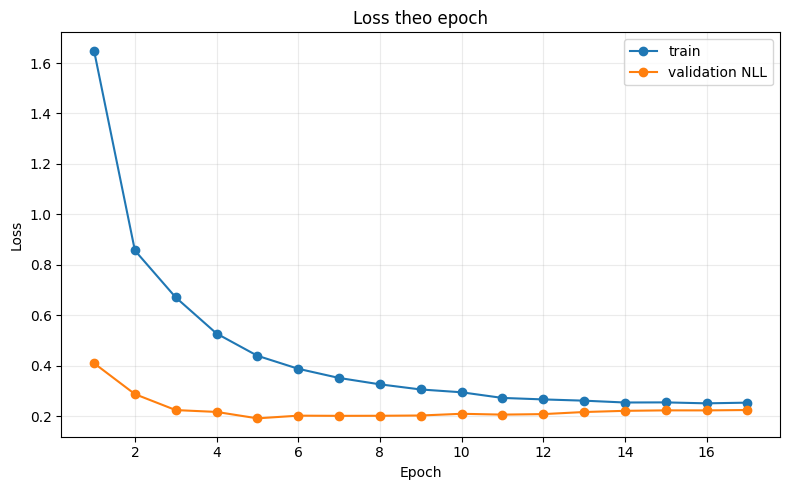

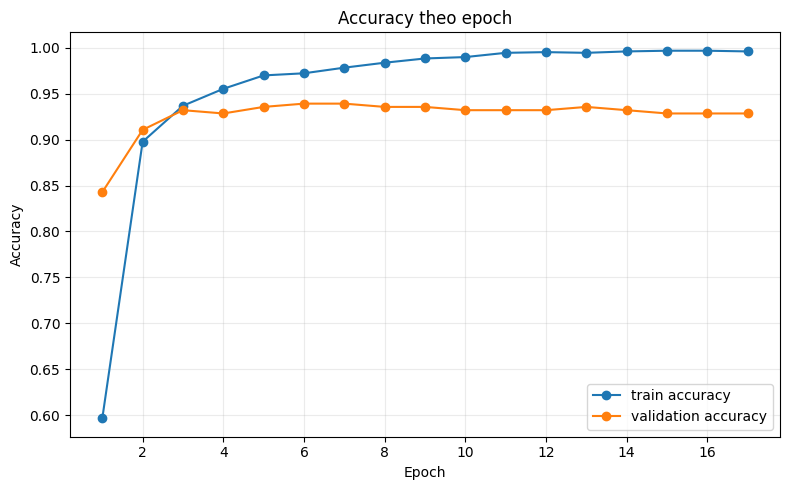

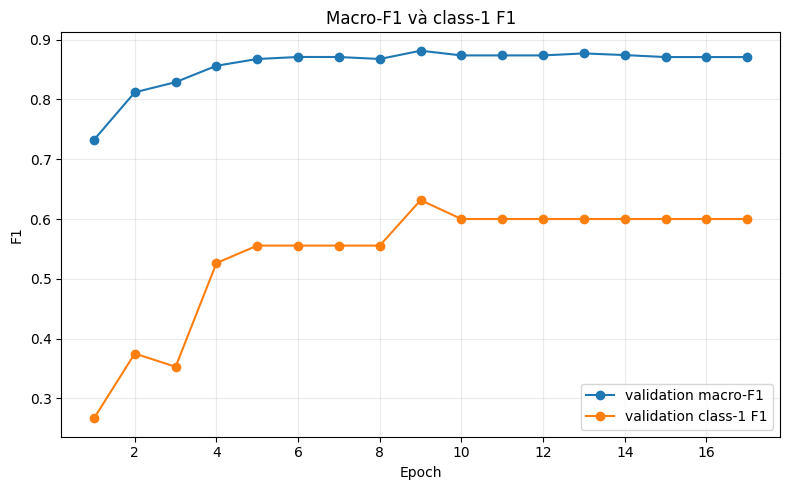

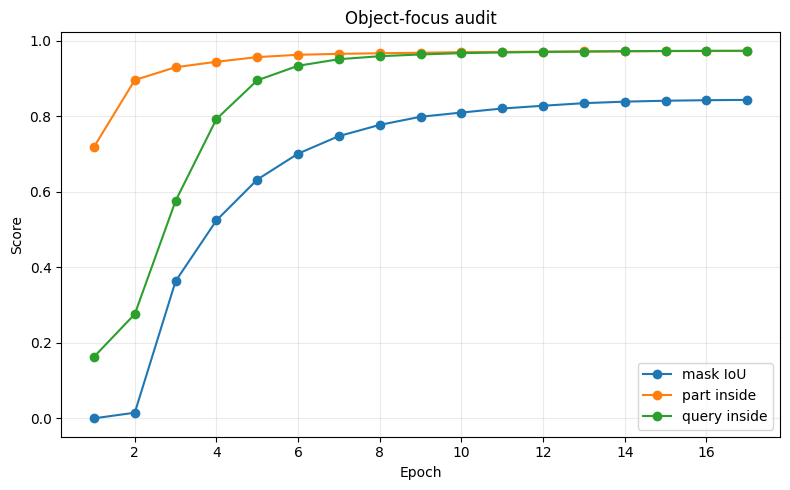

Locked snapshot: ep_9 epochs (9,) actual calibration epochs 17


In [26]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # CALIBRATION — 7-EPOCH MINIMUM + 3-EPOCH RESERVE
    # ============================================================
    with timed_stage('04_calibration_training'):
        model.rare_mil_enabled = False
        obj = Objective(
            CLASS_WEIGHTS, PAIR_WEIGHTS, enable_rare=False
        )
        train_model = wrap_train(model)
        opt = optimizer_for(train_model)
        steps = (
            math.ceil(len(train_loader) / GRAD_ACCUM)
            * CFG.calibration_epochs
        )
        sched = scheduler_for(opt, steps)
        scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
        ema = DeltaEMA(train_model)
        history = []
        snapshot_paths = {}
        snapshot_memory = {}

        # Complete objective, DeltaEMA and XAI-gradient preflight.
        py_state = random.getstate()
        np_state = np.random.get_state()
        cpu_state = torch.get_rng_state()
        cuda_states = (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
        )
        try:
            raw = next(iter(val_loader))
            raw = {
                key: (
                    value[:min(4, len(value))]
                    if (
                        torch.is_tensor(value)
                        or isinstance(value, (list, tuple))
                    )
                    else value
                )
                for key, value in raw.items()
            }
            batch = move(raw)
            train_model.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                output = train_model(
                    batch['pixel_values'],
                    batch['colour_stats'],
                    batch['patch_local_stats'],
                    batch['patch_mask'],
                    batch['mask_confidence'],
                    CFG.teacher_prior_mix_train,
                )
                legacy_virtual_loss, legacy_virtual_parts = (
                    v182_virtual_microbatch_objective(
                        obj,
                        output,
                        batch,
                        V182_VIRTUAL_MICRO_BATCH,
                    )
                )
                sanity_loss, sanity_parts = v184_virtual_objective(
                    obj,
                    output,
                    batch,
                    V182_VIRTUAL_MICRO_BATCH,
                )

            if not torch.allclose(
                sanity_loss,
                legacy_virtual_loss,
                atol=2e-5,
                rtol=2e-5,
            ):
                raise RuntimeError(
                    "Vectorized virtual objective mismatch: "
                    f"legacy={float(legacy_virtual_loss):.8f}, "
                    f"vectorized={float(sanity_loss):.8f}"
                )
            for component_name in sanity_parts:
                if not torch.allclose(
                    sanity_parts[component_name],
                    legacy_virtual_parts[component_name],
                    atol=2e-5,
                    rtol=2e-5,
                ):
                    raise RuntimeError(
                        "Vectorized component mismatch: "
                        + component_name
                    )

            if not torch.isfinite(sanity_loss):
                raise RuntimeError(
                    f"AMP objective returned non-finite loss: "
                    f"{sanity_loss}"
                )
            sanity_loss.backward()

            gradients = [
                parameter.grad
                for parameter in unwrap(
                    train_model
                ).parameters()
                if (
                    parameter.requires_grad
                    and parameter.grad is not None
                )
            ]
            if (
                not gradients
                or not all(
                    torch.isfinite(gradient).all()
                    for gradient in gradients
                )
            ):
                raise RuntimeError(
                    "AMP objective backward produced "
                    "missing/non-finite gradients."
                )

            ema_probe = ema.export_delta(train_model)
            if not ema_probe:
                raise RuntimeError("DeltaEMA export is empty.")

            # Frozen-backbone XAI requires an input gradient.
            xai_input = (
                batch['pixel_values'][:1]
                .detach().clone()
                .requires_grad_(True)
            )
            unwrap(train_model).zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                xai_output = unwrap(train_model)(
                    xai_input,
                    batch['colour_stats'][:1],
                    batch['patch_local_stats'][:1],
                    batch['patch_mask'][:1],
                    batch['mask_confidence'][:1],
                    CFG.teacher_prior_mix_train,
                    collect_attention=True,
                )
            xai_output['main_logits'][0, 0].backward()

            if xai_output['patch_tokens'].grad is None:
                raise RuntimeError(
                    "XAI patch-token gradient is None."
                )
            if not torch.isfinite(
                xai_output['patch_tokens'].grad
            ).all():
                raise RuntimeError(
                    "XAI patch-token gradient is non-finite."
                )

            print(
                "✅ AMP objective, DeltaEMA and XAI-gradient "
                f"preflight passed: "
                f"loss={float(sanity_loss.detach()):.6f}, "
                f"components={len(sanity_parts)}"
            )
        finally:
            train_model.zero_grad(set_to_none=True)
            random.setstate(py_state)
            np.random.set_state(np_state)
            torch.set_rng_state(cpu_state)
            if cuda_states is not None:
                torch.cuda.set_rng_state_all(cuda_states)
            for name in (
                "raw", "batch", "output", "sanity_loss",
                "sanity_parts", "gradients", "ema_probe",
                "xai_input", "xai_output",
            ):
                globals().pop(name, None)
            gc.collect()
            torch.cuda.empty_cache()

        calibration_trainable = sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        )
        calibration_total = sum(
            p.numel() for p in model.parameters()
        )
        print(
            f"Calibration trainable="
            f"{calibration_trainable:,}/"
            f"{calibration_total:,}"
        )

        best_guard = (-1.0, -1.0, -1.0, -1e9)
        wait = 0

        for epoch in range(1, CFG.calibration_epochs + 1):
            train_metrics = train_epoch(
                train_model,
                train_loader,
                obj,
                opt,
                sched,
                scaler,
                ema,
                f"calibration {epoch}/"
                f"{CFG.calibration_epochs}",
            )

            with ema.applied(train_model) as ema_model:
                validation_cache = collect_cache(
                    ema_model, val_loader, 0.0, "val"
                )

            labels = validation_cache[
                'rows'
            ].label.to_numpy()
            validation_metrics = metric_bundle(
                labels, validation_cache['main']
            )
            predicted_mask = (
                validation_cache['predicted_mask'] >= .5
            )
            teacher_mask = validation_cache[
                'teacher_mask'
            ]
            valid = (
                validation_cache['rows']
                .mask_confidence.to_numpy()
                >= CFG.mask_supervision_min_confidence
            )
            intersection = (
                predicted_mask[valid]
                & (teacher_mask[valid] >= .5)
            ).sum()
            union = (
                predicted_mask[valid]
                | (teacher_mask[valid] >= .5)
            ).sum()
            part_inside = (
                validation_cache['part_weights'][valid]
                * teacher_mask[valid]
            ).sum(1).mean()
            query_inside = (
                validation_cache['query_attention'][valid]
                * teacher_mask[valid]
            ).sum(1).mean()

            row = {
                'phase': 'calibration',
                'epoch': epoch,
                **{
                    f'train_{key}': value
                    for key, value
                    in train_metrics.items()
                    if np.isscalar(value)
                },
                **{
                    f'val_{key}': value
                    for key, value
                    in validation_metrics.items()
                    if np.isscalar(value)
                },
                'val_mask_iou':
                    intersection / max(union, 1),
                'val_part_inside': part_inside,
                'val_query_inside': query_inside,
                'lr': opt.param_groups[0]['lr'],
            }
            history.append(row)

            snapshot_path = TEMP_DIR / f"calibration_ep{epoch}.pt"
            snapshot_delta = ema.export_delta(train_model)
            snapshot_payload = {
                "delta": snapshot_delta,
                "meta_json": json.dumps(
                    {
                        "epoch": epoch,
                        "split_sha256": SPLIT_REGISTRY_SHA256,
                    }
                ),
            }
            snapshot_result = v184_try_compact_torch_save(
                snapshot_payload,
                snapshot_path,
                stage=f"calibration_snapshot_epoch_{epoch}",
            )
            if snapshot_result is not None:
                snapshot_paths[epoch] = snapshot_result
            else:
                # Keep a bounded rolling fallback sized to the configured patience.
                snapshot_memory[epoch] = snapshot_delta
                best_memory_epoch = int(
                    max(
                        history,
                        key=lambda item: (
                            item["val_macro_f1"],
                            item["val_class1_f1"],
                            item["val_min_class_f1"],
                            -item["val_mae"],
                        ),
                    )["epoch"]
                )
                keep_memory_epochs = set(
                    sorted(snapshot_memory)[-(CFG.calibration_patience + 1):]
                ) | {best_memory_epoch}
                for old_epoch in list(snapshot_memory):
                    if old_epoch not in keep_memory_epochs:
                        snapshot_memory.pop(old_epoch, None)
            del snapshot_payload, snapshot_delta

            print(
                f"[{epoch:02d}/"
                f"{CFG.calibration_epochs}] "
                f"train loss="
                f"{train_metrics['loss']:.4f} "
                f"acc={train_metrics['accuracy']:.4f} | "
                f"val loss="
                f"{validation_metrics['nll']:.4f} "
                f"acc="
                f"{validation_metrics['accuracy']:.4f} "
                f"macro="
                f"{validation_metrics['macro_f1']:.4f} "
                f"c1="
                f"{validation_metrics['class1_f1']:.3f} "
                f"mask={row['val_mask_iou']:.3f} "
                f"part={part_inside:.3f} "
                f"query={query_inside:.3f}"
            )

            guard = (
                validation_metrics['macro_f1'],
                validation_metrics['class1_f1'],
                validation_metrics['min_class_f1'],
                -validation_metrics['mae'],
            )
            improved = guard > best_guard
            if improveE:
                best_guard = guard
                wait = 0
            else:
                wait += 1

            if V184_SAVE_CHECKPOINTS:
                if improveE:
                    try:
                        calibration_best_payload = {
                            "version": V184_VERSION,
                            "stage": "calibration_best",
                            "epoch": int(epoch),
                            "fingerprint": v184_training_fingerprint(
                                "calibration"
                            ),
                            "delta": v184_cpu_tree(
                                ema.export_delta(train_model)
                            ),
                            "metrics": row,
                        }
                        v184_try_compact_torch_save(
                            calibration_best_payload,
                            V184_CHECKPOINT_ROOT
                            / "calibration_best_delta.pt",
                            stage=f"calibration_best_epoch_{epoch}",
                        )
                    except (MemoryError, RuntimeError, OSError) as error:
                        V184_CHECKPOINT_FAILURES.append(
                            {
                                "stage": f"calibration_best_epoch_{epoch}",
                                "target": str(
                                    V184_CHECKPOINT_ROOT
                                    / "calibration_best_delta.pt"
                                ),
                                "error": f"{type(error).__name__}: {error}",
                                "available_ram_gib": _v1841_available_ram_gib(),
                            }
                        )
                        warnings.warn(
                            "Best-checkpoint copy failed softly; the required "
                            "calibration snapshot remains on disk/in memory. "
                            + str(error)
                        )
                    finally:
                        if "calibration_best_payload" in locals():
                            calibration_best_payload.clear()
                        gc.collect()
                if epoch % V184_CHECKPOINT_INTERVAL == 0:
                    v184_save_training_state(
                        "calibration",
                        epoch,
                        train_model,
                        opt,
                        sched,
                        scaler,
                        ema,
                        history,
                        {
                            "best_guard": list(best_guard),
                            "wait": int(wait),
                        },
                    )

            if (
                epoch >= CFG.calibration_min_epochs
                and wait >= CFG.calibration_patience
            ):
                print(
                    f"Early stop after {epoch} epochs; "
                    f"{CFG.calibration_patience} "
                    "reserve epochs produced no improvement."
                )
                break

        calibration_history = pd.DataFrame(history)
        calibration_history.to_csv(
            OUTPUT_DIR
            / 'calibration_training_history.csv',
            index=False,
        )

        best_epoch = int(
            select_row(pd.DataFrame([
                {
                    'epoch': row['epoch'],
                    'macro_f1':
                        row['val_macro_f1'],
                    'class1_f1':
                        row['val_class1_f1'],
                    'min_class_f1':
                        row['val_min_class_f1'],
                    'mae': row['val_mae'],
                    'complexity': 0,
                }
                for row in history
            ])).epoch
        )

        candidate_sets = []
        for sequence in (
            [best_epoch],
            [best_epoch - 1, best_epoch],
            [
                best_epoch - 1,
                best_epoch,
                best_epoch + 1,
            ],
        ):
            epoch_set = tuple(sorted({
                epoch
                for epoch in sequence
                if epoch in snapshot_paths or epoch in snapshot_memory
            }))
            if (
                epoch_set
                and epoch_set not in candidate_sets
            ):
                candidate_sets.append(epoch_set)

        soup_rows = []
        soup_states = {}
        for epoch_set in candidate_sets:
            states = [
                (
                    read_delta(snapshot_paths[epoch])[0]
                    if epoch in snapshot_paths
                    else snapshot_memory[epoch]
                )
                for epoch in epoch_set
            ]
            state = average_states(states)
            load_delta(model, state)
            cache = collect_cache(
                model,
                val_loader,
                0.0,
                f"val soup {epoch_set}",
            )
            metrics = metric_bundle(
                cache['rows'].label.to_numpy(),
                cache['main'],
            )
            name = (
                "ep_"
                + "_".join(map(str, epoch_set))
            )
            soup_states[name] = state
            soup_rows.append({
                'candidate': name,
                'epochs':
                    ','.join(map(str, epoch_set)),
                'complexity': len(epoch_set) - 1,
                **{
                    key: value
                    for key, value in metrics.items()
                    if np.isscalar(value)
                },
            })

        snapshot_selection_df = pd.DataFrame(
            soup_rows
        )
        selected_snapshot = select_row(
            snapshot_selection_df
        )
        selected_snapshot_name = str(
            selected_snapshot.candidate
        )
        selected_epoch_set = tuple(
            map(
                int,
                str(
                    selected_snapshot.epochs
                ).split(','),
            )
        )
        selected_calibration_state = (
            soup_states[selected_snapshot_name]
        )
        load_delta(
            model, selected_calibration_state
        )
        if V184_SAVE_CHECKPOINTS:
            try:
                selected_calibration_payload = {
                    "version": V184_VERSION,
                    "stage": "selected_calibration",
                    "fingerprint": v184_training_fingerprint(
                        "calibration"
                    ),
                    "snapshot": selected_snapshot_name,
                    "snapshot_epochs": list(selected_epoch_set),
                    "delta": selected_calibration_state,
                }
                v184_try_compact_torch_save(
                    selected_calibration_payload,
                    V184_CHECKPOINT_ROOT
                    / "selected_calibration_delta.pt",
                    stage="selected_calibration",
                )
            except (MemoryError, RuntimeError, OSError) as error:
                V184_CHECKPOINT_FAILURES.append(
                    {
                        "stage": "selected_calibration",
                        "target": str(
                            V184_CHECKPOINT_ROOT
                            / "selected_calibration_delta.pt"
                        ),
                        "error": f"{type(error).__name__}: {error}",
                        "available_ram_gib": _v1841_available_ram_gib(),
                    }
                )
                warnings.warn(
                    "Selected-calibration checkpoint failed softly; the "
                    "in-memory selected state remains authoritative. "
                    + str(error)
                )
            finally:
                if "selected_calibration_payload" in locals():
                    selected_calibration_payload.clear()
                gc.collect()
        snapshot_selection_df['selected'] = (
            snapshot_selection_df.candidate
            == selected_snapshot_name
        )
        snapshot_selection_df.to_csv(
            OUTPUT_DIR
            / 'validation_snapshot_soups.csv',
            index=False,
        )
        display(snapshot_selection_df)

    def save_curve(
        x, series, title, ylabel, name
    ):
        fig, axis = plt.subplots(figsize=(8, 5))
        for label, values in series:
            axis.plot(
                x, values, marker='o', label=label
            )
        axis.set_title(title)
        axis.set_xlabel('Epoch')
        axis.set_ylabel(ylabel)
        axis.grid(alpha=.25)
        axis.legend()
        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / name,
            dpi=150,
            bbox_inches='tight',
        )
        plt.show()
        plt.close(fig)

    epochs = calibration_history.epoch
    save_curve(
        epochs,
        [
            ('train', calibration_history.train_loss),
            (
                'validation NLL',
                calibration_history.val_nll,
            ),
        ],
        'Loss theo epoch',
        'Loss',
        'curve_loss.png',
    )
    save_curve(
        epochs,
        [
            (
                'train accuracy',
                calibration_history.train_accuracy,
            ),
            (
                'validation accuracy',
                calibration_history.val_accuracy,
            ),
        ],
        'Accuracy theo epoch',
        'Accuracy',
        'curve_accuracy.png',
    )
    save_curve(
        epochs,
        [
            (
                'validation macro-F1',
                calibration_history.val_macro_f1,
            ),
            (
                'validation class-1 F1',
                calibration_history.val_class1_f1,
            ),
        ],
        'Macro-F1 và class-1 F1',
        'F1',
        'curve_f1.png',
    )
    save_curve(
        epochs,
        [
            (
                'mask IoU',
                calibration_history.val_mask_iou,
            ),
            (
                'part inside',
                calibration_history.val_part_inside,
            ),
            (
                'query inside',
                calibration_history.val_query_inside,
            ),
        ],
        'Object-focus audit',
        'Score',
        'curve_focus.png',
    )
    print(
        'Locked snapshot:',
        selected_snapshot_name,
        'epochs',
        selected_epoch_set,
        'actual calibration epochs',
        len(snapshot_paths),
    )

    CALIBRATION_EPOCHS_EXECUTED = int(len(snapshot_paths))
    # Selected state is already held in selected_calibration_state and written
    # to the persistent checkpoint. Release everything else before optional
    # validation audits; these objects are not part of inference.
    for _v1841_name in (
        "train_model", "ema", "obj", "opt", "sched", "scaler",
        "validation_cache", "cache", "states", "state", "soup_states",
        "candidate_sets", "soup_rows",
    ):
        globals().pop(_v1841_name, None)
    for _v1841_path in snapshot_paths.values():
        try:
            Path(_v1841_path).unlink(missing_ok=True)
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if "_v1841_trim_working_set" in globals():
        _v1841_trim_working_set()
else:
    print('Skip mango-specific cell for generic profile.')


In [27]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # VALIDATION-LOCKED PRIOR / HEAD BLEND / PAIR CORRECTION / TEMPERATURE
    # ============================================================
    with timed_stage('05_validation_selection'):
        val_caches={p:collect_cache(model,val_loader,p,f'validation prior={p}') for p in CFG.prior_mix_candidates};rows=[];candidate_probs={}
        for prior,c in val_caches.items():
            y=c['rows'].label.to_numpy()
            for mode in CFG.probability_blend_modes:
                base=blend_heads(c,mode)
                for a01 in CFG.pair_alpha01:
                    for a12 in CFG.pair_alpha12:
                        for a23 in CFG.pair_alpha23:
                            p=apply_pair_refinement(base,c['pairs'],a01,a12,a23);met=metric_bundle(y,p);name=f'p{prior}_{mode}_{a01}_{a12}_{a23}';candidate_probs[name]=p;rows.append({'name':name,'prior_mix':prior,'blend_mode':mode,'alpha01':a01,'alpha12':a12,'alpha23':a23,'complexity':(prior>0)+sum(x>0 for x in(a01,a12,a23))+(mode!='main'),**{k:v for k,v in met.items() if np.isscalar(v)}})
        inference_grid_df=pd.DataFrame(rows);selected=select_row(inference_grid_df);selected_name=str(selected['name']);base_reference=val_caches[0.]['main'];selected_probs=candidate_probs[selected_name];y=val_caches[float(selected.prior_mix)]['rows'].label.to_numpy()
        rng=np.random.default_rng(CFG.seed+717);boot=[]
        class_ids=[np.where(y==c)[0] for c in range(5)]
        for _ in range(CFG.bootstrap_replicates):
            idx=np.concatenate([rng.choice(z,len(z),replace=True) for z in class_ids]);boot.append((f1_score(y[idx],selected_probs[idx].argmax(1),average='macro',zero_division=0)-f1_score(y[idx],base_reference[idx].argmax(1),average='macro',zero_division=0),f1_score(y[idx],selected_probs[idx].argmax(1),average=None,labels=np.arange(5),zero_division=0)[1]-f1_score(y[idx],base_reference[idx].argmax(1),average=None,labels=np.arange(5),zero_division=0)[1]))
        boot=np.asarray(boot);bootstrap_ok=boot[:,0].mean()>=-5e-4 and boot[:,1].mean()>=-5e-3
        if not bootstrap_ok:selected=inference_grid_df[inference_grid_df.name=='p0.0_main_0.0_0.0_0.0'].iloc[0];selected_name=str(selected['name']);selected_probs=base_reference
        # Temperature is selected by NLL only; labels are already locked.
        best_t=min(CFG.temperatures,key=lambda t:log_loss(y,np.clip(selected_probs**(1/t)/np.sum(selected_probs**(1/t),1,keepdims=True),1e-7,1),labels=np.arange(5)))
        locked_inference={k:(v.item() if isinstance(v,np.generic) else v) for k,v in selected.to_dict().items()};locked_inference['temperature']=float(best_t);locked_inference['bootstrap_macro_mean']=float(boot[:,0].mean());locked_inference['bootstrap_class1_mean']=float(boot[:,1].mean());locked_inference['bootstrap_guard_passed']=bool(bootstrap_ok);locked_inference['snapshot']=selected_snapshot_name;locked_inference['snapshot_epochs']=list(selected_epoch_set)
        inference_grid_df['selected']=inference_grid_df.name==selected_name;inference_grid_df.to_csv(OUTPUT_DIR/'validation_inference_grid.csv',index=False);json.dump(locked_inference,open(OUTPUT_DIR/'locked_validation_selection.json','w'),indent=2);display(inference_grid_df.sort_values(['selected','macro_f1','class1_f1'],ascending=[False,False,False]).head(20));print(json.dumps(locked_inference,indent=2))

else:
    print('Skip mango-specific cell for generic profile.')


validation prior=0.0:   0%|                                                                      | 0/9 [00:00<?, ?it/s]

validation prior=0.0:  11%|██████▉                                                       | 1/9 [00:01<00:10,  1.32s/it]

validation prior=0.0:  22%|█████████████▊                                                | 2/9 [00:02<00:08,  1.17s/it]

validation prior=0.0:  33%|████████████████████▋                                         | 3/9 [00:03<00:06,  1.12s/it]

validation prior=0.0:  44%|███████████████████████████▌                                  | 4/9 [00:04<00:05,  1.08s/it]

validation prior=0.0:  56%|██████████████████████████████████▍                           | 5/9 [00:05<00:04,  1.08s/it]

validation prior=0.0:  67%|█████████████████████████████████████████▎                    | 6/9 [00:06<00:03,  1.08s/it]

validation prior=0.0:  78%|████████████████████████████████████████████████▏             | 7/9 [00:07<00:02,  1.08s/it]

validation prior=0.0:  89%|███████████████████████████████████████████████████████       | 8/9 [00:08<00:01,  1.07s/it]

validation prior=0.0: 100%|██████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.02it/s]

validation prior=0.55:   0%|                                                                     | 0/9 [00:00<?, ?it/s]

validation prior=0.55:  11%|██████▊                                                      | 1/9 [00:01<00:08,  1.06s/it]

validation prior=0.55:  22%|█████████████▌                                               | 2/9 [00:02<00:07,  1.06s/it]

validation prior=0.55:  33%|████████████████████▎                                        | 3/9 [00:03<00:06,  1.06s/it]

validation prior=0.55:  44%|███████████████████████████                                  | 4/9 [00:04<00:05,  1.06s/it]

validation prior=0.55:  56%|█████████████████████████████████▉                           | 5/9 [00:05<00:04,  1.06s/it]

validation prior=0.55:  67%|████████████████████████████████████████▋                    | 6/9 [00:06<00:03,  1.07s/it]

validation prior=0.55:  78%|███████████████████████████████████████████████▍             | 7/9 [00:07<00:02,  1.06s/it]

validation prior=0.55:  89%|██████████████████████████████████████████████████████▏      | 8/9 [00:08<00:01,  1.07s/it]

validation prior=0.55: 100%|█████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.02it/s]

,name,prior_mix,blend_mode,alpha01,alpha12,alpha23,complexity,accuracy,balanced_accuracy,macro_f1,...,class1_recall,class1_f1,class4_precision,class4_recall,class4_f1,min_class_f1,mae,nll,ece,selected
0,p0.0_main_0.0_0.0_0.0,0.0,main,0.0,0.00,0.0,0,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.202681,0.028236,True
1,p0.0_main_0.0_0.0_0.2,0.0,main,0.0,0.00,0.2,1,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.197574,0.035041,False
2,p0.0_main_0.0_0.0_0.4,0.0,main,0.0,0.00,0.4,1,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.195514,0.024696,False
3,p0.0_main_0.0_0.15_0.0,0.0,main,0.0,0.15,0.0,1,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200033,0.027645,False
4,p0.0_main_0.0_0.15_0.2,0.0,main,0.0,0.15,0.2,2,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.194925,0.030495,False
5,p0.0_main_0.0_0.15_0.4,0.0,main,0.0,0.15,0.4,2,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.192866,0.021128,False
18,p0.0_main_object_0.0_0.0_0.0,0.0,main_object,0.0,0.00,0.0,1,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.193821,0.037345,False
19,p0.0_main_object_0.0_0.0_0.2,0.0,main_object,0.0,0.00,0.2,2,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.191102,0.026935,False
20,p0.0_main_object_0.0_0.0_0.4,0.0,main_object,0.0,0.00,0.4,2,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.190017,0.028816,False
21,p0.0_main_object_0.0_0.15_0.0,0.0,main_object,0.0,0.15,0.0,2,0.935714,0.856085,0.881433,...,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.192502,0.042438,False


{
  "name": "p0.0_main_0.0_0.0_0.0",
  "prior_mix": 0.0,
  "blend_mode": "main",
  "alpha01": 0.0,
  "alpha12": 0.0,
  "alpha23": 0.0,
  "complexity": 0,
  "accuracy": 0.9357142857142857,
  "balanced_accuracy": 0.8560850178014358,
  "macro_f1": 0.8814326513209394,
  "weighted_f1": 0.9320482487957532,
  "class1_precision": 1.0,
  "class1_recall": 0.46153846153846156,
  "class1_f1": 0.631578947368421,
  "class4_precision": 0.9873417721518988,
  "class4_recall": 0.975,
  "class4_f1": 0.9811320754716981,
  "min_class_f1": 0.631578947368421,
  "mae": 0.08928571428571429,
  "nll": 0.2026809522523486,
  "ece": 0.028235599276005087,
  "temperature": 1.1,
  "bootstrap_macro_mean": 0.0,
  "bootstrap_class1_mean": 0.0,
  "bootstrap_guard_passed": true,
  "snapshot": "ep_9",
  "snapshot_epochs": [
    9
  ]
}
⏱ 05_validation_selection: 0.36 min cumulative


In [28]:

if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.3 VALIDATION-GATED CLASS-1 BOUNDARY CALIBRATION
    # ============================================================
    with timed_stage("05aa_class1_boundary_bias"):
        selected_cache = val_caches[
            float(locked_inference["prior_mix"])
        ]
        labels = selected_cache["rows"].label.to_numpy()
        base_probabilities = compose_locked(
            selected_cache,
            locked_inference,
        )
        base_metrics = metric_bundle(
            labels,
            base_probabilities,
        )
        base_predictions = base_probabilities.argmax(1)

        rows = []
        probabilities_by_name = {}
        bias01_values = (
            (0.0, 0.10, 0.20, 0.30, 0.40)
            if V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION
            else (0.0,)
        )
        bias12_values = (
            (0.0, 0.10, 0.20, 0.30)
            if V183_ENABLE_CLASS1_BOUNDARY_CALIBRATION
            else (0.0,)
        )

        for bias01 in bias01_values:
            for bias12 in bias12_values:
                for maximum_margin in (
                    0.15, 0.25, 0.35
                ):
                    probability = (
                        apply_class1_boundary_bias(
                            base_probabilities,
                            bias01,
                            bias12,
                            maximum_margin,
                        )
                    )
                    metrics = metric_bundle(
                        labels, probability
                    )
                    name = (
                        f"b01_{bias01:.2f}_"
                        f"b12_{bias12:.2f}_"
                        f"m_{maximum_margin:.2f}"
                    )
                    probabilities_by_name[
                        name
                    ] = probability
                    rows.append(
                        {
                            "name": name,
                            "bias01": bias01,
                            "bias12": bias12,
                            "maximum_margin":
                                maximum_margin,
                            "changed":
                                int(
                                    (
                                        probability.argmax(1)
                                        != base_predictions
                                    ).sum()
                                ),
                            **{
                                key: value
                                for key, value
                                in metrics.items()
                                if np.isscalar(value)
                            },
                        }
                    )

        grid = pd.DataFrame(rows)
        plausible = grid[
            (grid.macro_f1
             >= base_metrics["macro_f1"] - 0.002)
            & (grid.class1_f1
               >= base_metrics["class1_f1"])
            & (grid.class1_recall
               >= base_metrics["class1_recall"])
            & (grid.changed <= 8)
        ].copy()

        bootstrap = []
        class_rows = [
            np.where(labels == class_index)[0]
            for class_index in range(5)
        ]
        for _, candidate in plausible.iterrows():
            probability = probabilities_by_name[
                candidate["name"]
            ]
            rng = np.random.default_rng(
                CFG.seed
                + int(candidate.bias01 * 1000)
                + int(candidate.bias12 * 10000)
                + int(
                    candidate.maximum_margin * 100000
                )
            )
            macro_delta = []
            class1_delta = []
            for _ in range(300):
                sampled = np.concatenate(
                    [
                        rng.choice(
                            indices,
                            len(indices),
                            replace=True,
                        )
                        for indices in class_rows
                    ]
                )
                before = metric_bundle(
                    labels[sampled],
                    base_probabilities[sampled],
                )
                after = metric_bundle(
                    labels[sampled],
                    probability[sampled],
                )
                macro_delta.append(
                    after["macro_f1"]
                    - before["macro_f1"]
                )
                class1_delta.append(
                    after["class1_f1"]
                    - before["class1_f1"]
                )
            bootstrap.append(
                {
                    "name": candidate["name"],
                    "bootstrap_macro_mean":
                        float(np.mean(macro_delta)),
                    "bootstrap_class1_mean":
                        float(np.mean(class1_delta)),
                }
            )

        if bootstrap:
            grid = grid.merge(
                pd.DataFrame(bootstrap),
                on="name",
                how="left",
            )
        else:
            grid["bootstrap_macro_mean"] = np.nan
            grid["bootstrap_class1_mean"] = np.nan

        eligible = grid[
            (grid.macro_f1
             >= base_metrics["macro_f1"] - 0.001)
            & (grid.class1_f1
               >= base_metrics["class1_f1"])
            & (grid.class1_recall
               >= base_metrics["class1_recall"])
            & (grid.changed <= 8)
            & (
                grid.bootstrap_macro_mean.fillna(-1)
                >= -0.0005
            )
            & (
                grid.bootstrap_class1_mean.fillna(-1)
                >= -0.0005
            )
        ].copy()

        identity_name = (
            "b01_0.00_b12_0.00_m_0.15"
        )
        identity = grid[
            grid.name.eq(identity_name)
        ]
        if identity_name not in set(eligible.name):
            eligible = pd.concat(
                [eligible, identity],
                ignore_index=True,
            )

        eligible["complexity"] = (
            eligible.bias01.abs()
            + eligible.bias12.abs()
            + 0.001 * eligible.changed
        )
        chosen = eligible.sort_values(
            [
                "macro_f1",
                "class1_f1",
                "class1_recall",
                "min_class_f1",
                "mae",
                "complexity",
            ],
            ascending=[
                False, False, False,
                False, True, True,
            ],
        ).iloc[0]

        locked_inference[
            "class1_bias_01"
        ] = float(chosen.bias01)
        locked_inference[
            "class1_bias_12"
        ] = float(chosen.bias12)
        locked_inference[
            "class1_bias_max_margin"
        ] = float(chosen.maximum_margin)
        locked_inference[
            "class1_boundary_changed_validation"
        ] = int(chosen.changed)
        for metric_name in (
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "weighted_f1",
            "class1_precision",
            "class1_recall",
            "class1_f1",
            "class4_precision",
            "class4_recall",
            "class4_f1",
            "min_class_f1",
            "mae",
            "nll",
            "ece",
        ):
            if metric_name in chosen.index:
                locked_inference[metric_name] = float(
                    chosen[metric_name]
                )

        # Downstream legacy/evidence receipts must use exactly the
        # newly locked probabilities rather than the pre-bias cache.
        selected_probs = compose_locked(
            selected_cache,
            locked_inference,
        )

        grid["selected"] = grid.name.eq(
            chosen["name"]
        )
        grid.to_csv(
            OUTPUT_DIR
            / "validation_class1_boundary_bias.csv",
            index=False,
        )
        json.dump(
            locked_inference,
            open(
                OUTPUT_DIR
                / "locked_validation_selection.json",
                "w",
            ),
            indent=2,
        )
        display(
            grid.sort_values(
                ["selected", "macro_f1", "class1_f1"],
                ascending=[False, False, False],
            ).head(20)
        )
        print(
            "V18.3 class-1 boundary lock:",
            {
                "bias01":
                    locked_inference[
                        "class1_bias_01"
                    ],
                "bias12":
                    locked_inference[
                        "class1_bias_12"
                    ],
                "maximum_margin":
                    locked_inference[
                        "class1_bias_max_margin"
                    ],
                "changed":
                    locked_inference[
                        "class1_boundary_changed_validation"
                    ],
            },
        )
else:
    print("Skip mango-specific boundary calibration.")


,name,bias01,bias12,maximum_margin,changed,accuracy,balanced_accuracy,macro_f1,weighted_f1,class1_precision,...,class4_precision,class4_recall,class4_f1,min_class_f1,mae,nll,ece,bootstrap_macro_mean,bootstrap_class1_mean,selected
0,b01_0.00_b12_0.00_m_0.15,0.0,0.0,0.15,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,True
1,b01_0.00_b12_0.00_m_0.25,0.0,0.0,0.25,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
2,b01_0.00_b12_0.00_m_0.35,0.0,0.0,0.35,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
3,b01_0.00_b12_0.10_m_0.15,0.0,0.1,0.15,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
4,b01_0.00_b12_0.10_m_0.25,0.0,0.1,0.25,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
5,b01_0.00_b12_0.10_m_0.35,0.0,0.1,0.35,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200152,0.026119,0.0,0.0,False
6,b01_0.00_b12_0.20_m_0.15,0.0,0.2,0.15,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
7,b01_0.00_b12_0.20_m_0.25,0.0,0.2,0.25,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False
8,b01_0.00_b12_0.20_m_0.35,0.0,0.2,0.35,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200287,0.026203,0.0,0.0,False
9,b01_0.00_b12_0.30_m_0.15,0.0,0.3,0.15,0,0.935714,0.856085,0.881433,0.932048,1.0,...,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038,0.0,0.0,False


V18.3 class-1 boundary lock: {'bias01': 0.0, 'bias12': 0.0, 'maximum_margin': 0.15, 'changed': 0}
⏱ 05aa_class1_boundary_bias: 1.68 min cumulative


## 5A. OOF frozen-embedding specialists for adjacent boundaries

In [29]:
if TASK_PROFILE == "mango_advanced":
    with timed_stage("05ab_oof_boundary_specialists"):
        V184_SPECIALIST_LOCK = {
            "enabled": False,
            "pairs": {},
            "validation_changed": 0,
            "fallback": "protected_visual",
        }
        V184_SPECIALIST_METHOD_SPECS = {}
        V184_CALIBRATION_SPECIALISTS = {}
        V184_SPECIALIST_OOF_ROWS = []
        V184_SPECIALIST_GRID_ROWS = []

        if V184_ENABLE_SPECIALISTS:
            train_specialist_cache = collect_cache(
                model,
                train_eval_loader,
                float(locked_inference["prior_mix"]),
                "specialist TRAIN features",
            )
            validation_specialist_cache = selected_cache
            train_features = v184_specialist_features(
                train_specialist_cache
            )
            validation_features = v184_specialist_features(
                validation_specialist_cache
            )
            train_labels = train_specialist_cache["rows"].label.to_numpy()
            validation_labels = validation_specialist_cache[
                "rows"
            ].label.to_numpy()

            for pair_index, (left, right) in enumerate(
                V184_ADJACENT_PAIRS
            ):
                key = f"{left}{right}"
                pair_rows = np.isin(train_labels, [left, right])
                binary_labels = (
                    train_labels[pair_rows] == right
                ).astype(np.int64)
                candidate_rows = []
                for method_index, method in enumerate(
                    V184_SPECIALIST_METHODS
                ):
                    try:
                        oof_probability = v184_oof_predictions(
                            method,
                            train_features[pair_rows],
                            binary_labels,
                            CFG.seed + 1000 * pair_index + method_index,
                        )
                        metrics = v184_pair_metrics(
                            binary_labels, oof_probability
                        )
                        candidate_rows.append(
                            {
                                "pair": key,
                                "method": method,
                                "status": "ok",
                                **metrics,
                            }
                        )
                    except Exception as error:
                        candidate_rows.append(
                            {
                                "pair": key,
                                "method": method,
                                "status": "failed",
                                "error": f"{type(error).__name__}: {error}",
                            }
                        )
                V184_SPECIALIST_OOF_ROWS.extend(candidate_rows)
                valid_methods = pd.DataFrame(candidate_rows)
                valid_methods = valid_methods[
                    valid_methods.status.eq("ok")
                ].copy()
                if valid_methods.empty:
                    continue
                chosen_method = valid_methods.sort_values(
                    ["pair_macro_f1", "pair_balanced_accuracy", "pair_nll", "method"],
                    ascending=[False, False, True, True],
                ).iloc[0]
                method = str(chosen_method.method)
                V184_SPECIALIST_METHOD_SPECS[key] = {
                    "method": method,
                    "oof_pair_macro_f1": float(
                        chosen_method.pair_macro_f1
                    ),
                    "oof_pair_nll": float(chosen_method.pair_nll),
                }
                V184_CALIBRATION_SPECIALISTS[key] = v184_fit_specialist(
                    method,
                    train_features[pair_rows],
                    binary_labels,
                    CFG.seed + 2000 + pair_index,
                )

            base_probability = compose_locked(
                validation_specialist_cache,
                locked_inference,
            )
            current_probability = base_probability.copy()
            current_metrics = metric_bundle(
                validation_labels, current_probability
            )
            selected_pair_rules = {}

            for left, right in V184_ADJACENT_PAIRS:
                key = f"{left}{right}"
                if key not in V184_CALIBRATION_SPECIALISTS:
                    selected_pair_rules[key] = {"alpha": 0.0}
                    continue
                base_boundary = v184_boundary_macro(
                    validation_labels, current_probability, (left, right)
                )
                pair_candidates = []
                for alpha in (0.0, 0.15, 0.30, 0.45, 0.60):
                    parameter_grid = (
                        [(0.25, 0.60)]
                        if alpha == 0
                        else [
                            (margin_max, confidence_min)
                            for margin_max in (0.15, 0.25, 0.35, 0.45)
                            for confidence_min in (0.55, 0.60, 0.65, 0.70)
                        ]
                    )
                    for margin_max, confidence_min in parameter_griE:
                        trial_lock = {
                            "enabled": True,
                            "pairs": {
                                key: {
                                    "alpha": alpha,
                                    "margin_max": margin_max,
                                    "confidence_min": confidence_min,
                                    "mass_min": 0.55,
                                    "rescue_class1_only": bool(
                                        V186_CLASS1_RESCUE_ONLY
                                        and key in {"01", "12"}
                                    ),
                                }
                            },
                        }
                        probability, audit = v184_apply_specialists(
                            current_probability,
                            validation_specialist_cache,
                            {key: V184_CALIBRATION_SPECIALISTS[key]},
                            trial_lock,
                            True,
                        )
                        metrics = metric_bundle(
                            validation_labels, probability
                        )
                        boundary_macro = v184_boundary_macro(
                            validation_labels, probability, (left, right)
                        )
                        changed = int(
                            (
                                probability.argmax(1)
                                != base_probability.argmax(1)
                            ).sum()
                        )
                        row = {
                            "pair": key,
                            "alpha": alpha,
                            "margin_max": margin_max,
                            "confidence_min": confidence_min,
                            "mass_min": 0.55,
                            "changed": changed,
                            "applied": int(
                                audit["specialist_applied"].sum()
                            ),
                            "boundary_macro_f1": boundary_macro,
                            "boundary_gain": boundary_macro - base_boundary,
                            **{
                                name: value
                                for name, value in metrics.items()
                                if np.isscalar(value)
                            },
                        }
                        pair_candidates.append(row)
                        V184_SPECIALIST_GRID_ROWS.append(row)

                candidate_frame = pd.DataFrame(pair_candidates)
                eligible = candidate_frame[
                    (
                        candidate_frame.macro_f1
                        >= current_metrics["macro_f1"] - 0.001
                    )
                    & (
                        candidate_frame.min_class_f1
                        >= current_metrics["min_class_f1"] - 0.005
                    )
                    & (candidate_frame.mae <= current_metrics["mae"] + 1 / 280)
                    & (candidate_frame.changed <= 8)
                    & (candidate_frame.boundary_macro_f1 >= base_boundary)
                ].copy()
                if 1 in (left, right):
                    eligible = eligible[
                        (
                            eligible.class1_f1
                            >= current_metrics["class1_f1"]
                        )
                        & (
                            eligible.class1_recall
                            >= current_metrics["class1_recall"]
                        )
                    ]
                identity = candidate_frame[
                    candidate_frame.alpha.eq(0.0)
                ].head(1)
                if eligible.empty:
                    eligible = identity.copy()
                eligible["complexity"] = (
                    eligible.alpha
                    + 0.01 * eligible.applied
                    + 0.001 * eligible.changed
                )
                chosen = eligible.sort_values(
                    [
                        "macro_f1",
                        "class1_f1",
                        "boundary_macro_f1",
                        "nll",
                        "complexity",
                    ],
                    ascending=[False, False, False, True, True],
                ).iloc[0]
                selected_pair_rules[key] = {
                    "alpha": float(chosen.alpha),
                    "margin_max": float(chosen.margin_max),
                    "confidence_min": float(chosen.confidence_min),
                    "mass_min": float(chosen.mass_min),
                    "method": V184_SPECIALIST_METHOD_SPECS[key]["method"],
                    "rescue_class1_only": bool(
                        V186_CLASS1_RESCUE_ONLY
                        and key in {"01", "12"}
                    ),
                }
                if float(chosen.alpha) > 0:
                    current_probability = v184_apply_specialists(
                        current_probability,
                        validation_specialist_cache,
                        {key: V184_CALIBRATION_SPECIALISTS[key]},
                        {
                            "enabled": True,
                            "pairs": {key: selected_pair_rules[key]},
                        },
                    )
                    current_metrics = metric_bundle(
                        validation_labels, current_probability
                    )

            combined_lock = {
                "enabled": any(
                    float(rule.get("alpha", 0.0)) > 0
                    for rule in selected_pair_rules.values()
                ),
                "pairs": selected_pair_rules,
                "fallback": "protected_visual",
            }
            combined_probability, combined_audit = v184_apply_specialists(
                base_probability,
                validation_specialist_cache,
                V184_CALIBRATION_SPECIALISTS,
                combined_lock,
                True,
            )
            combined_metrics = metric_bundle(
                validation_labels, combined_probability
            )

            # Stratified paired bootstrap. Identity remains the mandatory fallback.
            rng = np.random.default_rng(CFG.seed + 18400)
            class_rows = [
                np.where(validation_labels == class_index)[0]
                for class_index in range(5)
            ]
            macro_delta = []
            class1_delta = []
            for _ in range(500):
                sampled = np.concatenate(
                    [
                        rng.choice(rows, len(rows), replace=True)
                        for rows in class_rows
                    ]
                )
                before = metric_bundle(
                    validation_labels[sampled],
                    base_probability[sampled],
                )
                after = metric_bundle(
                    validation_labels[sampled],
                    combined_probability[sampled],
                )
                macro_delta.append(
                    after["macro_f1"] - before["macro_f1"]
                )
                class1_delta.append(
                    after["class1_f1"] - before["class1_f1"]
                )
            base_validation_metrics = metric_bundle(
                validation_labels, base_probability
            )
            bootstrap_passed = bool(
                np.mean(macro_delta) >= -0.0005
                and np.quantile(macro_delta, 0.05) >= -0.005
                and np.mean(class1_delta) >= -0.0005
                and np.quantile(class1_delta, 0.05) >= -0.025
                and combined_metrics["macro_f1"]
                >= base_validation_metrics["macro_f1"] - 0.001
                and combined_metrics["class1_f1"]
                >= base_validation_metrics["class1_f1"]
                and combined_metrics["class1_recall"]
                >= base_validation_metrics["class1_recall"]
                and combined_metrics["mae"]
                <= base_validation_metrics["mae"]
                + 1 / max(len(validation_labels), 1)
            )
            if not bootstrap_passeE:
                combined_lock = {
                    "enabled": False,
                    "pairs": {
                        key: {**rule, "alpha": 0.0}
                        for key, rule in selected_pair_rules.items()
                    },
                    "fallback": "protected_visual",
                }
                combined_probability, combined_audit = v184_apply_specialists(
                    base_probability,
                    validation_specialist_cache,
                    V184_CALIBRATION_SPECIALISTS,
                    combined_lock,
                    True,
                )
                combined_metrics = metric_bundle(
                    validation_labels, combined_probability
                )

            validation_changed = int(
                (
                    combined_probability.argmax(1)
                    != base_probability.argmax(1)
                ).sum()
            )
            # A rule with zero validation coverage has no empirical safety
            # evidence. Disable it instead of allowing unvalidated test-only
            # changes.
            if validation_changed == 0:
                combined_lock = {
                    "enabled": False,
                    "pairs": {
                        key: {**rule, "alpha": 0.0}
                        for key, rule in selected_pair_rules.items()
                    },
                    "fallback": "protected_visual",
                }
                combined_probability, combined_audit = v184_apply_specialists(
                    base_probability,
                    validation_specialist_cache,
                    V184_CALIBRATION_SPECIALISTS,
                    combined_lock,
                    True,
                )
                combined_metrics = metric_bundle(
                    validation_labels, combined_probability
                )
                validation_changed = 0

            combined_lock.update(
                {
                    "bootstrap_passed": bootstrap_passed,
                    "bootstrap_macro_mean": float(np.mean(macro_delta)),
                    "bootstrap_macro_q05": float(
                        np.quantile(macro_delta, 0.05)
                    ),
                    "bootstrap_class1_mean": float(
                        np.mean(class1_delta)
                    ),
                    "bootstrap_class1_q05": float(
                        np.quantile(class1_delta, 0.05)
                    ),
                    "validation_changed": int(validation_changed),
                    "validation_metrics": {
                        key: float(value)
                        for key, value in combined_metrics.items()
                        if np.isscalar(value)
                    },
                    "method_specs": V184_SPECIALIST_METHOD_SPECS,
                }
            )
            V184_SPECIALIST_LOCK = combined_lock
            selected_probs = combined_probability.copy()

            pd.DataFrame(V184_SPECIALIST_OOF_ROWS).to_csv(
                OUTPUT_DIR / "v184_specialist_oof_selection.csv",
                index=False,
            )
            pd.DataFrame(V184_SPECIALIST_GRID_ROWS).to_csv(
                OUTPUT_DIR / "v184_specialist_validation_grid.csv",
                index=False,
            )
            with open(
                OUTPUT_DIR / "v184_specialist_lock.json",
                "w",
                encoding="utf-8",
            ) as stream:
                json.dump(
                    V184_SPECIALIST_LOCK,
                    stream,
                    indent=2,
                    ensure_ascii=False,
                )
            display(pd.DataFrame(V184_SPECIALIST_OOF_ROWS))
            display(
                pd.DataFrame(V184_SPECIALIST_GRID_ROWS)
                .sort_values(
                    ["macro_f1", "class1_f1", "boundary_macro_f1"],
                    ascending=False,
                )
                .head(30)
            )
            print(
                "V18.4 specialist lock:",
                json.dumps(
                    V184_SPECIALIST_LOCK,
                    indent=2,
                    ensure_ascii=False,
                ),
            )

            for variable_name in (
                "train_specialist_cache",
                "validation_specialist_cache",
                "train_features",
                "validation_features",
                "train_labels",
                "validation_labels",
                "V184_CALIBRATION_SPECIALISTS",
                "val_caches", "candidate_probs", "base_reference",
                "boot", "inference_grid_df", "rows",
            ):
                globals().pop(variable_name, None)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            if "_v1841_trim_working_set" in globals():
                _v1841_trim_working_set()
        else:
            pd.DataFrame(
                columns=[
                    "pair", "method", "status",
                    "pair_accuracy", "pair_balanced_accuracy",
                    "pair_macro_f1", "pair_nll", "error",
                ]
            ).to_csv(
                OUTPUT_DIR / "v184_specialist_oof_selection.csv",
                index=False,
            )
            pd.DataFrame(
                columns=[
                    "pair", "alpha", "margin_max",
                    "confidence_min", "mass_min", "changed",
                    "applied", "boundary_macro_f1",
                    "boundary_gain", "accuracy", "macro_f1",
                    "class1_f1", "class1_recall", "mae", "nll",
                ]
            ).to_csv(
                OUTPUT_DIR / "v184_specialist_validation_grid.csv",
                index=False,
            )
            with open(
                OUTPUT_DIR / "v184_specialist_lock.json",
                "w",
                encoding="utf-8",
            ) as stream:
                json.dump(V184_SPECIALIST_LOCK, stream, indent=2)
else:
    print("Skip mango-specific boundary specialists.")


specialist TRAIN features:   0%|                                                                | 0/41 [00:00<?, ?it/s]

specialist TRAIN features:   2%|█▎                                                      | 1/41 [00:01<00:46,  1.17s/it]

specialist TRAIN features:   5%|██▋                                                     | 2/41 [00:02<00:38,  1.01it/s]

specialist TRAIN features:   7%|████                                                    | 3/41 [00:02<00:35,  1.08it/s]

specialist TRAIN features:  10%|█████▍                                                  | 4/41 [00:03<00:33,  1.11it/s]

specialist TRAIN features:  12%|██████▊                                                 | 5/41 [00:04<00:31,  1.13it/s]

specialist TRAIN features:  15%|████████▏                                               | 6/41 [00:05<00:30,  1.14it/s]

specialist TRAIN features:  17%|█████████▌                                              | 7/41 [00:06<00:29,  1.15it/s]

specialist TRAIN features:  20%|██████████▉                                             | 8/41 [00:07<00:28,  1.16it/s]

specialist TRAIN features:  22%|████████████▎                                           | 9/41 [00:08<00:27,  1.15it/s]

specialist TRAIN features:  24%|█████████████▍                                         | 10/41 [00:08<00:27,  1.14it/s]

specialist TRAIN features:  27%|██████████████▊                                        | 11/41 [00:09<00:26,  1.14it/s]

specialist TRAIN features:  29%|████████████████                                       | 12/41 [00:10<00:25,  1.14it/s]

specialist TRAIN features:  32%|█████████████████▍                                     | 13/41 [00:11<00:24,  1.15it/s]

specialist TRAIN features:  34%|██████████████████▊                                    | 14/41 [00:12<00:23,  1.15it/s]

specialist TRAIN features:  37%|████████████████████                                   | 15/41 [00:13<00:22,  1.14it/s]

specialist TRAIN features:  39%|█████████████████████▍                                 | 16/41 [00:14<00:21,  1.15it/s]

specialist TRAIN features:  41%|██████████████████████▊                                | 17/41 [00:15<00:20,  1.16it/s]

specialist TRAIN features:  44%|████████████████████████▏                              | 18/41 [00:15<00:19,  1.16it/s]

specialist TRAIN features:  46%|█████████████████████████▍                             | 19/41 [00:16<00:19,  1.13it/s]

specialist TRAIN features:  49%|██████████████████████████▊                            | 20/41 [00:17<00:18,  1.13it/s]

specialist TRAIN features:  51%|████████████████████████████▏                          | 21/41 [00:18<00:17,  1.12it/s]

specialist TRAIN features:  54%|█████████████████████████████▌                         | 22/41 [00:19<00:16,  1.13it/s]

specialist TRAIN features:  56%|██████████████████████████████▊                        | 23/41 [00:20<00:16,  1.12it/s]

specialist TRAIN features:  59%|████████████████████████████████▏                      | 24/41 [00:21<00:15,  1.11it/s]

specialist TRAIN features:  61%|█████████████████████████████████▌                     | 25/41 [00:22<00:14,  1.09it/s]

specialist TRAIN features:  63%|██████████████████████████████████▉                    | 26/41 [00:23<00:13,  1.08it/s]

specialist TRAIN features:  66%|████████████████████████████████████▏                  | 27/41 [00:24<00:12,  1.09it/s]

specialist TRAIN features:  68%|█████████████████████████████████████▌                 | 28/41 [00:25<00:11,  1.09it/s]

specialist TRAIN features:  71%|██████████████████████████████████████▉                | 29/41 [00:25<00:10,  1.09it/s]

specialist TRAIN features:  73%|████████████████████████████████████████▏              | 30/41 [00:26<00:09,  1.12it/s]

specialist TRAIN features:  76%|█████████████████████████████████████████▌             | 31/41 [00:27<00:08,  1.14it/s]

specialist TRAIN features:  78%|██████████████████████████████████████████▉            | 32/41 [00:28<00:07,  1.15it/s]

specialist TRAIN features:  80%|████████████████████████████████████████████▎          | 33/41 [00:29<00:06,  1.17it/s]

specialist TRAIN features:  83%|█████████████████████████████████████████████▌         | 34/41 [00:30<00:05,  1.17it/s]

specialist TRAIN features:  85%|██████████████████████████████████████████████▉        | 35/41 [00:30<00:05,  1.17it/s]

specialist TRAIN features:  88%|████████████████████████████████████████████████▎      | 36/41 [00:31<00:04,  1.17it/s]

specialist TRAIN features:  90%|█████████████████████████████████████████████████▋     | 37/41 [00:32<00:03,  1.16it/s]

specialist TRAIN features:  93%|██████████████████████████████████████████████████▉    | 38/41 [00:33<00:02,  1.16it/s]

specialist TRAIN features:  95%|████████████████████████████████████████████████████▎  | 39/41 [00:34<00:01,  1.17it/s]

specialist TRAIN features:  98%|█████████████████████████████████████████████████████▋ | 40/41 [00:35<00:00,  1.18it/s]

specialist TRAIN features: 100%|███████████████████████████████████████████████████████| 41/41 [00:35<00:00,  1.31it/s]

,pair,method,status,pair_accuracy,pair_balanced_accuracy,pair_macro_f1,pair_nll
0,01,logreg_0.1,ok,0.970588,0.969002,0.947836,0.114000
1,01,logreg_1.0,ok,0.978610,0.973779,0.961332,0.110380
2,01,logreg_10.0,ok,0.978610,0.973779,0.961332,0.120568
3,01,lda_shrinkage,ok,0.981283,0.955149,0.964539,0.110809
4,01,cosine_0.10,ok,0.930481,0.958599,0.889364,0.185121
5,01,cosine_0.20,ok,0.935829,0.961783,0.896799,0.205742
6,01,cosine_0.50,ok,0.935829,0.961783,0.896799,0.346671
7,12,logreg_0.1,ok,0.994550,0.996743,0.990169,0.033695
8,12,logreg_1.0,ok,0.991826,0.995114,0.985350,0.022011
9,12,logreg_10.0,ok,0.994550,0.996743,0.990169,0.017087


,pair,alpha,margin_max,confidence_min,mass_min,changed,applied,boundary_macro_f1,boundary_gain,accuracy,...,class1_precision,class1_recall,class1_f1,class4_precision,class4_recall,class4_f1,min_class_f1,mae,nll,ece
195,34,0.00,0.25,0.60,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
196,34,0.15,0.15,0.55,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
197,34,0.15,0.15,0.60,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
198,34,0.15,0.15,0.65,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
199,34,0.15,0.15,0.70,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
200,34,0.15,0.25,0.55,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
201,34,0.15,0.25,0.60,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
202,34,0.15,0.25,0.65,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
203,34,0.15,0.25,0.70,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038
204,34,0.15,0.35,0.55,0.55,0,0,1.0,0.0,0.935714,...,1.0,0.461538,0.631579,0.987342,0.975,0.981132,0.631579,0.089286,0.200026,0.026038


V18.4 specialist lock: {
  "enabled": false,
  "pairs": {
    "01": {
      "alpha": 0.0,
      "margin_max": 0.25,
      "confidence_min": 0.6,
      "mass_min": 0.55,
      "method": "lda_shrinkage",
      "rescue_class1_only": true
    },
    "12": {
      "alpha": 0.0,
      "margin_max": 0.25,
      "confidence_min": 0.6,
      "mass_min": 0.55,
      "method": "logreg_10.0",
      "rescue_class1_only": true
    },
    "23": {
      "alpha": 0.0,
      "margin_max": 0.25,
      "confidence_min": 0.6,
      "mass_min": 0.55,
      "method": "cosine_0.50",
      "rescue_class1_only": false
    },
    "34": {
      "alpha": 0.0,
      "margin_max": 0.25,
      "confidence_min": 0.6,
      "mass_min": 0.55,
      "method": "lda_shrinkage",
      "rescue_class1_only": false
    }
  },
  "fallback": "protected_visual",
  "bootstrap_passed": true,
  "bootstrap_macro_mean": 0.0,
  "bootstrap_macro_q05": 0.0,
  "bootstrap_class1_mean": 0.0,
  "bootstrap_class1_q05": 0.0,
  "validation_chan

### Validation mask-perturbation sensitivity

In [30]:
if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.4.1 STREAMING MASK SENSITIVITY — VALIDATION ONLY
    # ============================================================
    import traceback as _v1841_traceback
    from torch.utils.data import Subset

    def _v1841_memory_snapshot(stage):
        snapshot = {"stage": str(stage)}
        try:
            vm = psutil.virtual_memory()
            snapshot.update(
                available_gib=float(vm.available / 1024**3),
                system_used_fraction=float(vm.percent / 100.0),
                process_rss_gib=float(
                    psutil.Process(os.getpid()).memory_info().rss / 1024**3
                ),
            )
        except Exception:
            snapshot.update(
                available_gib=np.nan,
                system_used_fraction=np.nan,
                process_rss_gib=np.nan,
            )
        return snapshot

    def _v1841_release_pair_cache(reason):
        cache = globals().get("V18_PAIR_CACHE")
        released = 0
        if isinstance(cache, dict):
            released = len(cache)
            cache.clear()
        status = globals().get("V18_PAIR_CACHE_STATUS")
        if isinstance(status, dict):
            status.update(
                enabled=False,
                released_for_optional_audit=True,
                released_items=int(released),
                release_reason=str(reason),
            )
        gc.collect()
        if "_v1841_trim_working_set" in globals():
            _v1841_trim_working_set()
        return int(released)

    def _v1841_stratified_indices(labels, maximum_rows, seed):
        labels = np.asarray(labels, dtype=np.int64)
        if maximum_rows >= len(labels):
            return np.arange(len(labels), dtype=np.int64)
        rng = np.random.default_rng(seed)
        selected = []
        for class_index in np.unique(labels):
            rows = np.where(labels == class_index)[0]
            quota = max(1, int(round(maximum_rows * len(rows) / len(labels))))
            quota = min(quota, len(rows))
            selected.extend(rng.choice(rows, quota, replace=False).tolist())
        selected = list(dict.fromkeys(selected))
        if len(selected) < maximum_rows:
            remaining = np.setdiff1d(np.arange(len(labels)), np.asarray(selected))
            extra = rng.choice(
                remaining,
                min(maximum_rows - len(selected), len(remaining)),
                replace=False,
            )
            selected.extend(extra.tolist())
        return np.asarray(sorted(selected[:maximum_rows]), dtype=np.int64)

    def _v1841_mask_variants(base_mask, sample_indices):
        batch_size = int(base_mask.shape[0])
        grid_mask = base_mask.view(batch_size, 1, GRID_SIZE, GRID_SIZE)
        eroded = -F.max_pool2d(-grid_mask, 3, 1, 1)
        dilated = F.max_pool2d(grid_mask, 3, 1, 1)
        shifted = torch.roll(grid_mask, 1, dims=3)
        shifted[:, :, :, 0] = 0
        keep_rows = []
        for sample_index in sample_indices.detach().cpu().tolist():
            generator = torch.Generator().manual_seed(
                CFG.seed + 50000 + int(sample_index)
            )
            keep_rows.append(
                (
                    torch.rand(
                        (GRID_SIZE * GRID_SIZE,),
                        generator=generator,
                    ) > 0.20
                ).float()
            )
        keep = torch.stack(keep_rows, dim=0).to(base_mask.device)
        return {
            "internal_only": None,
            "original_teacher": base_mask,
            "erode1": eroded.flatten(1),
            "dilate1": dilated.flatten(1),
            "shift1": shifted.flatten(1),
            "drop20": base_mask * keep,
        }

    def _v1841_compose_batch_probabilities(output):
        head = raw_head_probs(output)
        cache = {
            "main": head["main"].cpu().numpy(),
            "object": head["object"].cpu().numpy(),
            "query": head["query"].cpu().numpy(),
            "subcenter": head["subcenter"].cpu().numpy(),
            "pairs": head["pairs"].cpu().numpy(),
        }
        return compose_locked(cache, locked_inference).astype(np.float32)

    @torch.no_grad()
    def _v1841_run_streaming_mask_audit(indices, batch_size):
        subset = Subset(val_dataset, list(map(int, indices)))
        loader = DataLoader(
            subset,
            batch_size=int(batch_size),
            shuffle=False,
            num_workers=0,
            pin_memory=False,
            drop_last=False,
        )
        probability_chunks = {
            name: []
            for name in (
                "internal_only", "original_teacher", "erode1",
                "dilate1", "shift1", "drop20",
            )
        }
        label_chunks = []
        path_rows = []
        model.eval()
        for raw in tqdm(
            loader,
            desc="streaming mask audit",
            leave=False,
            mininterval=1.0,
        ):
            batch = move(raw)
            label_chunks.append(raw["labels"].cpu().numpy())
            path_rows.extend(list(raw["path"]))
            variants = _v1841_mask_variants(
                batch["patch_mask"], raw["sample_index"]
            )
            for name, patch_mask in variants.items():
                prior_mix = (
                    0.0 if name == "internal_only"
                    else float(CFG.teacher_prior_mix_train)
                )
                with torch.autocast(
                    device_type=DEVICE.type,
                    dtype=torch.float16,
                    enabled=AMP_ENABLED,
                ):
                    output = model(
                        batch["pixel_values"],
                        batch["colour_stats"],
                        batch["patch_local_stats"],
                        patch_mask if prior_mix > 0 else None,
                        batch["mask_confidence"] if prior_mix > 0 else None,
                        prior_mix,
                    )
                probability_chunks[name].append(
                    _v1841_compose_batch_probabilities(output)
                )
                del output
            del variants, batch, raw
        probabilities = {
            name: np.concatenate(chunks, axis=0)
            for name, chunks in probability_chunks.items()
        }
        return {
            "labels": np.concatenate(label_chunks).astype(np.int64),
            "paths": path_rows,
            "probabilities": probabilities,
        }

    def _v1841_is_memory_exception(error):
        text = (
            f"{type(error).__name__}: {error}\n"
            + _v1841_traceback.format_exc()
        ).lower()
        return isinstance(error, MemoryError) or any(
            token in text
            for token in (
                "unable to allocate", "arraymemoryerror",
                "out of memory", "cannot allocate memory",
                "background batch preparation failed",
            )
        )

    with timed_stage("05a_mask_sensitivity"):
        mask_variant_cache = {}
        mask_sensitivity_rows = []
        before = _v1841_memory_snapshot("before_mask_audit")
        mask_sensitivity_receipt = {
            "status": "NOT_RUN",
            "run_mode": V1841_RUN_MODE,
            "requested": bool(V1841_ENABLE_MASK_SENSITIVITY),
            "selected_inference_prior_mix": float(
                locked_inference["prior_mix"]
            ),
            "final_inference_directly_uses_external_mask": bool(
                float(locked_inference["prior_mix"]) > 0
            ),
            "memory_before": before,
            "note": (
                "This diagnostic measures prediction sensitivity to mask "
                "perturbations. It is not true segmentation accuracy and "
                "never controls the primary checkpoint."
            ),
        }
        try:
            available = float(before.get("available_gib", np.nan))
            if not V1841_ENABLE_MASK_SENSITIVITY:
                raise RuntimeError("SKIP_CONFIG: mask sensitivity disabled")
            if (
                np.isfinite(available)
                and available < V1841_MASK_AUDIT_MIN_FREE_GIB
            ):
                raise MemoryError(
                    f"Only {available:.2f} GiB host RAM is available before audit."
                )
            if (
                np.isfinite(available)
                and available < V1841_RELEASE_RAM_CACHE_BELOW_GIB
            ):
                mask_sensitivity_receipt["ram_cache_released_items"] = (
                    _v1841_release_pair_cache(
                        "host RAM pressure before optional mask audit"
                    )
                )
                before = _v1841_memory_snapshot(
                    "after_mask_audit_cache_release"
                )
                available = float(before.get("available_gib", np.nan))

            requested_rows = (
                len(val_dataset)
                if V1841_RUN_MODE == "full_audit"
                else min(V1841_MASK_AUDIT_STABLE_ROWS, len(val_dataset))
            )
            indices = _v1841_stratified_indices(
                y_val, requested_rows, CFG.seed + 541
            )
            audit_batch = min(
                int(V1841_MASK_AUDIT_BATCH),
                int(V1841_MAX_EVAL_BATCH),
                len(indices),
            )
            try:
                audit = _v1841_run_streaming_mask_audit(
                    indices, max(1, audit_batch)
                )
                retry_used = False
            except Exception as first_error:
                if not _v1841_is_memory_exception(first_error):
                    raise
                released = _v1841_release_pair_cache(
                    "mask audit first-attempt memory failure"
                )
                retry_rows = min(
                    V1841_MASK_AUDIT_RETRY_ROWS, len(val_dataset)
                )
                indices = _v1841_stratified_indices(
                    y_val, retry_rows, CFG.seed + 542
                )
                audit = _v1841_run_streaming_mask_audit(indices, 2)
                retry_used = True
                mask_sensitivity_receipt[
                    "ram_cache_released_items_retry"
                ] = int(released)

            validation_labels = audit["labels"]
            reference_probabilities = audit["probabilities"][
                "original_teacher"
            ]
            reference_predictions = reference_probabilities.argmax(1)
            for name, probabilities in audit["probabilities"].items():
                metrics = metric_bundle(
                    validation_labels, probabilities
                )
                mask_sensitivity_rows.append(
                    {
                        "variant": name,
                        "prior_mix": (
                            0.0
                            if name == "internal_only"
                            else float(CFG.teacher_prior_mix_train)
                        ),
                        "rows": len(validation_labels),
                        "accuracy": metrics["accuracy"],
                        "macro_f1": metrics["macro_f1"],
                        "class1_f1": metrics["class1_f1"],
                        "mae": metrics["mae"],
                        "prediction_flip_vs_original": float(
                            (
                                probabilities.argmax(1)
                                != reference_predictions
                            ).mean()
                        ),
                        "mean_probability_l1_vs_original": float(
                            np.abs(
                                probabilities - reference_probabilities
                            ).sum(1).mean()
                        ),
                    }
                )
            mask_sensitivity_receipt.update(
                status="COMPLETED",
                rows=int(len(validation_labels)),
                full_validation=bool(len(validation_labels) == len(val_dataset)),
                batch_size=int(2 if retry_used else audit_batch),
                retry_used=bool(retry_used),
                prefetch_depth=0,
                cuda_prefetch=False,
            )
        except Exception as error:
            # This cell is diagnostic only. A failure must never discard a
            # validated calibration checkpoint or stop refit/test.
            mask_sensitivity_receipt.update(
                status=(
                    "SKIPPED_LOW_MEMORY"
                    if _v1841_is_memory_exception(error)
                    else "FAILED_SOFT"
                ),
                error=f"{type(error).__name__}: {error}",
                traceback=_v1841_traceback.format_exc()[-4000:],
                rows=0,
                full_validation=False,
                batch_size=0,
                retry_used=False,
                prefetch_depth=0,
                cuda_prefetch=False,
            )
            if not V1841_OPTIONAL_AUDITS_FAIL_SOFT:
                raise
            warnings.warn(
                "Mask sensitivity audit did not complete; the scientific "
                "pipeline continues with the locked visual model. "
                + mask_sensitivity_receipt["error"]
            )
        finally:
            mask_sensitivity_df = pd.DataFrame(
                mask_sensitivity_rows,
                columns=[
                    "variant", "prior_mix", "rows", "accuracy",
                    "macro_f1", "class1_f1", "mae",
                    "prediction_flip_vs_original",
                    "mean_probability_l1_vs_original",
                ],
            )
            mask_sensitivity_df.to_csv(
                OUTPUT_DIR / "validation_mask_perturbation_audit.csv",
                index=False,
            )
            mask_sensitivity_receipt["memory_after"] = (
                _v1841_memory_snapshot("after_mask_audit")
            )
            with open(
                OUTPUT_DIR / "mask_sensitivity_receipt.json",
                "w",
                encoding="utf-8",
            ) as stream:
                json.dump(
                    mask_sensitivity_receipt,
                    stream,
                    indent=2,
                    ensure_ascii=False,
                )
            display(mask_sensitivity_df)
            print(
                json.dumps(
                    mask_sensitivity_receipt,
                    indent=2,
                    ensure_ascii=False,
                )
            )
            for name in (
                "audit", "reference_probabilities", "reference_predictions",
                "validation_labels", "indices",
            ):
                globals().pop(name, None)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
else:
    print("Skip mango-specific cell for generic profile.")


E:\kaggle\local\chat\.local-runtime\temp\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\ipykernel_12060\3479650175.py:335: UserWarning: Mask sensitivity audit did not complete; the scientific pipeline continues with the locked visual model. RuntimeError: SKIP_CONFIG: mask sensitivity disabled
  warnings.warn(


,variant,prior_mix,rows,accuracy,macro_f1,class1_f1,mae,prediction_flip_vs_original,mean_probability_l1_vs_original


{
  "status": "FAILED_SOFT",
  "run_mode": "stable",
  "requested": false,
  "selected_inference_prior_mix": 0.0,
  "final_inference_directly_uses_external_mask": false,
  "memory_before": {
    "stage": "before_mask_audit",
    "available_gib": 3.346263885498047,
    "system_used_fraction": 0.7859999999999999,
    "process_rss_gib": 3.7968711853027344
  },
  "note": "This diagnostic measures prediction sensitivity to mask perturbations. It is not true segmentation accuracy and never controls the primary checkpoint.",
  "error": "RuntimeError: SKIP_CONFIG: mask sensitivity disabled",
  "traceback": "Traceback (most recent call last):\n  File \"E:\\kaggle\\local\\chat\\.local-runtime\\temp\\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\\ipykernel_12060\\3479650175.py\", line 213, in <module>\n    raise RuntimeError(\"SKIP_CONFIG: mask sensitivity disabled\")\nRuntimeError: SKIP_CONFIG: mask sensitivity disabled\n",
  "rows": 0,
  "full_validation": false,
  "batch_siz

⏱ 05a_mask_sensitivity: 0.00 min cumulative


## 5B. Validation-gated rare-region and sparse-damage correction

In [31]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # V18 LEGACY RARE BRANCH RECEIPT — DISABLED AFTER REPEATED ZERO SELECTION
    # ============================================================
    with timed_stage('05b_legacy_rare_disabled'):
        val_y=np.asarray(y_val,dtype=np.int64)
        v15_val_p=selected_probs.copy()
        selected_rare_p=v15_val_p.copy()
        base_metrics=metric_bundle(val_y,v15_val_p)
        locked_rare={
            'name':'legacy_rare_disabled_zero_fallback',
            'rare_alpha':0.0,'damage_alpha':0.0,'damage_margin':0.10,
            'changed':0,'corrected':0,'worsened':0,'net_corrections':0,
            'rare_coverage':0.0,'damage_coverage':0.0,
            **{k:base_metrics[k] for k in (
                'accuracy','balanced_accuracy','macro_f1','weighted_f1',
                'class1_precision','class1_recall','class1_f1',
                'class4_precision','class4_recall','class4_f1',
                'min_class_f1','mae','nll','ece')},
            'reason':'Detached V17 rare branch repeatedly selected alpha=0; V18 uses the stronger independent multi-scale evidence verifier instead.'
        }
        pd.DataFrame([locked_rare]).assign(selected=True).to_csv(OUTPUT_DIR/'validation_rare_mil_grid.csv',index=False)
        pd.DataFrame([{'component':'V15_visual',**{k:base_metrics[k] for k in ('accuracy','macro_f1','class1_f1','class4_f1','mae','nll')}},
                      {'component':'legacy_rare_disabled',**{k:base_metrics[k] for k in ('accuracy','macro_f1','class1_f1','class4_f1','mae','nll')}}]).to_csv(OUTPUT_DIR/'validation_rare_component_ledger.csv',index=False)
        pd.DataFrame([{'status':'disabled','rare_macro_f1':np.nan,'rare_class1_f1':np.nan,'damage_auc':np.nan,'damage_average_precision':np.nan}]).to_csv(OUTPUT_DIR/'validation_rare_mil_diagnostics.csv',index=False)
        json.dump(locked_rare,open(OUTPUT_DIR/'locked_rare_selection.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
        print(json.dumps(locked_rare,indent=2,ensure_ascii=False))
else:
    print('Skip mango-specific cell for generic profile.')


{
  "name": "legacy_rare_disabled_zero_fallback",
  "rare_alpha": 0.0,
  "damage_alpha": 0.0,
  "damage_margin": 0.1,
  "changed": 0,
  "corrected": 0,
  "worsened": 0,
  "net_corrections": 0,
  "rare_coverage": 0.0,
  "damage_coverage": 0.0,
  "accuracy": 0.9357142857142857,
  "balanced_accuracy": 0.8560850178014358,
  "macro_f1": 0.8814326513209394,
  "weighted_f1": 0.9320482487957532,
  "class1_precision": 1.0,
  "class1_recall": 0.46153846153846156,
  "class1_f1": 0.631578947368421,
  "class4_precision": 0.9873417721518988,
  "class4_recall": 0.975,
  "class4_f1": 0.9811320754716981,
  "min_class_f1": 0.631578947368421,
  "mae": 0.08928571428571429,
  "nll": 0.20002599085662096,
  "ece": 0.026038370434493585,
  "reason": "Detached V17 rare branch repeatedly selected alpha=0; V18 uses the stronger independent multi-scale evidence verifier instead."
}
⏱ 05b_legacy_rare_disabled: 0.00 min cumulative


## 5C. V18 multi-scale evidence verifier for small decisive regions

In [32]:
if TASK_PROFILE=='mango_advanced' and V1841_ENABLE_EVIDENCE_VERIFIER:
    # ============================================================
    # V18 DETACHED MULTI-SCALE EVIDENCE VERIFIER
    # Multiple-branch attention + critical-instance relation + top-k challenge.
    # The protected ViT route is unchanged; alpha=0 is an exact fallback.
    # ============================================================
    from torch.utils.data import TensorDataset,WeightedRandomSampler
    V18_EVIDENCE_GRID=20;V18_EVIDENCE_DIM=25;V18_EVIDENCE_HIDDEN=128;V18_EVIDENCE_BRANCHES=3
    V18_EVIDENCE_CACHE_DIR=LOCAL_CACHE_ROOT/'classifier_evidence_cache'/f'{DATASET_ID}_{PROMPT_CACHE_KEY}';V18_EVIDENCE_CACHE_DIR.mkdir(parents=True,exist_ok=True)

    def _v18_pool_grid(arr,grid,mode='mean'):
        h,w=arr.shape[:2];sh=h//grid;sw=w//grid;arr=arr[:sh*grid,:sw*grid]
        extra=arr.shape[2:] if arr.ndim>2 else ()
        view=arr.reshape(grid,sh,grid,sw,*extra)
        return getattr(view,mode)((1,3))

    def _v18_evidence_descriptor(path):
        sha=FILE_SHA256_BY_PATH.get(str(path)) or file_sha256(str(path));cache_path=V18_EVIDENCE_CACHE_DIR/f'{sha}.npz'
        if cache_path.is_file():
            try:
                z=np.load(cache_path);f=z['features'].astype(np.float32);o=z['occupancy'].astype(np.float32)
                if f.shape==(V18_EVIDENCE_GRID**2,V18_EVIDENCE_DIM):return f,o
            except Exception:pass
        if str(path) in V18_PAIR_CACHE:image_u8,mask_u8=V18_PAIR_CACHE[str(path)]
        else:image_u8,mask_u8=_v18_letterbox_arrays(str(path))
        rgb=image_u8.astype(np.float32)/255.;mask=(mask_u8.astype(np.float32)/255.).clip(0,1)
        r,g,b=rgb[...,0],rgb[...,1],rgb[...,2];mx=rgb.max(2);mn=rgb.min(2);sat=(mx-mn)/(mx+1e-4);val=mx;lum=.2126*r+.7152*g+.0722*b
        gx=cv2.Sobel(lum,cv2.CV_32F,1,0,ksize=3);gy=cv2.Sobel(lum,cv2.CV_32F,0,1,ksize=3);grad=np.sqrt(gx*gx+gy*gy);lap=np.abs(cv2.Laplacian(lum,cv2.CV_32F,ksize=3))
        grid=V18_EVIDENCE_GRID;occ=_v18_pool_grid(mask,grid,'mean');den=np.maximum(occ,1e-4)
        def wmean(x):return _v18_pool_grid(x*mask[...,None] if x.ndim==3 else x*mask,grid,'mean')/den[...,None] if x.ndim==3 else _v18_pool_grid(x*mask,grid,'mean')/den
        mean=wmean(rgb);second=wmean(rgb*rgb);std=np.sqrt(np.maximum(second-mean*mean,0))
        lm=wmean(lum);ls=np.sqrt(np.maximum(wmean(lum*lum)-lm*lm,0));sm=wmean(sat);ss=np.sqrt(np.maximum(wmean(sat*sat)-sm*sm,0));vm=wmean(val);vs=np.sqrt(np.maximum(wmean(val*val)-vm*vm,0));gm=wmean(grad);gs=np.sqrt(np.maximum(wmean(grad*grad)-gm*gm,0));lapm=wmean(lap)
        grey=wmean(((sat<.24)&(val>.14)&(val<.84)).astype(np.float32));dark=wmean((val<.34).astype(np.float32));brown=wmean(((r>g*1.03)&(g>b*1.05)&(val<.80)).astype(np.float32))
        fruit=rgb[mask>.35];fruit_mean=fruit.mean(0) if len(fruit) else rgb.reshape(-1,3).mean(0);delta=np.abs(mean-fruit_mean[None,None,:])
        local_range=_v18_pool_grid(lum,grid,'max')-_v18_pool_grid(lum,grid,'min')
        yy,xx=np.meshgrid(np.linspace(-1,1,grid,dtype=np.float32),np.linspace(-1,1,grid,dtype=np.float32),indexing='ij')
        feat=np.concatenate([mean,std,lm[...,None],ls[...,None],sm[...,None],ss[...,None],vm[...,None],vs[...,None],gm[...,None],gs[...,None],lapm[...,None],grey[...,None],dark[...,None],brown[...,None],occ[...,None],delta,local_range[...,None],xx[...,None],yy[...,None]],-1)
        feat=np.nan_to_num(feat,nan=0.,posinf=1.,neginf=-1.).astype(np.float32).reshape(grid*grid,-1);occupancy=occ.astype(np.float32).reshape(-1)
        if feat.shape[1]!=V18_EVIDENCE_DIM:raise RuntimeError(f'V18 evidence dim={feat.shape[1]} expected={V18_EVIDENCE_DIM}')
        np.savez_compressed(cache_path,features=feat.astype(np.float16),occupancy=occupancy.astype(np.float16));return feat,occupancy

    def v18_evidence_table(frame,title):
        feats=[];occs=[];labels=[];paths=[]
        for n,row in enumerate(frame.reset_index(drop=True).itertuples(),1):
            f,o=_v18_evidence_descriptor(row.path);feats.append(f);occs.append(o);labels.append(int(row.label));paths.append(str(row.path))
            if n==1 or n%300==0 or n==len(frame):print(f'{title}: {n}/{len(frame)}')
        return {'features':np.stack(feats),'occupancy':np.stack(occs),'labels':np.asarray(labels,np.int64),'paths':paths}

    def v18_normalize(train,*others):
        valid=train['occupancy']>.05;flat=train['features'][valid];mean=flat.mean(0).astype(np.float32);std=flat.std(0).clip(1e-4).astype(np.float32)
        def one(t):
            q=dict(t);q['features']=((t['features']-mean)/std).astype(np.float32);return q
        return one(train),[one(t) for t in others],mean,std

    class V18EvidenceVerifier(nn.Module):
        def __init__(self,dim=V18_EVIDENCE_DIM,hidden=V18_EVIDENCE_HIDDEN,classes=5,branches=V18_EVIDENCE_BRANCHES):
            super().__init__();self.hidden=hidden;self.classes=classes;self.branches=branches
            self.encoder=nn.Sequential(nn.Linear(dim,hidden),nn.LayerNorm(hidden),nn.GELU(),nn.Dropout(.08),nn.Linear(hidden,hidden),nn.GELU())
            self.fine_queries=nn.Parameter(torch.randn(classes,branches,hidden)*.02);self.coarse_queries=nn.Parameter(torch.randn(classes,branches,hidden)*.02)
            self.branch_weights=nn.Parameter(torch.randn(classes,branches,hidden)*.02);self.instance_head=nn.Linear(hidden,classes)
            self.global_head=nn.Linear(hidden*2,classes);self.relation_weights=nn.Parameter(torch.randn(classes,hidden)*.02)
            self.damage_instance=nn.Linear(hidden,1);self.damage_bag=nn.Linear(hidden*3+5,1)
        def _bags(self,h,valid,queries,challenge=False):
            score=torch.einsum('bnd,crd->bncr',h,queries)/math.sqrt(h.shape[-1]);score=score.masked_fill(~valid[:,:,None,None],-1e4)
            if challenge and self.training:
                sal=score.detach().amax((2,3));k=max(1,int(.08*score.shape[1]));top=sal.topk(k,1).indices
                challenge_mask=torch.zeros_like(valid);challenge_mask.scatter_(1,top,True)
                enough=valid.sum(1)>2*k;challenge_mask=challenge_mask&enough[:,None]
                score[:,:,:,1:]=score[:,:,:,1:].masked_fill(challenge_mask[:,:,None,None],-1e4)
            att=score.float().softmax(1).to(h.dtype);bag=torch.einsum('bncr,bnd->bcrd',att,h);return bag,att
        def forward(self,x,occ,challenge=False):
            h=self.encoder(x);valid=occ>.08;w=occ.clamp(0,1);w=w/(w.sum(1,keepdim=True)+1e-6);mean=(h*w[:,:,None]).sum(1);std=((h-mean[:,None]).square()*w[:,:,None]).sum(1).clamp_min(1e-7).sqrt();global_logits=self.global_head(torch.cat([mean,std],1))
            fine_bag,fine_att=self._bags(h,valid,self.fine_queries,challenge);fine_score=(fine_bag*self.branch_weights[None]).sum(-1);fine_logits=torch.logsumexp(fine_score,2)-math.log(self.branches)
            b,n,d=h.shape;g=int(math.sqrt(n));hg=h.view(b,g,g,d);vg=occ.view(b,g,g);den=F.avg_pool2d(vg[:,None],2,2).squeeze(1).clamp_min(1e-4);coarse=(F.avg_pool2d((hg*vg[:,:,:,None]).permute(0,3,1,2),2,2)/den[:,None]).permute(0,2,3,1).reshape(b,-1,d);cvalid=den.flatten(1)>.08
            coarse_bag,coarse_att=self._bags(coarse,cvalid,self.coarse_queries,challenge);coarse_score=(coarse_bag*self.branch_weights[None]).sum(-1);coarse_logits=torch.logsumexp(coarse_score,2)-math.log(self.branches)
            inst=self.instance_head(h).float().masked_fill(~valid[:,:,None],-1e4);max_inst,critical_idx=inst.max(1);critical=torch.gather(h,1,critical_idx[:,:,None].expand(-1,-1,d));hn=F.normalize(h.float(),dim=-1);cn=F.normalize(critical.float(),dim=-1);rel=torch.einsum('bnd,bcd->bnc',hn,cn).masked_fill(~valid[:,:,None],-1e4);rel_att=rel.softmax(1).to(h.dtype);rel_feat=torch.einsum('bnc,bnd->bcd',rel_att,h);rel_logits=(rel_feat*self.relation_weights[None]).sum(-1)
            logits=global_logits+fine_logits+.55*coarse_logits+.45*max_inst+.35*rel_logits
            damage_inst=self.damage_instance(h).squeeze(-1).float().masked_fill(~valid,-1e4);dk=min(8,n);top_damage=damage_inst.topk(dk,1).values;damage_att=damage_inst.softmax(1).to(h.dtype);damage_feat=(h*damage_att[:,:,None]).sum(1);damage_critical=h[torch.arange(b,device=h.device),damage_inst.argmax(1)];damage_context=(h*rel[:,:,4].softmax(1).to(h.dtype)[:,:,None]).sum(1);damage_stats=torch.stack([torch.sigmoid(top_damage).max(1).values,torch.sigmoid(top_damage).mean(1),(torch.sigmoid(damage_inst)>0.55).float().mul(valid).sum(1)/valid.sum(1).clamp_min(1),damage_inst.masked_fill(~valid,0).std(1,unbiased=False),occ.mean(1)],1)
            damage_logit=self.damage_bag(torch.cat([damage_feat,damage_critical,damage_context,damage_stats],1)).squeeze(1)
            return {'logits':logits,'global_logits':global_logits,'fine_logits':fine_logits,'coarse_logits':coarse_logits,'instance_logits':max_inst,'fine_attention':fine_att,'fine_attention_mean':fine_att.mean(3),'relation_attention':rel_att,'damage_logit':damage_logit,'damage_map':torch.sigmoid(damage_inst),'damage_stats':damage_stats}

    def v18_evidence_loader(table,training=False,batch=64):
        ds=TensorDataset(torch.from_numpy(table['features']),torch.from_numpy(table['occupancy']),torch.from_numpy(table['labels']))
        if not training:return DataLoader(ds,batch_size=batch,shuffle=False,num_workers=0)
        counts=np.bincount(table['labels'],minlength=5).astype(float);cw=np.minimum((counts.max()/np.maximum(counts,1))**.32,2.0);weights=torch.tensor(cw[table['labels']],dtype=torch.double);sampler=WeightedRandomSampler(weights,len(weights),replacement=True)
        return DataLoader(ds,batch_size=batch,sampler=sampler,num_workers=0)

    def v18_evidence_metrics(y,p):return metric_bundle(np.asarray(y),np.asarray(p))
    @torch.no_grad()
    def v18_evidence_predict(m,table):
        m.eval();probs=[];damage=[];stats=[]
        for x,o,_ in v18_evidence_loader(table,False):
            out=m(x.to(DEVICE),o.to(DEVICE));probs.append(out['logits'].float().softmax(1).cpu().numpy());damage.append(torch.sigmoid(out['damage_logit']).cpu().numpy());stats.append(out['damage_stats'].cpu().numpy())
        return np.concatenate(probs),np.concatenate(damage),np.concatenate(stats)

    def v18_evidence_loss(out,y,class_w):
        ce=F.cross_entropy(out['logits'].float(),y,weight=class_w);aux=.25*F.cross_entropy(out['global_logits'].float(),y,weight=class_w)+.20*F.cross_entropy(out['fine_logits'].float(),y,weight=class_w)+.12*F.cross_entropy(out['coarse_logits'].float(),y,weight=class_w)+.12*F.cross_entropy(out['instance_logits'].float(),y,weight=class_w)
        target=(y==4).float();pos_weight=((y!=4).sum().float()/((y==4).sum().float().clamp_min(1))).sqrt().reshape(1);damage=F.binary_cross_entropy_with_logits(out['damage_logit'].float(),target,pos_weight=pos_weight)
        att=out['fine_attention'];true_att=att[torch.arange(len(y),device=y.device),:,y,:].permute(0,2,1);norm=F.normalize(true_att.float(),dim=2);overlap=(norm@norm.transpose(1,2));eye=torch.eye(overlap.shape[1],device=y.device)[None];div=((overlap-eye).square()*(1-eye)).sum()/max(1,len(y)*overlap.shape[1]*(overlap.shape[1]-1))
        return ce+aux+.35*damage+.015*div

    def train_v18_evidence(train,val=None,max_epochs=18,fixed_epochs=None,seed=18018):
        seed_everything(seed);m=V18EvidenceVerifier().to(DEVICE)
        try:
            opt=torch.optim.AdamW(m.parameters(),lr=3e-4,weight_decay=1e-3,fused=(DEVICE.type=='cuda'))
            evidence_optimizer_impl='adamw_fused'
        except (TypeError,RuntimeError):
            opt=torch.optim.AdamW(m.parameters(),lr=3e-4,weight_decay=1e-3)
            evidence_optimizer_impl='adamw_standard'
        counts=np.bincount(train['labels'],minlength=5).astype(float);cw=torch.tensor(np.minimum((counts.max()/np.maximum(counts,1))**.35,2.1),dtype=torch.float32,device=DEVICE);cw/=cw.mean();history=[];best=None;best_epoch=1;best_key=(-1,-1,-1e9);wait=0;epochs=int(fixed_epochs or max_epochs)
        for ep in range(1,epochs+1):
            m.train();total=0;n=0
            for x,o,y in v18_evidence_loader(train,True):
                x=x.to(DEVICE);o=o.to(DEVICE);y=y.to(DEVICE);opt.zero_grad(set_to_none=True);out=m(x,o,challenge=True);loss=v18_evidence_loss(out,y,cw);loss.backward();torch.nn.utils.clip_grad_norm_(m.parameters(),2.0);opt.step();total+=float(loss.detach())*len(y);n+=len(y)
            row={'epoch':ep,'train_loss':total/max(1,n),'optimizer_impl':evidence_optimizer_impl}
            if val is not None:
                vp,vd,vs=v18_evidence_predict(m,val);met=v18_evidence_metrics(val['labels'],vp);row.update({'val_accuracy':met['accuracy'],'val_macro_f1':met['macro_f1'],'val_class1_f1':met['class1_f1'],'val_class4_f1':met['class4_f1'],'val_mae':met['mae']});key=(met['macro_f1'],met['class1_f1']+met['class4_f1'],-met['mae'])
                if key>best_key:best_key=key;best_epoch=ep;best={k:v.detach().cpu().clone() for k,v in m.state_dict().items()};wait=0
                else:wait+=1
                print(f'evidence {ep:02d}/{epochs}: loss={row["train_loss"]:.4f} valF1={met["macro_f1"]:.4f} c1={met["class1_f1"]:.3f} c4={met["class4_f1"]:.3f}')
            history.append(row)
            if val is not None and fixed_epochs is None and ep>=8 and wait>=5:break
        if best is not None:m.load_state_dict(best)
        return m,pd.DataFrame(history),best_epoch

    def v18_apply_evidence(base,evidence,damage,damage_stats,pair_alpha=0.,damage_alpha=0.,consensus=.65,damage_threshold=.82,return_audit=False):
        out=np.asarray(base,float).copy();ev=np.asarray(evidence,float);n=len(out);pair_applied=np.zeros(n,bool);damage_applied=np.zeros(n,bool);top2=np.argsort(-out,axis=1)[:,:2]
        if pair_alpha>0:
            for i,(u,v) in enumerate(top2):
                a,b=sorted((int(u),int(v)))
                if (a,b) not in ((0,1),(1,2),(2,3)):continue
                mass=out[i,a]+out[i,b];q=ev[i,[a,b]];q/=max(q.sum(),1e-9)
                if mass<.55 or q.max()<consensus:continue
                old=out[i,[a,b]]/mass;new=(1-pair_alpha)*old+pair_alpha*q;out[i,[a,b]]=mass*new/new.sum();pair_applied[i]=True
        if damage_alpha>0:
            for i in range(n):
                p4=float(damage[i]);lesion=float(damage_stats[i,0]);coverage=float(damage_stats[i,2]);base4=float(out[i,4]);other=int(np.argmax(out[i,:4]));mass=base4+out[i,other]
                strong_pos=p4>=damage_threshold and lesion>=.70 and coverage>=.005 and base4>=.015
                strong_neg=p4<=1-damage_threshold and lesion<=.45 and coverage<=.10 and base4>=.25
                if not (strong_pos or strong_neg):continue
                new4=(1-damage_alpha)*(base4/mass)+damage_alpha*p4;out[i,4]=mass*new4;out[i,other]=mass*(1-new4);damage_applied[i]=True
        out=np.clip(out,1e-9,None);out/=out.sum(1,keepdims=True);audit={'evidence_pair_applied':pair_applied,'evidence_damage_applied':damage_applied};return (out,audit) if return_audit else out

    def v18_bootstrap(y,base,cand,reps=300,seed=18018):
        rng=np.random.default_rng(seed);ids=[np.where(y==c)[0] for c in range(5)];vals=[]
        for _ in range(reps):
            ix=np.concatenate([rng.choice(z,len(z),replace=True) for z in ids]);b=metric_bundle(y[ix],base[ix]);q=metric_bundle(y[ix],cand[ix]);vals.append([q['macro_f1']-b['macro_f1'],q['class1_f1']-b['class1_f1'],q['class4_f1']-b['class4_f1'],q['mae']-b['mae']])
        a=np.asarray(vals);return {'boot_macro_mean':a[:,0].mean(),'boot_macro_q05':np.quantile(a[:,0],.05),'boot_class1_mean':a[:,1].mean(),'boot_class4_mean':a[:,2].mean(),'boot_mae_mean':a[:,3].mean()}

    # Fail before the long ViT run if the independent evidence formulas are inconsistent.
    _sx=torch.randn(7,V18_EVIDENCE_GRID**2,V18_EVIDENCE_DIM,device=DEVICE);_so=torch.zeros(7,V18_EVIDENCE_GRID**2,device=DEVICE);_so[:,50:350]=1;_sy=torch.tensor([0,1,2,3,4,1,4],device=DEVICE)
    _sm=V18EvidenceVerifier().to(DEVICE);_sout=_sm(_sx,_so,challenge=True);_sloss=v18_evidence_loss(_sout,_sy,torch.ones(5,device=DEVICE));_sloss.backward()
    if not torch.isfinite(_sloss) or not any(p.grad is not None and torch.isfinite(p.grad).all() for p in _sm.parameters()):raise RuntimeError('V18 evidence verifier preflight failed.')
    _bp=np.random.default_rng(18).dirichlet(np.ones(5),size=7);_ep=torch.softmax(_sout['logits'].detach().cpu(),1).numpy();_dp=torch.sigmoid(_sout['damage_logit'].detach().cpu()).numpy();_ds=_sout['damage_stats'].detach().cpu().numpy();_cp=v18_apply_evidence(_bp,_ep,_dp,_ds,.30,.40,.65,.82)
    if not np.isfinite(_cp).all() or not np.allclose(_cp.sum(1),1,atol=1e-7):raise RuntimeError('V18 evidence probability-conservation preflight failed.')
    del _sx,_so,_sy,_sm,_sout,_sloss,_bp,_ep,_dp,_ds,_cp;gc.collect();torch.cuda.empty_cache();print('✅ V18 evidence verifier forward/backward/correction preflight passed.')

    with timed_stage('05c_v18_evidence_selection'):
        V18_EVIDENCE_TRAIN_RAW=v18_evidence_table(internal_df[internal_df.split=='train'],'evidence TRAIN');V18_EVIDENCE_VAL_RAW=v18_evidence_table(internal_df[internal_df.split=='validation'],'evidence VAL');V18_EVIDENCE_TRAIN,[V18_EVIDENCE_VAL],V18_EVIDENCE_MEAN,V18_EVIDENCE_STD=v18_normalize(V18_EVIDENCE_TRAIN_RAW,V18_EVIDENCE_VAL_RAW)
        V18_EVIDENCE_MODEL,V18_EVIDENCE_HISTORY,V18_EVIDENCE_BEST_EPOCH=train_v18_evidence(V18_EVIDENCE_TRAIN,V18_EVIDENCE_VAL);V18_EVIDENCE_HISTORY.to_csv(OUTPUT_DIR/'v18_evidence_training_history.csv',index=False)
        V18_VAL_EVIDENCE,V18_VAL_DAMAGE,V18_VAL_DAMAGE_STATS=v18_evidence_predict(V18_EVIDENCE_MODEL,V18_EVIDENCE_VAL);V18_VAL_BASE=selected_rare_p.copy();V18_VAL_Y=val_y.copy();base_m=metric_bundle(V18_VAL_Y,V18_VAL_BASE);rows=[];store={}
        for pa in (0.,.15,.30,.45):
          for da in (0.,.20,.40,.60):
           for con in (.65,.75):
            for dt in (.82,.90):
             p,a=v18_apply_evidence(V18_VAL_BASE,V18_VAL_EVIDENCE,V18_VAL_DAMAGE,V18_VAL_DAMAGE_STATS,pa,da,con,dt,True);m=metric_bundle(V18_VAL_Y,p);changed=int((m['predictions']!=base_m['predictions']).sum());name=f'pair{pa:g}_damage{da:g}_c{con:g}_d{dt:g}';row={'name':name,'pair_alpha':pa,'damage_alpha':da,'consensus':con,'damage_threshold':dt,'changed':changed,'pair_coverage':a['evidence_pair_applied'].mean(),'damage_coverage':a['evidence_damage_applied'].mean(),**{k:m[k] for k in ('accuracy','macro_f1','class1_f1','class4_f1','min_class_f1','mae','nll')}};store[name]=p
             if m['macro_f1']>=base_m['macro_f1']-.002 and m['class1_f1']>=base_m['class1_f1']-1e-9 and m['class4_f1']>=base_m['class4_f1']-1e-9 and changed<=max(8,int(.05*len(V18_VAL_Y))):row.update(v18_bootstrap(V18_VAL_Y,V18_VAL_BASE,p,250,CFG.seed+len(rows)))
             rows.append(row)
        V18_EVIDENCE_GRID_DF=pd.DataFrame(rows);V18_EVIDENCE_GRID_DF.to_csv(OUTPUT_DIR/'validation_v18_evidence_grid.csv',index=False);eligible=V18_EVIDENCE_GRID_DF[(V18_EVIDENCE_GRID_DF.macro_f1>=base_m['macro_f1']-CFG.macro_tolerance)&(V18_EVIDENCE_GRID_DF.class1_f1>=base_m['class1_f1']-1e-9)&(V18_EVIDENCE_GRID_DF.class4_f1>=base_m['class4_f1']-1e-9)&(V18_EVIDENCE_GRID_DF.boot_macro_mean.fillna(-1)>=-5e-4)&(V18_EVIDENCE_GRID_DF.boot_class1_mean.fillna(-1)>=-2e-3)&(V18_EVIDENCE_GRID_DF.boot_class4_mean.fillna(-1)>=-2e-3)].copy()
        baseline=V18_EVIDENCE_GRID_DF[(V18_EVIDENCE_GRID_DF.pair_alpha==0)&(V18_EVIDENCE_GRID_DF.damage_alpha==0)].iloc[0]
        if len(eligible):
            eligible['complexity']=eligible.pair_alpha+eligible.damage_alpha+.001*eligible.changed;best=eligible.sort_values(['accuracy','macro_f1','class1_f1','class4_f1','mae','complexity'],ascending=[False,False,False,False,True,True]).iloc[0]
            if best.accuracy<=base_m['accuracy'] and best.macro_f1<=base_m['macro_f1']:best=baseline
        else:best=baseline
        V18_LOCKED_EVIDENCE={k:(v.item() if isinstance(v,np.generic) else v) for k,v in best.to_dict().items()};V18_LOCKED_EVIDENCE['best_epoch']=int(V18_EVIDENCE_BEST_EPOCH);json.dump(V18_LOCKED_EVIDENCE,open(OUTPUT_DIR/'locked_v18_evidence_selection.json','w'),indent=2);print('V18 EVIDENCE LOCKED:',json.dumps(V18_LOCKED_EVIDENCE,indent=2));display(V18_EVIDENCE_GRID_DF.sort_values(['accuracy','macro_f1'],ascending=False).head(20))
        # Fresh lightweight evidence refit only when validation selected a non-zero correction.
        V18_EVIDENCE_ENABLED=(float(V18_LOCKED_EVIDENCE['pair_alpha'])>0 or float(V18_LOCKED_EVIDENCE['damage_alpha'])>0)
        if V18_EVIDENCE_ENABLEE:
            V18_EVIDENCE_TRAINVAL_RAW=v18_evidence_table(internal_df[internal_df.split.isin(['train','validation'])],'evidence TRAIN+VAL')
            valid=V18_EVIDENCE_TRAINVAL_RAW['occupancy']>.05;flat=V18_EVIDENCE_TRAINVAL_RAW['features'][valid]
            V18_FINAL_EVIDENCE_MEAN=flat.mean(0).astype(np.float32);V18_FINAL_EVIDENCE_STD=flat.std(0).clip(1e-4).astype(np.float32)
            V18_EVIDENCE_TRAINVAL=dict(V18_EVIDENCE_TRAINVAL_RAW);V18_EVIDENCE_TRAINVAL['features']=((V18_EVIDENCE_TRAINVAL_RAW['features']-V18_FINAL_EVIDENCE_MEAN)/V18_FINAL_EVIDENCE_STD).astype(np.float32)
            V18_FINAL_EVIDENCE_MODEL,V18_EVIDENCE_REFIT_HISTORY,_=train_v18_evidence(V18_EVIDENCE_TRAINVAL,None,fixed_epochs=int(V18_EVIDENCE_BEST_EPOCH),seed=18019)
        else:
            V18_FINAL_EVIDENCE_MEAN=V18_EVIDENCE_MEAN;V18_FINAL_EVIDENCE_STD=V18_EVIDENCE_STD
            V18_FINAL_EVIDENCE_MODEL=V18_EVIDENCE_MODEL
            V18_EVIDENCE_REFIT_HISTORY=pd.DataFrame([{'status':'skipped_zero_correction','normalization':'calibration_train'}])
        V18_EVIDENCE_REFIT_HISTORY.to_csv(OUTPUT_DIR/'v18_evidence_refit_history.csv',index=False)

elif TASK_PROFILE == 'mango_advanced':
    V18_EVIDENCE_ENABLED = False
    V18_LOCKED_EVIDENCE = {
        'name': 'disabled_stable_mode_zero_fallback',
        'pair_alpha': 0.0,
        'damage_alpha': 0.0,
        'consensus': 1.0,
        'damage_threshold': 1.0,
        'changed': 0,
        'best_epoch': 0,
        'reason': (
            'The detached evidence verifier repeatedly selected alpha=0; '
            'stable mode skips its training. Set '
            'CLASSIFIER_ENABLE_EVIDENCE_VERIFIER=1 for full audit.'
        ),
    }
    V18_FINAL_EVIDENCE_MODEL = None
    V18_FINAL_EVIDENCE_MEAN = np.zeros(25, dtype=np.float32)
    V18_FINAL_EVIDENCE_STD = np.ones(25, dtype=np.float32)
    V18_EVIDENCE_HISTORY = pd.DataFrame([
        {'status': 'skipped_stable_mode_zero_correction'}
    ])
    V18_EVIDENCE_REFIT_HISTORY = pd.DataFrame([
        {'status': 'skipped_stable_mode_zero_correction'}
    ])
    V18_EVIDENCE_HISTORY.to_csv(
        OUTPUT_DIR / 'v18_evidence_training_history.csv', index=False
    )
    V18_EVIDENCE_REFIT_HISTORY.to_csv(
        OUTPUT_DIR / 'v18_evidence_refit_history.csv', index=False
    )
    pd.DataFrame([
        {
            'name': V18_LOCKED_EVIDENCE['name'],
            'pair_alpha': 0.0,
            'damage_alpha': 0.0,
            'changed': 0,
            'selected': True,
        }
    ]).to_csv(
        OUTPUT_DIR / 'validation_v18_evidence_grid.csv', index=False
    )
    with open(
        OUTPUT_DIR / 'locked_v18_evidence_selection.json',
        'w', encoding='utf-8'
    ) as stream:
        json.dump(V18_LOCKED_EVIDENCE, stream, indent=2, ensure_ascii=False)
    print(json.dumps(V18_LOCKED_EVIDENCE, indent=2, ensure_ascii=False))
else:
    print('Skip mango-specific cell for generic profile.')


{
  "name": "disabled_stable_mode_zero_fallback",
  "pair_alpha": 0.0,
  "damage_alpha": 0.0,
  "consensus": 1.0,
  "damage_threshold": 1.0,
  "changed": 0,
  "best_epoch": 0,
  "reason": "The detached evidence verifier repeatedly selected alpha=0; stable mode skips its training. Set CLASSIFIER_ENABLE_EVIDENCE_VERIFIER=1 for full audit."
}


### Refit budget receipt

In [33]:
if TASK_PROFILE=='mango_advanced':
    V18_REFIT_BUDGET_RECEIPT={
        'calibration_epochs_executed':int(globals().get('CALIBRATION_EPOCHS_EXECUTED', len(snapshot_paths))),
        'validation_selected_snapshot_epochs':[int(x) for x in selected_epoch_set],
        'refit_epochs_planned':int(max(selected_epoch_set)),
        'note':'Reserve epochs test convergence but do not force a later refit checkpoint when validation selected an earlier epoch.',
    }
    json.dump(V18_REFIT_BUDGET_RECEIPT,open(OUTPUT_DIR/'v18_refit_budget_receipt.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
    print(V18_REFIT_BUDGET_RECEIPT)
else:
    print('Generic refit uses the validation-selected generic_best_epoch.')


{'calibration_epochs_executed': 17, 'validation_selected_snapshot_epochs': [9], 'refit_epochs_planned': 9, 'note': 'Reserve epochs test convergence but do not force a later refit checkpoint when validation selected an earlier epoch.'}


## 6. Fresh locked train+validation refit

All V15 inference settings and the rare-region correction strengths are locked before refit. The internal test remains unopened.

In [34]:

# ============================================================
# V18.3.3 MEMORY-DECISION CONTRACTS — BEFORE OPTIONAL REFIT
# ============================================================
def _v1833_decision_contract(mode, available, process_rss):
    if mode == "skip":
        return False
    if mode == "force":
        return True
    if np.isfinite(available) and available < V1833_REFIT_MIN_AVAILABLE_GIB:
        return False
    if np.isfinite(process_rss) and process_rss > V1833_REFIT_MAX_PROCESS_GIB:
        return False
    return True

assert _v1833_decision_contract("skip", 99.0, 0.1) is False
assert _v1833_decision_contract("force", 0.1, 99.0) is True
assert _v1833_decision_contract(
    "auto", V1833_REFIT_MIN_AVAILABLE_GIB - 0.01, 1.0
) is False
assert _v1833_decision_contract(
    "auto", V1833_REFIT_MIN_AVAILABLE_GIB + 1.0, 1.0
) is True
_probe = resource_guard(
    "memory_contract_probe", hard_vram=False, hard_ram=False
)
assert "ram_available_gib" in _probe
assert "process_rss_gib" in _probe
print("✅ V18.3.3 high-RAM and low-RAM refit decision contracts passed.")


✅ V18.3.3 high-RAM and low-RAM refit decision contracts passed.


In [35]:

# ============================================================
# V18.2 — REAL LATE-STAGE SMOKE BEFORE THE LONG REFIT
# ============================================================
def _v182_probability_contract(probabilities, expected_rows, name):
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (expected_rows, 5):
        raise AssertionError(f"{name} has shape {p.shape}; expected {(expected_rows, 5)}")
    if not np.isfinite(p).all() or (p < -1e-9).any():
        raise AssertionError(f"{name} contains invalid values")
    p = np.clip(p, 1e-12, None)
    p /= p.sum(1, keepdims=True)
    if not np.allclose(p.sum(1), 1.0, atol=1e-8):
        raise AssertionError(f"{name} does not sum to one")
    return p

def _v182_safe_mask_merge(predictions, mask_metadata):
    left = predictions.copy()
    right = mask_metadata.copy()
    if "mask_confidence" in right.columns:
        right = right.rename(
            columns={"mask_confidence": "external_mask_confidence"}
        )
    keep = [
        column
        for column in (
            "path",
            "external_mask_confidence",
            "sam_iou",
            "detector_score",
            "supervision_ready",
            "high_confidence",
        )
        if column in right.columns
    ]
    if "path" not in keep:
        return left
    right = right[keep].drop_duplicates("path")
    return left.merge(right, on="path", how="left", validate="one_to_one")

# One real validation batch exercises the functions that previously failed only
# after refit. This uses no test image and changes no hyperparameter.
_v182_raw_batch = next(iter(val_loader))
_v182_smoke_cache = collect_cache(
    model,
    [_v182_raw_batch],
    float(locked_inference["prior_mix"]),
    "V18.2.1 late-stage smoke",
)
_v182_rows = _v182_smoke_cache["rows"]
_v182_base = compose_locked(_v182_smoke_cache, locked_inference)
_v182_base = _v182_probability_contract(
    _v182_base, len(_v182_rows), "late-smoke visual probabilities"
)
_v182_identity = _v182_base.copy()
_v182_identity_audit = {
    "rare_applied": np.zeros(
        len(_v182_base), dtype=bool
    ),
    "damage_applied": np.zeros(
        len(_v182_base), dtype=bool
    ),
}
assert np.array_equal(
    _v182_base, _v182_identity
)

_v182_pred = _v182_rows.copy()
_v182_pred["pred_label"] = _v182_base.argmax(1)
_v182_pred["confidence"] = _v182_base.max(1)
if "grounded_mask_metadata" in globals():
    _v182_merged = _v182_safe_mask_merge(
        _v182_pred, grounded_mask_metadata
    )
elif "mask_audit_df" in globals():
    _v182_merged = _v182_safe_mask_merge(
        _v182_pred, mask_audit_df
    )
else:
    _v182_merged = _v182_pred
assert len(_v182_merged) == len(_v182_pred)

# Empty and non-empty error reports must both be valid.
_v182_empty = _v182_pred.iloc[0:0].copy()
_v182_nonempty = _v182_pred.iloc[:1].copy()
for _frame in (_v182_empty, _v182_nonempty):
    _flows = (
        _frame.groupby(["label", "pred_label"])
        .size()
        .rename("count")
        .reset_index()
        if len(_frame)
        else pd.DataFrame(columns=["label", "pred_label", "count"])
    )
    assert set(_flows.columns) == {"label", "pred_label", "count"}

del _v182_raw_batch, _v182_smoke_cache
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("✅ V18.2 real late-stage validation smoke passed before refit.")


V18.2.1 late-stage smoke:   0%|                                                                  | 0/1 [00:00<?, ?it/s]

V18.2.1 late-stage smoke: 100%|██████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.39it/s]

✅ V18.2 real late-stage validation smoke passed before refit.


In [36]:


def v186_refit_epoch_plan(
    selected_epoch,
    maximum_epoch,
    selected_epoch_set,
    mode,
):
    selected_epoch = int(selected_epoch)
    maximum_epoch = int(maximum_epoch)
    selected_epoch_set = tuple(
        sorted({int(value) for value in selected_epoch_set})
    )
    if maximum_epoch < selected_epoch:
        raise ValueError(
            "maximum refit epoch cannot precede selected epoch"
        )
    if maximum_epoch == selected_epoch or mode == "baseline":
        return selected_epoch_set
    if mode == "last":
        return (maximum_epoch,)
    if mode == "swa_tail3":
        start = max(selected_epoch, maximum_epoch - 2)
        return tuple(range(start, maximum_epoch + 1))
    if mode == "swa_selected_to_extended":
        return tuple(range(selected_epoch, maximum_epoch + 1))
    raise KeyError(mode)


assert v186_refit_epoch_plan(
    8, 12, (8,), "swa_selected_to_extended"
) == (8, 9, 10, 11, 12)
assert v186_refit_epoch_plan(
    8, 12, (8,), "swa_tail3"
) == (10, 11, 12)


def v186_update_streaming_average(
    average_state,
    current_state,
    count,
):
    """Memory-bounded equivalent of average_states for refit deltas."""
    count = int(count)
    if average_state is None:
        average_state = {
            key: value.detach().cpu().clone()
            for key, value in current_state.items()
        }
        return average_state, 1
    next_count = count + 1
    old_weight = count / next_count
    new_weight = 1.0 / next_count
    for key, current in current_state.items():
        current = current.detach().cpu()
        if current.is_floating_point():
            average_state[key].mul_(old_weight).add_(
                current.to(average_state[key].dtype),
                alpha=new_weight,
            )
        else:
            average_state[key] = current.clone()
    return average_state, next_count


if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.3.3 MEMORY-ADAPTIVE FRESH TRAIN+VALIDATION REFIT
    # ============================================================
    with timed_stage("06_trainval_refit"):
        refit_paths = list(X_train) + list(X_val)
        refit_labels = list(y_train) + list(y_val)
        rare_enabled = bool(
            float(locked_rare.get("rare_alpha", 0.0)) > 0.0
            or float(locked_rare.get("damage_alpha", 0.0)) > 0.0
        )
        refit_rows = []
        refit_resource_rows = []
        refit_status = {
            "status": "STARTED",
            "fallback_used": False,
            "selected_epochs": list(selected_epoch_set),
            "requested_mode": V1833_REFIT_MODE,
            "ram_cache_released": False,
            "cleanup_names_removed": [],
        }
        final_delta = selected_calibration_state
        calibration_selected_epoch = max(selected_epoch_set)
        max_refit_epoch = (
            V184_REFIT_EPOCH_OVERRIDE
            if V184_REFIT_EPOCH_OVERRIDE > 0
            else calibration_selected_epoch + V184_REFIT_EXTRA_EPOCHS
        )
        refit_target_epoch_set = v186_refit_epoch_plan(
            calibration_selected_epoch,
            max_refit_epoch,
            selected_epoch_set,
            V186_REFIT_FINALIZATION,
        )
        refit_status["calibration_selected_epoch"] = int(
            calibration_selected_epoch
        )
        refit_status["max_refit_epoch"] = int(max_refit_epoch)
        refit_status["requested_extra_epochs"] = int(
            V184_REFIT_EXTRA_EPOCHS
        )
        refit_status["refit_finalization"] = V186_REFIT_FINALIZATION
        refit_status["refit_target_epoch_set"] = list(
            refit_target_epoch_set
        )
        rolling_checkpoint = TEMP_DIR / "refit_last_complete.pt"

        # Save a same-run fallback before touching optional refit resources.
        calibration_fallback_path = (
            TEMP_DIR / "selected_calibration_fallback.pt"
        )
        calibration_fallback_saved = v184_try_compact_torch_save(
            {
                "delta": selected_calibration_state,
                "meta_json": json.dumps(
                    {
                        "type": "same_run_calibration_fallback",
                        "selected_epochs": list(selected_epoch_set),
                        "split_sha256": SPLIT_REGISTRY_SHA256,
                    }
                ),
            },
            calibration_fallback_path,
            stage="same_run_calibration_fallback",
        )
        refit_status["calibration_fallback_saved"] = bool(
            calibration_fallback_saved is not None
        )

        def _v1833_cleanup_calibration_and_evidence():
            # Keep model, selected_calibration_state, locked settings, the
            # final evidence model and its normalization constants.
            explicit = {
                "train_model", "ema", "obj", "opt", "sched", "scaler",
                "val_caches", "mask_variant_cache", "soup_states",
                "candidate_probs", "probabilities_by_name", "store",
                "audits", "selected_rare_p", "rare_p", "damage_p",
                "validation_cache", "states", "state", "cache",
                "plausible", "eligible", "bootstrap", "reference_probabilities",
                "V18_EVIDENCE_MODEL", "V18_EVIDENCE_TRAIN_RAW",
                "V18_EVIDENCE_VAL_RAW", "V18_EVIDENCE_TRAIN",
                "V18_EVIDENCE_VAL", "V18_EVIDENCE_TRAINVAL_RAW",
                "V18_EVIDENCE_TRAINVAL", "V18_VAL_BASE",
                "V18_VAL_EVIDENCE", "V18_VAL_DAMAGE",
                "V18_VAL_DAMAGE_STATS", "V18_VAL_Y",
            }
            removed = []
            for name in sorted(explicit):
                if name in globals():
                    globals().pop(name, None)
                    removed.append(name)
            # The final verifier is tiny and needed later; park it on CPU.
            final_evidence = globals().get("V18_FINAL_EVIDENCE_MODEL")
            if isinstance(final_evidence, nn.Module):
                try:
                    final_evidence.to("cpu")
                except Exception:
                    pass
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                torch.cuda.synchronize()
            return removed

        def _v1833_release_pair_cache(reason):
            cache = globals().get("V18_PAIR_CACHE")
            released = 0
            if isinstance(cache, dict):
                released = len(cache)
                cache.clear()
            status = globals().get("V18_PAIR_CACHE_STATUS")
            if isinstance(status, dict):
                status.update(
                    enabled=False,
                    released_before_refit=True,
                    released_items=int(released),
                    release_reason=str(reason),
                )
            gc.collect()
            return released

        def _v1833_refit_is_safe(snapshot):
            available = float(
                snapshot.get("ram_available_gib", np.nan)
            )
            process_rss = float(
                snapshot.get("process_rss_gib", np.nan)
            )
            if V1833_REFIT_MODE == "skip":
                return False, "disabled_by_CLASSIFIER_REFIT_MODE"
            if V1833_REFIT_MODE == "force":
                return True, "forced_by_CLASSIFIER_REFIT_MODE"
            if (
                np.isfinite(available)
                and available < V1833_REFIT_MIN_AVAILABLE_GIB
            ):
                return (
                    False,
                    f"available_ram_{available:.2f}GiB_below_"
                    f"{V1833_REFIT_MIN_AVAILABLE_GIB:.2f}GiB",
                )
            if (
                np.isfinite(process_rss)
                and process_rss > V1833_REFIT_MAX_PROCESS_GIB
            ):
                return (
                    False,
                    f"process_rss_{process_rss:.2f}GiB_above_"
                    f"{V1833_REFIT_MAX_PROCESS_GIB:.2f}GiB",
                )
            return True, "auto_memory_check_passed"

        refit_status["cleanup_names_removed"] = (
            _v1833_cleanup_calibration_and_evidence()
        )
        before_cleanup = resource_guard(
            "after_calibration_cleanup",
            hard_vram=False,
            hard_ram=False,
        )
        refit_resource_rows.append(before_cleanup)

        available_before = float(
            before_cleanup.get("ram_available_gib", np.nan)
        )
        fraction_before = float(
            before_cleanup.get("ram_fraction", np.nan)
        )
        should_release_cache = bool(
            V1833_RELEASE_RAM_CACHE_FOR_REFIT
            and isinstance(globals().get("V18_PAIR_CACHE"), dict)
            and len(globals().get("V18_PAIR_CACHE", {})) > 0
            and (
                (np.isfinite(available_before)
                 and available_before
                 < V1833_REFIT_CACHE_RELEASE_TRIGGER_GIB)
                or (np.isfinite(fraction_before)
                    and fraction_before
                    > CFG.refit_ram_guard_fraction)
            )
        )
        if should_release_cache:
            released = _v1833_release_pair_cache(
                "RAM pressure before fresh refit"
            )
            refit_status["ram_cache_released"] = True
            refit_status["ram_cache_released_items"] = int(released)
            if os.name == "nt":
                try:
                    import ctypes
                    ctypes.windll.psapi.EmptyWorkingSet(
                        ctypes.windll.kernel32.GetCurrentProcess()
                    )
                except Exception:
                    pass
            after_release = resource_guard(
                "after_ram_cache_release",
                hard_vram=False,
                hard_ram=False,
            )
            refit_resource_rows.append(after_release)
        else:
            after_release = before_cleanup

        attempt_refit, decision_reason = _v1833_refit_is_safe(
            after_release
        )
        refit_status["attempt_refit"] = bool(attempt_refit)
        refit_status["decision_reason"] = str(decision_reason)
        refit_status["memory_before_decision"] = {
            key: (
                float(value)
                if isinstance(value, (int, float, np.number))
                and np.isfinite(value)
                else value
            )
            for key, value in after_release.items()
        }

        if not attempt_refit:
            # The calibration model is already loaded with the validation-
            # selected state. This is a valid fail-closed final model.
            load_delta(model, selected_calibration_state)
            final_delta = selected_calibration_state
            refit_status.update(
                status=(
                    "SKIPPED_BY_CONFIG"
                    if V1833_REFIT_MODE == "skip"
                    else "SKIPPED_LOW_RAM"
                ),
                fallback_used=True,
                finalization_source="selected_calibration_state",
                completed_epochs=0,
            )
            print(
                "ℹ️ Fresh refit skipped safely; using the locked "
                f"calibration state. Reason: {decision_reason}"
            )
        else:
            fallback_model = model
            fresh_model = None
            refit_train_model = None
            try:
                low_ram = bool(
                    np.isfinite(
                        after_release.get("ram_available_gib", np.nan)
                    )
                    and after_release["ram_available_gib"]
                    < V1833_REFIT_CACHE_RELEASE_TRIGGER_GIB
                )
                refit_prefetch_depth = (
                    V1833_LOW_RAM_PREFETCH_DEPTH
                    if low_ram
                    else V183_PREFETCH_DEPTH
                )
                refit_dataset = MangoDataset(
                    refit_paths, refit_labels, True, 9
                )
                refit_loader = make_loader(
                    refit_dataset,
                    True,
                    91,
                    batch=TRAIN_BATCH,
                    workers_override=ACTIVE_NUM_WORKERS,
                    prefetch_override=refit_prefetch_depth,
                    purpose="memory_safe" if low_ram else "default",
                )
                refit_class_weights, _ = class_weights(refit_labels)
                refit_pair_weights = pair_weights(refit_labels)

                fresh_model = build_model()
                fresh_model.rare_mil_enabled = rare_enabled
                if not rare_enableE:
                    for parameter in fresh_model.rare_mil.parameters():
                        parameter.requires_grad_(False)
                refit_train_model = wrap_train(fresh_model)
                refit_objective = Objective(
                    refit_class_weights,
                    refit_pair_weights,
                    enable_rare=rare_enabled,
                )
                refit_optimizer = optimizer_for(refit_train_model)
                refit_scheduler = scheduler_for(
                    refit_optimizer,
                    math.ceil(len(refit_loader) / GRAD_ACCUM)
                    * max_refit_epoch,
                )
                refit_scaler = torch.amp.GradScaler(
                    "cuda", enabled=AMP_ENABLED
                )
                refit_ema = DeltaEMA(refit_train_model)
                refit_swa_state = None
                refit_swa_count = 0
                refit_collected_epochs = []

                refit_resource_rows.append(
                    resource_guard(
                        "after_fresh_model",
                        hard_vram=True,
                        hard_ram=True,
                        min_available_gib=(
                            V1833_REFIT_HARD_MIN_AVAILABLE_GIB
                        ),
                    )
                )

                # Real full-objective preflight using the same virtual
                # micro-batch formula as the actual training loop.
                random_state = random.getstate()
                numpy_state = np.random.get_state()
                cpu_rng_state = torch.get_rng_state()
                cuda_rng_states = (
                    torch.cuda.get_rng_state_all()
                    if torch.cuda.is_available()
                    else None
                )
                try:
                    refit_batch = move(next(iter(refit_loader)))
                    refit_train_model.zero_grad(set_to_none=True)
                    with torch.autocast(
                        device_type=DEVICE.type,
                        dtype=torch.float16,
                        enabled=AMP_ENABLED,
                    ):
                        refit_output = refit_train_model(
                            refit_batch["pixel_values"],
                            refit_batch["colour_stats"],
                            refit_batch["patch_local_stats"],
                            refit_batch["patch_mask"],
                            refit_batch["mask_confidence"],
                            CFG.teacher_prior_mix_train,
                        )
                        refit_loss, refit_parts = (
                            v184_virtual_objective(
                                refit_objective,
                                refit_output,
                                refit_batch,
                                V182_VIRTUAL_MICRO_BATCH,
                            )
                        )
                    if not torch.isfinite(refit_loss):
                        raise RuntimeError(
                            f"Refit preflight returned non-finite loss: "
                            f"{refit_loss}"
                        )
                    refit_loss.backward()
                    gradients = [
                        parameter.grad
                        for parameter in unwrap(
                            refit_train_model
                        ).parameters()
                        if parameter.requires_grad
                        and parameter.grad is not None
                    ]
                    if (
                        not gradients
                        or not all(
                            torch.isfinite(gradient).all()
                            for gradient in gradients
                        )
                    ):
                        raise RuntimeError(
                            "Refit preflight gradients are missing or "
                            "non-finite."
                        )
                    probe_delta = refit_ema.export_delta(
                        refit_train_model
                    )
                    if not probe_delta:
                        raise RuntimeError(
                            "DeltaEMA export preflight is empty."
                        )
                    torch.save(
                        {"delta": probe_delta, "epoch": 0},
                        rolling_checkpoint,
                    )
                    try:
                        roundtrip = torch.load(
                            rolling_checkpoint,
                            map_location="cpu",
                            weights_only=True,
                        )
                    except TypeError:
                        roundtrip = torch.load(
                            rolling_checkpoint,
                            map_location="cpu",
                        )
                    if not roundtrip.get("delta"):
                        raise RuntimeError(
                            "Refit checkpoint round-trip failed."
                        )
                    print(
                        "✅ Refit objective/backward/DeltaEMA/checkpoint "
                        f"preflight passed: loss="
                        f"{float(refit_loss.detach()):.6f}"
                    )
                finally:
                    refit_train_model.zero_grad(set_to_none=True)
                    random.setstate(random_state)
                    np.random.set_state(numpy_state)
                    torch.set_rng_state(cpu_rng_state)
                    if cuda_rng_states is not None:
                        torch.cuda.set_rng_state_all(cuda_rng_states)
                    for name in (
                        "refit_batch", "refit_output", "refit_loss",
                        "refit_parts", "gradients", "probe_delta",
                        "roundtrip",
                    ):
                        globals().pop(name, None)
                    rolling_checkpoint.unlink(missing_ok=True)
                    gc.collect()
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

                # Fresh model is now validated. Release the calibration model
                # only after this point so an early failure still has a model.
                model = fresh_model
                fallback_model = None
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

                for epoch in range(1, max_refit_epoch + 1):
                    train_metrics = train_epoch(
                        refit_train_model,
                        refit_loader,
                        refit_objective,
                        refit_optimizer,
                        refit_scheduler,
                        refit_scaler,
                        refit_ema,
                        f"refit {epoch}/{max_refit_epoch}",
                    )
                    refit_rows.append(
                        {
                            "phase": "train_plus_validation_refit",
                            "epoch": epoch,
                            **{
                                f"train_{key}": value
                                for key, value in train_metrics.items()
                                if np.isscalar(value)
                            },
                            "lr": refit_optimizer.param_groups[0]["lr"],
                        }
                    )
                    print(
                        f"[refit {epoch:02d}/{max_refit_epoch}] "
                        f"loss={train_metrics['loss']:.4f} "
                        f"acc={train_metrics['accuracy']:.4f} "
                        f"macro={train_metrics['macro_f1']:.4f} "
                        f"c1={train_metrics['class1_f1']:.3f}"
                    )

                    current_delta = refit_ema.export_delta(
                        refit_train_model
                    )
                    if CFG.refit_checkpoint_each_epoch:
                        rolling_saved = v184_try_atomic_torch_save(
                            {"delta": current_delta, "epoch": epoch},
                            rolling_checkpoint,
                            stage=f"refit_rolling_epoch_{epoch}",
                        )
                        if rolling_saved is None:
                            refit_status.setdefault(
                                "rolling_checkpoint_failures", []
                            ).append(int(epoch))
                    if (
                        V184_SAVE_CHECKPOINTS
                        and epoch % V184_CHECKPOINT_INTERVAL == 0
                    ):
                        v184_save_training_state(
                            "refit",
                            epoch,
                            refit_train_model,
                            refit_optimizer,
                            refit_scheduler,
                            refit_scaler,
                            refit_ema,
                            refit_rows,
                            {
                                "target_epochs": list(
                                    refit_target_epoch_set
                                ),
                                "calibration_selected_epoch": int(
                                    calibration_selected_epoch
                                ),
                            },
                        )
                    if epoch in refit_target_epoch_set:
                        refit_swa_state, refit_swa_count = (
                            v186_update_streaming_average(
                                refit_swa_state,
                                current_delta,
                                refit_swa_count,
                            )
                        )
                        refit_collected_epochs.append(int(epoch))
                        # Persist only the selected baseline and the last
                        # extended state; the streaming SWA avoids holding or
                        # writing five ~100 MB deltas.
                        if (
                            V184_SAVE_CHECKPOINTS
                            and epoch in {
                                int(calibration_selected_epoch),
                                int(max_refit_epoch),
                            }
                        ):
                            v184_try_compact_torch_save(
                                {
                                    "format_version": 6,
                                    "version": V186_VERSION,
                                    "stage": "refit_epoch_delta",
                                    "epoch": int(epoch),
                                    "delta": current_delta,
                                    "model_delta": current_delta,
                                    "source_epochs": list(
                                        refit_target_epoch_set
                                    ),
                                    "split_sha256": SPLIT_REGISTRY_SHA256,
                                    "refit_finalization": (
                                        V186_REFIT_FINALIZATION
                                    ),
                                },
                                V186_RUN_CHECKPOINT_ROOT
                                / f"refit_epoch_{epoch:02d}_delta.pt",
                                stage=f"refit_epoch_{epoch:02d}_delta",
                            )
                    del current_delta

                    refit_resource_rows.append(
                        resource_guard(
                            f"after_refit_epoch_{epoch}",
                            hard_vram=True,
                            hard_ram=True,
                            min_available_gib=(
                                V1833_REFIT_HARD_MIN_AVAILABLE_GIB
                            ),
                        )
                    )

                if (
                    set(refit_collected_epochs)
                    != set(refit_target_epoch_set)
                    or refit_swa_state is None
                    or refit_swa_count
                    != len(refit_target_epoch_set)
                ):
                    raise RuntimeError(
                        "Missing refit snapshots: "
                        f"expected {refit_target_epoch_set}, "
                        f"got {tuple(refit_collected_epochs)}"
                    )
                final_delta = refit_swa_state
                load_delta(model, final_delta)
                if V184_SAVE_CHECKPOINTS:
                    v184_try_compact_torch_save(
                        {
                            "format_version": 6,
                            "version": V186_VERSION,
                            "stage": "refit_finalized_delta",
                            "delta": final_delta,
                            "model_delta": final_delta,
                            "source_epochs": list(
                                refit_target_epoch_set
                            ),
                            "calibration_selected_epoch": int(
                                calibration_selected_epoch
                            ),
                            "maximum_refit_epoch": int(
                                max_refit_epoch
                            ),
                            "refit_finalization": (
                                V186_REFIT_FINALIZATION
                            ),
                            "split_sha256": SPLIT_REGISTRY_SHA256,
                        },
                        V186_RUN_CHECKPOINT_ROOT
                        / "v186_refit_finalized_delta.pt",
                        stage="v186_refit_finalized_delta",
                    )
                refit_status.update(
                    status="COMPLETED",
                    fallback_used=False,
                    finalization_source="fresh_train_plus_validation_refit",
                    completed_epochs=max_refit_epoch,
                    refit_prefetch_depth=int(refit_prefetch_depth),
                )

            except Exception as error:
                refit_status.update(
                    status="FAILED_SOFT",
                    fallback_used=True,
                    finalization_source="selected_calibration_state",
                    error=f"{type(error).__name__}: {error}",
                    completed_epochs=len(refit_rows),
                )
                warnings.warn(
                    "Fresh refit failed softly; the locked calibration "
                    "state will be used and test/audit cells will continue. "
                    + refit_status["error"]
                )
                final_delta = selected_calibration_state
                if fresh_model is not None:
                    model = fresh_model
                    load_delta(model, final_delta)
                else:
                    model = fallback_model
                    load_delta(model, final_delta)
            finally:
                for name in (
                    "refit_train_model", "refit_objective",
                    "refit_optimizer", "refit_scheduler",
                    "refit_scaler", "refit_ema", "current_delta",
                    "refit_swa_state", "refit_swa_count", "refit_collected_epochs", "refit_loader", "refit_dataset",
                    "fresh_model", "fallback_model",
                ):
                    globals().pop(name, None)
                rolling_checkpoint.unlink(missing_ok=True)
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                    torch.cuda.synchronize()

        refit_history = pd.DataFrame(refit_rows)
        if refit_history.empty:
            refit_history = pd.DataFrame(
                columns=["phase", "epoch", "reason"]
            )
        refit_history.to_csv(
            OUTPUT_DIR / "refit_training_history.csv", index=False
        )
        pd.DataFrame(refit_resource_rows).to_csv(
            OUTPUT_DIR / "refit_resource_log.csv", index=False
        )
        with open(
            OUTPUT_DIR / "refit_status.json", "w", encoding="utf-8"
        ) as stream:
            json.dump(refit_status, stream, indent=2, ensure_ascii=False)

        final_metadata = {
            "version": V186_VERSION,
            "public_backbone": "torchvision ViT-B/16 IMAGENET1K_V1",
            "snapshot_epochs": list(selected_epoch_set),
            "refit_target_epochs": list(refit_target_epoch_set),
            "locked_inference": locked_inference,
            "locked_rare": locked_rare,
            "specialist_lock": V184_SPECIALIST_LOCK,
            "split_sha256": SPLIT_REGISTRY_SHA256,
            "refit_train_size": len(refit_labels),
            "class_counts": np.bincount(
                refit_labels, minlength=5
            ).tolist(),
            "rare_refit_enabled": rare_enabled,
            "refit_status": refit_status,
            "config": asdict(CFG),
        }
        deployment_payload = {
            "delta": final_delta,
            "meta_json": json.dumps(
                final_metadata, ensure_ascii=False
            ),
        }
        deployment_output_path = (
            OUTPUT_DIR / "v184_final_deployment_delta.pt"
        )
        deployment_saved = v184_try_compact_torch_save(
            deployment_payload,
            deployment_output_path,
            stage="final_deployment_output",
        )
        refit_status["deployment_output_saved"] = bool(
            deployment_saved is not None
        )
        with open(
            OUTPUT_DIR / "refit_status.json", "w", encoding="utf-8"
        ) as stream:
            json.dump(refit_status, stream, indent=2, ensure_ascii=False)
        if V184_SAVE_CHECKPOINTS:
            v184_try_compact_torch_save(
                {
                    "version": V186_VERSION,
                    "stage": "final_deployment",
                    "fingerprint": v184_training_fingerprint("refit"),
                    "model_delta": final_delta,
                    **deployment_payload,
                },
                V186_RUN_CHECKPOINT_ROOT / "final_deployment_delta.pt",
                stage="final_deployment_run",
            )
            v184_try_compact_torch_save(
                {
                    "format_version": 6,
                    "version": V186_VERSION,
                    "stage": "v186_final_deployment",
                    "fingerprint": v184_training_fingerprint("refit"),
                    "model_delta": final_delta,
                    **deployment_payload,
                },
                V186_RUN_CHECKPOINT_ROOT
                / "v186_final_deployment_delta.pt",
                stage="v186_final_deployment_run",
            )
        calibration_fallback_path.unlink(missing_ok=True)
        deployment_payload.clear()
        gc.collect()

    print(
        "✅ V18.4 final model is available; internal test has not "
        "influenced any training or fallback decision."
    )
else:
    print("Skip mango-specific cell for generic profile.")


AdamW implementation request: default | virtual micro-batch: 2 | trainable families: {'register_tokens': 3072, 'protected_heads': 18087781, 'domain_adapters': 402688, 'chromatic_branch': 5741629}


✅ Refit objective/backward/DeltaEMA/checkpoint preflight passed: loss=2.617985


refit 1/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 1/13:   2%|█▍                                                                     | 1/50 [00:02<01:55,  2.37s/it]

refit 1/13:   8%|█████▋                                                                 | 4/50 [00:04<00:48,  1.06s/it]

refit 1/13:  12%|████████▌                                                              | 6/50 [00:06<00:42,  1.04it/s]

refit 1/13:  16%|███████████▎                                                           | 8/50 [00:08<00:38,  1.08it/s]

refit 1/13:  20%|██████████████                                                        | 10/50 [00:09<00:35,  1.11it/s]

refit 1/13:  24%|████████████████▊                                                     | 12/50 [00:11<00:33,  1.13it/s]

refit 1/13:  28%|███████████████████▌                                                  | 14/50 [00:13<00:31,  1.15it/s]

refit 1/13:  32%|██████████████████████▍                                               | 16/50 [00:14<00:29,  1.17it/s]

refit 1/13:  36%|█████████████████████████▏                                            | 18/50 [00:16<00:27,  1.17it/s]

refit 1/13:  40%|████████████████████████████                                          | 20/50 [00:18<00:25,  1.18it/s]

refit 1/13:  44%|██████████████████████████████▊                                       | 22/50 [00:19<00:23,  1.17it/s]

refit 1/13:  48%|█████████████████████████████████▌                                    | 24/50 [00:21<00:22,  1.17it/s]

refit 1/13:  52%|████████████████████████████████████▍                                 | 26/50 [00:23<00:20,  1.17it/s]

refit 1/13:  56%|███████████████████████████████████████▏                              | 28/50 [00:25<00:19,  1.16it/s]

refit 1/13:  60%|██████████████████████████████████████████                            | 30/50 [00:26<00:17,  1.16it/s]

refit 1/13:  64%|████████████████████████████████████████████▊                         | 32/50 [00:28<00:15,  1.16it/s]

refit 1/13:  68%|███████████████████████████████████████████████▌                      | 34/50 [00:30<00:13,  1.16it/s]

refit 1/13:  72%|██████████████████████████████████████████████████▍                   | 36/50 [00:31<00:12,  1.16it/s]

refit 1/13:  76%|█████████████████████████████████████████████████████▏                | 38/50 [00:33<00:10,  1.15it/s]

refit 1/13:  80%|████████████████████████████████████████████████████████              | 40/50 [00:35<00:08,  1.15it/s]

refit 1/13:  84%|██████████████████████████████████████████████████████████▊           | 42/50 [00:37<00:07,  1.14it/s]

refit 1/13:  88%|█████████████████████████████████████████████████████████████▌        | 44/50 [00:38<00:05,  1.15it/s]

refit 1/13:  92%|████████████████████████████████████████████████████████████████▍     | 46/50 [00:40<00:03,  1.15it/s]

refit 1/13:  96%|███████████████████████████████████████████████████████████████████▏  | 48/50 [00:42<00:01,  1.15it/s]

refit 1/13: 100%|██████████████████████████████████████████████████████████████████████| 50/50 [00:44<00:00,  1.16it/s]

[refit 01/13] loss=1.5177 acc=0.6743 macro=0.5972 c1=0.259


refit 2/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 2/13:   2%|█▍                                                                     | 1/50 [00:02<02:09,  2.64s/it]

refit 2/13:   8%|█████▋                                                                 | 4/50 [00:04<00:51,  1.13s/it]

refit 2/13:  12%|████████▌                                                              | 6/50 [00:06<00:45,  1.04s/it]

refit 2/13:  16%|███████████▎                                                           | 8/50 [00:08<00:41,  1.02it/s]

refit 2/13:  20%|██████████████                                                        | 10/50 [00:10<00:37,  1.07it/s]

refit 2/13:  24%|████████████████▊                                                     | 12/50 [00:12<00:34,  1.09it/s]

refit 2/13:  28%|███████████████████▌                                                  | 14/50 [00:13<00:32,  1.12it/s]

refit 2/13:  32%|██████████████████████▍                                               | 16/50 [00:15<00:30,  1.12it/s]

refit 2/13:  36%|█████████████████████████▏                                            | 18/50 [00:17<00:28,  1.12it/s]

refit 2/13:  40%|████████████████████████████                                          | 20/50 [00:18<00:26,  1.14it/s]

refit 2/13:  44%|██████████████████████████████▊                                       | 22/50 [00:20<00:24,  1.14it/s]

refit 2/13:  48%|█████████████████████████████████▌                                    | 24/50 [00:22<00:22,  1.14it/s]

refit 2/13:  52%|████████████████████████████████████▍                                 | 26/50 [00:24<00:20,  1.15it/s]

refit 2/13:  56%|███████████████████████████████████████▏                              | 28/50 [00:25<00:19,  1.14it/s]

refit 2/13:  60%|██████████████████████████████████████████                            | 30/50 [00:27<00:17,  1.14it/s]

refit 2/13:  64%|████████████████████████████████████████████▊                         | 32/50 [00:29<00:15,  1.16it/s]

refit 2/13:  68%|███████████████████████████████████████████████▌                      | 34/50 [00:31<00:13,  1.17it/s]

refit 2/13:  72%|██████████████████████████████████████████████████▍                   | 36/50 [00:32<00:12,  1.15it/s]

refit 2/13:  76%|█████████████████████████████████████████████████████▏                | 38/50 [00:34<00:10,  1.16it/s]

refit 2/13:  80%|████████████████████████████████████████████████████████              | 40/50 [00:36<00:08,  1.16it/s]

refit 2/13:  84%|██████████████████████████████████████████████████████████▊           | 42/50 [00:38<00:07,  1.11it/s]

refit 2/13:  88%|█████████████████████████████████████████████████████████████▌        | 44/50 [00:40<00:05,  1.09it/s]

refit 2/13:  92%|████████████████████████████████████████████████████████████████▍     | 46/50 [00:42<00:03,  1.07it/s]

refit 2/13:  96%|███████████████████████████████████████████████████████████████████▏  | 48/50 [00:44<00:01,  1.07it/s]

[refit 02/13] loss=0.8075 acc=0.9133 macro=0.8463 c1=0.529


refit 3/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 3/13:   2%|█▍                                                                     | 1/50 [00:02<01:59,  2.44s/it]

refit 3/13:   8%|█████▋                                                                 | 4/50 [00:04<00:49,  1.07s/it]

refit 3/13:  12%|████████▌                                                              | 6/50 [00:06<00:43,  1.02it/s]

refit 3/13:  16%|███████████▎                                                           | 8/50 [00:08<00:38,  1.09it/s]

refit 3/13:  20%|██████████████                                                        | 10/50 [00:09<00:35,  1.12it/s]

refit 3/13:  24%|████████████████▊                                                     | 12/50 [00:11<00:33,  1.15it/s]

refit 3/13:  28%|███████████████████▌                                                  | 14/50 [00:13<00:31,  1.16it/s]

refit 3/13:  32%|██████████████████████▍                                               | 16/50 [00:14<00:28,  1.19it/s]

refit 3/13:  36%|█████████████████████████▏                                            | 18/50 [00:16<00:27,  1.18it/s]

refit 3/13:  40%|████████████████████████████                                          | 20/50 [00:18<00:25,  1.18it/s]

refit 3/13:  44%|██████████████████████████████▊                                       | 22/50 [00:19<00:23,  1.19it/s]

refit 3/13:  48%|█████████████████████████████████▌                                    | 24/50 [00:21<00:21,  1.19it/s]

refit 3/13:  52%|████████████████████████████████████▍                                 | 26/50 [00:23<00:20,  1.19it/s]

refit 3/13:  56%|███████████████████████████████████████▏                              | 28/50 [00:24<00:18,  1.18it/s]

refit 3/13:  60%|██████████████████████████████████████████                            | 30/50 [00:26<00:16,  1.18it/s]

refit 3/13:  64%|████████████████████████████████████████████▊                         | 32/50 [00:28<00:15,  1.17it/s]

refit 3/13:  68%|███████████████████████████████████████████████▌                      | 34/50 [00:29<00:13,  1.18it/s]

refit 3/13:  72%|██████████████████████████████████████████████████▍                   | 36/50 [00:31<00:11,  1.18it/s]

refit 3/13:  76%|█████████████████████████████████████████████████████▏                | 38/50 [00:33<00:10,  1.18it/s]

refit 3/13:  80%|████████████████████████████████████████████████████████              | 40/50 [00:35<00:08,  1.17it/s]

refit 3/13:  84%|██████████████████████████████████████████████████████████▊           | 42/50 [00:36<00:06,  1.18it/s]

refit 3/13:  88%|█████████████████████████████████████████████████████████████▌        | 44/50 [00:38<00:05,  1.19it/s]

refit 3/13:  92%|████████████████████████████████████████████████████████████████▍     | 46/50 [00:40<00:03,  1.18it/s]

refit 3/13:  96%|███████████████████████████████████████████████████████████████████▏  | 48/50 [00:41<00:01,  1.18it/s]

[refit 03/13] loss=0.6226 acc=0.9437 macro=0.9072 c1=0.737


refit 4/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 4/13:   2%|█▍                                                                     | 1/50 [00:02<02:01,  2.49s/it]

refit 4/13:   8%|█████▋                                                                 | 4/50 [00:04<00:48,  1.06s/it]

refit 4/13:  12%|████████▌                                                              | 6/50 [00:06<00:42,  1.02it/s]

refit 4/13:  16%|███████████▎                                                           | 8/50 [00:08<00:39,  1.07it/s]

refit 4/13:  20%|██████████████                                                        | 10/50 [00:09<00:36,  1.10it/s]

refit 4/13:  24%|████████████████▊                                                     | 12/50 [00:11<00:33,  1.12it/s]

refit 4/13:  28%|███████████████████▌                                                  | 14/50 [00:13<00:31,  1.14it/s]

refit 4/13:  32%|██████████████████████▍                                               | 16/50 [00:14<00:29,  1.15it/s]

refit 4/13:  36%|█████████████████████████▏                                            | 18/50 [00:16<00:27,  1.15it/s]

refit 4/13:  40%|████████████████████████████                                          | 20/50 [00:18<00:25,  1.16it/s]

refit 4/13:  44%|██████████████████████████████▊                                       | 22/50 [00:20<00:24,  1.15it/s]

refit 4/13:  48%|█████████████████████████████████▌                                    | 24/50 [00:21<00:22,  1.15it/s]

refit 4/13:  52%|████████████████████████████████████▍                                 | 26/50 [00:23<00:20,  1.16it/s]

refit 4/13:  56%|███████████████████████████████████████▏                              | 28/50 [00:25<00:18,  1.17it/s]

refit 4/13:  60%|██████████████████████████████████████████                            | 30/50 [00:26<00:17,  1.17it/s]

refit 4/13:  64%|████████████████████████████████████████████▊                         | 32/50 [00:28<00:15,  1.17it/s]

refit 4/13:  68%|███████████████████████████████████████████████▌                      | 34/50 [00:30<00:13,  1.15it/s]

refit 4/13:  72%|██████████████████████████████████████████████████▍                   | 36/50 [00:32<00:12,  1.15it/s]

refit 4/13:  76%|█████████████████████████████████████████████████████▏                | 38/50 [00:34<00:10,  1.12it/s]

refit 4/13:  80%|████████████████████████████████████████████████████████              | 40/50 [00:36<00:09,  1.09it/s]

refit 4/13:  84%|██████████████████████████████████████████████████████████▊           | 42/50 [00:38<00:07,  1.07it/s]

refit 4/13:  88%|█████████████████████████████████████████████████████████████▌        | 44/50 [00:39<00:05,  1.08it/s]

refit 4/13:  92%|████████████████████████████████████████████████████████████████▍     | 46/50 [00:41<00:03,  1.10it/s]

refit 4/13:  96%|███████████████████████████████████████████████████████████████████▏  | 48/50 [00:43<00:01,  1.12it/s]

[refit 04/13] loss=0.4878 acc=0.9538 macro=0.9163 c1=0.734


refit 5/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 5/13:   2%|█▍                                                                     | 1/50 [00:02<02:04,  2.54s/it]

refit 5/13:   8%|█████▋                                                                 | 4/50 [00:04<00:50,  1.09s/it]

refit 5/13:  12%|████████▌                                                              | 6/50 [00:06<00:43,  1.02it/s]

refit 5/13:  16%|███████████▎                                                           | 8/50 [00:08<00:39,  1.07it/s]

refit 5/13:  20%|██████████████                                                        | 10/50 [00:09<00:36,  1.10it/s]

refit 5/13:  24%|████████████████▊                                                     | 12/50 [00:11<00:33,  1.12it/s]

refit 5/13:  28%|███████████████████▌                                                  | 14/50 [00:13<00:31,  1.14it/s]

refit 5/13:  32%|██████████████████████▍                                               | 16/50 [00:15<00:29,  1.15it/s]

refit 5/13:  36%|█████████████████████████▏                                            | 18/50 [00:16<00:27,  1.16it/s]

refit 5/13:  40%|████████████████████████████                                          | 20/50 [00:18<00:25,  1.17it/s]

refit 5/13:  44%|██████████████████████████████▊                                       | 22/50 [00:20<00:24,  1.16it/s]

refit 5/13:  48%|█████████████████████████████████▌                                    | 24/50 [00:21<00:22,  1.16it/s]

refit 5/13:  52%|████████████████████████████████████▍                                 | 26/50 [00:23<00:20,  1.15it/s]

refit 5/13:  56%|███████████████████████████████████████▏                              | 28/50 [00:25<00:18,  1.16it/s]

refit 5/13:  60%|██████████████████████████████████████████                            | 30/50 [00:27<00:17,  1.17it/s]

refit 5/13:  64%|████████████████████████████████████████████▊                         | 32/50 [00:28<00:15,  1.18it/s]

refit 5/13:  68%|███████████████████████████████████████████████▌                      | 34/50 [00:30<00:13,  1.18it/s]

refit 5/13:  72%|██████████████████████████████████████████████████▍                   | 36/50 [00:32<00:12,  1.16it/s]

refit 5/13:  76%|█████████████████████████████████████████████████████▏                | 38/50 [00:34<00:10,  1.12it/s]

refit 5/13:  80%|████████████████████████████████████████████████████████              | 40/50 [00:36<00:09,  1.06it/s]

refit 5/13:  84%|██████████████████████████████████████████████████████████▊           | 42/50 [00:37<00:07,  1.08it/s]

refit 5/13:  88%|█████████████████████████████████████████████████████████████▌        | 44/50 [00:39<00:05,  1.10it/s]

refit 5/13:  92%|████████████████████████████████████████████████████████████████▍     | 46/50 [00:41<00:03,  1.12it/s]

refit 5/13:  96%|███████████████████████████████████████████████████████████████████▏  | 48/50 [00:43<00:01,  1.14it/s]

[refit 05/13] loss=0.4069 acc=0.9696 macro=0.9434 c1=0.818


refit 6/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 6/13:   2%|█▍                                                                     | 1/50 [00:02<01:59,  2.44s/it]

refit 6/13:   6%|████▎                                                                  | 3/50 [00:03<00:56,  1.20s/it]

refit 6/13:  10%|███████                                                                | 5/50 [00:05<00:45,  1.01s/it]

refit 6/13:  14%|█████████▉                                                             | 7/50 [00:07<00:40,  1.07it/s]

refit 6/13:  18%|████████████▊                                                          | 9/50 [00:09<00:37,  1.11it/s]

refit 6/13:  22%|███████████████▍                                                      | 11/50 [00:10<00:34,  1.13it/s]

refit 6/13:  26%|██████████████████▏                                                   | 13/50 [00:12<00:32,  1.14it/s]

refit 6/13:  30%|█████████████████████                                                 | 15/50 [00:14<00:30,  1.16it/s]

refit 6/13:  34%|███████████████████████▊                                              | 17/50 [00:15<00:28,  1.17it/s]

refit 6/13:  38%|██████████████████████████▌                                           | 19/50 [00:17<00:26,  1.17it/s]

refit 6/13:  42%|█████████████████████████████▍                                        | 21/50 [00:19<00:24,  1.18it/s]

refit 6/13:  46%|████████████████████████████████▏                                     | 23/50 [00:20<00:22,  1.18it/s]

refit 6/13:  50%|███████████████████████████████████                                   | 25/50 [00:22<00:21,  1.17it/s]

refit 6/13:  54%|█████████████████████████████████████▊                                | 27/50 [00:24<00:20,  1.14it/s]

refit 6/13:  58%|████████████████████████████████████████▌                             | 29/50 [00:26<00:18,  1.13it/s]

refit 6/13:  62%|███████████████████████████████████████████▍                          | 31/50 [00:28<00:16,  1.12it/s]

refit 6/13:  66%|██████████████████████████████████████████████▏                       | 33/50 [00:29<00:15,  1.11it/s]

refit 6/13:  70%|█████████████████████████████████████████████████                     | 35/50 [00:31<00:13,  1.11it/s]

refit 6/13:  74%|███████████████████████████████████████████████████▊                  | 37/50 [00:33<00:11,  1.09it/s]

refit 6/13:  78%|██████████████████████████████████████████████████████▌               | 39/50 [00:35<00:10,  1.09it/s]

refit 6/13:  82%|█████████████████████████████████████████████████████████▍            | 41/50 [00:37<00:08,  1.09it/s]

refit 6/13:  86%|████████████████████████████████████████████████████████████▏         | 43/50 [00:39<00:06,  1.09it/s]

refit 6/13:  90%|███████████████████████████████████████████████████████████████       | 45/50 [00:40<00:04,  1.09it/s]

refit 6/13:  94%|█████████████████████████████████████████████████████████████████▊    | 47/50 [00:42<00:02,  1.08it/s]

refit 6/13: 100%|██████████████████████████████████████████████████████████████████████| 50/50 [00:44<00:00,  1.27it/s]

[refit 06/13] loss=0.3551 acc=0.9728 macro=0.9578 c1=0.891


refit 7/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 7/13:   2%|█▍                                                                     | 1/50 [00:02<02:00,  2.46s/it]

refit 7/13:   6%|████▎                                                                  | 3/50 [00:04<00:58,  1.24s/it]

refit 7/13:  10%|███████                                                                | 5/50 [00:05<00:48,  1.07s/it]

refit 7/13:  14%|█████████▉                                                             | 7/50 [00:07<00:42,  1.00it/s]

refit 7/13:  18%|████████████▊                                                          | 9/50 [00:09<00:39,  1.04it/s]

refit 7/13:  22%|███████████████▍                                                      | 11/50 [00:11<00:37,  1.05it/s]

refit 7/13:  26%|██████████████████▏                                                   | 13/50 [00:13<00:34,  1.07it/s]

refit 7/13:  30%|█████████████████████                                                 | 15/50 [00:14<00:32,  1.09it/s]

refit 7/13:  34%|███████████████████████▊                                              | 17/50 [00:16<00:30,  1.09it/s]

refit 7/13:  38%|██████████████████████████▌                                           | 19/50 [00:18<00:28,  1.08it/s]

refit 7/13:  42%|█████████████████████████████▍                                        | 21/50 [00:20<00:26,  1.08it/s]

refit 7/13:  46%|████████████████████████████████▏                                     | 23/50 [00:22<00:24,  1.10it/s]

refit 7/13:  50%|███████████████████████████████████                                   | 25/50 [00:24<00:22,  1.10it/s]

refit 7/13:  54%|█████████████████████████████████████▊                                | 27/50 [00:25<00:20,  1.10it/s]

refit 7/13:  58%|████████████████████████████████████████▌                             | 29/50 [00:27<00:19,  1.10it/s]

refit 7/13:  62%|███████████████████████████████████████████▍                          | 31/50 [00:29<00:17,  1.11it/s]

refit 7/13:  66%|██████████████████████████████████████████████▏                       | 33/50 [00:31<00:15,  1.10it/s]

refit 7/13:  70%|█████████████████████████████████████████████████                     | 35/50 [00:33<00:13,  1.11it/s]

refit 7/13:  74%|███████████████████████████████████████████████████▊                  | 37/50 [00:34<00:11,  1.10it/s]

refit 7/13:  78%|██████████████████████████████████████████████████████▌               | 39/50 [00:36<00:09,  1.11it/s]

refit 7/13:  82%|█████████████████████████████████████████████████████████▍            | 41/50 [00:38<00:08,  1.11it/s]

refit 7/13:  86%|████████████████████████████████████████████████████████████▏         | 43/50 [00:40<00:06,  1.11it/s]

refit 7/13:  90%|███████████████████████████████████████████████████████████████       | 45/50 [00:42<00:04,  1.11it/s]

refit 7/13:  94%|█████████████████████████████████████████████████████████████████▊    | 47/50 [00:43<00:02,  1.10it/s]

refit 7/13: 100%|██████████████████████████████████████████████████████████████████████| 50/50 [00:45<00:00,  1.27it/s]

[refit 07/13] loss=0.3301 acc=0.9791 macro=0.9603 c1=0.870


refit 8/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 8/13:   2%|█▍                                                                     | 1/50 [00:02<02:06,  2.59s/it]

refit 8/13:   6%|████▎                                                                  | 3/50 [00:04<00:57,  1.23s/it]

refit 8/13:  10%|███████                                                                | 5/50 [00:05<00:47,  1.06s/it]

refit 8/13:  14%|█████████▉                                                             | 7/50 [00:07<00:43,  1.00s/it]

refit 8/13:  18%|████████████▊                                                          | 9/50 [00:09<00:39,  1.04it/s]

refit 8/13:  22%|███████████████▍                                                      | 11/50 [00:11<00:36,  1.06it/s]

refit 8/13:  26%|██████████████████▏                                                   | 13/50 [00:13<00:34,  1.07it/s]

refit 8/13:  30%|█████████████████████                                                 | 15/50 [00:15<00:32,  1.08it/s]

refit 8/13:  34%|███████████████████████▊                                              | 17/50 [00:16<00:30,  1.09it/s]

refit 8/13:  38%|██████████████████████████▌                                           | 19/50 [00:18<00:28,  1.09it/s]

refit 8/13:  42%|█████████████████████████████▍                                        | 21/50 [00:20<00:26,  1.10it/s]

refit 8/13:  46%|████████████████████████████████▏                                     | 23/50 [00:22<00:24,  1.11it/s]

refit 8/13:  50%|███████████████████████████████████                                   | 25/50 [00:23<00:22,  1.11it/s]

refit 8/13:  54%|█████████████████████████████████████▊                                | 27/50 [00:25<00:20,  1.11it/s]

refit 8/13:  58%|████████████████████████████████████████▌                             | 29/50 [00:27<00:18,  1.11it/s]

refit 8/13:  62%|███████████████████████████████████████████▍                          | 31/50 [00:29<00:16,  1.13it/s]

refit 8/13:  66%|██████████████████████████████████████████████▏                       | 33/50 [00:31<00:15,  1.12it/s]

refit 8/13:  70%|█████████████████████████████████████████████████                     | 35/50 [00:33<00:13,  1.10it/s]

refit 8/13:  74%|███████████████████████████████████████████████████▊                  | 37/50 [00:34<00:11,  1.10it/s]

refit 8/13:  78%|██████████████████████████████████████████████████████▌               | 39/50 [00:36<00:10,  1.10it/s]

refit 8/13:  82%|█████████████████████████████████████████████████████████▍            | 41/50 [00:38<00:08,  1.11it/s]

refit 8/13:  86%|████████████████████████████████████████████████████████████▏         | 43/50 [00:40<00:06,  1.11it/s]

refit 8/13:  90%|███████████████████████████████████████████████████████████████       | 45/50 [00:41<00:04,  1.12it/s]

refit 8/13:  94%|█████████████████████████████████████████████████████████████████▊    | 47/50 [00:43<00:02,  1.11it/s]

refit 8/13: 100%|██████████████████████████████████████████████████████████████████████| 50/50 [00:45<00:00,  1.30it/s]

[refit 08/13] loss=0.3126 acc=0.9842 macro=0.9691 c1=0.895


refit 9/13:   0%|                                                                               | 0/50 [00:00<?, ?it/s]

refit 9/13:   2%|█▍                                                                     | 1/50 [00:02<02:00,  2.45s/it]

refit 9/13:   6%|████▎                                                                  | 3/50 [00:03<00:56,  1.20s/it]

refit 9/13:  10%|███████                                                                | 5/50 [00:05<00:47,  1.05s/it]

refit 9/13:  14%|█████████▉                                                             | 7/50 [00:07<00:42,  1.01it/s]

refit 9/13:  18%|████████████▊                                                          | 9/50 [00:09<00:39,  1.04it/s]

refit 9/13:  22%|███████████████▍                                                      | 11/50 [00:11<00:36,  1.06it/s]

refit 9/13:  26%|██████████████████▏                                                   | 13/50 [00:13<00:34,  1.07it/s]

refit 9/13:  30%|█████████████████████                                                 | 15/50 [00:14<00:32,  1.09it/s]

refit 9/13:  34%|███████████████████████▊                                              | 17/50 [00:16<00:30,  1.08it/s]

refit 9/13:  38%|██████████████████████████▌                                           | 19/50 [00:18<00:28,  1.09it/s]

refit 9/13:  42%|█████████████████████████████▍                                        | 21/50 [00:20<00:26,  1.10it/s]

refit 9/13:  46%|████████████████████████████████▏                                     | 23/50 [00:22<00:24,  1.10it/s]

refit 9/13:  50%|███████████████████████████████████                                   | 25/50 [00:23<00:22,  1.11it/s]

refit 9/13:  54%|█████████████████████████████████████▊                                | 27/50 [00:25<00:20,  1.12it/s]

refit 9/13:  58%|████████████████████████████████████████▌                             | 29/50 [00:27<00:18,  1.12it/s]

refit 9/13:  62%|███████████████████████████████████████████▍                          | 31/50 [00:29<00:16,  1.14it/s]

refit 9/13:  66%|██████████████████████████████████████████████▏                       | 33/50 [00:30<00:15,  1.12it/s]

refit 9/13:  70%|█████████████████████████████████████████████████                     | 35/50 [00:32<00:13,  1.13it/s]

refit 9/13:  74%|███████████████████████████████████████████████████▊                  | 37/50 [00:34<00:11,  1.13it/s]

refit 9/13:  78%|██████████████████████████████████████████████████████▌               | 39/50 [00:36<00:09,  1.12it/s]

refit 9/13:  82%|█████████████████████████████████████████████████████████▍            | 41/50 [00:38<00:08,  1.12it/s]

refit 9/13:  86%|████████████████████████████████████████████████████████████▏         | 43/50 [00:39<00:06,  1.13it/s]

refit 9/13:  90%|███████████████████████████████████████████████████████████████       | 45/50 [00:41<00:04,  1.12it/s]

refit 9/13:  94%|█████████████████████████████████████████████████████████████████▊    | 47/50 [00:43<00:02,  1.12it/s]

refit 9/13: 100%|██████████████████████████████████████████████████████████████████████| 50/50 [00:45<00:00,  1.30it/s]

[refit 09/13] loss=0.2992 acc=0.9867 macro=0.9782 c1=0.938


refit 10/13:   0%|                                                                              | 0/50 [00:00<?, ?it/s]

refit 10/13:   2%|█▍                                                                    | 1/50 [00:02<02:01,  2.49s/it]

refit 10/13:   6%|████▏                                                                 | 3/50 [00:04<00:56,  1.21s/it]

refit 10/13:  10%|███████                                                               | 5/50 [00:05<00:47,  1.05s/it]

refit 10/13:  14%|█████████▊                                                            | 7/50 [00:07<00:42,  1.02it/s]

refit 10/13:  18%|████████████▌                                                         | 9/50 [00:09<00:38,  1.07it/s]

refit 10/13:  22%|███████████████▏                                                     | 11/50 [00:11<00:35,  1.10it/s]

refit 10/13:  26%|█████████████████▉                                                   | 13/50 [00:12<00:33,  1.12it/s]

refit 10/13:  30%|████████████████████▋                                                | 15/50 [00:14<00:31,  1.13it/s]

refit 10/13:  34%|███████████████████████▍                                             | 17/50 [00:16<00:29,  1.14it/s]

refit 10/13:  38%|██████████████████████████▏                                          | 19/50 [00:18<00:27,  1.13it/s]

refit 10/13:  42%|████████████████████████████▉                                        | 21/50 [00:19<00:25,  1.13it/s]

refit 10/13:  46%|███████████████████████████████▋                                     | 23/50 [00:21<00:23,  1.13it/s]

refit 10/13:  50%|██████████████████████████████████▌                                  | 25/50 [00:23<00:22,  1.12it/s]

refit 10/13:  54%|█████████████████████████████████████▎                               | 27/50 [00:25<00:20,  1.13it/s]

refit 10/13:  58%|████████████████████████████████████████                             | 29/50 [00:26<00:18,  1.13it/s]

refit 10/13:  62%|██████████████████████████████████████████▊                          | 31/50 [00:28<00:16,  1.14it/s]

refit 10/13:  66%|█████████████████████████████████████████████▌                       | 33/50 [00:30<00:15,  1.11it/s]

refit 10/13:  70%|████████████████████████████████████████████████▎                    | 35/50 [00:32<00:13,  1.11it/s]

refit 10/13:  74%|███████████████████████████████████████████████████                  | 37/50 [00:34<00:11,  1.13it/s]

refit 10/13:  78%|█████████████████████████████████████████████████████▊               | 39/50 [00:35<00:09,  1.13it/s]

refit 10/13:  82%|████████████████████████████████████████████████████████▌            | 41/50 [00:37<00:07,  1.13it/s]

refit 10/13:  86%|███████████████████████████████████████████████████████████▎         | 43/50 [00:39<00:06,  1.12it/s]

refit 10/13:  90%|██████████████████████████████████████████████████████████████       | 45/50 [00:41<00:04,  1.12it/s]

refit 10/13:  94%|████████████████████████████████████████████████████████████████▊    | 47/50 [00:42<00:02,  1.12it/s]

refit 10/13: 100%|█████████████████████████████████████████████████████████████████████| 50/50 [00:44<00:00,  1.29it/s]

[refit 10/13] loss=0.2856 acc=0.9899 macro=0.9831 c1=0.952


refit 11/13:   0%|                                                                              | 0/50 [00:00<?, ?it/s]

refit 11/13:   2%|█▍                                                                    | 1/50 [00:02<02:01,  2.48s/it]

refit 11/13:   6%|████▏                                                                 | 3/50 [00:04<00:57,  1.22s/it]

refit 11/13:  10%|███████                                                               | 5/50 [00:05<00:47,  1.06s/it]

refit 11/13:  14%|█████████▊                                                            | 7/50 [00:07<00:42,  1.00it/s]

refit 11/13:  18%|████████████▌                                                         | 9/50 [00:09<00:39,  1.04it/s]

refit 11/13:  22%|███████████████▏                                                     | 11/50 [00:11<00:36,  1.06it/s]

refit 11/13:  26%|█████████████████▉                                                   | 13/50 [00:13<00:34,  1.07it/s]

refit 11/13:  30%|████████████████████▋                                                | 15/50 [00:15<00:32,  1.06it/s]

refit 11/13:  34%|███████████████████████▍                                             | 17/50 [00:16<00:31,  1.06it/s]

refit 11/13:  38%|██████████████████████████▏                                          | 19/50 [00:18<00:28,  1.08it/s]

refit 11/13:  42%|████████████████████████████▉                                        | 21/50 [00:20<00:26,  1.10it/s]

refit 11/13:  46%|███████████████████████████████▋                                     | 23/50 [00:22<00:24,  1.10it/s]

refit 11/13:  50%|██████████████████████████████████▌                                  | 25/50 [00:24<00:22,  1.10it/s]

refit 11/13:  54%|█████████████████████████████████████▎                               | 27/50 [00:25<00:20,  1.10it/s]

refit 11/13:  58%|████████████████████████████████████████                             | 29/50 [00:27<00:18,  1.11it/s]

refit 11/13:  62%|██████████████████████████████████████████▊                          | 31/50 [00:29<00:17,  1.10it/s]

refit 11/13:  66%|█████████████████████████████████████████████▌                       | 33/50 [00:31<00:15,  1.11it/s]

refit 11/13:  70%|████████████████████████████████████████████████▎                    | 35/50 [00:33<00:13,  1.11it/s]

refit 11/13:  74%|███████████████████████████████████████████████████                  | 37/50 [00:34<00:11,  1.11it/s]

refit 11/13:  78%|█████████████████████████████████████████████████████▊               | 39/50 [00:36<00:09,  1.12it/s]

refit 11/13:  82%|████████████████████████████████████████████████████████▌            | 41/50 [00:38<00:08,  1.12it/s]

refit 11/13:  86%|███████████████████████████████████████████████████████████▎         | 43/50 [00:40<00:06,  1.13it/s]

refit 11/13:  90%|██████████████████████████████████████████████████████████████       | 45/50 [00:41<00:04,  1.13it/s]

refit 11/13:  94%|████████████████████████████████████████████████████████████████▊    | 47/50 [00:43<00:02,  1.14it/s]

refit 11/13: 100%|█████████████████████████████████████████████████████████████████████| 50/50 [00:45<00:00,  1.28it/s]

[refit 11/13] loss=0.2682 acc=0.9962 macro=0.9943 c1=0.986


refit 12/13:   0%|                                                                              | 0/50 [00:00<?, ?it/s]

refit 12/13:   2%|█▍                                                                    | 1/50 [00:02<02:00,  2.46s/it]

refit 12/13:   8%|█████▌                                                                | 4/50 [00:04<00:50,  1.11s/it]

refit 12/13:  12%|████████▍                                                             | 6/50 [00:06<00:43,  1.01it/s]

refit 12/13:  16%|███████████▏                                                          | 8/50 [00:08<00:39,  1.06it/s]

refit 12/13:  20%|█████████████▊                                                       | 10/50 [00:09<00:36,  1.09it/s]

refit 12/13:  24%|████████████████▌                                                    | 12/50 [00:11<00:33,  1.12it/s]

refit 12/13:  28%|███████████████████▎                                                 | 14/50 [00:13<00:31,  1.13it/s]

refit 12/13:  32%|██████████████████████                                               | 16/50 [00:15<00:29,  1.14it/s]

refit 12/13:  36%|████████████████████████▊                                            | 18/50 [00:16<00:27,  1.15it/s]

refit 12/13:  40%|███████████████████████████▌                                         | 20/50 [00:18<00:26,  1.13it/s]

refit 12/13:  44%|██████████████████████████████▎                                      | 22/50 [00:20<00:24,  1.13it/s]

refit 12/13:  48%|█████████████████████████████████                                    | 24/50 [00:22<00:22,  1.13it/s]

refit 12/13:  52%|███████████████████████████████████▉                                 | 26/50 [00:23<00:21,  1.14it/s]

refit 12/13:  56%|██████████████████████████████████████▋                              | 28/50 [00:25<00:19,  1.14it/s]

refit 12/13:  60%|█████████████████████████████████████████▍                           | 30/50 [00:27<00:17,  1.15it/s]

refit 12/13:  64%|████████████████████████████████████████████▏                        | 32/50 [00:29<00:16,  1.12it/s]

refit 12/13:  68%|██████████████████████████████████████████████▉                      | 34/50 [00:31<00:14,  1.13it/s]

refit 12/13:  72%|█████████████████████████████████████████████████▋                   | 36/50 [00:32<00:12,  1.14it/s]

refit 12/13:  76%|████████████████████████████████████████████████████▍                | 38/50 [00:34<00:10,  1.14it/s]

refit 12/13:  80%|███████████████████████████████████████████████████████▏             | 40/50 [00:36<00:08,  1.13it/s]

refit 12/13:  84%|█████████████████████████████████████████████████████████▉           | 42/50 [00:38<00:07,  1.13it/s]

refit 12/13:  88%|████████████████████████████████████████████████████████████▋        | 44/50 [00:39<00:05,  1.13it/s]

refit 12/13:  92%|███████████████████████████████████████████████████████████████▍     | 46/50 [00:41<00:03,  1.13it/s]

refit 12/13:  96%|██████████████████████████████████████████████████████████████████▏  | 48/50 [00:43<00:01,  1.14it/s]

[refit 12/13] loss=0.2711 acc=0.9937 macro=0.9909 c1=0.979


refit 13/13:   0%|                                                                              | 0/50 [00:00<?, ?it/s]

refit 13/13:   2%|█▍                                                                    | 1/50 [00:02<01:57,  2.40s/it]

refit 13/13:   6%|████▏                                                                 | 3/50 [00:04<00:57,  1.22s/it]

refit 13/13:  10%|███████                                                               | 5/50 [00:05<00:47,  1.06s/it]

refit 13/13:  14%|█████████▊                                                            | 7/50 [00:07<00:42,  1.02it/s]

refit 13/13:  18%|████████████▌                                                         | 9/50 [00:09<00:38,  1.06it/s]

refit 13/13:  22%|███████████████▏                                                     | 11/50 [00:11<00:35,  1.08it/s]

refit 13/13:  26%|█████████████████▉                                                   | 13/50 [00:12<00:34,  1.09it/s]

refit 13/13:  30%|████████████████████▋                                                | 15/50 [00:14<00:32,  1.08it/s]

refit 13/13:  34%|███████████████████████▍                                             | 17/50 [00:16<00:30,  1.10it/s]

refit 13/13:  38%|██████████████████████████▏                                          | 19/50 [00:18<00:27,  1.11it/s]

refit 13/13:  42%|████████████████████████████▉                                        | 21/50 [00:20<00:25,  1.12it/s]

refit 13/13:  46%|███████████████████████████████▋                                     | 23/50 [00:21<00:23,  1.13it/s]

refit 13/13:  50%|██████████████████████████████████▌                                  | 25/50 [00:23<00:22,  1.13it/s]

refit 13/13:  54%|█████████████████████████████████████▎                               | 27/50 [00:25<00:20,  1.13it/s]

refit 13/13:  58%|████████████████████████████████████████                             | 29/50 [00:27<00:18,  1.12it/s]

refit 13/13:  62%|██████████████████████████████████████████▊                          | 31/50 [00:28<00:16,  1.13it/s]

refit 13/13:  66%|█████████████████████████████████████████████▌                       | 33/50 [00:30<00:15,  1.13it/s]

refit 13/13:  70%|████████████████████████████████████████████████▎                    | 35/50 [00:32<00:13,  1.12it/s]

refit 13/13:  74%|███████████████████████████████████████████████████                  | 37/50 [00:34<00:11,  1.13it/s]

refit 13/13:  78%|█████████████████████████████████████████████████████▊               | 39/50 [00:35<00:09,  1.13it/s]

refit 13/13:  82%|████████████████████████████████████████████████████████▌            | 41/50 [00:37<00:07,  1.14it/s]

refit 13/13:  86%|███████████████████████████████████████████████████████████▎         | 43/50 [00:39<00:06,  1.13it/s]

refit 13/13:  90%|██████████████████████████████████████████████████████████████       | 45/50 [00:41<00:04,  1.13it/s]

refit 13/13:  94%|████████████████████████████████████████████████████████████████▊    | 47/50 [00:43<00:02,  1.11it/s]

refit 13/13: 100%|█████████████████████████████████████████████████████████████████████| 50/50 [00:44<00:00,  1.28it/s]

[refit 13/13] loss=0.2674 acc=0.9962 macro=0.9943 c1=0.986


⏱ 06_trainval_refit: 10.87 min cumulative
✅ V18.4 final model is available; internal test has not influenced any training or fallback decision.


### Fit the locked specialists on final train+validation embeddings

In [37]:

if TASK_PROFILE == "mango_advanced":
    with timed_stage("06b_refit_boundary_specialists"):
        V184_FINAL_SPECIALISTS = {}
        specialist_refit_receipt = {
            "status": "NOT_RUN",
            "requested": bool(V184_SPECIALIST_LOCK.get("enabled", False)),
            "available_ram_gib_before": _v1841_available_ram_gib(),
        }
        specialist_payload = None
        try:
            if V184_SPECIALIST_LOCK.get("enabled", False):
                available = _v1841_available_ram_gib()
                if np.isfinite(available) and available < 1.25:
                    raise MemoryError(
                        f"Only {available:.2f} GiB RAM available for optional "
                        "specialist refit."
                    )
                specialist_reference_dataset = MangoDataset(
                    list(X_train) + list(X_val),
                    list(y_train) + list(y_val),
                    False,
                    184,
                )
                specialist_reference_loader = make_loader(
                    specialist_reference_dataset,
                    False,
                    184,
                    batch=min(int(CFG.eval_batch), 16),
                    workers_override=0,
                    prefetch_override=0,
                    cuda_prefetch_override=False,
                    pin_memory_override=False,
                    purpose="audit",
                )
                specialist_reference_cache = collect_cache(
                    model,
                    specialist_reference_loader,
                    float(locked_inference["prior_mix"]),
                    "final specialist TRAIN+VAL features",
                )
                specialist_reference_features = v184_specialist_features(
                    specialist_reference_cache
                )
                specialist_reference_labels = specialist_reference_cache[
                    "rows"
                ].label.to_numpy()
                for pair_index, (left, right) in enumerate(
                    V184_ADJACENT_PAIRS
                ):
                    key = f"{left}{right}"
                    rule = V184_SPECIALIST_LOCK.get("pairs", {}).get(key, {})
                    if float(rule.get("alpha", 0.0)) <= 0:
                        continue
                    rows = np.isin(
                        specialist_reference_labels, [left, right]
                    )
                    binary = (
                        specialist_reference_labels[rows] == right
                    ).astype(np.int64)
                    V184_FINAL_SPECIALISTS[key] = v184_fit_specialist(
                        str(rule["method"]),
                        specialist_reference_features[rows],
                        binary,
                        CFG.seed + 1840 + pair_index,
                    )
                specialist_refit_receipt.update(
                    status="COMPLETED",
                    fitted_pairs=sorted(V184_FINAL_SPECIALISTS),
                    rows=int(len(specialist_reference_labels)),
                )
            else:
                specialist_refit_receipt.update(
                    status="DISABLED_BY_VALIDATION",
                    fitted_pairs=[],
                    rows=0,
                )
        except Exception as error:
            # Boundary specialists are an optional post-hoc correction. The
            # protected ViT probabilities remain the scientific fallback.
            V184_FINAL_SPECIALISTS = {}
            V184_SPECIALIST_LOCK["enabled"] = False
            for rule in V184_SPECIALIST_LOCK.get("pairs", {}).values():
                rule["alpha"] = 0.0
            specialist_refit_receipt.update(
                status=(
                    "SKIPPED_LOW_MEMORY"
                    if isinstance(error, MemoryError)
                    else "FAILED_SOFT"
                ),
                error=f"{type(error).__name__}: {error}",
                fitted_pairs=[],
            )
            warnings.warn(
                "Boundary specialist refit failed softly; visual inference "
                "continues unchanged. " + specialist_refit_receipt["error"]
            )
        finally:
            specialist_payload = {
                "version": V184_VERSION,
                "lock": V184_SPECIALIST_LOCK,
                "bundles": V184_FINAL_SPECIALISTS,
                "split_sha256": SPLIT_REGISTRY_SHA256,
                "classes": CLASS_SEMANTICS,
                "receipt": specialist_refit_receipt,
            }
            output_specialist_path = (
                OUTPUT_DIR / "v184_boundary_specialists.joblib"
            )
            output_saved = v184_try_joblib_dump(
                specialist_payload,
                output_specialist_path,
                stage="specialist_output",
            )
            specialist_refit_receipt["output_saved"] = bool(
                output_saved is not None
            )
            if output_saved is None and V184_FINAL_SPECIALISTS:
                # Do not report a test metric that cannot be reproduced from
                # the delivered artifacts. Fall back to the protected visual
                # route and serialize a tiny disabled bundle when possible.
                V184_FINAL_SPECIALISTS = {}
                V184_SPECIALIST_LOCK["enabled"] = False
                for rule in V184_SPECIALIST_LOCK.get("pairs", {}).values():
                    rule["alpha"] = 0.0
                specialist_refit_receipt.update(
                    status="SERIALIZATION_FAILED_FALLBACK_VISUAL",
                    fitted_pairs=[],
                )
                specialist_payload.update(
                    lock=V184_SPECIALIST_LOCK,
                    bundles=V184_FINAL_SPECIALISTS,
                    receipt=specialist_refit_receipt,
                )
                output_saved = v184_try_joblib_dump(
                    specialist_payload,
                    output_specialist_path,
                    stage="specialist_disabled_fallback_output",
                )
                specialist_refit_receipt["output_saved"] = bool(
                    output_saved is not None
                )
            if V184_SAVE_CHECKPOINTS:
                persistent_saved = v184_try_joblib_dump(
                    specialist_payload,
                    V184_CHECKPOINT_ROOT
                    / "v184_boundary_specialists.joblib",
                    stage="specialist_persistent",
                )
                specialist_refit_receipt["persistent_saved"] = bool(
                    persistent_saved is not None
                )
            with open(
                OUTPUT_DIR / "v184_specialist_refit_receipt.json",
                "w",
                encoding="utf-8",
            ) as stream:
                json.dump(
                    specialist_refit_receipt,
                    stream,
                    indent=2,
                    ensure_ascii=False,
                )
            for variable_name in (
                "specialist_reference_dataset",
                "specialist_reference_loader",
                "specialist_reference_cache",
                "specialist_reference_features",
                "specialist_reference_labels",
                "specialist_payload",
            ):
                globals().pop(variable_name, None)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        _v184_deployment_files = {
            "visual_delta": OUTPUT_DIR / "v184_final_deployment_delta.pt",
            "boundary_specialists": OUTPUT_DIR
            / "v184_boundary_specialists.joblib",
            "class_semantics": OUTPUT_DIR / "class_semantics.csv",
            "specialist_lock": OUTPUT_DIR / "v184_specialist_lock.json",
            "split_registry": OUTPUT_DIR / "split_registry.csv",
        }
        _v184_deployment_manifest = {
            "version": V184_VERSION,
            "dataset_id": DATASET_ID,
            "dataset_root": str(dataset_root),
            "split_sha256": SPLIT_REGISTRY_SHA256,
            "object_prompt": OBJECT_PROMPT,
            "specialist_refit_receipt": specialist_refit_receipt,
            "files": {
                name: {
                    "path": str(path),
                    "exists": path.is_file(),
                    "bytes": path.stat().st_size if path.is_file() else 0,
                    "sha256": (
                        v184_file_sha256(path) if path.is_file() else None
                    ),
                }
                for name, path in _v184_deployment_files.items()
            },
        }
        with open(
            OUTPUT_DIR / "v184_deployment_manifest.json",
            "w",
            encoding="utf-8",
        ) as stream:
            json.dump(
                _v184_deployment_manifest,
                stream,
                indent=2,
                ensure_ascii=False,
            )
        print(
            "V18.4.2 final specialist pairs:",
            sorted(V184_FINAL_SPECIALISTS),
            "| status=",
            specialist_refit_receipt["status"],
        )
else:
    print("Skip mango-specific final specialist refit.")


V18.4.2 final specialist pairs: [] | status= DISABLED_BY_VALIDATION
⏱ 06b_refit_boundary_specialists: 0.00 min cumulative


In [38]:

# ============================================================
# V18.6 DEPLOYMENT CHECKPOINT VALIDATION, MIRROR AND LOADER
# ============================================================
if TASK_PROFILE == "mango_advanced":
    with timed_stage("06c_v186_checkpoint_validation"):
        V186_CHECKPOINT_RECEIPT = {
            "version": V186_VERSION,
            "status": "STARTED",
            "run_checkpoint_root": str(
                V186_RUN_CHECKPOINT_ROOT
            ),
            "persistent_checkpoint_root": str(
                V186_PERSISTENT_CHECKPOINT_ROOT
            ),
            "files": [],
            "auto_resume": False,
        }
        deployment_checkpoint = (
            V186_RUN_CHECKPOINT_ROOT
            / "v186_final_deployment_delta.pt"
        )
        validation = v186_validate_torch_checkpoint(
            deployment_checkpoint
        )
        V186_CHECKPOINT_RECEIPT[
            "deployment_checkpoint"
        ] = validation

        if V186_MIRROR_PERSISTENT:
            for source_path in sorted(
                V186_RUN_CHECKPOINT_ROOT.glob("*")
            ):
                if (
                    not source_path.is_file()
                    or source_path.suffix.lower()
                    not in {
                        ".pt", ".json", ".csv", ".joblib", ".txt"
                    }
                ):
                    continue
                destination = (
                    V186_PERSISTENT_CHECKPOINT_ROOT
                    / source_path.name
                )
                try:
                    link = v186_link_or_copy(
                        source_path, destination
                    )
                    V186_CHECKPOINT_RECEIPT["files"].append(
                        {
                            "role": "persistent_mirror",
                            **link,
                            "bytes": int(
                                destination.stat().st_size
                            ),
                            "sha256": v186_file_sha256(
                                destination
                            ),
                        }
                    )
                except Exception as error:
                    V186_CHECKPOINT_RECEIPT["files"].append(
                        {
                            "role": "persistent_mirror",
                            "path": str(destination),
                            "error": (
                                f"{type(error).__name__}: "
                                f"{error}"
                            ),
                        }
                    )

        V186_CHECKPOINT_RECEIPT.update(
            status="PASS",
            split_sha256=SPLIT_REGISTRY_SHA256,
            class_semantics=dict(CLASS_SEMANTICS),
            refit_extra_epochs=int(
                V184_REFIT_EXTRA_EPOCHS
            ),
            refit_finalization=(
                V186_REFIT_FINALIZATION
            ),
            class1_rescue_only=bool(
                V186_CLASS1_RESCUE_ONLY
            ),
        )
        for receipt_path in (
            OUTPUT_DIR
            / "v186_checkpoint_validation_receipt.json",
            V186_RUN_CHECKPOINT_ROOT
            / "v186_checkpoint_validation_receipt.json",
        ):
            with open(
                receipt_path, "w", encoding="utf-8"
            ) as stream:
                json.dump(
                    v186_json_safe(
                        V186_CHECKPOINT_RECEIPT
                    ),
                    stream,
                    indent=2,
                    ensure_ascii=False,
                )

        if not any(V186_RUN_CHECKPOINT_ROOT.iterdir()):
            raise RuntimeError(
                "OUTPUT_DIR/checkpoints is unexpectedly empty."
            )
        print(
            "✅ V18.6 deployable checkpoint:",
            deployment_checkpoint,
        )
        print(
            "Persistent checkpoint mirror:",
            V186_PERSISTENT_CHECKPOINT_ROOT,
        )

    def v186_load_deployment_checkpoint(
        checkpoint_path=None,
        device=None,
    ):
        """Rebuild ViT-B/16 and load the saved V18.6 trainable delta."""
        checkpoint_path = Path(
            checkpoint_path
            or (
                V186_RUN_CHECKPOINT_ROOT
                / "v186_final_deployment_delta.pt"
            )
        )
        try:
            payload = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=True,
            )
        except TypeError:
            payload = torch.load(
                checkpoint_path, map_location="cpu"
            )
        delta = payload.get(
            "model_delta", payload.get("delta")
        )
        if not isinstance(delta, dict) or not delta:
            raise RuntimeError(
                f"No model delta in {checkpoint_path}"
            )
        rebuilt = build_model()
        load_delta(rebuilt, delta)
        rebuilt = rebuilt.to(
            torch.device(device or DEVICE)
        )
        rebuilt.eval()
        return rebuilt, payload

    checkpoint_usage = f"""V18.6 deployment checkpoint

RecommendeE:
{V186_RUN_CHECKPOINT_ROOT / 'v186_final_deployment_delta.pt'}

Load inside this notebook:
    model, payload = v186_load_deployment_checkpoint()
    model.eval()

Persistent mirror:
{V186_PERSISTENT_CHECKPOINT_ROOT}

A normal Run All starts independently and never auto-loads this checkpoint.
"""
    (
        V186_RUN_CHECKPOINT_ROOT
        / "V186_CHECKPOINT_USAGE.txt"
    ).write_text(checkpoint_usage, encoding="utf-8")
else:
    print("Skip V18.6 mango checkpoint finalization.")


✅ V18.6 deployable checkpoint: E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\output\checkpoints\v186_final_deployment_delta.pt
Persistent checkpoint mirror: E:\kaggle\local\chat\.cache\training_checkpoints\xoaimoi8\v186
⏱ 06c_v186_checkpoint_validation: 0.03 min cumulative


## 6B. Locked rare-region settings and dataset-comparability receipt

In [39]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # LOCKED V17.2 RECEIPT — NO POST-REFIT HYPERPARAMETER CHANGES
    # ============================================================
    refit_receipt = {
        'locked_inference': locked_inference,
        'locked_rare': locked_rare,
        'snapshot_epochs':
            list(selected_epoch_set),
        'refit_train_size':
            len(refit_labels),
        'dataset_status':
            dataset_status,
        'refit_status':
            refit_status,
    }
    json.dump(
        refit_receipt,
        open(
            OUTPUT_DIR
            / 'refit_lock_receipt.json',
            'w',
        ),
        indent=2,
    )
    print(
        json.dumps(
            refit_receipt,
            indent=2,
        )
    )
else:
    print('Skip mango-specific cell for generic profile.')


{
  "locked_inference": {
    "name": "p0.0_main_0.0_0.0_0.0",
    "prior_mix": 0.0,
    "blend_mode": "main",
    "alpha01": 0.0,
    "alpha12": 0.0,
    "alpha23": 0.0,
    "complexity": 0,
    "accuracy": 0.9357142857142857,
    "balanced_accuracy": 0.8560850178014358,
    "macro_f1": 0.8814326513209394,
    "weighted_f1": 0.9320482487957532,
    "class1_precision": 1.0,
    "class1_recall": 0.46153846153846156,
    "class1_f1": 0.631578947368421,
    "class4_precision": 0.9873417721518988,
    "class4_recall": 0.975,
    "class4_f1": 0.9811320754716981,
    "min_class_f1": 0.631578947368421,
    "mae": 0.08928571428571429,
    "nll": 0.20002599085662096,
    "ece": 0.026038370434493596,
    "temperature": 1.1,
    "bootstrap_macro_mean": 0.0,
    "bootstrap_class1_mean": 0.0,
    "bootstrap_guard_passed": true,
    "snapshot": "ep_9",
    "snapshot_epochs": [
      9
    ],
    "class1_bias_01": 0.0,
    "class1_bias_12": 0.0,
    "class1_bias_max_margin": 0.15,
    "class1_boundar

## 7. Locked internal development test, V15-preservation ledger and presentation plots

locked internal test:   0%|                                                                      | 0/9 [00:00<?, ?it/s]

locked internal test:  11%|██████▉                                                       | 1/9 [00:01<00:10,  1.29s/it]

locked internal test:  22%|█████████████▊                                                | 2/9 [00:02<00:08,  1.17s/it]

locked internal test:  33%|████████████████████▋                                         | 3/9 [00:03<00:06,  1.12s/it]

locked internal test:  44%|███████████████████████████▌                                  | 4/9 [00:04<00:05,  1.11s/it]

locked internal test:  56%|██████████████████████████████████▍                           | 5/9 [00:05<00:04,  1.13s/it]

locked internal test:  67%|█████████████████████████████████████████▎                    | 6/9 [00:06<00:03,  1.14s/it]

locked internal test:  78%|████████████████████████████████████████████████▏             | 7/9 [00:08<00:02,  1.14s/it]

locked internal test:  89%|███████████████████████████████████████████████████████       | 8/9 [00:09<00:01,  1.13s/it]

locked internal test: 100%|██████████████████████████████████████████████████████████████| 9/9 [00:10<00:00,  1.05s/it]

,component,accuracy,macro_f1,class1_precision,class1_recall,class1_f1,class4_f1,mae,nll
0,protected_visual,0.970803,0.934572,1.0,0.615385,0.761905,1.0,0.029197,0.102319
1,v184_boundary_specialists,0.970803,0.934572,1.0,0.615385,0.761905,1.0,0.029197,0.102319
2,v184_pre_evidence,0.970803,0.934572,1.0,0.615385,0.761905,1.0,0.029197,0.102319


,accuracy,balanced_accuracy,macro_f1,weighted_f1,class1_f1,min_class_f1,ordinal_mae,nll,ece,correct,errors,n
0,0.970803,0.912335,0.934572,0.968905,0.761905,0.761905,0.029197,0.102319,0.032215,266,8,274


,precision,recall,f1-score,support
0,0.940299,1.000000,0.969231,63.000000
1,1.000000,0.615385,0.761905,13.000000
2,0.957746,0.985507,0.971429,69.000000
3,0.980000,0.960784,0.970297,51.000000
4,1.000000,1.000000,1.000000,78.000000
accuracy,0.970803,0.970803,0.970803,0.970803
macro avg,0.975609,0.912335,0.934572,274.000000
weighted avg,0.971910,0.970803,0.968905,274.000000


Accuracy=0.970803 | Macro-F1=0.934572 | class1-F1=0.761905 | MAE=0.029197 | errors=8/274


,label,pred_label,count
0,1,0,4
3,3,2,2
1,1,2,1
2,2,3,1


,metric,estimate,ci_low,ci_high
0,accuracy,0.970803,0.952555,0.985401
1,macro_f1,0.934572,0.875076,0.973388
2,class1_f1,0.761905,0.470588,0.916667
3,mae,0.029197,0.014599,0.047445


class 1: 8/13 correct; Wilson recall 95% CI=[0.355,0.823]; one image changes recall by 0.077.


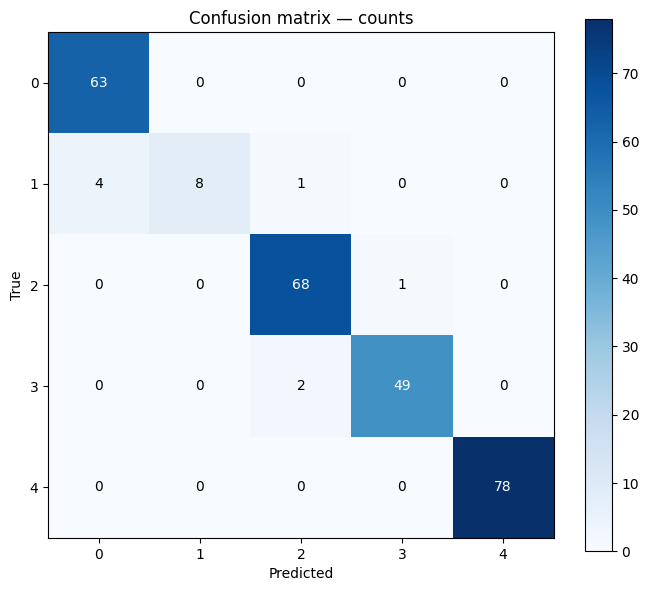

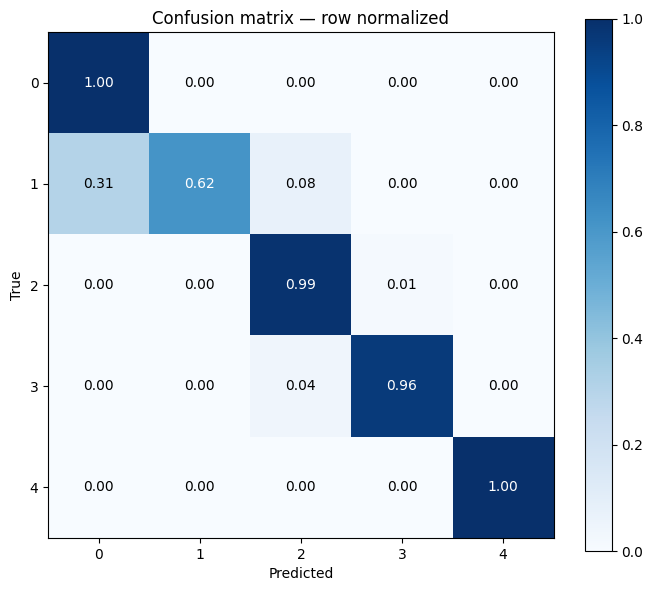

,class,precision,recall,f1,support
0,0,0.940299,1.000000,0.969231,63
1,1,1.000000,0.615385,0.761905,13
2,2,0.957746,0.985507,0.971429,69
3,3,0.980000,0.960784,0.970297,51
4,4,1.000000,1.000000,1.000000,78


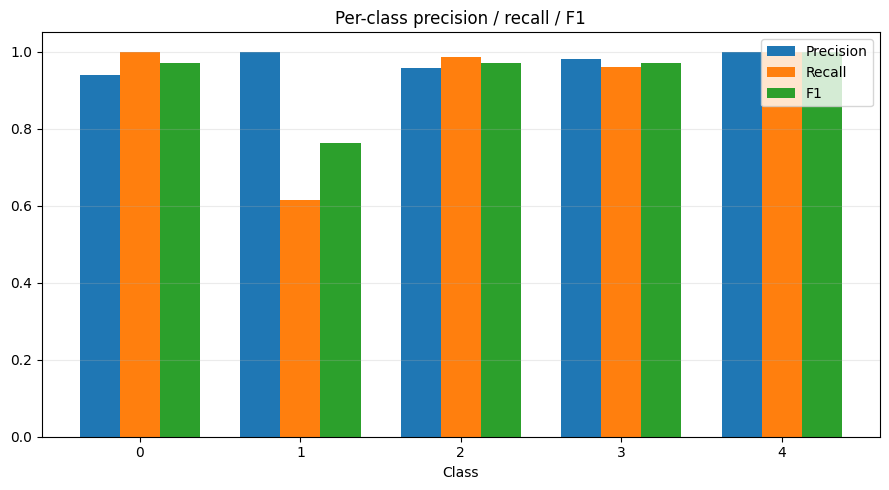

,boundary,support,accuracy,macro_f1,left_f1,right_f1,cross_entropy
0,01,76,0.947368,0.893706,0.969231,0.818182,0.148798
1,12,82,0.987805,0.976403,0.960000,0.992806,0.045836
2,23,120,0.975000,0.974357,0.978417,0.970297,0.079383


,group,positive_support,accuracy,balanced_accuracy,f1,bce
0,01,76,0.996350,0.993421,0.993377,0.012672
1,12,82,0.974453,0.964304,0.956522,0.075024
2,23,120,0.996350,0.996753,0.995851,0.025971
3,4,78,1.000000,1.000000,1.000000,0.013858


⏱ 07_locked_test: 0.23 min cumulative


In [40]:

if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.2 LOCKED TEST — NO REMOVED V17 SYMBOLS
    # ============================================================
    def wilson(k, n, z=1.96):
        if n == 0:
            return 0.0, 1.0
        proportion = k / n
        denominator = 1 + z * z / n
        centre = (proportion + z * z / (2 * n)) / denominator
        half = (
            z
            * math.sqrt(
                proportion * (1 - proportion) / n
                + z * z / (4 * n * n)
            )
            / denominator
        )
        return max(0.0, centre - half), min(1.0, centre + half)

    def bootstrap_ci(y, p, reps=1000):
        rng = np.random.default_rng(CFG.seed + 999)
        ids = [np.where(y == c)[0] for c in range(5)]
        values = []
        for _ in range(reps):
            selected = np.concatenate(
                [rng.choice(rows, len(rows), replace=True) for rows in ids]
            )
            metrics = metric_bundle(y[selected], p[selected])
            values.append(
                [
                    metrics["accuracy"],
                    metrics["macro_f1"],
                    metrics["class1_f1"],
                    metrics["mae"],
                ]
            )
        array = np.asarray(values)
        return pd.DataFrame(
            {
                "metric": ["accuracy", "macro_f1", "class1_f1", "mae"],
                "estimate": [
                    metric_bundle(y, p)[key]
                    for key in ("accuracy", "macro_f1", "class1_f1", "mae")
                ],
                "ci_low": np.quantile(array, 0.025, axis=0),
                "ci_high": np.quantile(array, 0.975, axis=0),
            }
        )

    with timed_stage("07_locked_test"):
        test_cache = collect_cache(
            model,
            test_loader,
            float(locked_inference["prior_mix"]),
            "locked internal test",
        )
        test_y = test_cache["rows"].label.to_numpy()
        v15_test_p = _v182_probability_contract(
            compose_locked(test_cache, locked_inference),
            len(test_y),
            "locked visual probabilities",
        )
        v15_test_m = metric_bundle(test_y, v15_test_p)
        test_p, V184_TEST_SPECIALIST_AUDIT = v184_apply_specialists(
            v15_test_p,
            test_cache,
            V184_FINAL_SPECIALISTS,
            V184_SPECIALIST_LOCK,
            True,
        )
        V184_SPECIALIST_TEST_P = test_p.copy()

        # The retired V17 correction remains an identity. V18 evidence is
        # evaluated only after the V18.4 specialist result.
        legacy_audit = {
            "rare_pair": np.full(
                len(test_p), "", dtype=object
            ),
            "rare_consensus": np.zeros(
                len(test_p), dtype=np.float32
            ),
            "rare_applied": np.zeros(
                len(test_p), dtype=bool
            ),
            "damage_applied": np.zeros(
                len(test_p), dtype=bool
            ),
            "damage_partner": np.full(
                len(test_p), -1, dtype=np.int64
            ),
        }
        test_p = _v182_probability_contract(
            test_p, len(test_y), "V18.4 specialist probabilities"
        )
        # Backward-compatible aliases used by a few inherited audit cells.
        rare_audit = legacy_audit
        rare_only_test = v15_test_p.copy()
        damage_only_test = v15_test_p.copy()
        test_m = metric_bundle(test_y, test_p)
        test_pred = test_m["predictions"]
        cm = confusion_matrix(test_y, test_pred, labels=np.arange(5))
        report = pd.DataFrame(
            classification_report(
                test_y,
                test_pred,
                labels=np.arange(5),
                output_dict=True,
                zero_division=0,
            )
        ).T

        component_rows = []
        for component, probabilities in {
            "protected_visual": v15_test_p,
            "v184_boundary_specialists": V184_SPECIALIST_TEST_P,
            "v184_pre_evidence": test_p,
        }.items():
            metrics = metric_bundle(test_y, probabilities)
            component_rows.append(
                {
                    "component": component,
                    **{
                        key: metrics[key]
                        for key in (
                            "accuracy",
                            "macro_f1",
                            "class1_precision",
                            "class1_recall",
                            "class1_f1",
                            "class4_f1",
                            "mae",
                            "nll",
                        )
                    },
                }
            )
        test_component_rows = component_rows
        test_component_ledger = pd.DataFrame(component_rows)
        test_component_ledger.to_csv(
            OUTPUT_DIR / "internal_test_component_ledger.csv",
            index=False,
        )
        display(test_component_ledger)

        overall = pd.DataFrame(
            [
                {
                    "accuracy": test_m["accuracy"],
                    "balanced_accuracy": test_m["balanced_accuracy"],
                    "macro_f1": test_m["macro_f1"],
                    "weighted_f1": test_m["weighted_f1"],
                    "class1_f1": test_m["class1_f1"],
                    "min_class_f1": test_m["min_class_f1"],
                    "ordinal_mae": test_m["mae"],
                    "nll": test_m["nll"],
                    "ece": test_m["ece"],
                    "correct": int((test_pred == test_y).sum()),
                    "errors": int((test_pred != test_y).sum()),
                    "n": len(test_y),
                }
            ]
        )
        overall.to_csv(
            OUTPUT_DIR / "internal_test_overall_metrics.csv", index=False
        )
        report.to_csv(OUTPUT_DIR / "internal_test_classification_report.csv")
        np.save(OUTPUT_DIR / "internal_test_confusion_matrix.npy", cm)
        display(overall)
        display(report)
        print(
            f'Accuracy={test_m["accuracy"]:.6f} | '
            f'Macro-F1={test_m["macro_f1"]:.6f} | '
            f'class1-F1={test_m["class1_f1"]:.6f} | '
            f'MAE={test_m["mae"]:.6f} | '
            f'errors={(test_pred != test_y).sum()}/{len(test_y)}'
        )

        pred_df = test_cache["rows"].copy()
        pred_df["pred_label"] = test_pred
        pred_df["confidence"] = test_p.max(1)
        sorted_probabilities = np.sort(test_p, axis=1)
        pred_df["margin"] = (
            sorted_probabilities[:, -1] - sorted_probabilities[:, -2]
        )
        for class_index in range(5):
            pred_df[f"p{class_index}"] = test_p[:, class_index]
        pred_df["v15_pred_label"] = v15_test_p.argmax(1)
        pred_df["v15_confidence"] = v15_test_p.max(1)
        pred_df["specialist_pair"] = (
            V184_TEST_SPECIALIST_AUDIT["specialist_pair"]
        )
        pred_df["specialist_applied"] = (
            V184_TEST_SPECIALIST_AUDIT["specialist_applied"]
        )
        pred_df["specialist_probability_right"] = (
            V184_TEST_SPECIALIST_AUDIT[
                "specialist_probability_right"
            ]
        )
        pred_df["specialist_confidence"] = (
            V184_TEST_SPECIALIST_AUDIT["specialist_confidence"]
        )
        _v184_identity = internal_df[
            ["path", "relative_path", "file_sha256"]
        ].drop_duplicates("path")
        pred_df = pred_df.merge(
            _v184_identity,
            on="path",
            how="left",
            validate="one_to_one",
        )
        pred_df["sha256_12"] = pred_df.file_sha256.astype(str).str[:12]
        pred_df["class_folder"] = pred_df.path.astype(str).map(
            lambda value: Path(value).parent.name
        )

        rare_probabilities = test_cache.get("rare")
        if rare_probabilities is None:
            rare_probabilities = v15_test_p
        pred_df["rare_pred_label"] = np.asarray(
            rare_probabilities
        ).argmax(1)
        pred_df["rare_confidence"] = np.asarray(
            rare_probabilities
        ).max(1)
        pred_df["damage_probability"] = np.asarray(
            test_cache.get("damage", np.full(len(test_y), 0.5))
        )
        pred_df["damage_top_probability"] = np.asarray(
            test_cache.get("damage_top", np.full(len(test_y), 0.5))
        )
        pred_df["rare_pair"] = legacy_audit["rare_pair"]
        pred_df["rare_consensus"] = legacy_audit["rare_consensus"]
        pred_df["rare_applied"] = legacy_audit["rare_applied"]
        pred_df["damage_applied"] = legacy_audit["damage_applied"]
        pred_df["damage_partner"] = legacy_audit["damage_partner"]
        pred_df["v17_changed_prediction"] = (
            pred_df.pred_label != pred_df.v15_pred_label
        )
        pred_df["correct"] = pred_df.label == pred_df.pred_label

        # Merge external mask metadata without duplicate-column suffixes.
        if "mask_audit_df" in globals():
            pred_df = _v182_safe_mask_merge(pred_df, mask_audit_df)

        pred_df.to_csv(
            OUTPUT_DIR / "internal_test_predictions.csv", index=False
        )
        errors_df = pred_df[~pred_df.correct].copy()
        errors_df.to_csv(
            OUTPUT_DIR / "internal_test_misclassifications.csv", index=False
        )
        if len(errors_df):
            flows = (
                errors_df.groupby(["label", "pred_label"])
                .size()
                .rename("count")
                .reset_index()
                .sort_values("count", ascending=False)
            )
        else:
            flows = pd.DataFrame(
                columns=["label", "pred_label", "count"]
            )
        flows.to_csv(
            OUTPUT_DIR / "internal_test_confusion_flows.csv", index=False
        )
        display(flows)

        confidence_intervals = bootstrap_ci(test_y, test_p, 1000)
        confidence_intervals.to_csv(
            OUTPUT_DIR / "internal_test_bootstrap_ci.csv", index=False
        )
        display(confidence_intervals)
        class1_rows = test_y == 1
        class1_correct = int((test_pred[class1_rows] == 1).sum())
        class1_total = int(class1_rows.sum())
        lower, upper = wilson(class1_correct, class1_total)
        print(
            f"class 1: {class1_correct}/{class1_total} correct; "
            f"Wilson recall 95% CI=[{lower:.3f},{upper:.3f}]; "
            f"one image changes recall by "
            f"{1 / max(class1_total, 1):.3f}."
        )

        for normalized, filename, title in (
            (False, "confusion_matrix_counts.png", "Confusion matrix — counts"),
            (
                True,
                "confusion_matrix_row_normalized.png",
                "Confusion matrix — row normalized",
            ),
        ):
            matrix = (
                cm / cm.sum(1, keepdims=True).clip(min=1)
                if normalized
                else cm
            )
            fig, ax = plt.subplots(figsize=(7, 6))
            image = ax.imshow(matrix, cmap="Blues")
            ax.set(
                xticks=np.arange(5),
                yticks=np.arange(5),
                xlabel="Predicted",
                ylabel="True",
                title=title,
            )
            threshold = matrix.max() / 2 if matrix.size else 0
            for row_index in range(5):
                for column_index in range(5):
                    ax.text(
                        column_index,
                        row_index,
                        (
                            f"{matrix[row_index, column_index]:.2f}"
                            if normalized
                            else str(int(matrix[row_index, column_index]))
                        ),
                        ha="center",
                        va="center",
                        color=(
                            "white"
                            if matrix[row_index, column_index] > threshold
                            else "black"
                        ),
                    )
            fig.colorbar(image, ax=ax)
            fig.tight_layout()
            fig.savefig(
                OUTPUT_DIR / filename, dpi=160, bbox_inches="tight"
            )
            plt.show()
            plt.close(fig)

        precision, recall, f1_values, support = (
            precision_recall_fscore_support(
                test_y,
                test_pred,
                labels=np.arange(5),
                zero_division=0,
            )
        )
        class_df = pd.DataFrame(
            {
                "class": np.arange(5),
                "precision": precision,
                "recall": recall,
                "f1": f1_values,
                "support": support,
            }
        )
        class_df.to_csv(
            OUTPUT_DIR / "internal_test_per_class_metrics.csv", index=False
        )
        display(class_df)

        fig, ax = plt.subplots(figsize=(9, 5))
        x_positions = np.arange(5)
        width = 0.25
        ax.bar(x_positions - width, precision, width, label="Precision")
        ax.bar(x_positions, recall, width, label="Recall")
        ax.bar(x_positions + width, f1_values, width, label="F1")
        ax.set_xticks(x_positions)
        ax.set_xlabel("Class")
        ax.set_ylim(0, 1.05)
        ax.set_title("Per-class precision / recall / F1")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / "per_class_metrics.png",
            dpi=160,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

        boundary_rows = []
        for left_class, right_class in ((0, 1), (1, 2), (2, 3)):
            selected_rows = np.isin(
                test_y, [left_class, right_class]
            )
            boundary_y = test_y[selected_rows]
            boundary_p = test_p[selected_rows][
                :, [left_class, right_class]
            ]
            boundary_p /= boundary_p.sum(1, keepdims=True)
            boundary_pred = np.array(
                [left_class, right_class]
            )[boundary_p.argmax(1)]
            boundary_f1 = f1_score(
                boundary_y,
                boundary_pred,
                labels=[left_class, right_class],
                average=None,
                zero_division=0,
            )
            boundary_rows.append(
                {
                    "boundary": f"{left_class}{right_class}",
                    "support": int(selected_rows.sum()),
                    "accuracy": accuracy_score(
                        boundary_y, boundary_pred
                    ),
                    "macro_f1": boundary_f1.mean(),
                    "left_f1": boundary_f1[0],
                    "right_f1": boundary_f1[1],
                    "cross_entropy": log_loss(
                        (boundary_y == right_class).astype(int),
                        boundary_p,
                        labels=[0, 1],
                    ),
                }
            )
        boundary_df = pd.DataFrame(boundary_rows)
        boundary_df.to_csv(
            OUTPUT_DIR / "internal_test_boundary_metrics.csv",
            index=False,
        )
        display(boundary_df)

        group_rows = []
        for group_name, group_classes in {
            "01": [0, 1],
            "12": [1, 2],
            "23": [2, 3],
            "4": [4],
        }.items():
            group_target = np.isin(test_y, group_classes).astype(int)
            group_score = test_p[:, group_classes].sum(1)
            group_prediction = (group_score >= 0.5).astype(int)
            group_rows.append(
                {
                    "group": group_name,
                    "positive_support": int(group_target.sum()),
                    "accuracy": accuracy_score(
                        group_target, group_prediction
                    ),
                    "balanced_accuracy": balanced_accuracy_score(
                        group_target, group_prediction
                    ),
                    "f1": f1_score(
                        group_target, group_prediction, zero_division=0
                    ),
                    "bce": float(
                        -(
                            group_target
                            * np.log(np.clip(group_score, 1e-8, 1))
                            + (1 - group_target)
                            * np.log(
                                np.clip(1 - group_score, 1e-8, 1)
                            )
                        ).mean()
                    ),
                }
            )
        group_df = pd.DataFrame(group_rows)
        group_df.to_csv(
            OUTPUT_DIR / "internal_test_group_metrics.csv",
            index=False,
        )
        display(group_df)


### V18 locked evidence correction and final component ledger

In [41]:
if TASK_PROFILE=='mango_advanced' and V18_EVIDENCE_ENABLEE:
    # ============================================================
    # V18 FINAL LOCKED EVIDENCE CORRECTION — TEST USED ONCE, NO SELECTION
    # ============================================================
    with timed_stage('07b_v18_evidence_test'):
        V18_FINAL_EVIDENCE_MODEL = V18_FINAL_EVIDENCE_MODEL.to(DEVICE)
        V18_EVIDENCE_TEST_RAW=v18_evidence_table(internal_df[internal_df.split=='test'],'evidence TEST');V18_EVIDENCE_TEST=dict(V18_EVIDENCE_TEST_RAW);V18_EVIDENCE_TEST['features']=((V18_EVIDENCE_TEST_RAW['features']-V18_FINAL_EVIDENCE_MEAN)/V18_FINAL_EVIDENCE_STD).astype(np.float32)
        V18_TEST_EVIDENCE,V18_TEST_DAMAGE,V18_TEST_DAMAGE_STATS=v18_evidence_predict(V18_FINAL_EVIDENCE_MODEL,V18_EVIDENCE_TEST)
        # Attention concentration audit: high top-mass with low entropy means a few patches dominate.
        concentration=[];V18_FINAL_EVIDENCE_MODEL.eval();cursor=0
        with torch.no_grad():
            for x,o,yb in v18_evidence_loader(V18_EVIDENCE_TEST,False):
                out=V18_FINAL_EVIDENCE_MODEL(x.to(DEVICE),o.to(DEVICE));pred_cls=out['logits'].argmax(1);att=out['fine_attention']
                for j in range(len(yb)):
                    cls=int(pred_cls[j]);branches=att[j,:,cls,:].float().cpu().numpy().T
                    mean_att=branches.mean(0);mean_att=np.clip(mean_att,1e-12,None);mean_att/=mean_att.sum();topn=max(1,int(.10*len(mean_att)));entropy=float(-(mean_att*np.log(mean_att)).sum()/math.log(len(mean_att)))
                    bn=branches/np.maximum(branches.sum(1,keepdims=True),1e-12);sim=bn@bn.T;off=sim[~np.eye(sim.shape[0],dtype=bool)]
                    concentration.append({'path':V18_EVIDENCE_TEST['paths'][cursor+j],'predicted_class':cls,'top10_attention_mass':float(np.sort(mean_att)[-topn:].sum()),'normalized_attention_entropy':entropy,'branch_overlap_mean':float(off.mean()) if len(off) else np.nan,'damage_probability':float(torch.sigmoid(out['damage_logit'][j]).cpu()),'damage_max':float(out['damage_stats'][j,0].cpu())})
                cursor+=len(yb)
        V18_ATTENTION_CONCENTRATION=pd.DataFrame(concentration);V18_ATTENTION_CONCENTRATION.to_csv(OUTPUT_DIR/'v18_evidence_attention_concentration.csv',index=False)

        V18_BASE_TEST_P=test_p.copy();V18_FINAL_PROBS,V18_EVIDENCE_AUDIT=v18_apply_evidence(V18_BASE_TEST_P,V18_TEST_EVIDENCE,V18_TEST_DAMAGE,V18_TEST_DAMAGE_STATS,float(V18_LOCKED_EVIDENCE['pair_alpha']),float(V18_LOCKED_EVIDENCE['damage_alpha']),float(V18_LOCKED_EVIDENCE['consensus']),float(V18_LOCKED_EVIDENCE['damage_threshold']),True)
        V18_COMPONENT_ROWS=[]
        for name,pp in {'V184_specialist_base':V18_BASE_TEST_P,'V18_pair_only':v18_apply_evidence(V18_BASE_TEST_P,V18_TEST_EVIDENCE,V18_TEST_DAMAGE,V18_TEST_DAMAGE_STATS,float(V18_LOCKED_EVIDENCE['pair_alpha']),0.,float(V18_LOCKED_EVIDENCE['consensus']),float(V18_LOCKED_EVIDENCE['damage_threshold'])),'V18_damage_only':v18_apply_evidence(V18_BASE_TEST_P,V18_TEST_EVIDENCE,V18_TEST_DAMAGE,V18_TEST_DAMAGE_STATS,0.,float(V18_LOCKED_EVIDENCE['damage_alpha']),float(V18_LOCKED_EVIDENCE['consensus']),float(V18_LOCKED_EVIDENCE['damage_threshold'])),'V18_full':V18_FINAL_PROBS}.items():
            mm=metric_bundle(test_y,pp);V18_COMPONENT_ROWS.append({'component':name,**{k:mm[k] for k in ('accuracy','macro_f1','class1_precision','class1_recall','class1_f1','class4_f1','mae','nll')}})
        V18_COMPONENT_LEDGER=pd.DataFrame(V18_COMPONENT_ROWS);V18_COMPONENT_LEDGER.to_csv(OUTPUT_DIR/'v18_internal_test_component_ledger.csv',index=False);display(V18_COMPONENT_LEDGER)
        test_p=V18_FINAL_PROBS;test_m=metric_bundle(test_y,test_p);test_pred=test_m['predictions'];cm=confusion_matrix(test_y,test_pred,labels=np.arange(5));report=pd.DataFrame(classification_report(test_y,test_pred,labels=np.arange(5),output_dict=True,zero_division=0)).T
        pred_df=test_cache['rows'].copy();pred_df['pred_label']=test_pred;pred_df['confidence']=test_p.max(1);pred_df['margin']=np.sort(test_p,axis=1)[:,-1]-np.sort(test_p,axis=1)[:,-2]
        for c in range(5):pred_df[f'p{c}']=test_p[:,c];pred_df[f'evidence_p{c}']=V18_TEST_EVIDENCE[:,c]
        pred_df['specialist_pair']=V184_TEST_SPECIALIST_AUDIT['specialist_pair'];pred_df['specialist_applied']=V184_TEST_SPECIALIST_AUDIT['specialist_applied'];pred_df['specialist_probability_right']=V184_TEST_SPECIALIST_AUDIT['specialist_probability_right'];pred_df['specialist_confidence']=V184_TEST_SPECIALIST_AUDIT['specialist_confidence'];pred_df['relative_path']=[str(Path(p).relative_to(dataset_root)) for p in pred_df.path];pred_df['file_sha256']=pred_df.path.map(dict(zip(internal_df.path,internal_df.file_sha256)));pred_df['sha256_12']=pred_df.file_sha256.astype(str).str[:12];pred_df['class_folder']=pred_df.path.astype(str).map(lambda value:Path(value).parent.name);pred_df['evidence_damage_probability']=V18_TEST_DAMAGE;pred_df['evidence_damage_max']=V18_TEST_DAMAGE_STATS[:,0];pred_df['evidence_pair_applied']=V18_EVIDENCE_AUDIT['evidence_pair_applied'];pred_df['evidence_damage_applied']=V18_EVIDENCE_AUDIT['evidence_damage_applied'];pred_df['correct']=pred_df.label==pred_df.pred_label;pred_df.to_csv(OUTPUT_DIR/'v18_internal_test_predictions.csv',index=False)
        errors_df=pred_df[~pred_df.correct].copy();errors_df.to_csv(OUTPUT_DIR/'v18_internal_test_misclassifications.csv',index=False);flows=(errors_df.groupby(['label','pred_label']).size().rename('count').reset_index().sort_values('count',ascending=False) if len(errors_df) else pd.DataFrame(columns=['label','pred_label','count']));flows.to_csv(OUTPUT_DIR/'v18_internal_test_confusion_flows.csv',index=False)
        overall=pd.DataFrame([{'accuracy':test_m['accuracy'],'balanced_accuracy':test_m['balanced_accuracy'],'macro_f1':test_m['macro_f1'],'weighted_f1':test_m['weighted_f1'],'class1_f1':test_m['class1_f1'],'min_class_f1':test_m['min_class_f1'],'ordinal_mae':test_m['mae'],'nll':test_m['nll'],'ece':test_m['ece'],'correct':int((test_pred==test_y).sum()),'errors':int((test_pred!=test_y).sum()),'n':len(test_y)}]);overall.to_csv(OUTPUT_DIR/'v18_internal_test_overall_metrics.csv',index=False);report.to_csv(OUTPUT_DIR/'v18_internal_test_classification_report.csv');np.save(OUTPUT_DIR/'v18_internal_test_confusion_matrix.npy',cm)
        # Final V18 presentation figures (the earlier figures are the protected visual baseline).
        for _normalized in (False,True):
            _mat=cm.astype(float);_name='v18_confusion_matrix_normalized.png' if _normalized else 'v18_confusion_matrix.png';_title='V18 normalized confusion matrix' if _normalized else 'V18 confusion matrix'
            if _normalized:_mat=_mat/np.maximum(_mat.sum(1,keepdims=True),1)
            _fig,_ax=plt.subplots(figsize=(7,6));_im=_ax.imshow(_mat,cmap='Blues');_ax.set_xticks(range(5));_ax.set_yticks(range(5));_ax.set_xlabel('Predicted');_ax.set_ylabel('True');_ax.set_title(_title)
            for _i in range(5):
                for _j in range(5):_ax.text(_j,_i,f'{_mat[_i,_j]:.2f}' if _normalized else str(int(_mat[_i,_j])),ha='center',va='center')
            _fig.colorbar(_im,ax=_ax);_fig.tight_layout();_fig.savefig(OUTPUT_DIR/_name,dpi=150,bbox_inches='tight');plt.show();plt.close(_fig)
        _pr,_rc,_f1,_sp=precision_recall_fscore_support(test_y,test_pred,labels=np.arange(5),zero_division=0)
        _v18_pc=pd.DataFrame({'class':np.arange(5),'class_name':[CLASS_SEMANTICS[i] for i in range(5)],'precision':_pr,'recall':_rc,'f1':_f1,'support':_sp});_v18_pc.to_csv(OUTPUT_DIR/'v18_internal_test_per_class_metrics.csv',index=False)
        _fig,_ax=plt.subplots(figsize=(10,5));_x=np.arange(5);_w=.25;_ax.bar(_x-_w,_pr,_w,label='Precision');_ax.bar(_x,_rc,_w,label='Recall');_ax.bar(_x+_w,_f1,_w,label='F1');_ax.set_xticks(_x);_ax.set_xticklabels(range(5));_ax.set_ylim(0,1.05);_ax.set_title('V18 per-class metrics');_ax.legend();_ax.grid(axis='y',alpha=.25);_fig.tight_layout();_fig.savefig(OUTPUT_DIR/'v18_per_class_metrics.png',dpi=150,bbox_inches='tight');plt.show();plt.close(_fig)
        # Does pseudo-mask reliability correlate with errors? This is not true pixel accuracy.
        _mask_cols=detection_df[['path','mask_confidence','sam_iou','proposal_agreement','mask_area_ratio','detector_source','mask_source']].copy()
        _mask_cols=_mask_cols.rename(columns={'mask_confidence':'external_mask_confidence'}).drop_duplicates('path')
        _mr=pred_df.merge(_mask_cols,on='path',how='left',validate='one_to_one')
        _rel_col='external_mask_confidence' if 'external_mask_confidence' in _mr.columns else ('mask_confidence' if 'mask_confidence' in _mr.columns else None)
        _mask_error_rows=[]
        if _rel_col is not None and pd.to_numeric(_mr[_rel_col],errors='coerce').notna().any():
            _ranked=pd.to_numeric(_mr[_rel_col],errors='coerce').rank(method='first')
            _valid_count=int(_ranked.notna().sum());_q=max(1,min(4,_valid_count))
            if _valid_count>=2 and _q>=2:
                _mr['mask_reliability_bin']=pd.qcut(_ranked,q=_q,labels=False,duplicates='drop')
            else:
                _mr['mask_reliability_bin']=0
        else:
            _mr['mask_reliability_bin']=-1
        for _bin,_g in _mr.groupby('mask_reliability_bin',dropna=False):
            _mask_error_rows.append({'reliability_bin':_bin,'n':len(_g),'mean_mask_confidence':pd.to_numeric(_g[_rel_col],errors='coerce').mean() if _rel_col is not None else np.nan,'accuracy':float(_g.correct.mean()),'error_rate':float((~_g.correct).mean()),'mean_sam_self_iou':pd.to_numeric(_g.sam_iou,errors='coerce').mean() if 'sam_iou' in _g.columns else np.nan,'mean_area':pd.to_numeric(_g.mask_area_ratio,errors='coerce').mean() if 'mask_area_ratio' in _g.columns else np.nan})
        pd.DataFrame(_mask_error_rows).to_csv(OUTPUT_DIR/'v18_mask_reliability_vs_classification.csv',index=False)
        print(f'V18 FINAL Accuracy={test_m["accuracy"]:.6f} | Macro-F1={test_m["macro_f1"]:.6f} | class1-F1={test_m["class1_f1"]:.6f} | MAE={test_m["mae"]:.6f} | errors={(test_pred!=test_y).sum()}/{len(test_y)}');display(overall);display(_v18_pc);display(flows)

elif TASK_PROFILE == 'mango_advanced':
    # Stable-mode identity path. The specialist-adjusted test_p from the
    # locked test cell is the final probability matrix.
    with timed_stage('07b_v18_evidence_test_skipped'):
        V18_BASE_TEST_P = np.asarray(test_p, dtype=np.float64).copy()
        V18_FINAL_PROBS = V18_BASE_TEST_P.copy()
        V18_TEST_EVIDENCE = V18_BASE_TEST_P.copy()
        V18_TEST_DAMAGE = np.zeros(len(test_y), dtype=np.float32)
        V18_TEST_DAMAGE_STATS = np.zeros((len(test_y), 5), dtype=np.float32)
        V18_EVIDENCE_AUDIT = {
            'evidence_pair_applied': np.zeros(len(test_y), dtype=bool),
            'evidence_damage_applied': np.zeros(len(test_y), dtype=bool),
        }
        V18_ATTENTION_CONCENTRATION = pd.DataFrame(
            columns=[
                'path', 'predicted_class', 'top10_attention_mass',
                'normalized_attention_entropy', 'branch_overlap_mean',
                'damage_probability', 'damage_max',
            ]
        )
        V18_ATTENTION_CONCENTRATION.to_csv(
            OUTPUT_DIR / 'v18_evidence_attention_concentration.csv',
            index=False,
        )
        base_metrics = metric_bundle(test_y, V18_BASE_TEST_P)
        V18_COMPONENT_LEDGER = pd.DataFrame([
            {
                'component': 'V184_specialist_base',
                **{key: base_metrics[key] for key in (
                    'accuracy', 'macro_f1', 'class1_precision',
                    'class1_recall', 'class1_f1', 'class4_f1',
                    'mae', 'nll',
                )},
            },
            {
                'component': 'V18_evidence_disabled_identity',
                **{key: base_metrics[key] for key in (
                    'accuracy', 'macro_f1', 'class1_precision',
                    'class1_recall', 'class1_f1', 'class4_f1',
                    'mae', 'nll',
                )},
            },
        ])
        V18_COMPONENT_LEDGER.to_csv(
            OUTPUT_DIR / 'v18_internal_test_component_ledger.csv',
            index=False,
        )
        test_p = V18_FINAL_PROBS
        test_m = base_metrics
        test_pred = test_m['predictions']
        cm = confusion_matrix(test_y, test_pred, labels=np.arange(5))
        report = pd.DataFrame(
            classification_report(
                test_y, test_pred, labels=np.arange(5),
                output_dict=True, zero_division=0,
            )
        ).T
        pred_df = test_cache['rows'].copy()
        pred_df['pred_label'] = test_pred
        pred_df['confidence'] = test_p.max(1)
        pred_df['margin'] = (
            np.sort(test_p, axis=1)[:, -1]
            - np.sort(test_p, axis=1)[:, -2]
        )
        for class_index in range(5):
            pred_df[f'p{class_index}'] = test_p[:, class_index]
            pred_df[f'evidence_p{class_index}'] = test_p[:, class_index]
        pred_df['specialist_pair'] = V184_TEST_SPECIALIST_AUDIT['specialist_pair']
        pred_df['specialist_applied'] = V184_TEST_SPECIALIST_AUDIT['specialist_applied']
        pred_df['specialist_probability_right'] = V184_TEST_SPECIALIST_AUDIT['specialist_probability_right']
        pred_df['specialist_confidence'] = V184_TEST_SPECIALIST_AUDIT['specialist_confidence']
        pred_df['relative_path'] = [
            str(Path(path).relative_to(dataset_root))
            for path in pred_df.path
        ]
        _hash_lookup = dict(zip(internal_df.path, internal_df.file_sha256))
        pred_df['file_sha256'] = pred_df.path.map(_hash_lookup)
        pred_df['sha256_12'] = pred_df.file_sha256.astype(str).str[:12]
        pred_df['class_folder'] = pred_df.path.astype(str).map(
            lambda value: Path(value).parent.name
        )
        pred_df['evidence_damage_probability'] = 0.0
        pred_df['evidence_damage_max'] = 0.0
        pred_df['evidence_pair_applied'] = False
        pred_df['evidence_damage_applied'] = False
        pred_df['correct'] = pred_df.label == pred_df.pred_label
        pred_df.to_csv(
            OUTPUT_DIR / 'v18_internal_test_predictions.csv', index=False
        )
        errors_df = pred_df[~pred_df.correct].copy()
        errors_df.to_csv(
            OUTPUT_DIR / 'v18_internal_test_misclassifications.csv',
            index=False,
        )
        flows = (
            errors_df.groupby(['label', 'pred_label'])
            .size().rename('count').reset_index()
            .sort_values('count', ascending=False)
            if len(errors_df)
            else pd.DataFrame(columns=['label', 'pred_label', 'count'])
        )
        flows.to_csv(
            OUTPUT_DIR / 'v18_internal_test_confusion_flows.csv', index=False
        )
        overall = pd.DataFrame([{
            'accuracy': test_m['accuracy'],
            'balanced_accuracy': test_m['balanced_accuracy'],
            'macro_f1': test_m['macro_f1'],
            'weighted_f1': test_m['weighted_f1'],
            'class1_f1': test_m['class1_f1'],
            'min_class_f1': test_m['min_class_f1'],
            'ordinal_mae': test_m['mae'],
            'nll': test_m['nll'],
            'ece': test_m['ece'],
            'correct': int((test_pred == test_y).sum()),
            'errors': int((test_pred != test_y).sum()),
            'n': len(test_y),
        }])
        overall.to_csv(
            OUTPUT_DIR / 'v18_internal_test_overall_metrics.csv', index=False
        )
        report.to_csv(
            OUTPUT_DIR / 'v18_internal_test_classification_report.csv'
        )
        np.save(OUTPUT_DIR / 'v18_internal_test_confusion_matrix.npy', cm)
        _pr, _rc, _f1, _support = precision_recall_fscore_support(
            test_y, test_pred, labels=np.arange(5), zero_division=0
        )
        _v18_pc = pd.DataFrame({
            'class': np.arange(5),
            'class_name': [CLASS_SEMANTICS[i] for i in range(5)],
            'precision': _pr,
            'recall': _rc,
            'f1': _f1,
            'support': _support,
        })
        _v18_pc.to_csv(
            OUTPUT_DIR / 'v18_internal_test_per_class_metrics.csv',
            index=False,
        )
        print(
            f'V18 FINAL Accuracy={test_m["accuracy"]:.6f} | '
            f'Macro-F1={test_m["macro_f1"]:.6f} | '
            f'class1-F1={test_m["class1_f1"]:.6f} | '
            f'MAE={test_m["mae"]:.6f} | '
            f'errors={(test_pred != test_y).sum()}/{len(test_y)}'
        )
        display(V18_COMPONENT_LEDGER)
        display(overall)
        display(_v18_pc)
        display(flows)
else:
    print('Skip mango-specific cell for generic profile.')


V18 FINAL Accuracy=0.970803 | Macro-F1=0.934572 | class1-F1=0.761905 | MAE=0.029197 | errors=8/274


,component,accuracy,macro_f1,class1_precision,class1_recall,class1_f1,class4_f1,mae,nll
0,V184_specialist_base,0.970803,0.934572,1.0,0.615385,0.761905,1.0,0.029197,0.102319
1,V18_evidence_disabled_identity,0.970803,0.934572,1.0,0.615385,0.761905,1.0,0.029197,0.102319


,accuracy,balanced_accuracy,macro_f1,weighted_f1,class1_f1,min_class_f1,ordinal_mae,nll,ece,correct,errors,n
0,0.970803,0.912335,0.934572,0.968905,0.761905,0.761905,0.029197,0.102319,0.032215,266,8,274


,class,class_name,precision,recall,f1,support
0,0,"Xoài sống, chua, khó đập",0.940299,1.000000,0.969231,63
1,1,"Xoài sống, chua nhẹ, có nguy cơ",1.000000,0.615385,0.761905,13
2,2,"Xoài chín, ngọt thanh, dễ đập",0.957746,0.985507,0.971429,69
3,3,"Xoài chín già, ngọt gắt, không vận chuyển",0.980000,0.960784,0.970297,51
4,4,"Xoài hư, không ăn được",1.000000,1.000000,1.000000,78


,label,pred_label,count
0,1,0,4
3,3,2,2
1,1,2,1
2,2,3,1


⏱ 07b_v18_evidence_test_skipped: 0.00 min cumulative


In [42]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # OPTIONAL INDEPENDENT EXTERNAL TEST — NEVER USED FOR SELECTION
    # ============================================================
    external_status={'configured':bool(external_loader),'evaluated':False}
    if external_loader is not None:
        with timed_stage('08_external_test'):
            c=collect_cache(model,external_loader,float(locked_inference['prior_mix']),'external test');y=c['rows'].label.to_numpy();base=compose_locked(c,locked_inference)
            # Retired V17 correction is not part of V18.3 inference.
            base=np.asarray(base,dtype=np.float64).copy()
            base/=base.sum(1,keepdims=True)
            base,external_specialist_audit=v184_apply_specialists(base,c,V184_FINAL_SPECIALISTS,V184_SPECIALIST_LOCK,True)
            _ext_order=c['rows'].path.astype(str).tolist()
            _ext_source=external_df.copy();_ext_source['path']=_ext_source.path.astype(str)
            if _ext_source.path.duplicated().any():raise RuntimeError('External test contains duplicate exact paths; row alignment is ambiguous.')
            _ext_map=_ext_source.set_index('path',drop=False)
            _ext_missing=[p for p in _ext_order if p not in _ext_map.index]
            if _ext_missing:raise RuntimeError(f'External visual/evidence path mismatch: {len(_ext_missing)} missing, first={_ext_missing[:3]}')
            ext_frame=_ext_map.loc[_ext_order].reset_index(drop=True)
            ext_raw=v18_evidence_table(ext_frame,'evidence EXTERNAL');ext_table=dict(ext_raw);ext_table['features']=((ext_raw['features']-V18_FINAL_EVIDENCE_MEAN)/V18_FINAL_EVIDENCE_STD).astype(np.float32)
            if ext_raw['paths']!=_ext_order:raise RuntimeError('External evidence row order does not match locked visual probabilities.')
            ext_ev,ext_damage,ext_stats=v18_evidence_predict(V18_FINAL_EVIDENCE_MODEL,ext_table);p,ea=v18_apply_evidence(base,ext_ev,ext_damage,ext_stats,float(V18_LOCKED_EVIDENCE['pair_alpha']),float(V18_LOCKED_EVIDENCE['damage_alpha']),float(V18_LOCKED_EVIDENCE['consensus']),float(V18_LOCKED_EVIDENCE['damage_threshold']),True)
            m=metric_bundle(y,p);external_status.update(evaluated=True,n=len(y),accuracy=m['accuracy'],macro_f1=m['macro_f1'],class1_f1=m['class1_f1'],class4_f1=m['class4_f1'],mae=m['mae']);df=c['rows'].copy();df['pred_label']=p.argmax(1);df['confidence']=p.max(1);df['specialist_pair']=external_specialist_audit['specialist_pair'];df['specialist_applied']=external_specialist_audit['specialist_applied'];df['specialist_probability_right']=external_specialist_audit['specialist_probability_right'];df['evidence_damage_probability']=ext_damage;df['evidence_pair_applied']=ea['evidence_pair_applied'];df['evidence_damage_applied']=ea['evidence_damage_applied'];df.to_csv(OUTPUT_DIR/'external_test_predictions.csv',index=False);pd.DataFrame([external_status]).to_csv(OUTPUT_DIR/'external_test_metrics.csv',index=False);display(pd.DataFrame([external_status]))
    else:print('No independent external test configured. A duplicate/alias copy must not be presented as external evidence.')
else:
    print('Generic external evaluation can be run as a separate dataset with the same locked class mapping.')


No independent external test configured. A duplicate/alias copy must not be presented as external evidence.


## 8. Every error, train+validation neighbours and rare-region XAI

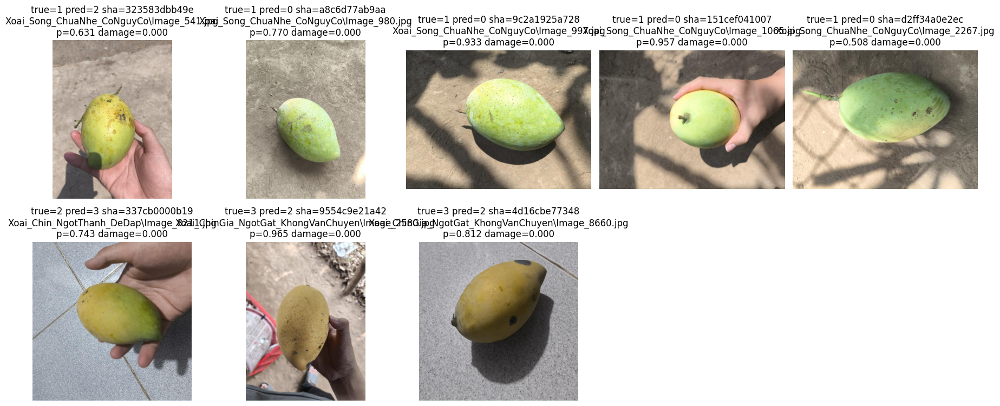

⏱ 08_error_galleries: 0.01 min cumulative


nearest-neighbour reference:   0%|                                                              | 0/99 [00:00<?, ?it/s]

nearest-neighbour reference:   1%|▌                                                     | 1/99 [00:00<01:03,  1.53it/s]

nearest-neighbour reference:   2%|█                                                     | 2/99 [00:01<00:50,  1.91it/s]

nearest-neighbour reference:   3%|█▋                                                    | 3/99 [00:01<00:46,  2.05it/s]

nearest-neighbour reference:   4%|██▏                                                   | 4/99 [00:01<00:44,  2.15it/s]

nearest-neighbour reference:   5%|██▋                                                   | 5/99 [00:02<00:42,  2.21it/s]

nearest-neighbour reference:   6%|███▎                                                  | 6/99 [00:02<00:41,  2.24it/s]

nearest-neighbour reference:   7%|███▊                                                  | 7/99 [00:03<00:40,  2.25it/s]

nearest-neighbour reference:   8%|████▎                                                 | 8/99 [00:03<00:40,  2.27it/s]

nearest-neighbour reference:   9%|████▉                                                 | 9/99 [00:04<00:39,  2.26it/s]

nearest-neighbour reference:  10%|█████▎                                               | 10/99 [00:04<00:38,  2.29it/s]

nearest-neighbour reference:  11%|█████▉                                               | 11/99 [00:05<00:38,  2.26it/s]

nearest-neighbour reference:  12%|██████▍                                              | 12/99 [00:05<00:38,  2.24it/s]

nearest-neighbour reference:  13%|██████▉                                              | 13/99 [00:05<00:38,  2.22it/s]

nearest-neighbour reference:  14%|███████▍                                             | 14/99 [00:06<00:38,  2.23it/s]

nearest-neighbour reference:  15%|████████                                             | 15/99 [00:06<00:37,  2.25it/s]

nearest-neighbour reference:  16%|████████▌                                            | 16/99 [00:07<00:36,  2.26it/s]

nearest-neighbour reference:  17%|█████████                                            | 17/99 [00:07<00:36,  2.22it/s]

nearest-neighbour reference:  18%|█████████▋                                           | 18/99 [00:08<00:37,  2.17it/s]

nearest-neighbour reference:  19%|██████████▏                                          | 19/99 [00:08<00:36,  2.17it/s]

nearest-neighbour reference:  20%|██████████▋                                          | 20/99 [00:09<00:35,  2.20it/s]

nearest-neighbour reference:  21%|███████████▏                                         | 21/99 [00:09<00:36,  2.16it/s]

nearest-neighbour reference:  22%|███████████▊                                         | 22/99 [00:10<00:36,  2.10it/s]

nearest-neighbour reference:  23%|████████████▎                                        | 23/99 [00:10<00:35,  2.11it/s]

nearest-neighbour reference:  24%|████████████▊                                        | 24/99 [00:11<00:35,  2.12it/s]

nearest-neighbour reference:  25%|█████████████▍                                       | 25/99 [00:11<00:34,  2.14it/s]

nearest-neighbour reference:  26%|█████████████▉                                       | 26/99 [00:11<00:33,  2.15it/s]

nearest-neighbour reference:  27%|██████████████▍                                      | 27/99 [00:12<00:33,  2.15it/s]

nearest-neighbour reference:  28%|██████████████▉                                      | 28/99 [00:12<00:33,  2.14it/s]

nearest-neighbour reference:  29%|███████████████▌                                     | 29/99 [00:13<00:33,  2.11it/s]

nearest-neighbour reference:  30%|████████████████                                     | 30/99 [00:13<00:32,  2.15it/s]

nearest-neighbour reference:  31%|████████████████▌                                    | 31/99 [00:14<00:31,  2.17it/s]

nearest-neighbour reference:  32%|█████████████████▏                                   | 32/99 [00:14<00:30,  2.23it/s]

nearest-neighbour reference:  33%|█████████████████▋                                   | 33/99 [00:15<00:29,  2.26it/s]

nearest-neighbour reference:  34%|██████████████████▏                                  | 34/99 [00:15<00:29,  2.24it/s]

nearest-neighbour reference:  35%|██████████████████▋                                  | 35/99 [00:16<00:28,  2.22it/s]

nearest-neighbour reference:  36%|███████████████████▎                                 | 36/99 [00:16<00:29,  2.15it/s]

nearest-neighbour reference:  37%|███████████████████▊                                 | 37/99 [00:17<00:29,  2.08it/s]

nearest-neighbour reference:  38%|████████████████████▎                                | 38/99 [00:17<00:29,  2.04it/s]

nearest-neighbour reference:  39%|████████████████████▉                                | 39/99 [00:18<00:29,  2.04it/s]

nearest-neighbour reference:  40%|█████████████████████▍                               | 40/99 [00:18<00:28,  2.06it/s]

nearest-neighbour reference:  41%|█████████████████████▉                               | 41/99 [00:18<00:27,  2.08it/s]

nearest-neighbour reference:  42%|██████████████████████▍                              | 42/99 [00:19<00:27,  2.07it/s]

nearest-neighbour reference:  43%|███████████████████████                              | 43/99 [00:19<00:26,  2.10it/s]

nearest-neighbour reference:  44%|███████████████████████▌                             | 44/99 [00:20<00:25,  2.13it/s]

nearest-neighbour reference:  45%|████████████████████████                             | 45/99 [00:20<00:24,  2.17it/s]

nearest-neighbour reference:  46%|████████████████████████▋                            | 46/99 [00:21<00:24,  2.15it/s]

nearest-neighbour reference:  47%|█████████████████████████▏                           | 47/99 [00:21<00:24,  2.12it/s]

nearest-neighbour reference:  48%|█████████████████████████▋                           | 48/99 [00:22<00:24,  2.11it/s]

nearest-neighbour reference:  49%|██████████████████████████▏                          | 49/99 [00:22<00:23,  2.12it/s]

nearest-neighbour reference:  51%|██████████████████████████▊                          | 50/99 [00:23<00:23,  2.10it/s]

nearest-neighbour reference:  52%|███████████████████████████▎                         | 51/99 [00:23<00:22,  2.09it/s]

nearest-neighbour reference:  53%|███████████████████████████▊                         | 52/99 [00:24<00:22,  2.08it/s]

nearest-neighbour reference:  54%|████████████████████████████▎                        | 53/99 [00:24<00:22,  2.07it/s]

nearest-neighbour reference:  55%|████████████████████████████▉                        | 54/99 [00:25<00:21,  2.06it/s]

nearest-neighbour reference:  56%|█████████████████████████████▍                       | 55/99 [00:25<00:21,  2.05it/s]

nearest-neighbour reference:  57%|█████████████████████████████▉                       | 56/99 [00:26<00:20,  2.05it/s]

nearest-neighbour reference:  58%|██████████████████████████████▌                      | 57/99 [00:26<00:20,  2.03it/s]

nearest-neighbour reference:  59%|███████████████████████████████                      | 58/99 [00:27<00:20,  2.04it/s]

nearest-neighbour reference:  60%|███████████████████████████████▌                     | 59/99 [00:27<00:19,  2.09it/s]

nearest-neighbour reference:  61%|████████████████████████████████                     | 60/99 [00:28<00:18,  2.14it/s]

nearest-neighbour reference:  62%|████████████████████████████████▋                    | 61/99 [00:28<00:17,  2.18it/s]

nearest-neighbour reference:  63%|█████████████████████████████████▏                   | 62/99 [00:28<00:16,  2.20it/s]

nearest-neighbour reference:  64%|█████████████████████████████████▋                   | 63/99 [00:29<00:16,  2.23it/s]

nearest-neighbour reference:  65%|██████████████████████████████████▎                  | 64/99 [00:29<00:15,  2.24it/s]

nearest-neighbour reference:  66%|██████████████████████████████████▊                  | 65/99 [00:30<00:15,  2.26it/s]

nearest-neighbour reference:  67%|███████████████████████████████████▎                 | 66/99 [00:30<00:14,  2.26it/s]

nearest-neighbour reference:  68%|███████████████████████████████████▊                 | 67/99 [00:31<00:14,  2.26it/s]

nearest-neighbour reference:  69%|████████████████████████████████████▍                | 68/99 [00:31<00:13,  2.24it/s]

nearest-neighbour reference:  70%|████████████████████████████████████▉                | 69/99 [00:32<00:13,  2.26it/s]

nearest-neighbour reference:  71%|█████████████████████████████████████▍               | 70/99 [00:32<00:12,  2.27it/s]

nearest-neighbour reference:  72%|██████████████████████████████████████               | 71/99 [00:32<00:12,  2.29it/s]

nearest-neighbour reference:  73%|██████████████████████████████████████▌              | 72/99 [00:33<00:11,  2.27it/s]

nearest-neighbour reference:  74%|███████████████████████████████████████              | 73/99 [00:33<00:11,  2.24it/s]

nearest-neighbour reference:  75%|███████████████████████████████████████▌             | 74/99 [00:34<00:11,  2.20it/s]

nearest-neighbour reference:  76%|████████████████████████████████████████▏            | 75/99 [00:34<00:11,  2.18it/s]

nearest-neighbour reference:  77%|████████████████████████████████████████▋            | 76/99 [00:35<00:10,  2.21it/s]

nearest-neighbour reference:  78%|█████████████████████████████████████████▏           | 77/99 [00:35<00:09,  2.24it/s]

nearest-neighbour reference:  79%|█████████████████████████████████████████▊           | 78/99 [00:36<00:09,  2.26it/s]

nearest-neighbour reference:  80%|██████████████████████████████████████████▎          | 79/99 [00:36<00:08,  2.25it/s]

nearest-neighbour reference:  81%|██████████████████████████████████████████▊          | 80/99 [00:36<00:08,  2.27it/s]

nearest-neighbour reference:  82%|███████████████████████████████████████████▎         | 81/99 [00:37<00:07,  2.26it/s]

nearest-neighbour reference:  83%|███████████████████████████████████████████▉         | 82/99 [00:37<00:08,  2.01it/s]

nearest-neighbour reference:  84%|████████████████████████████████████████████▍        | 83/99 [00:38<00:08,  1.78it/s]

nearest-neighbour reference:  85%|████████████████████████████████████████████▉        | 84/99 [00:39<00:09,  1.62it/s]

nearest-neighbour reference:  86%|█████████████████████████████████████████████▌       | 85/99 [00:40<00:09,  1.48it/s]

nearest-neighbour reference:  87%|██████████████████████████████████████████████       | 86/99 [00:40<00:08,  1.45it/s]

nearest-neighbour reference:  88%|██████████████████████████████████████████████▌      | 87/99 [00:41<00:08,  1.45it/s]

nearest-neighbour reference:  89%|███████████████████████████████████████████████      | 88/99 [00:42<00:07,  1.45it/s]

nearest-neighbour reference:  90%|███████████████████████████████████████████████▋     | 89/99 [00:43<00:06,  1.45it/s]

nearest-neighbour reference:  91%|████████████████████████████████████████████████▏    | 90/99 [00:43<00:06,  1.44it/s]

nearest-neighbour reference:  92%|████████████████████████████████████████████████▋    | 91/99 [00:44<00:05,  1.42it/s]

nearest-neighbour reference:  93%|█████████████████████████████████████████████████▎   | 92/99 [00:45<00:04,  1.41it/s]

nearest-neighbour reference:  94%|█████████████████████████████████████████████████▊   | 93/99 [00:45<00:04,  1.40it/s]

nearest-neighbour reference:  95%|██████████████████████████████████████████████████▎  | 94/99 [00:46<00:03,  1.41it/s]

nearest-neighbour reference:  96%|██████████████████████████████████████████████████▊  | 95/99 [00:47<00:02,  1.43it/s]

nearest-neighbour reference:  97%|███████████████████████████████████████████████████▍ | 96/99 [00:47<00:02,  1.44it/s]

nearest-neighbour reference:  98%|███████████████████████████████████████████████████▉ | 97/99 [00:48<00:01,  1.44it/s]

nearest-neighbour reference:  99%|████████████████████████████████████████████████████▍| 98/99 [00:49<00:00,  1.44it/s]

nearest-neighbour reference: 100%|█████████████████████████████████████████████████████| 99/99 [00:49<00:00,  1.52it/s]

⏱ 09_nearest_neighbours: 0.83 min cumulative


,query_path,query_true,query_pred,rank,neighbor_path,neighbor_label,cosine_similarity
0,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,1,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0.858472
1,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,2,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Chin_N...,2,0.750490
2,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,3,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0.516798
3,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,4,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Chin_N...,2,0.510358
4,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,5,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0.493766
5,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,6,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Chin_N...,2,0.488632
6,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,7,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0.436638
7,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,1,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,0,0.853621
8,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,2,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,0,0.825423
9,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,3,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,0,0.823187


In [43]:

if TASK_PROFILE == "mango_advanced":
    # ============================================================
    # V18.3 SCHEMA-SAFE ERROR GALLERY + NEAREST NEIGHBOURS
    # ============================================================
    def row_number(
        row,
        candidates,
        default=np.nan,
    ):
        for column in candidates:
            if column not in row.index:
                continue
            value = pd.to_numeric(
                pd.Series([row[column]]),
                errors="coerce",
            ).iloc[0]
            if pd.notna(value):
                return float(value)
        return float(default)

    def error_title(row):
        confidence = row_number(
            row, ("confidence",)
        )
        damage = row_number(
            row,
            (
                "evidence_damage_probability",
                "damage_probability",
                "damage_top_probability",
            ),
        )
        relative_path = str(
            row.get("relative_path", Path(str(row["path"])).name)
        )
        sha12 = str(row.get("sha256_12", ""))
        line = (
            f"true={int(row['label'])} "
            f"pred={int(row['pred_label'])} "
            f"sha={sha12}\n{relative_path}"
        )
        detail = (
            f"p={confidence:.3f}"
            if np.isfinite(confidence)
            else "p=n/a"
        )
        if np.isfinite(damage):
            detail += f" damage={damage:.3f}"
        return line + "\n" + detail

    def save_error_gallery(
        frame,
        output_dir,
        per_page=20,
    ):
        required = {
            "path", "label", "pred_label"
        }
        missing = sorted(
            required.difference(frame.columns)
        )
        if missing:
            raise KeyError(
                f"Gallery missing columns: {missing}"
            )
        if frame.empty:
            print("No internal-test errors.")
            return []

        saved = []
        for page_index, start in enumerate(
            range(0, len(frame), per_page),
            start=1,
        ):
            page = frame.iloc[
                start : start + per_page
            ]
            columns = 5
            rows = math.ceil(len(page) / columns)
            figure, axes = plt.subplots(
                rows,
                columns,
                figsize=(18, 3.8 * rows),
            )
            axes = np.atleast_1d(axes).ravel()
            try:
                for axis, (_, row) in zip(
                    axes, page.iterrows()
                ):
                    try:
                        with Image.open(
                            str(row["path"])
                        ) as image:
                            axis.imshow(
                                ImageOps.exif_transpose(
                                    image
                                ).convert("RGB")
                            )
                        axis.set_title(
                            error_title(row)
                        )
                    except Exception as exc:
                        axis.text(
                            0.02,
                            0.98,
                            f"Report error:\n"
                            f"{type(exc).__name__}: {exc}",
                            va="top",
                            wrap=True,
                        )
                    axis.axis("off")
                for axis in axes[len(page):]:
                    axis.axis("off")
                figure.tight_layout()
                target = (
                    Path(output_dir)
                    / f"all_errors_page_"
                      f"{page_index:02d}.jpg"
                )
                figure.savefig(
                    target,
                    dpi=130,
                    bbox_inches="tight",
                    pil_kwargs={
                        "quality": 88,
                        "optimize": True,
                    },
                )
                plt.show()
                saved.append(str(target))
            finally:
                plt.close(figure)
        return saved

    def build_nearest_neighbours(
        error_frame,
        reference_cache,
        query_cache,
        neighbour_count,
    ):
        columns = [
            "query_path",
            "query_true",
            "query_pred",
            "rank",
            "neighbor_path",
            "neighbor_label",
            "cosine_similarity",
        ]
        if error_frame.empty:
            return pd.DataFrame(columns=columns)

        reference_rows = reference_cache[
            "rows"
        ].reset_index(drop=True)
        query_rows = query_cache[
            "rows"
        ].reset_index(drop=True)
        if reference_rows.path.duplicated().any():
            raise RuntimeError(
                "Reference paths are duplicated."
            )
        if query_rows.path.duplicated().any():
            raise RuntimeError(
                "Query paths are duplicated."
            )

        reference_features = np.asarray(
            reference_cache["features"],
            dtype=np.float32,
        )
        query_features = np.asarray(
            query_cache["features"],
            dtype=np.float32,
        )
        if len(reference_features) != len(
            reference_rows
        ):
            raise RuntimeError(
                "Reference feature alignment failed."
            )
        if len(query_features) != len(query_rows):
            raise RuntimeError(
                "Query feature alignment failed."
            )

        centre = reference_features.mean(
            axis=0, keepdims=True
        )
        reference_normalized = (
            reference_features - centre
        )
        reference_normalized /= np.linalg.norm(
            reference_normalized,
            axis=1,
            keepdims=True,
        ).clip(min=1e-8)
        query_lookup = {
            str(path): index
            for index, path
            in enumerate(query_rows.path)
        }

        output = []
        for _, row in error_frame.iterrows():
            path = str(row["path"])
            if path not in query_lookup:
                raise KeyError(
                    f"Test path missing: {path}"
                )
            feature = (
                query_features[query_lookup[path]]
                - centre[0]
            )
            feature /= max(
                np.linalg.norm(feature), 1e-8
            )
            similarity = (
                reference_normalized @ feature
            )
            selected = np.argsort(similarity)[
                -int(neighbour_count):
            ][::-1]
            for rank, index in enumerate(
                selected, start=1
            ):
                output.append(
                    {
                        "query_path": path,
                        "query_true":
                            int(row["label"]),
                        "query_pred":
                            int(row["pred_label"]),
                        "rank": rank,
                        "neighbor_path":
                            str(
                                reference_rows.iloc[
                                    index
                                ].path
                            ),
                        "neighbor_label":
                            int(
                                reference_rows.iloc[
                                    index
                                ].label
                            ),
                        "cosine_similarity":
                            float(similarity[index]),
                    }
                )
        return pd.DataFrame(
            output, columns=columns
        )

    # Report schema unit test catches the exact failure from V18.2.1.
    test_row = pd.Series(
        {
            "path": "synthetic.jpg",
            "label": 0,
            "pred_label": 1,
            "confidence": 0.75,
            "evidence_damage_probability": 0.12,
        }
    )
    assert "damage=0.120" in error_title(test_row)
    assert "damage=" not in error_title(
        test_row.drop(
            labels=[
                "evidence_damage_probability"
            ]
        )
    )

    error_analysis_receipt = {
        "gallery_status": "NOT_RUN",
        "nearest_neighbour_status": "NOT_RUN",
    }
    try:
        with timed_stage("08_error_galleries"):
            ERROR_GALLERY_FILES = save_error_gallery(
                errors_df, OUTPUT_DIR, per_page=12
            )
        error_analysis_receipt["gallery_status"] = "COMPLETED"
    except Exception as error:
        ERROR_GALLERY_FILES = []
        error_analysis_receipt.update(
            gallery_status="FAILED_SOFT",
            gallery_error=f"{type(error).__name__}: {error}",
        )
        warnings.warn(
            "Error gallery failed softly; metrics/checkpoints remain valid. "
            + error_analysis_receipt["gallery_error"]
        )
        plt.close("all")
        gc.collect()

    nearest_columns = [
        "query_path", "query_true", "query_pred", "rank",
        "neighbor_path", "neighbor_label", "cosine_similarity",
    ]
    try:
        with timed_stage("09_nearest_neighbours"):
            if len(errors_df):
                available = float(psutil.virtual_memory().available / 1024**3)
                if available < 1.25:
                    raise MemoryError(
                        f"Only {available:.2f} GiB RAM available for optional neighbours."
                    )
                reference_dataset = MangoDataset(
                    list(X_train) + list(X_val),
                    list(y_train) + list(y_val),
                    False,
                    19,
                )
                reference_loader = make_loader(
                    reference_dataset,
                    False,
                    119,
                    batch=min(int(CFG.eval_batch), 16),
                    workers_override=0,
                    prefetch_override=0,
                    cuda_prefetch_override=False,
                    pin_memory_override=False,
                    purpose="audit",
                )
                reference_cache = collect_cache(
                    model,
                    reference_loader,
                    float(locked_inference["prior_mix"]),
                    "nearest-neighbour reference",
                )
                nearest_df = build_nearest_neighbours(
                    errors_df, reference_cache, test_cache,
                    CFG.nearest_neighbor_k,
                )
            else:
                nearest_df = pd.DataFrame(columns=nearest_columns)
            error_analysis_receipt["nearest_neighbour_status"] = "COMPLETED"
    except Exception as error:
        nearest_df = pd.DataFrame(columns=nearest_columns)
        error_analysis_receipt.update(
            nearest_neighbour_status=(
                "SKIPPED_LOW_MEMORY"
                if isinstance(error, MemoryError)
                else "FAILED_SOFT"
            ),
            nearest_neighbour_error=f"{type(error).__name__}: {error}",
        )
        warnings.warn(
            "Nearest-neighbour audit failed softly; metrics/checkpoints remain valid. "
            + error_analysis_receipt["nearest_neighbour_error"]
        )
    finally:
        nearest_df.to_csv(
            OUTPUT_DIR / "error_nearest_neighbors.csv", index=False
        )
        with open(
            OUTPUT_DIR / "error_analysis_receipt.json", "w", encoding="utf-8"
        ) as stream:
            json.dump(error_analysis_receipt, stream, indent=2, ensure_ascii=False)
        display(nearest_df.head(30))
        for variable_name in (
            "reference_dataset", "reference_loader", "reference_cache"
        ):
            globals().pop(variable_name, None)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
else:
    print("Skip mango-specific error analysis.")


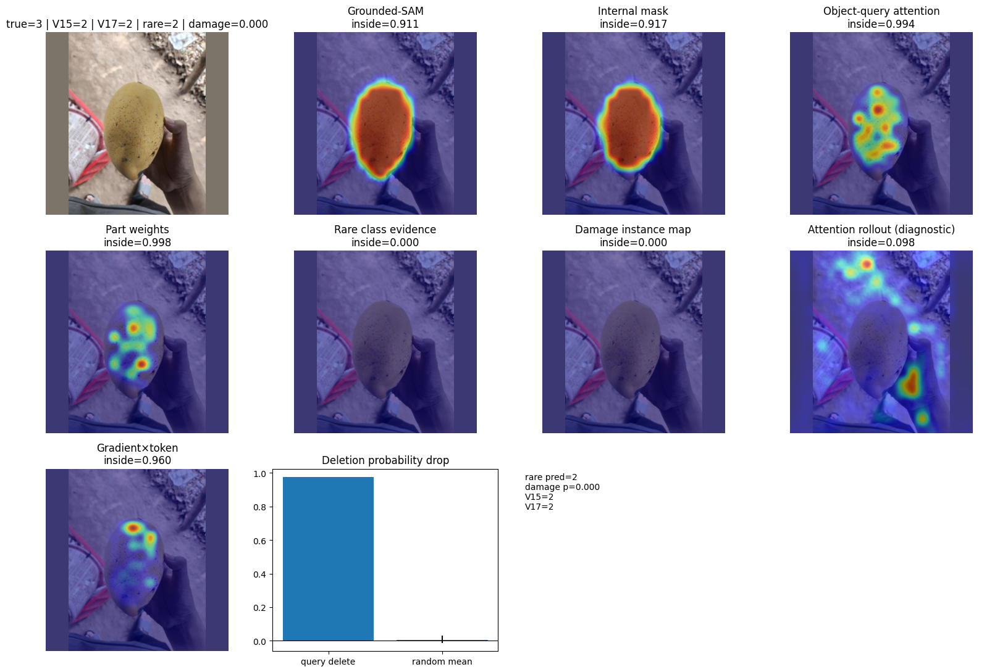

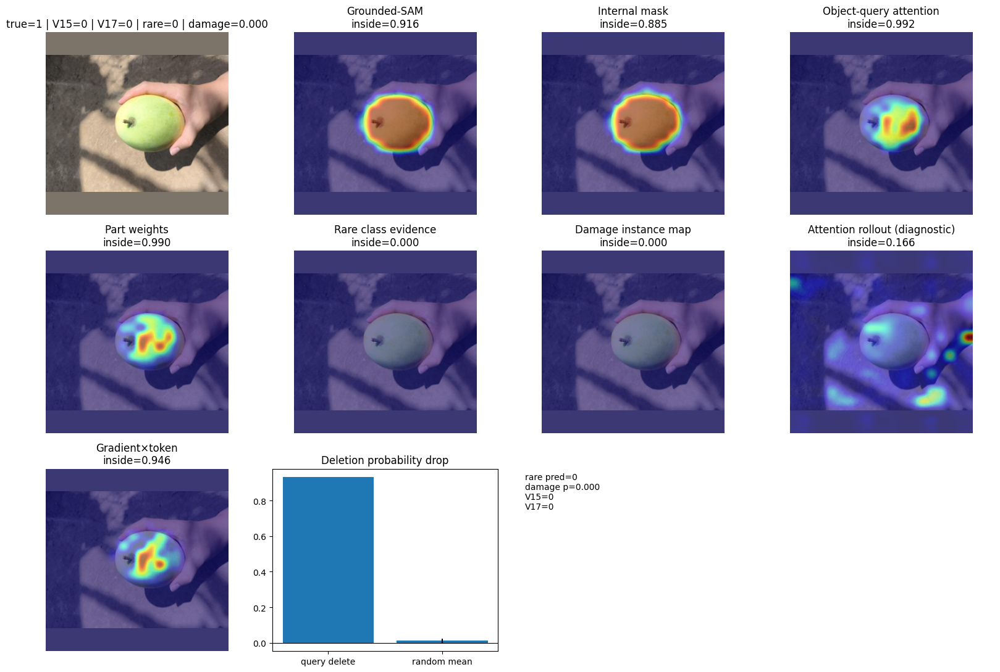

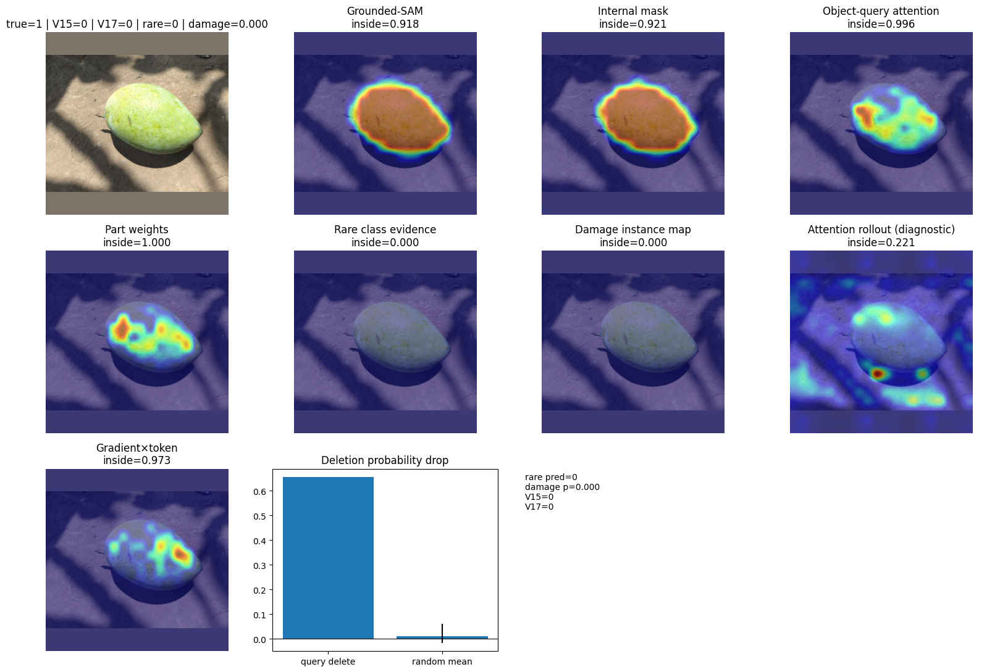

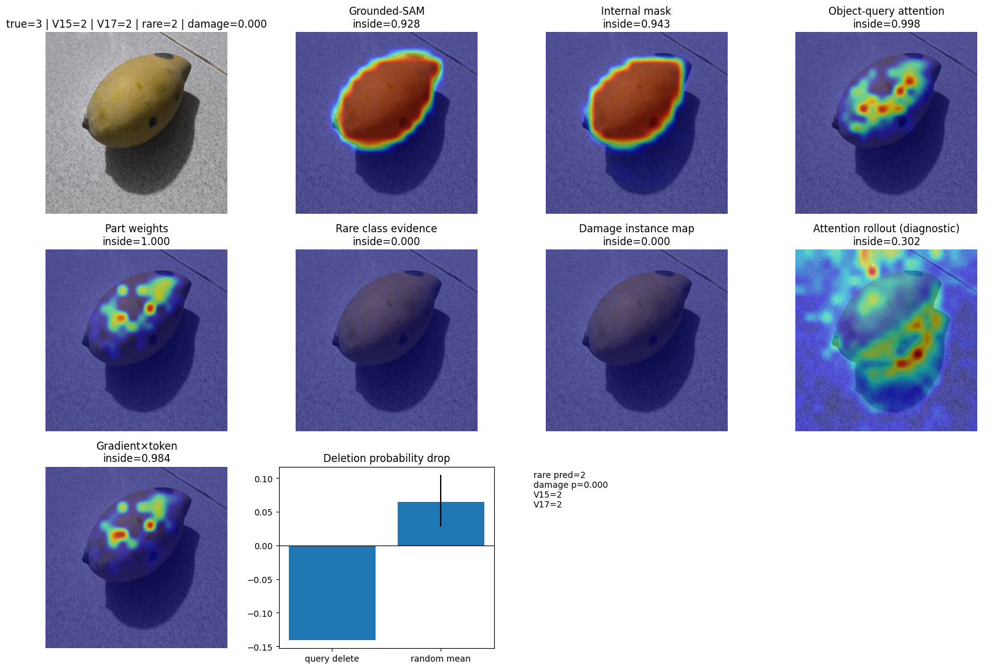

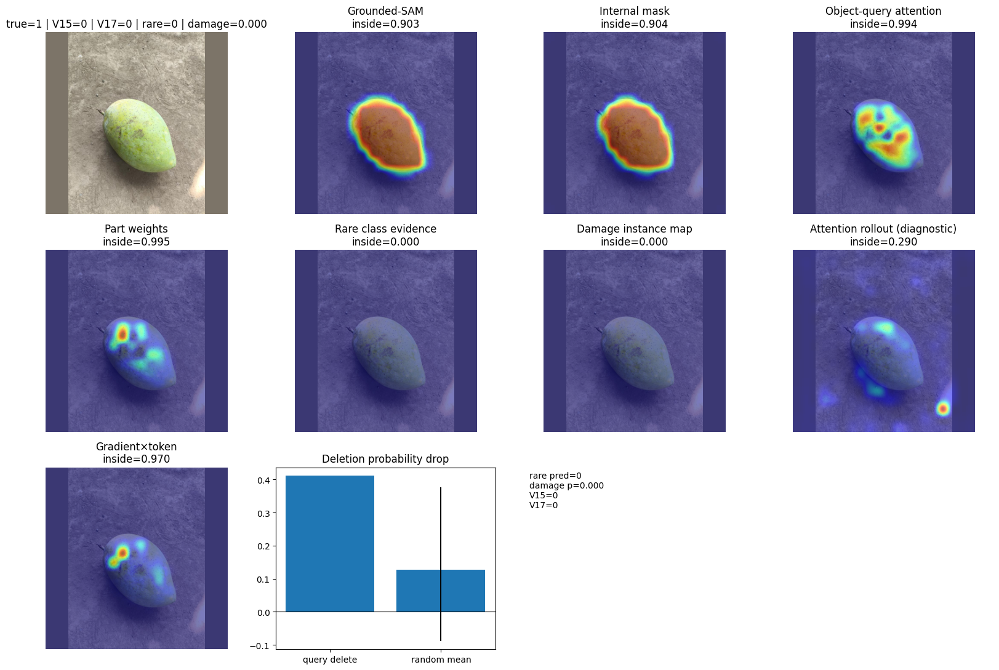

...

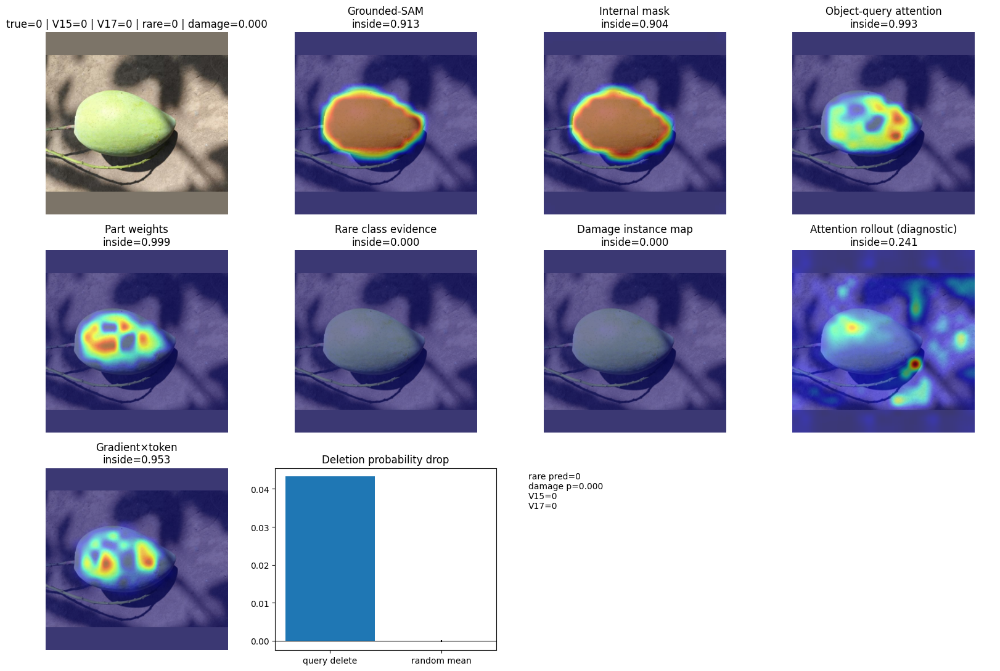

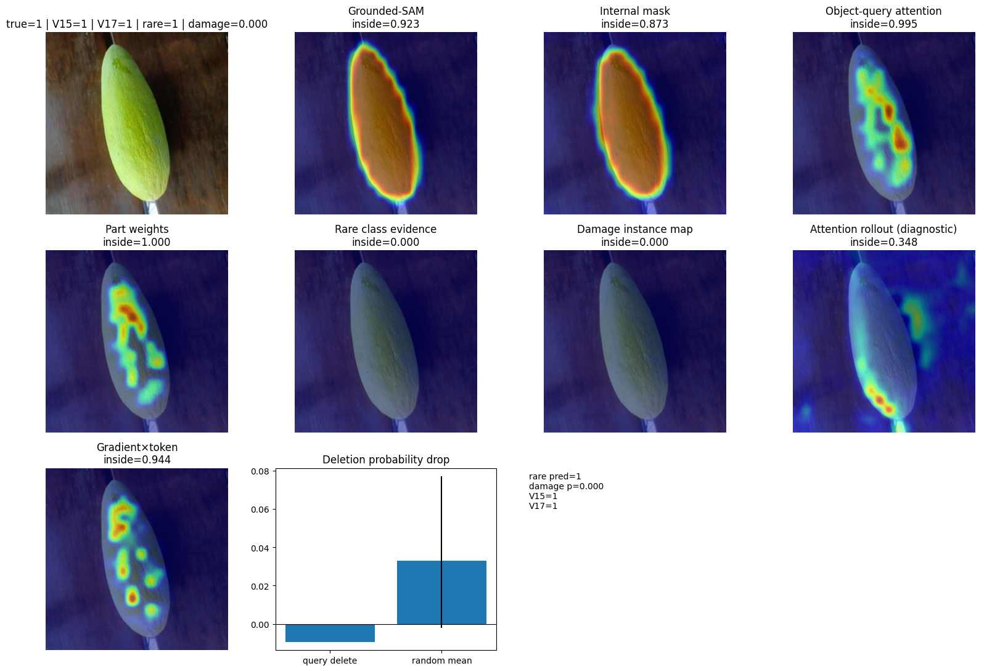

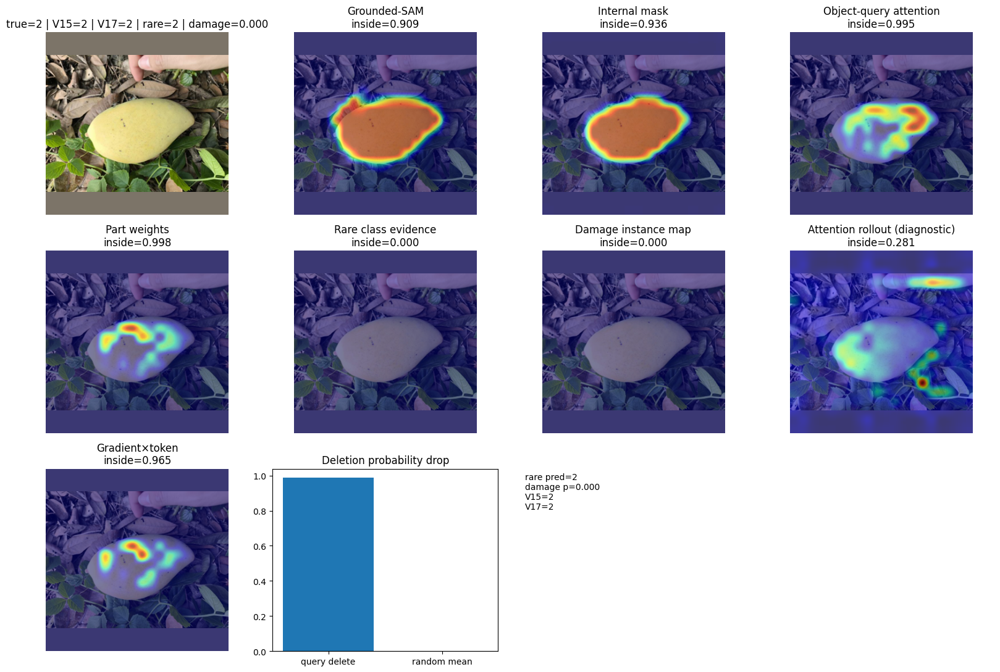

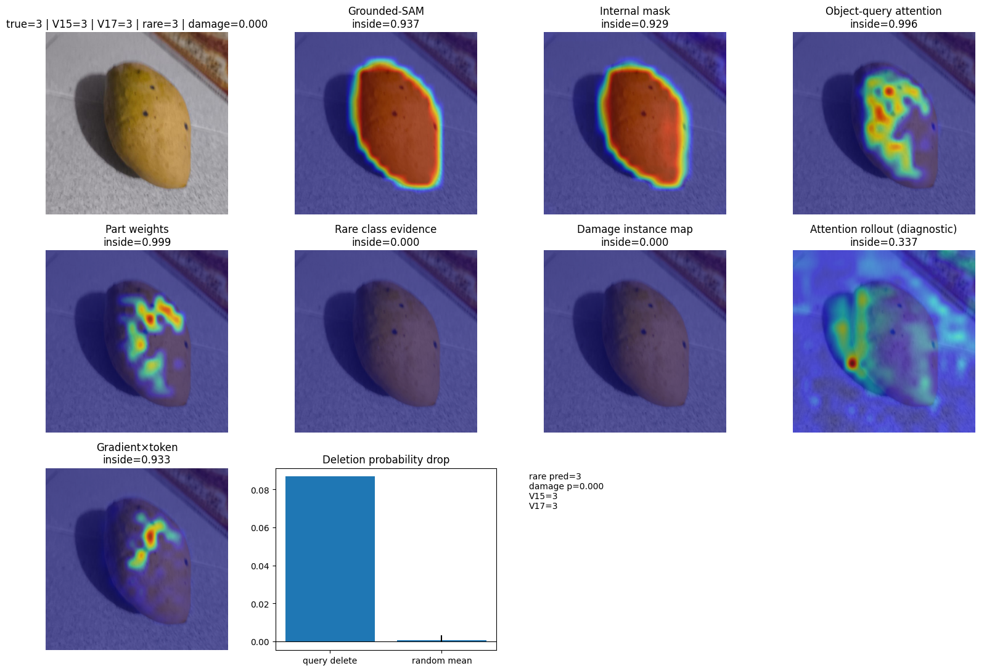

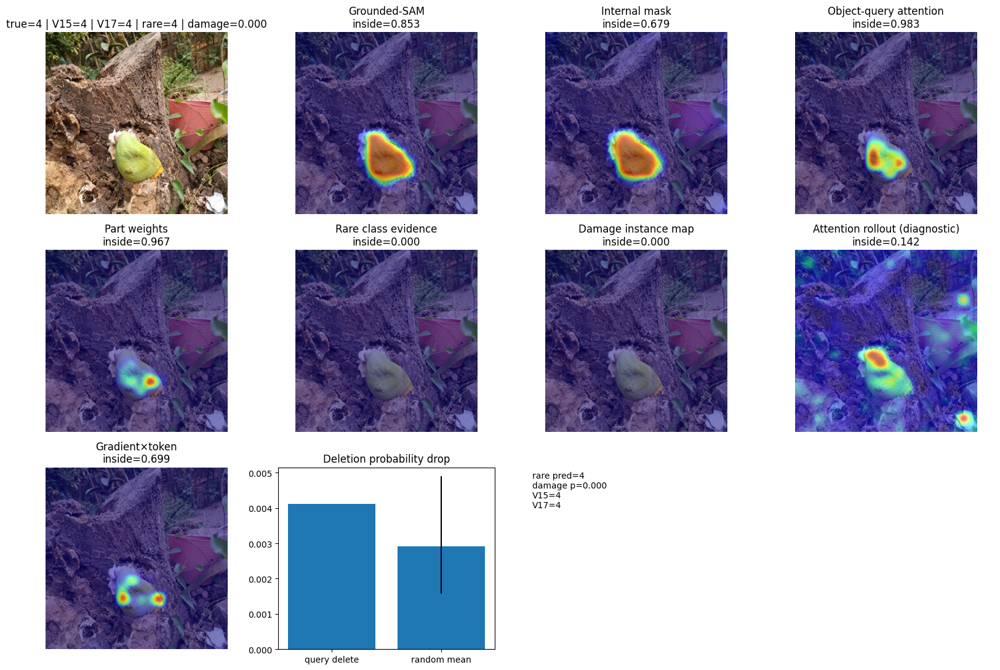

,path,true_label,visual_pred_label,pred_label,rare_pred_label,damage_probability,query_inside,part_inside,rare_inside,damage_inside,rollout_inside,gradient_inside,query_deletion_drop,random_deletion_mean,random_deletion_q95,query_faithful,output,kind
0,E:\kaggle\local\chat\data\xoaimoi8\Xoai_ChinGi...,3,2,2,2,0.0,0.993805,0.998301,0.0,0.0,0.120840,0.960411,0.974544,0.003644,0.025300,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
1,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0,0.0,0.991736,0.989508,0.0,0.0,0.120952,0.945727,0.931442,0.012101,0.021219,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
2,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0,0.0,0.996137,0.999530,0.0,0.0,0.176693,0.972582,0.655588,0.009721,0.057003,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
3,E:\kaggle\local\chat\data\xoaimoi8\Xoai_ChinGi...,3,2,2,2,0.0,0.998442,0.999811,0.0,0.0,0.244557,0.983946,-0.140635,0.064207,0.100843,False,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
4,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0,0.0,0.994056,0.995000,0.0,0.0,0.173107,0.969817,0.411554,0.126249,0.346855,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
5,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Chin_N...,2,3,3,3,0.0,0.998811,0.999924,0.0,0.0,0.163618,0.951110,0.726172,0.642648,0.723437,False,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
6,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,2,2,0.0,0.986637,0.992252,0.0,0.0,0.150913,0.969598,0.617050,-0.005820,0.119287,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
7,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0,0.0,0.995555,1.000000,0.0,0.0,0.169697,0.975981,0.210497,0.047820,0.210355,False,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,error
8,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,0,0,0,0,0.0,0.993173,0.999437,0.0,0.0,0.186154,0.952573,0.043287,-0.000040,0.000180,True,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,correct_control
9,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,1,1,1,0.0,0.995166,1.000000,0.0,0.0,0.273727,0.943758,-0.009375,0.033032,0.074644,False,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,correct_control


,rank,path,error


⏱ 10_xai: 0.26 min cumulative


In [44]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # FAIL-SOFT XAI WITH QUERY, RARE-CLASS AND DAMAGE INSTANCE MAPS
    # ============================================================
    def upmap(v):
        a=np.asarray(v,dtype=np.float32).reshape(GRID_SIZE,GRID_SIZE);a=(a-a.min())/(a.max()-a.min()+1e-8);return np.asarray(Image.fromarray((a*255).astype(np.uint8)).resize((CFG.image_size,CFG.image_size),Image.Resampling.BICUBIC))/255.
    def rollout_map(stack):
        if stack.numel()==0:return np.zeros(GRID_SIZE*GRID_SIZE,np.float32)
        a=stack.float().mean(2)[:,0];n=a.shape[-1];eye=torch.eye(n,device=a.device)[None];a=(a+eye);a=a/a.sum(-1,keepdim=True);joint=eye[0]
        for layer in a:joint=layer@joint
        return joint[0,1+CFG.num_registers:].detach().cpu().numpy()
    def xai_one(path,true_label,pred_label,rank):
        meta=metadata_by_path[path];decision=pred_df[pred_df.path==path].iloc[0] if 'pred_df' in globals() and (pred_df.path==path).any() else None;visual_pred=int(decision.v15_pred_label) if decision is not None and 'v15_pred_label' in decision else int(pred_label);rare_pred=int(decision.rare_pred_label) if decision is not None and 'rare_pred_label' in decision else visual_pred;damage_prob=row_number(decision,('evidence_damage_probability','damage_probability','damage_top_probability')) if decision is not None else float('nan')
        ds=MangoDataset([path],[true_label]);b=move(ds[0]);x=b['pixel_values'][None].detach().requires_grad_(True);cs=b['colour_stats'][None];pls=b['patch_local_stats'][None];pm=b['patch_mask'][None];conf=b['mask_confidence'][None];model.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):o=model(x,cs,pls,pm if float(locked_inference['prior_mix'])>0 else None,conf if float(locked_inference['prior_mix'])>0 else None,float(locked_inference['prior_mix']),collect_attention=True);target=o['main_logits'][0,visual_pred]
        target.backward()
        if o['patch_tokens'].grad is None:
            raise RuntimeError(
                'patch-token gradient is None despite '
                'input.requires_grad=True'
            )
        grad=(
            o['patch_tokens'].grad.float()
            * o['patch_tokens'].float()
        ).sum(-1).abs()[0].detach().cpu().numpy();roll=rollout_map(o['attention_stack']);query=o['query_attention'][0].detach().cpu().numpy();part=o['patch_weights'][0].detach().cpu().numpy();internal=o['predicted_mask'][0].detach().cpu().numpy();mask=pm[0].detach().cpu().numpy();rare_map=o['rare_instance_logits'][0,:,visual_pred].detach().float().cpu().numpy();damage_map=o['damage_map'][0].detach().float().cpu().numpy()
        with Image.open(path) as im,Image.open(meta['mask_path']) as mm:
            raw_image=ImageOps.exif_transpose(im).convert('RGB');raw_mask=mm.convert('L').resize(raw_image.size,Image.Resampling.NEAREST);img=letterbox_pair(raw_image,raw_mask,CFG.image_size)[0]
        maps=[('Grounded-SAM',mask),('Internal mask',internal),('Object-query attention',query),('Part weights',part),('Rare class evidence',rare_map),('Damage instance map',damage_map),('Attention rollout (diagnostic)',roll),('Gradient×token',grad)]
        fig,axes=plt.subplots(3,4,figsize=(16,11));axes=axes.ravel();axes[0].imshow(img);axes[0].set_title(f'true={true_label} | V15={visual_pred} | V17={pred_label} | rare={rare_pred} | damage={damage_prob:.3f}');axes[0].axis('off')
        for ax,(name,v) in zip(axes[1:9],maps):ax.imshow(img);ax.imshow(upmap(v),cmap='jet',alpha=.52);vv=np.asarray(v);vv=(vv-vv.min())/(vv.max()-vv.min()+1e-8);inside=float((vv*mask).sum()/max(vv.sum(),1e-8));ax.set_title(f'{name}\ninside={inside:.3f}');ax.axis('off')
        # One cheap faithfulness check: query deletion vs random deletion.
        q=np.argsort(query)[-max(1,int(len(query)*CFG.deletion_fraction)):];rng=np.random.default_rng(CFG.seed+rank);random_sets=[rng.choice(len(query),len(q),replace=False) for _ in range(CFG.xai_random_baselines)]
        def deleted(ids):
            xx=x.clone();pix=CFG.patch_size
            for j in ids:
                yy=(j//GRID_SIZE)*pix;xx0=(j%GRID_SIZE)*pix;xx[:,:,yy:yy+pix,xx0:xx0+pix]=0
            with torch.no_grad(),torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP_ENABLED):oo=model(xx,cs,pls,pm,conf,float(locked_inference['prior_mix']));return float(torch.softmax(oo['main_logits'].float(),1)[0,visual_pred])
        rawp=float(torch.softmax(o['main_logits'].float(),1)[0,visual_pred].detach().cpu());qd=rawp-deleted(q);random_drops=np.asarray([rawp-deleted(rr) for rr in random_sets],dtype=float);rd=float(random_drops.mean());rq95=float(np.quantile(random_drops,.95));axes[9].bar(['query delete','random mean'],[qd,rd]);axes[9].errorbar([1],[rd],yerr=[[rd-float(random_drops.min())],[float(random_drops.max())-rd]],fmt='none',ecolor='black');axes[9].axhline(0,color='black',lw=.8);axes[9].set_title('Deletion probability drop');axes[10].text(.02,.98,f'rare pred={rare_pred}\ndamage p={damage_prob:.3f}\nV15={visual_pred}\nV17={pred_label}',va='top');axes[10].axis('off');axes[11].axis('off')
        fig.tight_layout();out=OUTPUT_DIR/f'xai_{rank:02d}_true{true_label}_pred{pred_label}.jpg';fig.savefig(out,dpi=130,bbox_inches='tight',pil_kwargs={'quality':88});plt.show();plt.close(fig);model.zero_grad(set_to_none=True);del o,x;torch.cuda.empty_cache();return {'path':path,'true_label':true_label,'visual_pred_label':visual_pred,'pred_label':pred_label,'rare_pred_label':rare_pred,'damage_probability':damage_prob,'query_inside':float((query*mask).sum()/max(query.sum(),1e-8)),'part_inside':float((part*mask).sum()/max(part.sum(),1e-8)),'rare_inside':float((((rare_map-rare_map.min())/(rare_map.max()-rare_map.min()+1e-8))*mask).sum()/max(((rare_map-rare_map.min())/(rare_map.max()-rare_map.min()+1e-8)).sum(),1e-8)),'damage_inside':float((damage_map*mask).sum()/max(damage_map.sum(),1e-8)),'rollout_inside':float((roll*mask).sum()/max(roll.sum(),1e-8)),'gradient_inside':float((grad*mask).sum()/max(grad.sum(),1e-8)),'query_deletion_drop':qd,'random_deletion_mean':rd,'random_deletion_q95':rq95,'query_faithful':bool(qd>0 and qd>rq95+CFG.xai_faithfulness_margin),'output':str(out)}
    with timed_stage('10_xai'):
        targets=[]
        for _,r in errors_df.sort_values('confidence',ascending=False).head(CFG.xai_max_errors).iterrows():targets.append((r.path,int(r.label),int(r.pred_label),'error'))
        for c in range(5):
            z=pred_df[(pred_df.label==c)&pred_df.correct].sort_values('confidence',ascending=False)
            if len(z):r=z.iloc[0];targets.append((r.path,int(r.label),int(r.pred_label),'correct_control'))
        xr=[];xf=[]
        for rank,(p,y,pr,kind) in enumerate(targets,1):
            try:r=xai_one(p,y,pr,rank);r['kind']=kind;xr.append(r)
            except Exception as exc:xf.append({'rank':rank,'path':p,'error':f'{type(exc).__name__}: {exc}'});warnings.warn(f'XAI failed {p}: {exc}')
        xai_df=pd.DataFrame(xr);xai_failures_df=pd.DataFrame(xf,columns=['rank','path','error']);xai_df.to_csv(OUTPUT_DIR/'xai_manifest.csv',index=False);xai_failures_df.to_csv(OUTPUT_DIR/'xai_failures.csv',index=False);display(xai_df);display(xai_failures_df)

else:
    print('Skip mango-specific cell for generic profile.')


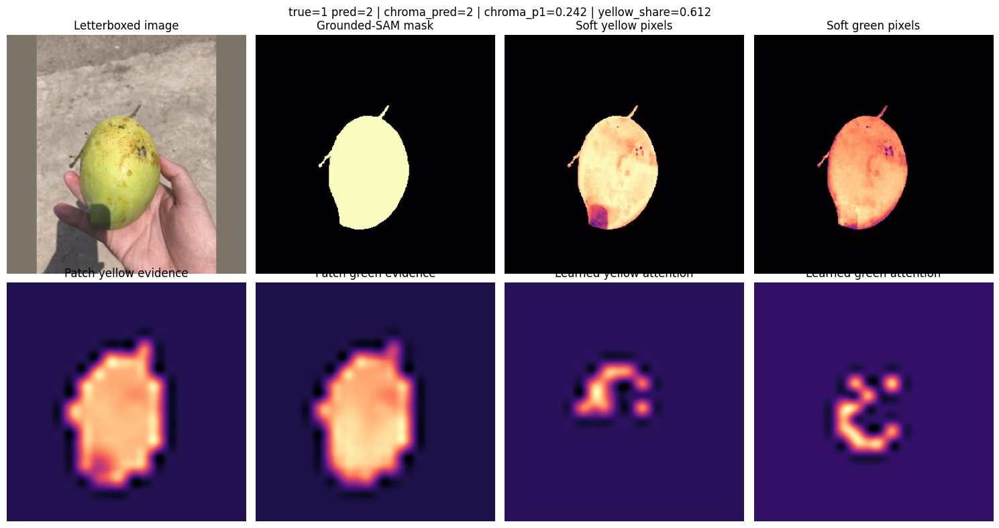

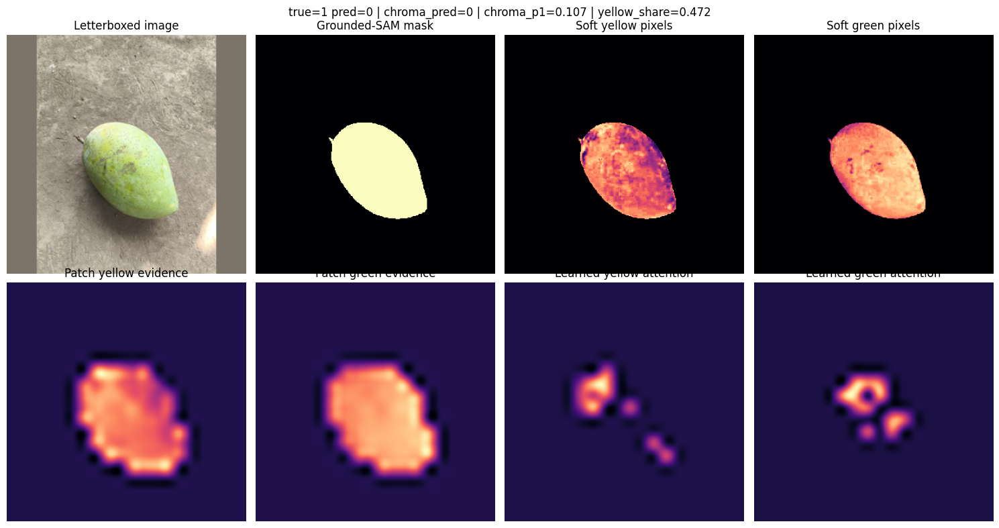

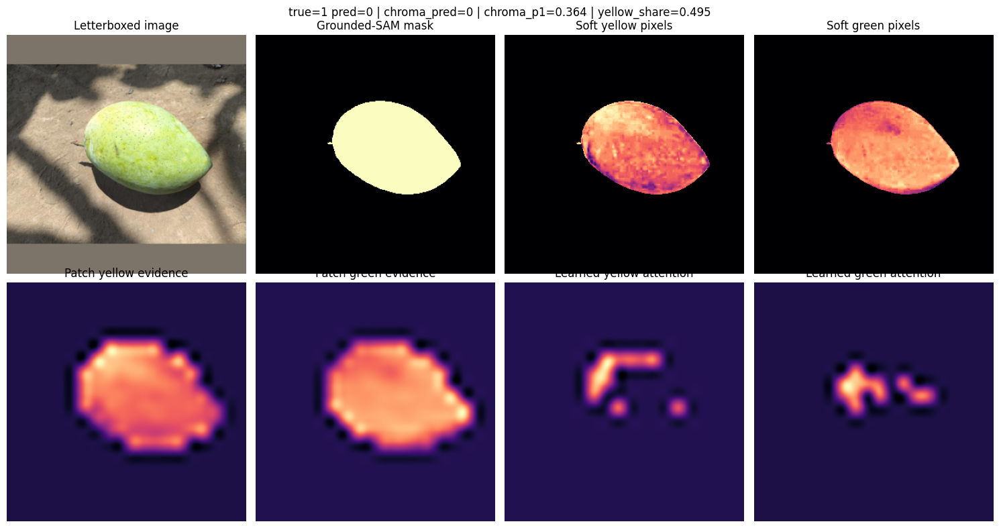

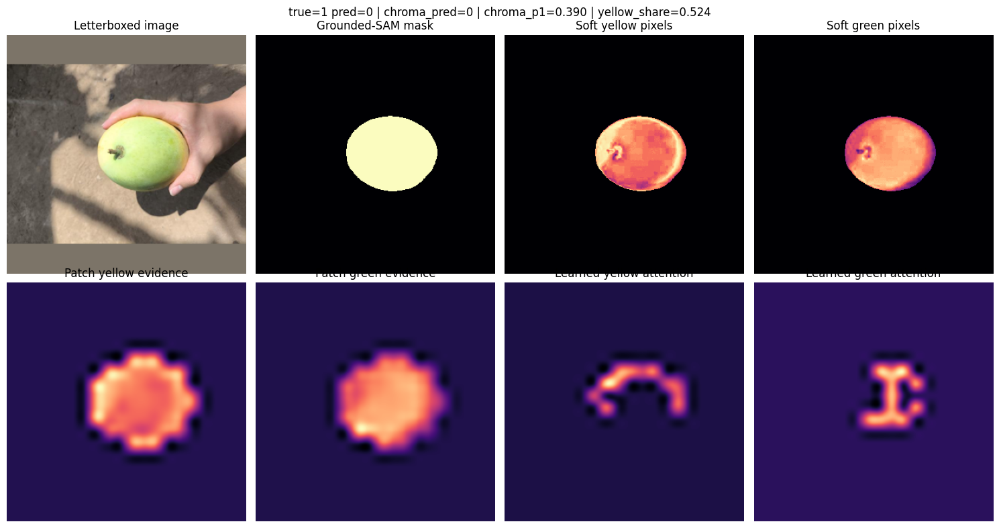

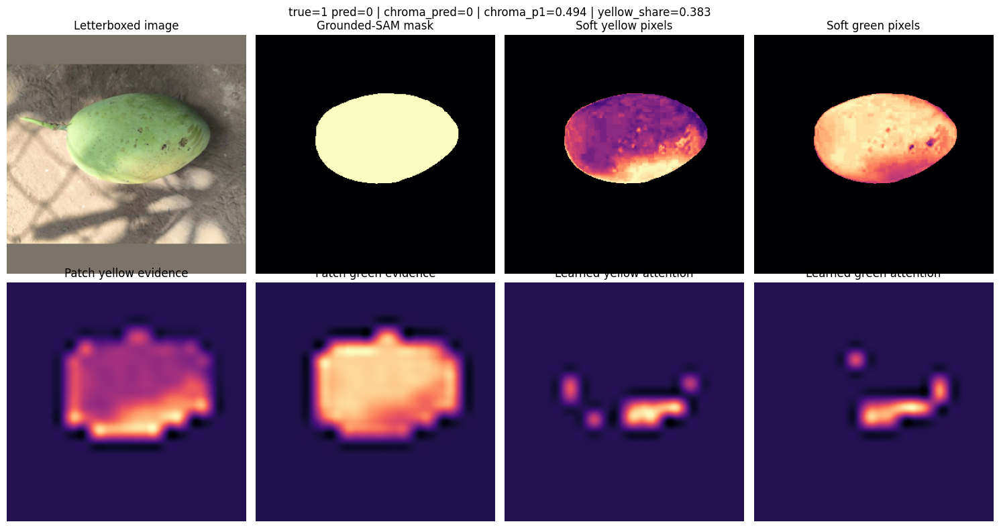

...

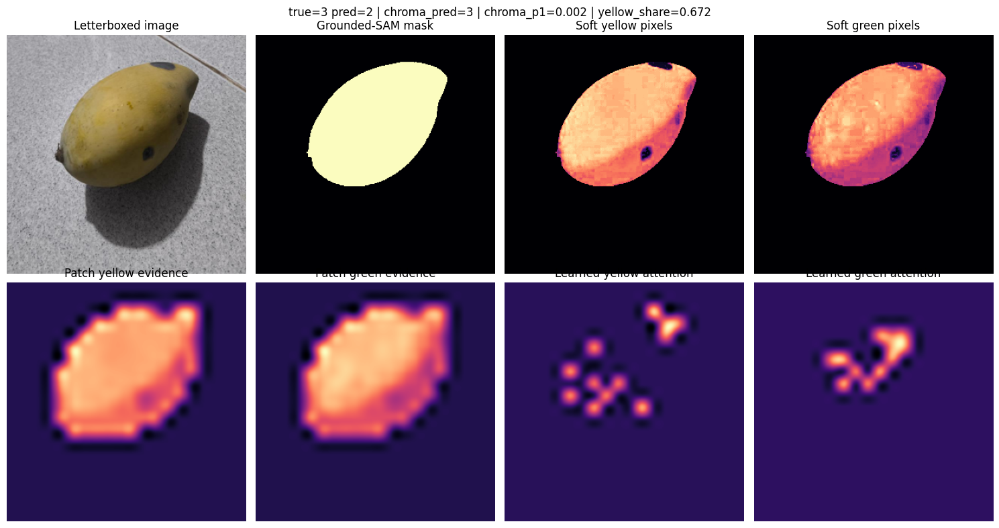

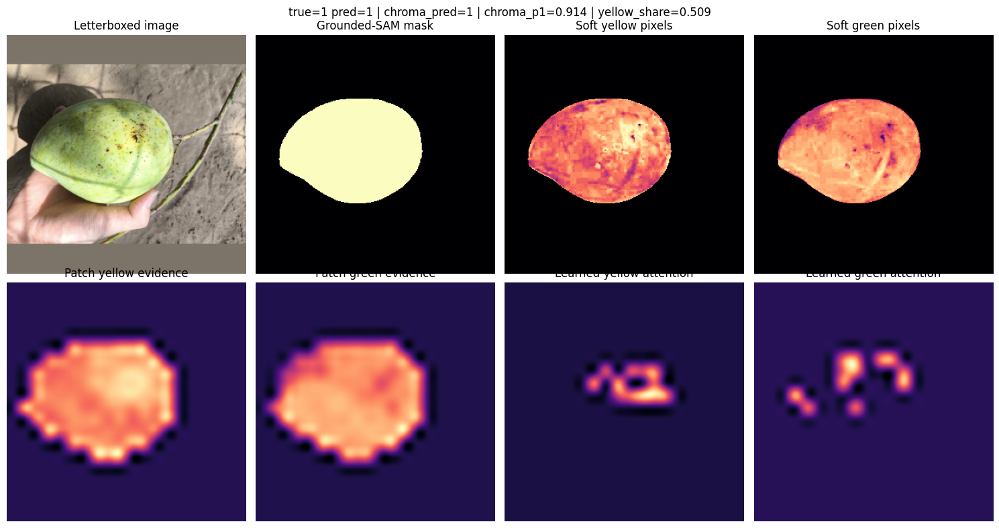

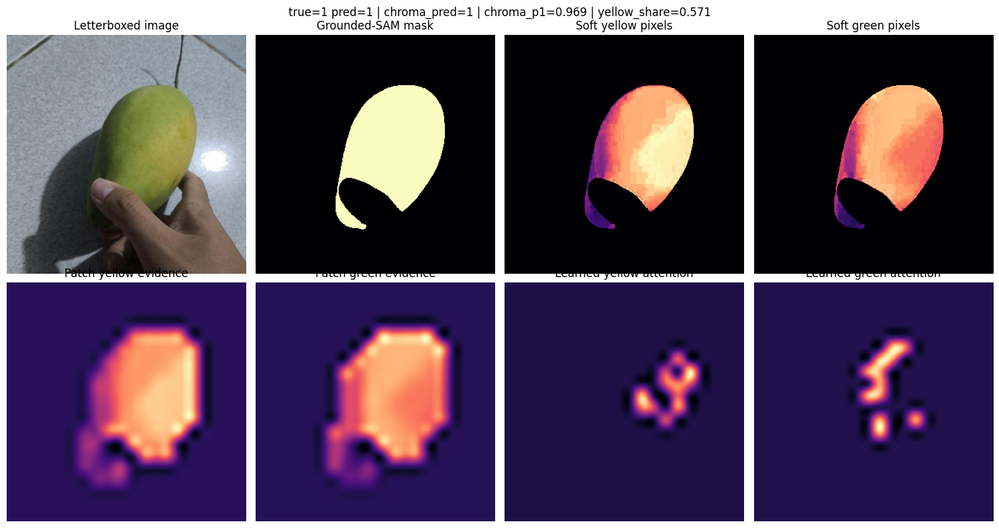

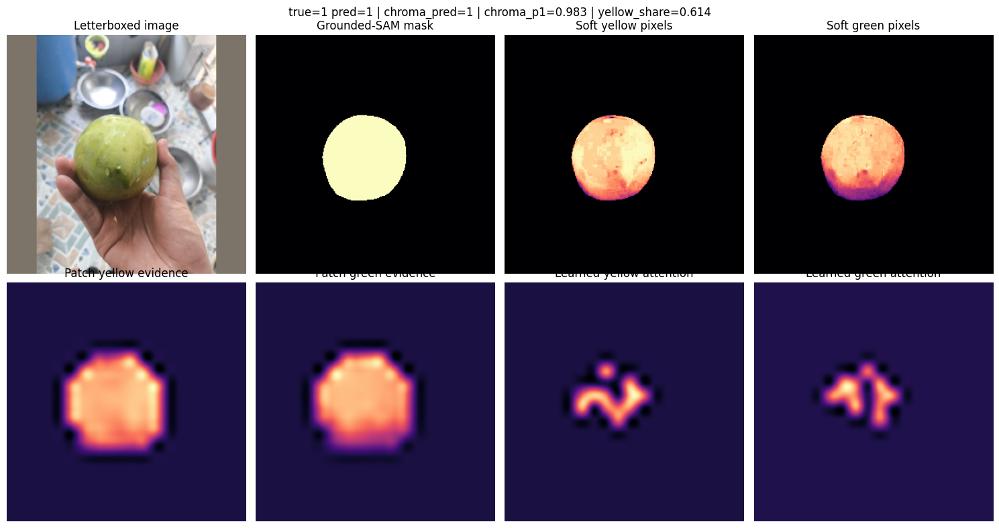

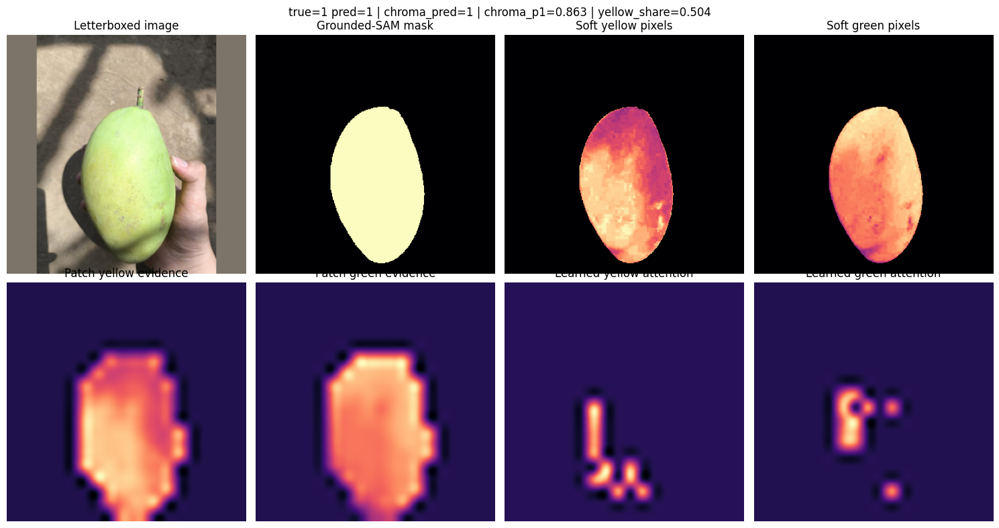

,rank,path,true_label,visual_prediction,chromatic_prediction,chromatic_class1_probability,yellow_mean,green_mean,yellow_share,output,status
0,0,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,2,2,0.242129,0.899919,0.570862,0.611865,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
1,1,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0.106983,0.649209,0.725575,0.472226,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
2,2,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0.364198,0.703708,0.716909,0.495354,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
3,3,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0.390373,0.742057,0.675429,0.523502,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
4,4,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,0,0,0.494342,0.509818,0.821629,0.382905,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
5,5,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Chin_N...,2,3,2,0.015890,0.882389,0.528172,0.625559,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
6,6,E:\kaggle\local\chat\data\xoaimoi8\Xoai_ChinGi...,3,2,2,0.003032,0.747594,0.350630,0.680730,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
7,7,E:\kaggle\local\chat\data\xoaimoi8\Xoai_ChinGi...,3,2,3,0.002358,0.733723,0.357933,0.672119,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
8,8,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,1,1,0.914184,0.722037,0.697529,0.508632,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok
9,9,E:\kaggle\local\chat\data\xoaimoi8\Xoai_Song_C...,1,1,1,0.968582,0.780161,0.586785,0.570733,E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMA...,ok


In [45]:
# ============================================================
# V18.5 CHROMATIC MICRO-EVIDENCE XAI
# ============================================================
if TASK_PROFILE == 'mango_advanced' and V185_CHROMA_XAI_MAX > 0:
    from torch.utils.data._utils.collate import default_collate

    def _v185_patch_heatmap(values):
        array = np.asarray(values, dtype=np.float32).reshape(GRID_SIZE, GRID_SIZE)
        return cv2.resize(
            array,
            (CFG.image_size, CFG.image_size),
            interpolation=cv2.INTER_CUBIC,
        )

    chroma_xai_rows = []
    candidates = errors_df.copy()
    correct_class1 = pred_df[
        (pred_df.label == 1) & pred_df.correct
    ].sort_values('confidence').head(4)
    candidates = pd.concat([candidates, correct_class1], ignore_index=True)
    candidates = candidates.drop_duplicates('path').head(V185_CHROMA_XAI_MAX)

    for rank, row in candidates.iterrows():
        try:
            dataset = MangoDataset(
                [str(row.path)], [int(row.label)], False, 18500 + rank
            )
            raw = default_collate([dataset[0]])
            batch = move(raw)
            model.eval()
            with torch.no_grad(), torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                output = model(
                    batch['pixel_values'],
                    batch['colour_stats'],
                    batch['patch_local_stats'],
                    batch['patch_mask'],
                    batch['mask_confidence'],
                    float(locked_inference.get('prior_mix', 0.0)),
                )
            image_array, mask_array = _v18_letterbox_arrays(str(row.path))
            rgb = image_array.astype(np.float32) / 255.0
            hsv = cv2.cvtColor(image_array, cv2.COLOR_RGB2HSV)
            yellow_pixel, green_pixel = _v185_soft_chroma_maps(rgb, hsv)
            yellow_pixel *= (mask_array > 89)
            green_pixel *= (mask_array > 89)
            patch_stats = raw['patch_local_stats'][0].numpy()
            yellow_patch = patch_stats[:, -CFG.chroma_patch_dim + 0]
            green_patch = patch_stats[:, -CFG.chroma_patch_dim + 4]
            yellow_attention = (
                output['chroma_yellow_attention'][0].float().cpu().numpy()
            )
            green_attention = (
                output['chroma_green_attention'][0].float().cpu().numpy()
            )
            chroma_probability = torch.softmax(
                output['chromatic_logits'].float(), 1
            )[0].cpu().numpy()

            figure, axes = plt.subplots(2, 4, figsize=(15, 8))
            panels = (
                ('Letterboxed image', image_array),
                ('Grounded-SAM mask', mask_array),
                ('Soft yellow pixels', yellow_pixel),
                ('Soft green pixels', green_pixel),
                ('Patch yellow evidence', _v185_patch_heatmap(yellow_patch)),
                ('Patch green evidence', _v185_patch_heatmap(green_patch)),
                ('Learned yellow attention', _v185_patch_heatmap(yellow_attention)),
                ('Learned green attention', _v185_patch_heatmap(green_attention)),
            )
            for axis, (title, panel) in zip(axes.ravel(), panels):
                axis.imshow(panel, cmap=None if panel.ndim == 3 else 'magma')
                axis.set_title(title)
                axis.axis('off')
            figure.suptitle(
                f"true={int(row.label)} pred={int(row.pred_label)} | "
                f"chroma_pred={int(chroma_probability.argmax())} | "
                f"chroma_p1={chroma_probability[1]:.3f} | "
                f"yellow_share={float(raw['colour_stats'][0,-3]):.3f}",
                fontsize=12,
            )
            figure.tight_layout()
            target = OUTPUT_DIR / 'figures' / f'v185_chroma_xai_{rank:02d}.jpg'
            figure.savefig(target, dpi=135, bbox_inches='tight')
            plt.show()
            plt.close(figure)
            chroma_xai_rows.append(
                {
                    'rank': rank,
                    'path': str(row.path),
                    'true_label': int(row.label),
                    'visual_prediction': int(row.pred_label),
                    'chromatic_prediction': int(chroma_probability.argmax()),
                    'chromatic_class1_probability': float(chroma_probability[1]),
                    'yellow_mean': float(raw['colour_stats'][0, -16]),
                    'green_mean': float(raw['colour_stats'][0, -9]),
                    'yellow_share': float(raw['colour_stats'][0, -3]),
                    'output': str(target),
                    'status': 'ok',
                }
            )
        except Exception as error:
            chroma_xai_rows.append(
                {
                    'rank': rank,
                    'path': str(row.path),
                    'status': 'failed_soft',
                    'error': f'{type(error).__name__}: {error}',
                }
            )
            warnings.warn(
                f'Chromatic XAI failed softly for {row.path}: '
                f'{type(error).__name__}: {error}'
            )
        finally:
            for name in ('dataset', 'raw', 'batch', 'output', 'figure'):
                globals().pop(name, None)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    chroma_xai_df = pd.DataFrame(chroma_xai_rows)
    chroma_xai_df.to_csv(
        OUTPUT_DIR / 'v185_chromatic_xai_manifest.csv', index=False
    )
    display(chroma_xai_df)
else:
    print('Chromatic XAI skipped.')


### V18 evidence attention and damage maps

In [46]:
if TASK_PROFILE=='mango_advanced' and V18_EVIDENCE_ENABLEE:
    # ============================================================
    # V18 EVIDENCE XAI — CLASS ATTENTION, RELATION SUPPORT, DAMAGE MAP
    # ============================================================
    def v18_evidence_xai(path,target):
        V18_FINAL_EVIDENCE_MODEL.to(DEVICE)
        f,o=_v18_evidence_descriptor(path);f=((f-V18_FINAL_EVIDENCE_MEAN)/V18_FINAL_EVIDENCE_STD).astype(np.float32);x=torch.from_numpy(f)[None].to(DEVICE);occ=torch.from_numpy(o)[None].to(DEVICE);V18_FINAL_EVIDENCE_MODEL.eval()
        with torch.no_grad():out=V18_FINAL_EVIDENCE_MODEL(x,occ)
        fine=out['fine_attention_mean'][0,:,target].cpu().numpy().reshape(V18_EVIDENCE_GRID,V18_EVIDENCE_GRID);rel=out['relation_attention'][0,:,target].cpu().numpy().reshape(V18_EVIDENCE_GRID,V18_EVIDENCE_GRID);damage=out['damage_map'][0].cpu().numpy().reshape(V18_EVIDENCE_GRID,V18_EVIDENCE_GRID);return fine,rel,damage
    V18_EVIDENCE_XAI_ROWS=[];V18_EVIDENCE_XAI_FAILURES=[]
    for n,row in enumerate(errors_df.reset_index(drop=True).itertuples(),1):
        try:
            fine,rel,damage=v18_evidence_xai(row.path,int(row.pred_label));image=V18_PAIR_CACHE[row.path][0] if row.path in V18_PAIR_CACHE else _v18_letterbox_arrays(row.path)[0];mask=(V18_PAIR_CACHE[row.path][1] if row.path in V18_PAIR_CACHE else _v18_letterbox_arrays(row.path)[1])/255.
            def ov(h):
                h=cv2.resize(h,(CFG.image_size,CFG.image_size),interpolation=cv2.INTER_CUBIC);h=(h-h.min())/(h.max()-h.min()+1e-8);col=cv2.applyColorMap(np.uint8(255*h),cv2.COLORMAP_JET)[:,:,::-1];return np.clip(.55*image+.45*col,0,255).astype(np.uint8)
            V18_EVIDENCE_XAI_ROWS.append({'path':row.path,'true_label':int(row.label),'pred_label':int(row.pred_label),'attention_inside':float((cv2.resize(fine,(CFG.image_size,CFG.image_size))*mask).sum()/max(cv2.resize(fine,(CFG.image_size,CFG.image_size)).sum(),1e-9)),'damage_max':float(damage.max())})
            fig,axes=plt.subplots(1,4,figsize=(14,3.7));panels=[('Image',image),('Class evidence attention',ov(fine)),('Critical relation support',ov(rel)),('Damage evidence',ov(damage))]
            for ax,(title,img) in zip(axes,panels):ax.imshow(img);ax.set_title(title);ax.axis('off')
            fig.suptitle(f'V18 true {int(row.label)} → pred {int(row.pred_label)} | {Path(row.path).name}');fig.tight_layout();fig.savefig(OUTPUT_DIR/f'v18_evidence_xai_{n:02d}_{Path(row.path).stem}.jpg',dpi=120,bbox_inches='tight',pil_kwargs={'quality':82,'optimize':True});plt.show();plt.close(fig)
        except Exception as exc:V18_EVIDENCE_XAI_FAILURES.append({'path':row.path,'error':f'{type(exc).__name__}: {exc}'})
    pd.DataFrame(V18_EVIDENCE_XAI_ROWS).to_csv(OUTPUT_DIR/'v18_evidence_xai.csv',index=False);pd.DataFrame(V18_EVIDENCE_XAI_FAILURES,columns=['path','error']).to_csv(OUTPUT_DIR/'v18_evidence_xai_failures.csv',index=False)

elif TASK_PROFILE == 'mango_advanced':
    pd.DataFrame(columns=['path', 'status', 'reason']).to_csv(
        OUTPUT_DIR / 'v18_evidence_xai_manifest.csv', index=False
    )
    print('Evidence XAI skipped: zero-correction stable mode.')
else:
    print('Skip mango-specific cell for generic profile.')


Evidence XAI skipped: zero-correction stable mode.


## 9. Runtime ledger, compact V17 artifacts and output-size guard

### V17.2 formula and late-cell safety receipt

In [47]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # FORMULA / LATE-CELL SAFETY RECEIPT
    # ============================================================
    logic_receipt = {
        'amp_api':'explicit torch.autocast + torch.amp.GradScaler',
        'amp_import_order_dependency':False,
        'grounding_fail_early_diagnostics':'grounding_dino_failures.csv',
        'sam_fail_early_diagnostics':'sam_runtime_failures.csv',
        'probability_bce_inside_autocast_remaining':
            0,
        'damage_top_formula': (
            'BCEWithLogits(logit(mean(sigmoid('
            'top_region_logits)))) with the '
            'model exposing damage_top_logit '
            'directly'
        ),
        'calibration_ema':
            'delta-only trainable parameters',
        'refit_ema':
            'delta-only trainable parameters',
        'frozen_backbone_xai': (
            'input.requires_grad=True; '
            'patch retain_grad is performed '
            'inside model collect_attention path'
        ),
        'rare_refit_skipped_when_validation_alpha_zero':
            not bool(
                float(
                    locked_rare.get(
                        'rare_alpha', 0
                    )
                ) > 0
                or float(
                    locked_rare.get(
                        'damage_alpha', 0
                    )
                ) > 0
            ),
        'calibration_epoch_policy': {
            'maximum':
                CFG.calibration_epochs,
            'minimum':
                CFG.calibration_min_epochs,
            'patience':
                CFG.calibration_patience,
            'selected_epochs':
                list(selected_epoch_set),
        },
        'mask_claim': (
            'No true mask accuracy is claimed '
            'without MANGO_MASK_AUDIT_ROOT '
            'human masks.'
        ),
    }
    json.dump(
        logic_receipt,
        open(
            OUTPUT_DIR
            / 'logic_safety_receipt.json',
            'w',
        ),
        indent=2,
    )
    print(
        json.dumps(
            logic_receipt,
            indent=2,
        )
    )
else:
    print('Skip mango-specific cell for generic profile.')


{
  "amp_api": "explicit torch.autocast + torch.amp.GradScaler",
  "amp_import_order_dependency": false,
  "grounding_fail_early_diagnostics": "grounding_dino_failures.csv",
  "sam_fail_early_diagnostics": "sam_runtime_failures.csv",
  "probability_bce_inside_autocast_remaining": 0,
  "damage_top_formula": "BCEWithLogits(logit(mean(sigmoid(top_region_logits)))) with the model exposing damage_top_logit directly",
  "calibration_ema": "delta-only trainable parameters",
  "refit_ema": "delta-only trainable parameters",
  "frozen_backbone_xai": "input.requires_grad=True; patch retain_grad is performed inside model collect_attention path",
  "rare_refit_skipped_when_validation_alpha_zero": true,
  "calibration_epoch_policy": {
    "maximum": 18,
    "minimum": 8,
    "patience": 8,
    "selected_epochs": [
      9
    ]
  },
  "mask_claim": "No true mask accuracy is claimed without MANGO_MASK_AUDIT_ROOT human masks."
}


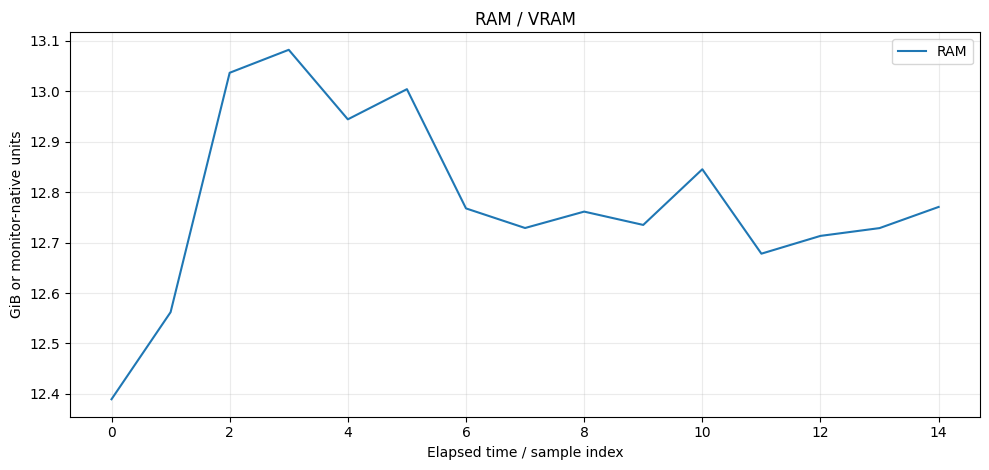

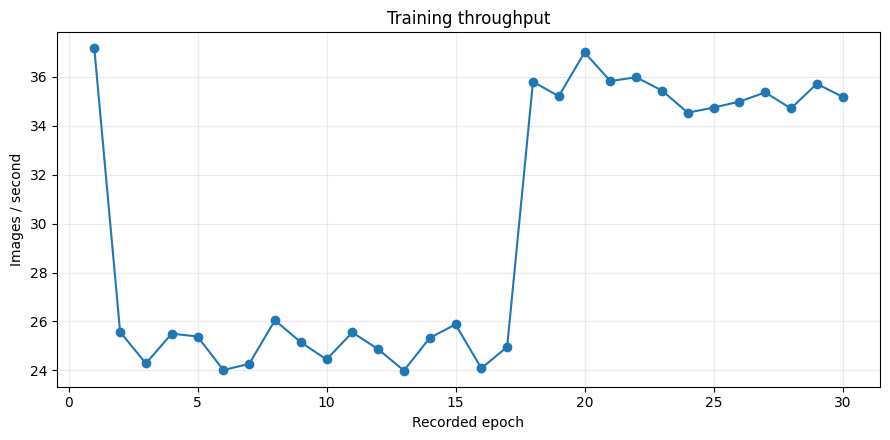

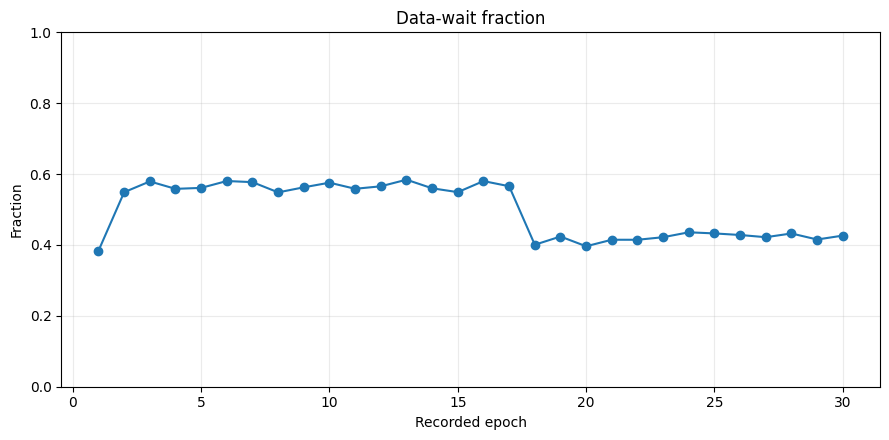

{
  "resource_source": "refit_resource_log.csv",
  "physical_batch": 32,
  "virtual_micro_batch": 2,
  "grad_accum": 1,
  "num_workers": 0,
  "ram_preload_active": true,
  "notes": [
    "Data wait is material; benchmark one process worker or increase RAM-preload threads, but keep a RAM guard.",
    "V18.2 computes the loss in virtual size-2 chunks after one larger CUDA forward, preserving the strong historical loss normalization."
  ],
  "mean_data_wait_fraction": 0.4967924245754186
}


In [48]:

# ============================================================
# V18.2 — PERFORMANCE / CAPACITY DASHBOARD
# ============================================================
try:
    resource_candidates = []
    if "resource_df" in globals() and isinstance(resource_df, pd.DataFrame):
        resource_candidates.append(("resource_df", resource_df.copy()))
    for csv_path in OUTPUT_DIR.glob("*resource*.csv"):
        try:
            resource_candidates.append(
                (str(csv_path.name), pd.read_csv(csv_path))
            )
        except Exception:
            pass

    selected_resource = None
    selected_source = None
    for source_name, frame in resource_candidates:
        lower_columns = {str(column).lower() for column in frame.columns}
        if any("gpu" in column for column in lower_columns) and len(frame):
            selected_resource = frame
            selected_source = source_name
            break

    recommendations = {
        "resource_source": selected_source,
        "physical_batch": int(globals().get("TRAIN_BATCH", 0)),
        "virtual_micro_batch": int(V182_VIRTUAL_MICRO_BATCH),
        "grad_accum": int(globals().get("GRAD_ACCUM", 0)),
        "num_workers": int(globals().get("ACTIVE_NUM_WORKERS", 0)),
        "ram_preload_active": bool(
            globals().get("RAM_PRELOAD_ENABLED", True)
        ),
        "notes": [],
    }

    if selected_resource is not None:
        frame = selected_resource.copy()
        column_lookup = {
            str(column).lower(): column for column in frame.columns
        }
        def find_column(*keywords):
            for lower_name, original_name in column_lookup.items():
                if all(keyword in lower_name for keyword in keywords):
                    return original_name
            return None

        time_column = (
            find_column("elapsed")
            or find_column("time")
            or find_column("timestamp")
        )
        cpu_column = find_column("cpu", "util") or find_column("cpu")
        gpu_column = find_column("gpu", "util")
        ram_column = (
            find_column("ram", "gib")
            or find_column("ram", "gb")
            or find_column("memory", "ram")
        )
        vram_column = (
            find_column("vram", "gib")
            or find_column("gpu", "memory")
            or find_column("vram")
        )

        x_axis = (
            pd.to_numeric(frame[time_column], errors="coerce")
            if time_column
            else np.arange(len(frame))
        )

        if cpu_column or gpu_column:
            fig, ax = plt.subplots(figsize=(10, 4.8))
            if cpu_column:
                ax.plot(
                    x_axis,
                    pd.to_numeric(frame[cpu_column], errors="coerce"),
                    label="CPU utilization",
                )
            if gpu_column:
                ax.plot(
                    x_axis,
                    pd.to_numeric(frame[gpu_column], errors="coerce"),
                    label="GPU utilization",
                )
            ax.set_title("CPU / GPU utilization")
            ax.set_xlabel("Elapsed time / sample index")
            ax.set_ylabel("Percent")
            ax.set_ylim(0, 105)
            ax.grid(alpha=0.25)
            ax.legend()
            fig.tight_layout()
            fig.savefig(
                OUTPUT_DIR / "v182_cpu_gpu_utilization.png",
                dpi=150,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)

        if ram_column or vram_column:
            fig, ax = plt.subplots(figsize=(10, 4.8))
            if ram_column:
                ax.plot(
                    x_axis,
                    pd.to_numeric(frame[ram_column], errors="coerce"),
                    label="RAM",
                )
            if vram_column:
                ax.plot(
                    x_axis,
                    pd.to_numeric(frame[vram_column], errors="coerce"),
                    label="VRAM",
                )
            ax.set_title("RAM / VRAM")
            ax.set_xlabel("Elapsed time / sample index")
            ax.set_ylabel("GiB or monitor-native units")
            ax.grid(alpha=0.25)
            ax.legend()
            fig.tight_layout()
            fig.savefig(
                OUTPUT_DIR / "v182_ram_vram.png",
                dpi=150,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)

        if gpu_column:
            mean_gpu = float(
                pd.to_numeric(frame[gpu_column], errors="coerce").mean()
            )
            recommendations["mean_gpu_utilization"] = mean_gpu
            if mean_gpu < 65:
                recommendations["notes"].append(
                    "GPU utilization is below 65%; prefer the largest "
                    "full-objective physical batch accepted by the probe."
                )
        if cpu_column:
            recommendations["mean_cpu_utilization"] = float(
                pd.to_numeric(frame[cpu_column], errors="coerce").mean()
            )

    histories = []
    for name in ("calibration_history", "calibration_training_history", "refit_history"):
        value = globals().get(name)
        if isinstance(value, pd.DataFrame) and len(value):
            histories.append(value.copy())
    if histories:
        performance = pd.concat(histories, ignore_index=True, sort=False)
        useful = [
            column
            for column in (
                "phase",
                "epoch",
                "train_images_per_second",
                "images_per_second",
                "train_data_wait_fraction",
                "data_wait_fraction",
                "train_epoch_seconds",
                "epoch_seconds",
            )
            if column in performance.columns
        ]
        if useful:
            performance[useful].to_csv(
                OUTPUT_DIR / "v182_epoch_performance.csv", index=False
            )
        throughput_column = next(
            (
                column
                for column in (
                    "train_images_per_second",
                    "images_per_second",
                )
                if column in performance.columns
            ),
            None,
        )
        wait_column = next(
            (
                column
                for column in (
                    "train_data_wait_fraction",
                    "data_wait_fraction",
                )
                if column in performance.columns
            ),
            None,
        )
        if throughput_column:
            fig, ax = plt.subplots(figsize=(9, 4.5))
            ax.plot(
                np.arange(1, len(performance) + 1),
                pd.to_numeric(
                    performance[throughput_column], errors="coerce"
                ),
                marker="o",
            )
            ax.set_title("Training throughput")
            ax.set_xlabel("Recorded epoch")
            ax.set_ylabel("Images / second")
            ax.grid(alpha=0.25)
            fig.tight_layout()
            fig.savefig(
                OUTPUT_DIR / "v182_training_throughput.png",
                dpi=150,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)
        if wait_column:
            fig, ax = plt.subplots(figsize=(9, 4.5))
            ax.plot(
                np.arange(1, len(performance) + 1),
                pd.to_numeric(performance[wait_column], errors="coerce"),
                marker="o",
            )
            ax.set_title("Data-wait fraction")
            ax.set_xlabel("Recorded epoch")
            ax.set_ylabel("Fraction")
            ax.set_ylim(0, 1)
            ax.grid(alpha=0.25)
            fig.tight_layout()
            fig.savefig(
                OUTPUT_DIR / "v182_data_wait_fraction.png",
                dpi=150,
                bbox_inches="tight",
            )
            plt.show()
            plt.close(fig)
            mean_wait = float(
                pd.to_numeric(
                    performance[wait_column], errors="coerce"
                ).mean()
            )
            recommendations["mean_data_wait_fraction"] = mean_wait
            if mean_wait < 0.15:
                recommendations["notes"].append(
                    "Data wait is already low; increasing Windows process "
                    "workers is unlikely to improve training."
                )
            else:
                recommendations["notes"].append(
                    "Data wait is material; benchmark one process worker or "
                    "increase RAM-preload threads, but keep a RAM guard."
                )

    recommendations["notes"].append(
        "V18.2 computes the loss in virtual size-2 chunks after one larger "
        "CUDA forward, preserving the strong historical loss normalization."
    )
    with open(
        OUTPUT_DIR / "v182_performance_recommendations.json",
        "w",
        encoding="utf-8",
    ) as stream:
        json.dump(recommendations, stream, indent=2, ensure_ascii=False)
    print(json.dumps(recommendations, indent=2, ensure_ascii=False))
except Exception as performance_error:
    warnings.warn(
        f"Performance dashboard failed softly: "
        f"{type(performance_error).__name__}: {performance_error}"
    )


In [49]:

# ============================================================
# V18.6 CHECKPOINT MANIFEST
# ============================================================
_checkpoint_rows = []
for _checkpoint_path in sorted(V184_CHECKPOINT_ROOT.glob("*")):
    if _checkpoint_path.is_file():
        _checkpoint_rows.append(
            {
                "file": _checkpoint_path.name,
                "path": str(_checkpoint_path),
                "bytes": _checkpoint_path.stat().st_size,
                "sha256": v184_file_sha256(
                    _checkpoint_path
                ),
            }
        )
pd.DataFrame(
    _checkpoint_rows,
    columns=["file", "path", "bytes", "sha256"],
).to_csv(
    OUTPUT_DIR / "v184_checkpoint_manifest.csv",
    index=False,
)
print("Persistent checkpoint directory:", V184_CHECKPOINT_ROOT)


pd.DataFrame(
    V184_CHECKPOINT_FAILURES,
    columns=["stage", "target", "error", "available_ram_gib"],
).to_csv(
    OUTPUT_DIR / "v184_checkpoint_failures.csv", index=False
)


pd.DataFrame(
    V184_JOBLIB_FAILURES,
    columns=["stage", "target", "error", "available_ram_gib"],
).to_csv(
    OUTPUT_DIR / "v184_joblib_failures.csv", index=False
)

pd.DataFrame(
    _checkpoint_rows,
    columns=["file", "path", "bytes", "sha256"],
).to_csv(
    OUTPUT_DIR / "v186_checkpoint_manifest.csv",
    index=False,
)
print("Run-local checkpoint directory:", V186_RUN_CHECKPOINT_ROOT)


Persistent checkpoint directory: E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\output\checkpoints
Run-local checkpoint directory: E:\kaggle\local\chat\runs\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\output\checkpoints


In [50]:

# ============================================================
# V18.6 TRAINING-BUDGET AND FINALIZATION RECEIPT
# ============================================================
if TASK_PROFILE == "mango_advanced":
    V186_TRAINING_RECEIPT = {
        "version": V186_VERSION,
        "calibration_ceiling": int(
            CFG.calibration_epochs
        ),
        "calibration_min_epochs": int(
            CFG.calibration_min_epochs
        ),
        "calibration_patience": int(
            CFG.calibration_patience
        ),
        "calibration_epochs_executed": int(
            globals().get(
                "CALIBRATION_EPOCHS_EXECUTED", 0
            )
        ),
        "selected_calibration_epochs": [
            int(value) for value in selected_epoch_set
        ],
        "requested_refit_extra_epochs": int(
            V184_REFIT_EXTRA_EPOCHS
        ),
        "refit_finalization": (
            V186_REFIT_FINALIZATION
        ),
        "refit_status": globals().get(
            "refit_status", {}
        ),
        "checkpoint_root": str(
            V186_RUN_CHECKPOINT_ROOT
        ),
        "persistent_mirror_root": str(
            V186_PERSISTENT_CHECKPOINT_ROOT
        ),
        "test_used_for_epoch_selection": False,
    }
    with open(
        OUTPUT_DIR
        / "v186_training_budget_receipt.json",
        "w",
        encoding="utf-8",
    ) as stream:
        json.dump(
            v186_json_safe(V186_TRAINING_RECEIPT),
            stream,
            indent=2,
            ensure_ascii=False,
        )
    print(json.dumps(
        v186_json_safe(V186_TRAINING_RECEIPT),
        indent=2,
        ensure_ascii=False,
    ))


{
  "version": "V18.6_CHROMATIC_RESCUE_SWA_CHECKPOINTED",
  "calibration_ceiling": 18,
  "calibration_min_epochs": 8,
  "calibration_patience": 8,
  "calibration_epochs_executed": 17,
  "selected_calibration_epochs": [
    9
  ],
  "requested_refit_extra_epochs": 4,
  "refit_finalization": "swa_selected_to_extended",
  "refit_status": {
    "status": "COMPLETED",
    "fallback_used": false,
    "selected_epochs": [
      9
    ],
    "requested_mode": "auto",
    "ram_cache_released": false,
    "cleanup_names_removed": [
      "bootstrap",
      "eligible",
      "mask_variant_cache",
      "plausible",
      "probabilities_by_name",
      "selected_rare_p"
    ],
    "calibration_selected_epoch": 9,
    "max_refit_epoch": 13,
    "requested_extra_epochs": 4,
    "refit_finalization": "swa_selected_to_extended",
    "refit_target_epoch_set": [
      9,
      10,
      11,
      12,
      13
    ],
    "calibration_fallback_saved": true,
    "attempt_refit": true,
    "decision_reason"

,stage,seconds,minutes
18,total_python,2110.769207,35.179487
4,04_calibration_training,1154.635939,19.243932
10,06_trainval_refit,651.936088,10.865601
6,05aa_class1_boundary_bias,100.648406,1.677473
16,09_nearest_neighbours,49.980467,0.833008
7,05ab_oof_boundary_specialists,42.285011,0.704750
5,05_validation_selection,21.731516,0.362192
17,10_xai,15.594214,0.259904
13,07_locked_test,13.549869,0.225831
2,03_mask_audit,2.683598,0.044727


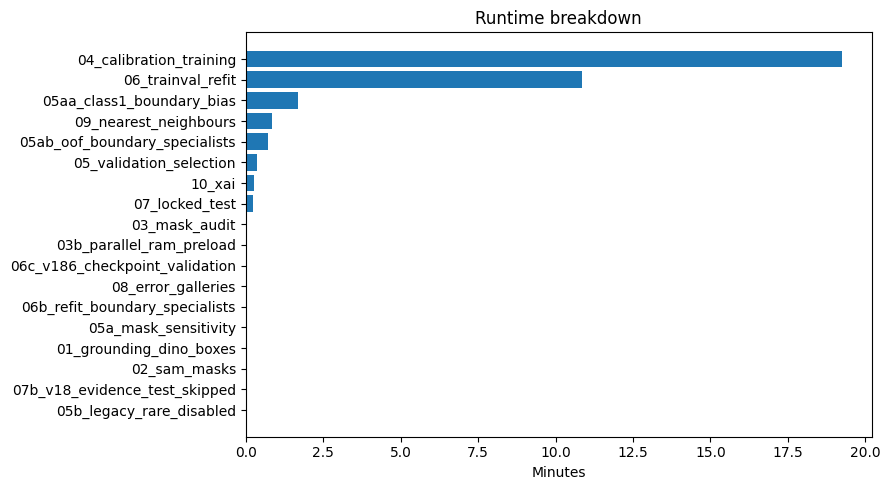

Final output size: 1490.2 MiB


E:\kaggle\local\chat\.local-runtime\temp\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\ipykernel_12060\1380500519.py:12: UserWarning: Output is 1490.2 MiB, above the local advisory guard 240 MiB.
  if size>CFG.output_guard_mib*1024**2:warnings.warn(f'Output is {size/1024**2:.1f} MiB, above the local advisory guard {CFG.output_guard_mib} MiB.')


,artifact,exists,bytes
0,v186_checkpoint_validation_receipt.json,True,4403
1,v186_training_budget_receipt.json,True,1988
2,v186_checkpoint_manifest.csv,True,2917
3,v184_pretrain_preflight.json,True,1428
4,v184_final_deployment_delta.pt,True,97011785
5,v184_deployment_manifest.json,True,2133
6,v184_boundary_specialists.joblib,True,1046
7,v184_specialist_lock.json,True,2174
8,v184_specialist_oof_selection.csv,True,2563
9,v184_specialist_validation_grid.csv,True,74871


{
  "version": "V18.6_CHROMATIC_RESCUE_SWA_CHECKPOINTED",
  "status": "NON_COMPARABLE_DATASET_VARIANT",
  "missing_artifacts": [],
  "internal_test_reused_across_versions": true,
  "external_test_evaluated": false,
  "split_sha256": "e1c8b17af4eb14602348c05df7e025bb10b9d9019617840e067422a16b769de2",
  "split_guard_status": "NON_CANONICAL_DATASET",
  "locked_selection": {
    "name": "p0.0_main_0.0_0.0_0.0",
    "prior_mix": 0.0,
    "blend_mode": "main",
    "alpha01": 0.0,
    "alpha12": 0.0,
    "alpha23": 0.0,
    "complexity": 0,
    "accuracy": 0.9357142857142857,
    "balanced_accuracy": 0.8560850178014358,
    "macro_f1": 0.8814326513209394,
    "weighted_f1": 0.9320482487957532,
    "class1_precision": 1.0,
    "class1_recall": 0.46153846153846156,
    "class1_f1": 0.631578947368421,
    "class4_precision": 0.9873417721518988,
    "class4_recall": 0.975,
    "class4_f1": 0.9811320754716981,
    "min_class_f1": 0.631578947368421,
    "mae": 0.08928571428571429,
    "nll": 0.2000

In [51]:
if TASK_PROFILE=='mango_advanced':
    # ============================================================
    # FINAL ARTIFACTS, RUNTIME AND OUTPUT-SIZE GUARD
    # ============================================================
    STAGE_TIMES['total_python']=time.perf_counter()-RUN_STARTED
    runtime_df=pd.DataFrame([{'stage':k,'seconds':v,'minutes':v/60} for k,v in STAGE_TIMES.items()]).sort_values('seconds',ascending=False);runtime_df.to_csv(OUTPUT_DIR/'runtime_breakdown.csv',index=False);display(runtime_df)
    fig,ax=plt.subplots(figsize=(9,5));z=runtime_df[runtime_df.stage!='total_python'].sort_values('seconds');ax.barh(z.stage,z.minutes);ax.set_xlabel('Minutes');ax.set_title('Runtime breakdown');fig.tight_layout();fig.savefig(OUTPUT_DIR/'runtime_breakdown.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
    # Remove runtime-only snapshots before local finalization.
    for p in TEMP_DIR.glob('calibration_ep*.pt'):p.unlink(missing_ok=True)
    def directory_bytes(root):return sum(p.stat().st_size for p in Path(root).rglob('*') if p.is_file())
    size=directory_bytes(OUTPUT_DIR);print(f'Final output size: {size/1024**2:.1f} MiB')
    if size>CFG.output_guard_mib*1024**2:warnings.warn(f'Output is {size/1024**2:.1f} MiB, above the local advisory guard {CFG.output_guard_mib} MiB.')
    required=['v186_checkpoint_validation_receipt.json', 'v186_training_budget_receipt.json', 'v186_checkpoint_manifest.csv', 'v184_pretrain_preflight.json', 'v184_final_deployment_delta.pt', 'v184_deployment_manifest.json', 'v184_boundary_specialists.joblib', 'v184_specialist_lock.json', 'v184_specialist_oof_selection.csv', 'v184_specialist_validation_grid.csv', 'v184_checkpoint_manifest.csv', 'dataset_inventory_v184.csv', 'locked_rare_selection.json', 'refit_status.json', 'refit_resource_log.csv', 'mask_accuracy_status.json', 'mask_review_queue.csv', 'validation_mask_perturbation_audit.csv', 'mask_sensitivity_receipt.json', 'logic_safety_receipt.json', 'validation_rare_mil_grid.csv', 'validation_rare_component_ledger.csv', 'validation_rare_mil_diagnostics.csv', 'dataset_variant_status.json', 'split_comparability_receipt.json', 'refit_lock_receipt.json', 'internal_test_component_ledger.csv', 'internal_test_overall_metrics.csv', 'internal_test_classification_report.csv', 'internal_test_confusion_matrix.npy', 'calibration_training_history.csv', 'curve_loss.png', 'curve_accuracy.png', 'curve_f1.png', 'confusion_matrix_counts.png', 'confusion_matrix_row_normalized.png', 'per_class_metrics.png', 'internal_test_predictions.csv', 'internal_test_misclassifications.csv', 'runtime_breakdown.csv', 'locked_validation_selection.json', 'validation_class1_boundary_bias.csv', 'v183_contract_tests.json']
    manifest=[]
    for name in requireE:
        p=OUTPUT_DIR/name;manifest.append({'artifact':name,'exists':p.exists(),'bytes':p.stat().st_size if p.exists() else 0})
    manifest_df=pd.DataFrame(manifest);manifest_df.to_csv(OUTPUT_DIR/'artifact_manifest.csv',index=False);display(manifest_df)
    _noncomp=('NON_COMPARABLE_SPLIT' if dataset_status.get('dataset_is_canonical') else 'NON_COMPARABLE_DATASET_VARIANT');missing=manifest_df.loc[~manifest_df.exists,'artifact'].tolist();release={'version':V1841_VERSION,'status':('READY_INTERNAL_DEVELOPMENT_ONLY' if dataset_status['comparable_to_v15'] else _noncomp) if not missing else 'NOT_READY','missing_artifacts':missing,'internal_test_reused_across_versions':True,'external_test_evaluated':bool(external_status.get('evaluated',False)),'split_sha256':SPLIT_REGISTRY_SHA256,'split_guard_status':dataset_status.get('split_guard_status'),'locked_selection':locked_inference,'locked_rare':locked_rare,'output_mib':size/1024**2,'runtime_minutes':STAGE_TIMES['total_python']/60}
    json.dump(release,open(OUTPUT_DIR/'release_status.json','w'),indent=2);print(json.dumps(release,indent=2))


    print('\nLocal run directory:', OUTPUT_DIR.resolve())
    print('Persistent mask cache:', MASK_CACHE_DIR.resolve())
    # Remove only transient training files. The deterministic mask cache remains reusable.
    try:
        shutil.rmtree(TEMP_DIR, ignore_errors=True)
    except Exception as exc:
        warnings.warn(f'Could not remove TEMP_DIR: {exc}')

else:
    print('Skip mango-specific cell for generic profile.')


## 10. V18 performance dashboard, resource charts and compact release

### Dataset/method comparability receipt

In [52]:
V18_COMPARABILITY_RECEIPT={
    'dataset_id':DATASET_ID,
    'dataset_root':str(dataset_root),
    'task_profile':TASK_PROFILE,
    'num_classes':int(NUM_CLASSES),
    'class_names':{str(k):str(v) for k,v in CLASS_SEMANTICS.items()},
    'split_sha256':str(SPLIT_REGISTRY_SHA256),
    'split_registry_reused':bool(globals().get('SPLIT_REGISTRY_REUSED',False)),
    'split_registry_match_audit':globals().get('SPLIT_REGISTRY_MATCH_AUDIT',{}),
    'split_guard_status':dataset_status.get('split_guard_status'),
    'expected_historical_v15_split_sha256':dataset_status.get('expected_historical_v15_split_sha256'),
    'canonical_split_hash_match':bool(dataset_status.get('canonical_split_hash_match',False)),
    'directly_comparable_to_v15':bool(dataset_status.get('comparable_to_v15',False)),
    'dataset_root_selection_source':globals().get('DATASET_ROOT_SELECTION_SOURCE','UNKNOWN'),
    'dataset_is_canonical_mango':bool(globals().get('DATASET_IS_CANONICAL',False)),
    'object_prompt':OBJECT_PROMPT,
    'prompt_source':PROMPT_INFERENCE_SOURCE,
    'visual_architecture':'ViT-B/16 + REG4 + mask/part/query route',
    'legacy_rare_branch_used':False if TASK_PROFILE=='mango_advanced' else None,
    'v18_evidence_correction_enabled':bool(globals().get('V18_EVIDENCE_ENABLED',False)) if TASK_PROFILE=='mango_advanced' else None,
    'internal_test_reused_across_mango_versions':True if TASK_PROFILE=='mango_advanced' else False,
}
json.dump(V18_COMPARABILITY_RECEIPT,open(OUTPUT_DIR/'v18_comparability_receipt.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
print(json.dumps(V18_COMPARABILITY_RECEIPT,indent=2,ensure_ascii=False))


{
  "dataset_id": "xoaimoi8",
  "dataset_root": "E:\\kaggle\\local\\chat\\data\\xoaimoi8",
  "task_profile": "mango_advanced",
  "num_classes": 5,
  "class_names": {
    "0": "Xoài sống, chua, khó đập",
    "1": "Xoài sống, chua nhẹ, có nguy cơ",
    "2": "Xoài chín, ngọt thanh, dễ đập",
    "3": "Xoài chín già, ngọt gắt, không vận chuyển",
    "4": "Xoài hư, không ăn được"
  },
  "split_sha256": "e1c8b17af4eb14602348c05df7e025bb10b9d9019617840e067422a16b769de2",
  "split_registry_reused": true,
  "split_registry_match_audit": {
    "status": "REUSED_CONTENT_HASH_REGISTRY",
    "registry": "E:\\kaggle\\local\\chat\\.cache\\classifier_split_registry\\xoaimoi8.csv",
    "registry_rows": 1855,
    "current_rows": 1855,
    "exact_hash_relative_matches": 1855,
    "unique_hash_matches": 0,
    "new_or_ambiguous_to_train": 0,
    "missing_holdout_classes": []
  },
  "split_guard_status": "NON_CANONICAL_DATASET",
  "expected_historical_v15_split_sha256": "bb8a9152d1f6744952eccff3aadde77926e2

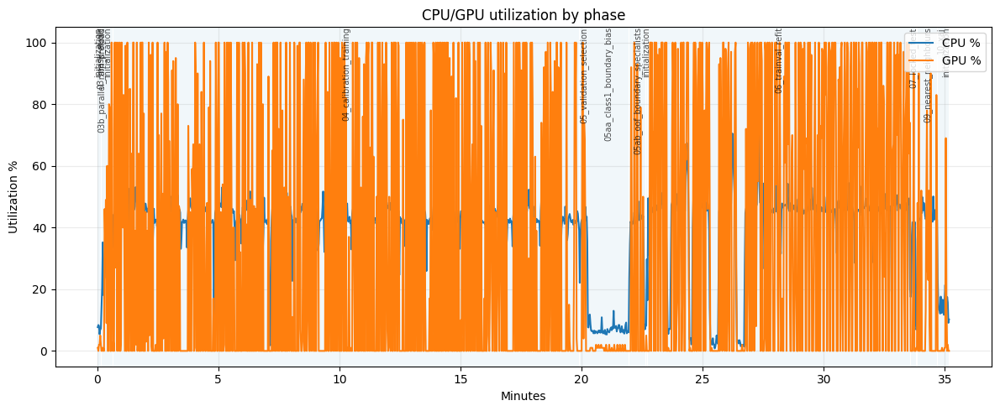

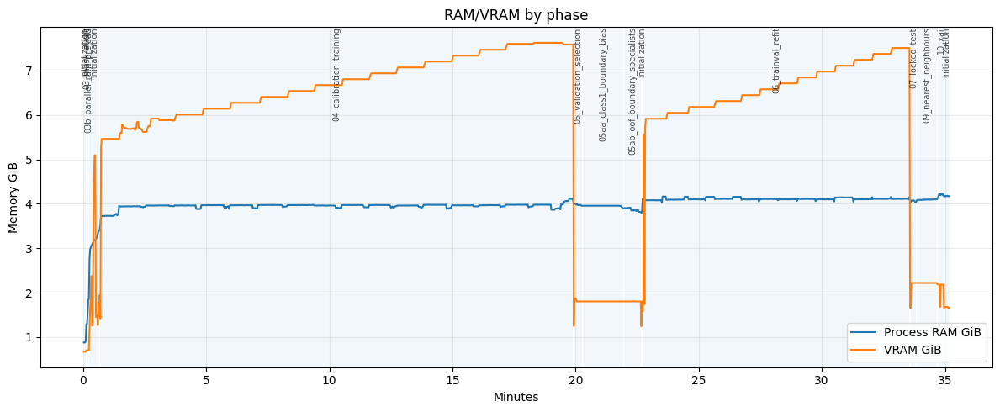

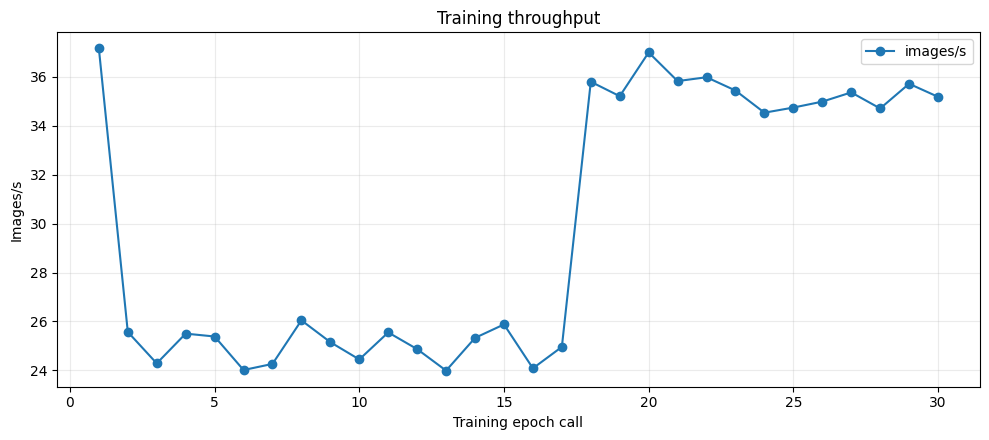

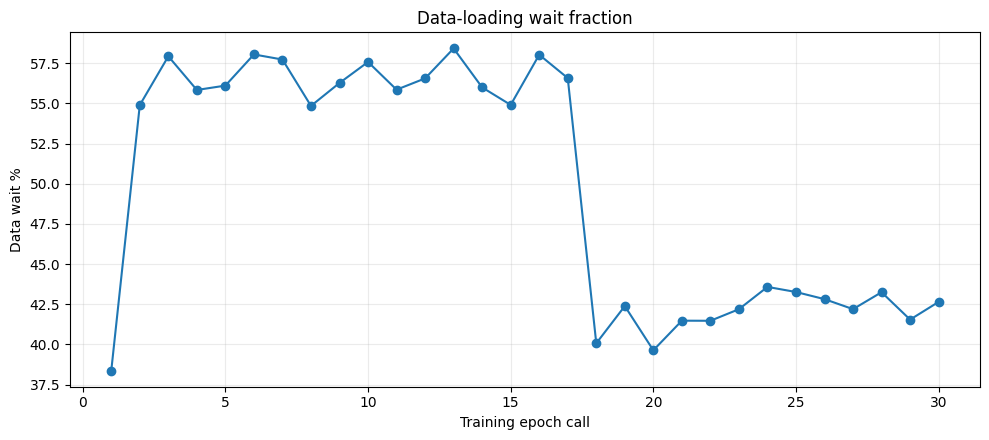

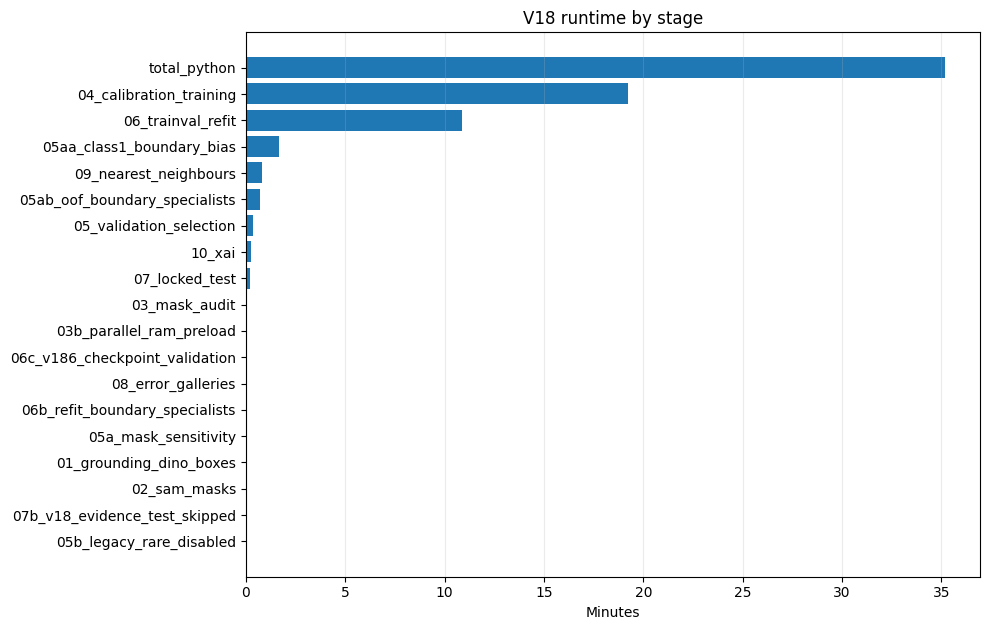

V18 output=1490.87 MiB
{
  "profile": "mango_advanced",
  "accuracy": 0.9708029197080292,
  "macro_f1": 0.9345722264534146,
  "class1_f1": 0.7619047619047619,
  "class4_f1": 1.0,
  "mae": 0.029197080291970802,
  "errors": 8,
  "n": 274,
  "locked_visual": {
    "name": "p0.0_main_0.0_0.0_0.0",
    "prior_mix": 0.0,
    "blend_mode": "main",
    "alpha01": 0.0,
    "alpha12": 0.0,
    "alpha23": 0.0,
    "complexity": 0,
    "accuracy": 0.9357142857142857,
    "balanced_accuracy": 0.8560850178014358,
    "macro_f1": 0.8814326513209394,
    "weighted_f1": 0.9320482487957532,
    "class1_precision": 1.0,
    "class1_recall": 0.46153846153846156,
    "class1_f1": 0.631578947368421,
    "class4_precision": 0.9873417721518988,
    "class4_recall": 0.975,
    "class4_f1": 0.9811320754716981,
    "min_class_f1": 0.631578947368421,
    "mae": 0.08928571428571429,
    "nll": 0.20002599085662096,
    "ece": 0.026038370434493596,
    "temperature": 1.1,
    "bootstrap_macro_mean": 0.0,
    "bootst

E:\kaggle\local\chat\.local-runtime\temp\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\ipykernel_12060\389572796.py:129: UserWarning: Output is 1490.9 MiB, above advisory guard 240 MiB; local execution continues.
  if total_bytes>CFG.output_guard_mib*1024**2:warnings.warn(f'Output is {total_bytes/1024**2:.1f} MiB, above advisory guard {CFG.output_guard_mib} MiB; local execution continues.')


,stage,seconds,minutes
19,total_python_v18,2112.284701,35.204745
18,total_python,2110.769207,35.179487
4,04_calibration_training,1154.635939,19.243932
10,06_trainval_refit,651.936088,10.865601
6,05aa_class1_boundary_bias,100.648406,1.677473
16,09_nearest_neighbours,49.980467,0.833008
7,05ab_oof_boundary_specialists,42.285011,0.704750
5,05_validation_selection,21.731516,0.362192
17,10_xai,15.594214,0.259904
13,07_locked_test,13.549869,0.225831


In [53]:
# ============================================================
# V18 COMMON FINALIZATION — BOTH MANGO AND GENERIC PROFILES
# ============================================================
V18_CURRENT_STAGE='finalization';V18_RESOURCE_STOP.set()
try:V18_RESOURCE_THREAD.join(timeout=10)
except Exception:pass
resource_df=pd.DataFrame(V18_RESOURCE_ROWS);resource_df.to_csv(OUTPUT_DIR/'v18_resource_monitor.csv',index=False)

if len(resource_df):
    quantile_rows = []
    for stage, frame in resource_df.groupby(
        "stage", dropna=False
    ):
        row = {
            "stage": stage,
            "samples": len(frame),
        }
        for column in (
            "cpu_percent",
            "gpu_util_percent",
            "process_ram_mib",
            "system_ram_percent",
            "vram_used_mib",
            "vram_allocated_mib",
            "gpu_temp_c",
            "gpu_power_w",
        ):
            if column not in frame.columns:
                continue
            values = pd.to_numeric(
                frame[column],
                errors="coerce",
            ).dropna()
            if len(values):
                row[column + "_mean"] = values.mean()
                row[column + "_p10"] = values.quantile(.10)
                row[column + "_p50"] = values.quantile(.50)
                row[column + "_p90"] = values.quantile(.90)
        if "gpu_util_percent" in frame.columns:
            gpu = pd.to_numeric(
                frame["gpu_util_percent"],
                errors="coerce",
            ).dropna()
            if len(gpu):
                row["gpu_duty_ge80"] = float(
                    (gpu >= 80).mean()
                )
                row["gpu_duty_ge90"] = float(
                    (gpu >= 90).mean()
                )
        quantile_rows.append(row)
    resource_quantiles_df = pd.DataFrame(
        quantile_rows
    )
    resource_quantiles_df.to_csv(
        OUTPUT_DIR
        / "v183_resource_stage_quantiles.csv",
        index=False,
    )
else:
    resource_quantiles_df = pd.DataFrame()
if len(resource_df):
    agg={}
    for col in ('cpu_percent','gpu_util_percent','process_ram_mib','vram_used_mib','vram_allocated_mib','gpu_temp_c','gpu_power_w'):
        if col in resource_df.columns:agg[col]=['mean','max']
    resource_by_stage=resource_df.groupby('stage',dropna=False).agg(agg) if agg else pd.DataFrame()
    if len(resource_by_stage):resource_by_stage.columns=['_'.join(x) for x in resource_by_stage.columns];resource_by_stage.reset_index().to_csv(OUTPUT_DIR/'v18_resource_by_stage.csv',index=False)
else:resource_by_stage=pd.DataFrame()

def _v18_spans(ax,df):
    if df.empty or 'stage' not in df:return
    stages=df.stage.astype(str).tolist();times=df.time_s.to_numpy();start=0
    for i in range(1,len(df)+1):
        if i==len(df) or stages[i]!=stages[start]:
            if i-start>=2:ax.axvspan(times[start],times[i-1],alpha=.06);ax.text((times[start]+times[i-1])/2,ax.get_ylim()[1],stages[start],rotation=90,va='top',ha='center',fontsize=7,alpha=.7)
            start=i
if len(resource_df):
    fig,ax=plt.subplots(figsize=(12,5));
    if 'cpu_percent' in resource_df:ax.plot(resource_df.time_s/60,resource_df.cpu_percent,label='CPU %')
    if 'gpu_util_percent' in resource_df:ax.plot(resource_df.time_s/60,resource_df.gpu_util_percent,label='GPU %')
    ax.set(xlabel='Minutes',ylabel='Utilization %',title='CPU/GPU utilization by phase');ax.legend();ax.grid(alpha=.25);_v18_spans(ax,resource_df.assign(time_s=resource_df.time_s/60));fig.tight_layout();fig.savefig(OUTPUT_DIR/'v18_cpu_gpu_utilization.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
    fig,ax=plt.subplots(figsize=(12,5));
    if 'process_ram_mib' in resource_df:ax.plot(resource_df.time_s/60,resource_df.process_ram_mib/1024,label='Process RAM GiB')
    if 'vram_used_mib' in resource_df:ax.plot(resource_df.time_s/60,resource_df.vram_used_mib/1024,label='VRAM GiB')
    elif 'vram_allocated_mib' in resource_df:ax.plot(resource_df.time_s/60,resource_df.vram_allocated_mib/1024,label='VRAM allocated GiB')
    ax.set(xlabel='Minutes',ylabel='Memory GiB',title='RAM/VRAM by phase');ax.legend();ax.grid(alpha=.25);_v18_spans(ax,resource_df.assign(time_s=resource_df.time_s/60));fig.tight_layout();fig.savefig(OUTPUT_DIR/'v18_ram_vram.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
if 'V18_TRAIN_PERF_ROWS' in globals() and len(V18_TRAIN_PERF_ROWS):
    perf_df=pd.DataFrame(V18_TRAIN_PERF_ROWS);perf_df.to_csv(OUTPUT_DIR/'v18_epoch_performance.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(np.arange(1,len(perf_df)+1),perf_df.images_per_second,marker='o',label='images/s');ax.set(xlabel='Training epoch call',ylabel='Images/s',title='Training throughput');ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUTPUT_DIR/'v18_training_throughput.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(np.arange(1,len(perf_df)+1),100*perf_df.data_wait_fraction,marker='o');ax.set(xlabel='Training epoch call',ylabel='Data wait %',title='Data-loading wait fraction');ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUTPUT_DIR/'v18_data_wait.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
STAGE_TIMES['total_python_v18']=time.perf_counter()-RUN_STARTED
stage_df=pd.DataFrame([{'stage':k,'seconds':v,'minutes':v/60} for k,v in STAGE_TIMES.items()]).sort_values('seconds',ascending=False);stage_df.to_csv(OUTPUT_DIR/'v18_runtime_breakdown.csv',index=False)
fig,ax=plt.subplots(figsize=(10,max(4,.32*len(stage_df))));q=stage_df[stage_df.stage!='total_python_v18'].sort_values('seconds');ax.barh(q.stage,q.minutes);ax.set(xlabel='Minutes',title='V18 runtime by stage');ax.grid(axis='x',alpha=.25);fig.tight_layout();fig.savefig(OUTPUT_DIR/'v18_runtime_breakdown.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
def _v18_json_safe(value):
    if isinstance(value,dict):return {str(k):_v18_json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple,set)):return [_v18_json_safe(v) for v in value]
    if isinstance(value,Path):return str(value)
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,np.generic):return value.item()
    if isinstance(value,pd.Timestamp):return value.isoformat()
    if value is pd.NA:return None
    if isinstance(value,float) and not np.isfinite(value):return None
    return value

if TASK_PROFILE=='mango_advanced':
    V18_FINAL_SUMMARY={'profile':TASK_PROFILE,'accuracy':float(test_m['accuracy']),'macro_f1':float(test_m['macro_f1']),'class1_f1':float(test_m['class1_f1']),'class4_f1':float(test_m['class4_f1']),'mae':float(test_m['mae']),'errors':int((test_pred!=test_y).sum()),'n':int(len(test_y)),'locked_visual':locked_inference,'locked_legacy_rare':locked_rare,'locked_v18_evidence':V18_LOCKED_EVIDENCE}
if 'V18_FINAL_SUMMARY' not in globals():
    V18_FINAL_SUMMARY={'profile':TASK_PROFILE,'status':'summary_unavailable'}
V18_FINAL_SUMMARY.update({'version':V1841_VERSION,'dataset_id':DATASET_ID,'dataset_root':str(dataset_root),'num_classes':NUM_CLASSES,'class_names':CLASS_SEMANTICS,'object_prompt':OBJECT_PROMPT,'prompt_source':PROMPT_INFERENCE_SOURCE,'split_sha256':SPLIT_REGISTRY_SHA256,'split_guard_status':dataset_status.get('split_guard_status'),'directly_comparable_to_v15':bool(dataset_status.get('comparable_to_v15',False)),'ram_preload':V18_PAIR_CACHE_STATUS,'active_num_workers':int(globals().get('ACTIVE_NUM_WORKERS',0)),'worker_probe':_v18_json_safe(globals().get('worker_probe_df',pd.DataFrame()).to_dict('records') if 'worker_probe_df' in globals() else []),'microbatch_probe':_v18_json_safe(globals().get('microbatch_probe_df',pd.DataFrame()).to_dict('records') if 'microbatch_probe_df' in globals() else []),'evalbatch_probe':_v18_json_safe(globals().get('evalbatch_probe_df',pd.DataFrame()).to_dict('records') if 'evalbatch_probe_df' in globals() else []),'prompt_detection_audit':_v18_json_safe(globals().get('_prompt_audit',{})),'train_batch':int(globals().get('TRAIN_BATCH',LOCAL_MICRO_BATCH)),'grad_accum':int(globals().get('GRAD_ACCUM',LOCAL_GRAD_ACCUM)),'total_minutes':STAGE_TIMES['total_python_v18']/60,'mask_accuracy_status':globals().get('mask_accuracy_status',{'status':'unavailable'})})
V18_FINAL_SUMMARY=_v18_json_safe(V18_FINAL_SUMMARY)
json.dump(V18_FINAL_SUMMARY,open(OUTPUT_DIR/'v18_evaluation_summary.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
# Automated performance interpretation for the next local run.
recommendations=[]
if len(resource_df):
    gpu_mean=float(resource_df.gpu_util_percent.dropna().mean()) if 'gpu_util_percent' in resource_df and resource_df.gpu_util_percent.notna().any() else None
    vram_peak=float(resource_df.vram_used_mib.dropna().max()/1024) if 'vram_used_mib' in resource_df and resource_df.vram_used_mib.notna().any() else None
    if gpu_mean is not None and gpu_mean<70:recommendations.append('GPU utilization below 70%: inspect data_wait and profiler; RAM preload/worker probe or larger safe batch may help.')
    if vram_peak is not None and vram_peak<LOCAL_TOTAL_VRAM_GIB*.75:recommendations.append('VRAM peak below 75%: inspect the measured microbatch_autotune.csv; do not raise batch solely to fill memory.')
if 'perf_df' in globals() and len(perf_df):
    dw=float(perf_df.data_wait_fraction.mean())
    if dw>.10:recommendations.append('Mean data-wait exceeds 10%: keep RAM preload and consider workers=2 only when the measured probe is faster.')
if not recommendations:recommendations.append('No obvious utilization bottleneck was detected by the low-overhead monitor.')
json.dump({'recommendations':recommendations,'profile':TASK_PROFILE},open(OUTPUT_DIR/'v18_performance_recommendations.json','w',encoding='utf-8'),indent=2,ensure_ascii=False)
# Manifest and output guard.
manifest=[]
for fp in sorted(OUTPUT_DIR.rglob('*')):
    if fp.is_file():manifest.append({'file':str(fp.relative_to(OUTPUT_DIR)),'bytes':fp.stat().st_size,'sha256':hashlib.sha256(fp.read_bytes()).hexdigest()})
manifest_df=pd.DataFrame(manifest);manifest_df.to_csv(OUTPUT_DIR/'v18_artifact_manifest.csv',index=False);total_bytes=sum(x['bytes'] for x in manifest);print(f'V18 output={total_bytes/1024**2:.2f} MiB')
if total_bytes>CFG.output_guard_mib*1024**2:warnings.warn(f'Output is {total_bytes/1024**2:.1f} MiB, above advisory guard {CFG.output_guard_mib} MiB; local execution continues.')
print(json.dumps(V18_FINAL_SUMMARY,indent=2,ensure_ascii=False));display(stage_df)


In [54]:
# ============================================================
# V18.6 FINAL SCIENTIFIC RECEIPT
# ============================================================
V185_FINAL_RECEIPT = {
    'version': V185_VERSION,
    'protected_visual_fallback_available': True,
    'chromatic_branch_enabled': bool(V185_ENABLE_CHROMATIC_BRANCH),
    'chromatic_branch_uses_detached_visual_tokens': True,
    'adapter_layers': list(CFG.adapter_layers),
    'adapter_bottleneck': int(CFG.adapter_dim),
    'colour_descriptor_dimensions': {
        'legacy': int(CFG.legacy_colour_stat_dim),
        'chromatic': int(CFG.chroma_global_dim),
        'total': int(CFG.colour_stat_dim),
    },
    'patch_descriptor_dimensions': {
        'legacy': int(CFG.patch_local_stat_dim - CFG.chroma_patch_dim),
        'chromatic': int(CFG.chroma_patch_dim),
        'total': int(CFG.patch_local_stat_dim),
    },
    'calibration_policy': {
        'ceiling': int(CFG.calibration_epochs),
        'minimum': int(CFG.calibration_min_epochs),
        'patience': int(CFG.calibration_patience),
        'blind_epoch_doubling': False,
    },
    'split_policy': 'frozen_content_hash_registry',
    'checkpoint_root': str(V184_CHECKPOINT_ROOT),
    'compatibility_artifact_prefix': 'v184',
    'compatibility_note': (
        'Some artifact filenames retain the v184 prefix so downstream local '
        'tools remain compatible; release/version metadata is V18.5.'
    ),
}
json.dump(
    V185_FINAL_RECEIPT,
    open(OUTPUT_DIR / 'v185_final_scientific_receipt.json', 'w', encoding='utf-8'),
    indent=2,
    ensure_ascii=False,
)
print(json.dumps(V185_FINAL_RECEIPT, indent=2, ensure_ascii=False))


# Reconcile inherited compatibility manifests after the V18.5 receipt exists.
_v185_release_path = OUTPUT_DIR / 'release_status.json'
if _v185_release_path.is_file():
    try:
        _v185_release = json.load(open(_v185_release_path, encoding='utf-8'))
        _v185_release.update({
            'version': V185_VERSION,
            'v185_final_receipt': 'v185_final_scientific_receipt.json',
            'chromatic_branch_enabled': bool(V185_ENABLE_CHROMATIC_BRANCH),
            'chromatic_protected_fallback_available': True,
        })
        json.dump(
            _v185_release,
            open(_v185_release_path, 'w', encoding='utf-8'),
            indent=2,
            ensure_ascii=False,
        )
    except Exception as _v185_release_error:
        warnings.warn(
            f'Could not reconcile release_status.json with V18.5: '
            f'{type(_v185_release_error).__name__}: {_v185_release_error}'
        )

_v185_manifest_path = OUTPUT_DIR / 'artifact_manifest.csv'
if _v185_manifest_path.is_file():
    try:
        _v185_manifest = pd.read_csv(_v185_manifest_path)
        _v185_receipt_path = OUTPUT_DIR / 'v185_final_scientific_receipt.json'
        _v185_row = pd.DataFrame([{
            'artifact': 'v185_final_scientific_receipt.json',
            'exists': bool(_v185_receipt_path.is_file()),
            'bytes': int(_v185_receipt_path.stat().st_size)
            if _v185_receipt_path.is_file() else 0,
        }])
        _v185_manifest = pd.concat([
            _v185_manifest[
                _v185_manifest['artifact'] != 'v185_final_scientific_receipt.json'
            ],
            _v185_row,
        ], ignore_index=True)
        _v185_manifest.to_csv(_v185_manifest_path, index=False)
    except Exception as _v185_manifest_error:
        warnings.warn(
            f'Could not append the V18.5 receipt to artifact_manifest.csv: '
            f'{type(_v185_manifest_error).__name__}: {_v185_manifest_error}'
        )


# V18.6 addendum
V186_FINAL_ADDENDUM = {
    "version": V186_VERSION,
    "calibration_ceiling": int(CFG.calibration_epochs),
    "calibration_patience": int(CFG.calibration_patience),
    "refit_extra_epochs": int(V184_REFIT_EXTRA_EPOCHS),
    "refit_finalization": V186_REFIT_FINALIZATION,
    "class1_rescue_only": bool(V186_CLASS1_RESCUE_ONLY),
    "checkpoint_root": str(V186_RUN_CHECKPOINT_ROOT),
    "persistent_checkpoint_root": str(
        V186_PERSISTENT_CHECKPOINT_ROOT
    ),
}
json.dump(
    _v18_json_safe(V186_FINAL_ADDENDUM),
    open(
        OUTPUT_DIR / "v186_final_addendum.json",
        "w",
        encoding="utf-8",
    ),
    indent=2,
    ensure_ascii=False,
)


{
  "version": "V18.6_CHROMATIC_RESCUE_SWA_CHECKPOINTED",
  "protected_visual_fallback_available": true,
  "chromatic_branch_enabled": true,
  "chromatic_branch_uses_detached_visual_tokens": true,
  "adapter_layers": [
    8,
    9,
    10,
    11
  ],
  "adapter_bottleneck": 64,
  "colour_descriptor_dimensions": {
    "legacy": 32,
    "chromatic": 16,
    "total": 48
  },
  "patch_descriptor_dimensions": {
    "legacy": 18,
    "chromatic": 8,
    "total": 26
  },
  "calibration_policy": {
    "ceiling": 18,
    "minimum": 8,
    "patience": 8,
    "blind_epoch_doubling": false
  },
  "split_policy": "frozen_content_hash_registry",
  "checkpoint_root": "E:\\kaggle\\local\\chat\\runs\\OBJECT_VITB16_CHROMATIC_RESCUE_SWA_V186_LOCAL_CHECKPOINTED_FINAL\\output\\checkpoints",
  "compatibility_artifact_prefix": "v184",
  "compatibility_note": "Some artifact filenames retain the v184 prefix so downstream local tools remain compatible; release/version metadata is V18.5."
}
